# PRISM-Dyn V3 —— 稿件图表生成 / `make_tablefig_V3.ipynb`

**放置：** `lang2/Scoring/make_tablefig_V3.ipynb` · **产物：** `lang2/Scoring/tablefig/`
**版本：** 2026-11-01（第二版）。第一版的 `resolve()` 以候选清单解析，三处因**命中多于一个**
而拒绝执行——那是闸门在起作用，不是缺陷。经 `inventory_tablefig_inputs.py` 盘点实物之后，
**每个输入现已钉成唯一的精确文件名，每个列名钉成真名**，并记下钉死的理由。

每个表一个 cell，每个图一个 cell，**次序与汇总稿中的首次引用次序一致**。

## 盘点所定的六处要紧之事

1. **Table 1 须两份文件合并。** §2.6.2 点名三种精度，无一份俱全：
   `…_31primary` 独有未取整的 `raw_w`（−2.227240640249844）与 `anchor`；
   `Scoring_compass_weights_V3` 独有 `W_published_V3`（**所施值**）与 `delta`；
   `…_rederived_…` 是三位小数的审计副本，delta 全 0.0，属 §2.6.5 的确认，**不入本表**。
   归一化因子 2.0 / max|raw_w| = **0.8979721202**，锚为 `d_min`，逐项验算相符。
2. **排序表自带冻结的 `Z_*` 列。** 故 Table 4 直接用它，并以自原值重算的 z 相验——
   **验标尺，而非假定标尺**。另验 §2.6.2 之断言：改用四位权重后分数移动至多 0.0203 而名次不动。
3. **两处命名陷阱**，皆为第一版的 glob 会命中者，现已按精确名排除：
   `step8d_neutral22_ranking_SOLV_V3.csv`（22 行，中性层单独重排）与
   **`step8c_gbsa_crossval_SOLV.csv`（28 行 = V2 队列）**。
4. **`step8c_gbsa_crossval_SOLV_V3.csv` 自带 PB 与 GB 两列**（33 行），故 Table S9 无须联接。
5. **`phase3_dG_aggregated_SOLV_V3.csv` 为 33 行**（含两个 secondary），故 Table S8 可成。
6. **Table S6 无须另跑脚本**：溯源各列本就在 scope 表中，按 31 个 `mol_id` 取出即可。

## 三条贯穿全篇的纪律

1. **输入按精确名钉死；仍走 `resolve()`，故缺失时会报出所试之名（规则 23）。**
2. **条数即断言。** 31 · 99 · 12 · 36 · 33 · 147 · 108 皆写成 `expect_rows` / `resolve_many`，不符即停。
3. **不以推断值代替实测值（规则 6）。** 取不到的输入一律抛错，不回退到默认值或估计值。

另有十余处**与稿件所载逐一对照**的自检（`d_min` 冻结中位对 §B.6 的 0.1935 · 六个 F 值对
§3.5.1 · 四对相关系数对 §3.3.3 · 18/13 对 §3.1.1 · MC 六数对 §2.6.5 · 参考面板两值对 §3.4.3）。
不符即记入 `FLAGS`，并在**末 cell 汇成一个总判词**（第四版改动：此前只在各 cell 当场印一行，
二十一个 cell 滑过去就看不见了；如今末尾必给「无一处不符」或「不符者 N 处」的明判）。

## 第五版的五项改动（在第四版的内嵌显示之上）

1. **改正 Table S9 的分辨率因子。** 第四版作 `2*2/√3`，把「2 SE」放大了一倍；
   2 SE = 2σ/√3 = 1.1547 σ。稿中 §3.4.9 的 2.70 / 4.57 是对的，**是 notebook 错而非稿错**。
2. **Table S9 与 §3.4.9 的七个数由「只印」改为「核」。** 正因第四版此处只印两行供人眼比，
   我自己把因子乘错一倍才无人拦下。凡印出来与稿比的，一律改成断言。
3. **Table 3 的容差改为按取整比。** 两位之数当以 `round(F, 2)` 相比；第四版用 0.005 的绝对差，
   13.9844 对 13.99 恰差 0.0056，于是一律报警。
4. **新增 §3.5.1 六数的来历诊断**（置于 Table 4 cell 之末）：同时给出两位与四位权重下的取整值，
   判定稿载之数出自哪一轮，并写出 `diag_sec_3_5_1_F_provenance.csv`。
5. **Table S2 连上下文取警告原文**（命中行前后各三行），Table S4 明言其为自家种子的重跑、
   不与 §2.6.5 逐位相等，并单核「第三位占据者」是否在稿中漏列。

## 第四版的三项改动

1. **图嵌在 notebook 里。** `save_fig` 在落盘之后，以 `IPython.display.Image` 显示**已落盘的
   那张 PNG**——不是重绘一遍。所见即入稿之物。表亦同：`save_table` 把写进 `.md` 的那串
   markdown 原样呈现（超过 40 行者只示前 15 行并明言）。
2. **四幅图补齐完整图题。** 此前图只有一句短标，表却有整段题注；如今四图皆有可直接入稿的
   英文 caption，并与八表六附表一道写入 `tablefig/CAPTIONS.md`。
3. **末 cell 记运行环境**（python / numpy / pandas / matplotlib / scipy 版本），附于
   `MANIFEST.txt` 之末——复现与审稿都要问这几个数。

## 两个 cell 产出汇总稿中标作 `[须重测]` 的数字

- **`Table S1`** 读三臂 `<arm>/*/r*/03_min/em_strong.log`（**99 / 12 / 36，合计 147**），
  产出 §2.4.2 的 `[须重测 A–D]`，**并给出改正「the remaining 93」那处算术所需的正确分组**。
  （**不取同目录的 `em.log`**——那是第一道最小化。）
- **`Table S2`** 读 `<arm>/*/r*/*/grompp_{nvt50,nvt300,npt}.log`，产出 §2.4.3 的 `[须重测 E]`。
  盘点所见：主臂 **0** · 参照臂 **36** · 跨臂 **108**（= 36 复本 × 3 阶段）。原文跨臂作 93，
  其括注「31 复本 × 3」与该臂当时的 30 条本就不等。该 cell 另**打印警告原文一例**，
  以其措辞为准，不以我的转述为准。

## 一处仍未确证者

**Table 2（参考面板端点）。** 盘点所见 `results/` 下与 ref 有关者皆为**上游化学**
（scope / microstates / table_final，各 3 行），**没有**端点聚合表。故该 cell 两条路：
先找聚合表；找不到则自 `results/step7_*ref*/**/FINAL_RESULTS.dat` 逐复本重建（断言 12 条、
聚成 4 个体系）。两条皆不通时，它会印出该在 HPC 上跑的 `find` 命令，**不猜**。

## 配色

六轴分类色取 Okabe-Ito 并**重排**，使最差相邻 CVD 对自 ΔE 7.6 升至 **9.6**
（deutan，OKLab×100；目标 ≥ 8）。两色对（保持/失位）最差相邻 ΔE 21.9。
两组皆以 `dataviz` 的六项检查实跑验证通过。**三色对白底对比低于 3:1，故堆叠图逐段直标**
并按底色深浅切换黑白字；一切分类编码皆同时以**标记形状**承载，故灰度打印与色觉异常下皆可分辨。
四张图皆以合成数据实绘并逐张查看，改掉三处压字缺陷。


In [1]:
# ============================================================
# 0 · 环境、路径解析、通用助手
# ============================================================
import os, re, json, glob, hashlib, textwrap, datetime
import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# ---- lang2 根：按内容识别，不按当前目录假定 ----------------------------
def find_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    for _ in range(6):
        if os.path.isdir(os.path.join(d, "results")) and os.path.isdir(os.path.join(d, "md_solv_v3")):
            return d
        q = os.path.dirname(d)
        if q == d: break
        d = q
    raise RuntimeError("找不到 lang2 根（须同时含 results/ 与 md_solv_v3/）。"
                       "当前目录 %s" % os.getcwd())

ROOT   = find_root()
OUTDIR = os.path.join(ROOT, "Scoring", "tablefig")
os.makedirs(OUTDIR, exist_ok=True)
print("lang2 根 :", ROOT)
print("产物目录 :", OUTDIR)

# ---- 规则 23：一件事物以其所有可能的名字识别 ---------------------------
def resolve(label, candidates, required=True, fallback=None, deep=None):
    """逐一试候选 glob。命中多于一个 → 报错并全列。

    2026-11-01 改一处**输出上的**缺陷，不改判定：
    原先无论是「真找不着、下游会垮」还是「可选输入不在、下游自有后备」，
    都印同一句粗体 **未找到**。两者在屏幕上长得一样，于是一次成功的后备
    被读成了一处错误——这正是当天发生的事。现分两种措辞：
      · required=True        → 仍抛 FileNotFoundError（真失败）
      · fallback="…" 已给    → 印「可选输入不在盘上 → 改用 …（这不是错误）」
      · 两者皆无             → 印「未找到」，但不加粗，且注明下游自理
    规则 23 不变：无论哪一种，所试之名一律列出。

    另加 deep：一个递归 glob（如 "**/phase3*ref*aggregated*.csv"）。
    显式名字试尽之后再用它扫一遍，使「名字猜不中但文件确在」不致被判为缺失。
    """
    hits, tried = [], list(candidates)
    for pat in candidates:
        for p in sorted(glob.glob(os.path.join(ROOT, pat))):
            if os.path.isfile(p) and p not in hits:
                hits.append(p)
    if not hits and deep:
        tried.append(deep + "   ← 递归扫描")
        for p in sorted(glob.glob(os.path.join(ROOT, deep), recursive=True)):
            if os.path.isfile(p) and p not in hits:
                hits.append(p)
        if hits:
            print("  [%s] 显式名字皆不中，递归扫描命中：" % label)
    if len(hits) == 1:
        print("  [%s] %s" % (label, os.path.relpath(hits[0], ROOT)))
        return hits[0]
    if len(hits) > 1:
        raise RuntimeError("[%s] 候选命中 %d 个，不敢代你选：\n%s"
                           % (label, len(hits),
                              "\n".join("    " + os.path.relpath(h, ROOT) for h in hits)))
    names = "\n".join("    " + c for c in tried)
    if required:
        raise FileNotFoundError("[%s] **未找到**，而本节非它不可。"
                                "已试过的名字（规则 23）：\n%s" % (label, names))
    if fallback:
        print("  [%s] 可选输入不在盘上 → 改用%s。**这不是错误**，是设计好的后备路径。"
              % (label, fallback))
    else:
        print("  [%s] 未找到；下游自理。" % label)
    print("     已试过的名字（规则 23：须载明范围与所用之名）：\n%s" % names)
    return None

def resolve_many(label, pattern, expect=None):
    hits = sorted(glob.glob(os.path.join(ROOT, pattern), recursive=True))
    hits = [h for h in hits if os.path.isfile(h)]
    print("  [%s] %s → %d 个" % (label, pattern, len(hits)))
    if expect is not None and len(hits) != expect:
        raise AssertionError("[%s] 期望 %d 个，实得 %d 个（模式 %s）"
                             % (label, expect, len(hits), pattern))
    if not hits:
        raise FileNotFoundError("[%s] 模式 %s 无命中" % (label, pattern))
    return hits

def pick(df, label, candidates):
    """列名亦按多名解析。"""
    low = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c in df.columns: return c
        if c.lower() in low: return low[c.lower()]
    raise KeyError("[%s] 列未找到。试过 %s；该表实有列：%s"
                   % (label, candidates, list(df.columns)))

def expect_rows(df, n, why):
    if len(df) != n:
        raise AssertionError("条数不符：实得 %d，应为 %d —— %s" % (len(df), n, why))
    print("  条数 %d ✓  (%s)" % (n, why))
    return df

# ---- 产物写出 ---------------------------------------------------------
MANIFEST = []
CAPTIONS = []          # (kind, num, caption) —— 末 cell 据此写 CAPTIONS.md
FLAGS    = []          # 每一处「与稿件所载不符」都记在此，末 cell 汇总成一个判词

def warn(msg):
    """一处不符。既当场印，也记入 FLAGS——免得散在二十一个 cell 里被滑过。"""
    FLAGS.append(msg)
    print("  ⚠ " + msg)

def _disp(obj):
    try:
        from IPython.display import display
        display(obj); return True
    except Exception:
        return False

def _show_md(text):
    """以 markdown 呈现。无 IPython 时退回纯文本印出，不让显示之事影响产物。"""
    try:
        from IPython.display import Markdown
    except Exception:
        print(text); return
    if not _disp(Markdown(text)): print(text)

def _show_png(path, width_px):
    """显示**已落盘的那张 PNG**，而非重绘一遍：所见即入稿之物。
    且在 plt.close() 之后显示，故不会与 matplotlib 的自动回显撞成两张。"""
    try:
        from IPython.display import Image
    except Exception:
        print("     （无 IPython，跳过内嵌显示；文件已落盘）"); return
    if not _disp(Image(filename=path, width=width_px)):
        print("     （内嵌显示未成；文件已落盘，不影响产物）")

SHOW_ROWS = 120        # 行数不超过此数者内嵌全表；超过者只示前 15 行并明言。
                       # 定在 120 是为了把 99 行的逐复本占有率表也完整嵌出——
                       # 稿件的 docx 由内嵌的那串 markdown 直接排版，截断即排不全。

def saved(path, note=""):
    """登记并报出**绝对路径**。凡本 notebook 落盘之物，一律经此，使输出里看得见它在哪。"""
    ap = os.path.abspath(path)
    MANIFEST.append((os.path.relpath(ap, ROOT), os.path.getsize(ap)))
    print("     已存 → %s%s" % (ap, ("   （%s）" % note) if note else ""))
    return ap

def _fmt(v, floatfmt):
    """一个单元格的呈现。**不用 pandas 的 to_markdown**——那要 tabulate，
    而一本为了排一张表就得联网装包的 notebook 是走错了形状。"""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return ""
    if isinstance(v, (bool, np.bool_)):
        return "true" if v else "false"
    if isinstance(v, (int, np.integer)):
        return str(int(v))
    if isinstance(v, (float, np.floating)):
        return floatfmt % v
    return str(v)

def to_md(df, floatfmt="%.4f", index=False):
    """自写的 markdown 表格排版：数值列右对齐，其余左对齐。无任何外部依赖。"""
    cols = ([df.index.name or ""] if index else []) + [str(c) for c in df.columns]
    body = []
    for key, row in df.iterrows():
        cells = ([_fmt(key, floatfmt)] if index else []) + \
                [_fmt(row[c], floatfmt) for c in df.columns]
        body.append(cells)
    # 2026-11-03：单元内若含竖线，markdown 会把它读作列分隔符，整表错位而**不报错**。
    # 这正是 Table S9 的 2026-11-02 缺陷。此处改为 fail-closed：宁可停机，不可默默错位。
    _bad = [(_i, _j, _c) for _i, _r in enumerate([cols] + body)
            for _j, _c in enumerate(_r) if "|" in _c]
    if _bad:
        raise ValueError(
            "to_md：第 %d 行第 %d 列之单元内含竖线 —— markdown 会把它读作列分隔符，"
            "整表将错位。多值字段须在入表之前以非竖线分隔符相连。值：%r"
            % (_bad[0][0], _bad[0][1], _bad[0][2]))
    numeric = []
    for j in range(len(cols)):
        src = (df.index if (index and j == 0)
               else df[df.columns[j - (1 if index else 0)]])
        numeric.append(pd.api.types.is_numeric_dtype(pd.Series(src)))
    w = [max(len(cols[j]), *(len(r[j]) for r in body)) if body else len(cols[j])
         for j in range(len(cols))]
    def line(cells):
        return "| " + " | ".join(
            (c.rjust(w[j]) if numeric[j] else c.ljust(w[j]))
            for j, c in enumerate(cells)) + " |"
    sep = "|" + "|".join(("-" * (w[j] + 1) + ":") if numeric[j]
                         else (":" + "-" * (w[j] + 1)) for j in range(len(cols))) + "|"
    return "\n".join([line(cols), sep] + [line(r) for r in body])

# 简题表：由 mk_nb.py 在生成时自 CAPTIONS_fixture.md 注入。
# JCIM 要求「Each table must have a brief (one phrase or sentence) title」，
# 故题注只留一句，细节由 table_spec / caption_notes 排为字母脚注。
# 此处以夹具为准，原有长题注留在下方各 save_table 调用中，以记脚注之所自。
TITLE_OVERRIDE = {'1': 'Derivation of the six composite weights.', '2': 'The reference panel.', '3': 'Composite ranking of the 31 primary candidates on the frozen robust-*z* scale.', '4': 'Per-axis contributions *w_j z_j* for the five leading candidates and for the candidates the dynamic stage demotes furthest, including the last-placed one, formed from the frozen standardized values carried in Table 3 and the applied weights of Table 1.', '5': 'The cross-ortholog arm: six compounds against SARS-CoV-1 M^pro (3V3M) and MERS-CoV M^pro (4YLU), three replicas per pairing — 36 trajectories across twelve pairings.', 'S1': 'Parameters of the six MDP decks, read from the deck files themselves rather than transcribed.', 'S2': 'Minimization outcome measured from the second-stage logs of every trajectory in this work.', 'S3': 'Unmatched ligand-restraint macro at the topology generator, per arm and per equilibration stage.', 'S4': 'The frozen robust-*z* scale.', 'S5': 'Monte Carlo weight sensitivity, recomputed here from the frozen robust-*z* matrix and the applied weights (1,000 draws, uniform ±30% per weight, signs preserved, seed 20261029; the scale held frozen throughout).', 'S6': 'Pairwise Spearman rank correlation between the rankings produced by the four aggregation schemes of Figure S1, over the 31 primary candidates.', 'S7': 'Candidate-resampling sensitivity of the composite ranking.', 'S8': 'Trajectory inventory and the three independent completeness criteria of §2.7.', 'S9': 'Generative provenance of the 31 simulated candidates: originating run, run type and guidance regime, taken from the scope record and joined to the composite rank.', 'S10': 'Per-replica active-site occupancy for all 99 main-arm replicas, sorted ascending.', 'S11': 'Adjudication of the two ambiguous docked poses.', 'S12': 'Poisson-Boltzmann against generalized-Born on identical frames of identical trajectories.', 'S13': 'Rank concordance of the static score and of each dynamic axis with the composite ranking, over the 31 primary candidates.', 'S14': 'Chemical-identity comparison between the 31 candidates simulated in this work and the 36 final broad-spectrum candidates reported by the generative campaign (Wang et al., 2026).', 'S15': 'Structural proximity between the 31 candidates simulated in this work and the 36 final broad-spectrum candidates reported by the generative campaign (Wang et al., 2026).', 'S16': 'Spearman rank-correlation matrix of the six dynamic axes over the 31 primary candidates.', 'S17': 'Endpoint decomposition of the reference panel. All values are differences (complex minus receptor minus ligand) averaged over the three replicas of each system, in kcal/mol, under the term names written by the endpoint program; NONPOLAR is the sum of ENPOLAR and EDISPER and is reported because the two are separate contributions in this configuration (§2.5). The decomposition is reported because the inversion of §3.4.3 lies in the desolvation penalty rather than in the interaction energy: ensitrelvir returns the more favorable GGAS by 9.37 kcal/mol, as its heavy-atom count predicts, and loses by paying 15.85 kcal/mol more in GSOLV, of which the polar and non-polar halves contribute 7.71 and 8.15; each half alone exceeds the 6.48 kcal/mol inversion, so the decomposition by itself does not identify which term to change (§3.4.7, §3.4.9). The component differences sum to 15.86 kcal/mol, within 0.01 kcal/mol of the 15.85 kcal/mol difference calculated from the reported GSOLV totals.', 'S18': 'Sensitivity of the occupancy classification to its two thresholds.'}


def save_table(df, num, title, floatfmt="%.4f", index=False):
    title = TITLE_OVERRIDE.get(str(num), title)
    stem = "Table_%s" % num
    csvp = os.path.join(OUTDIR, stem + ".csv")
    mdp  = os.path.join(OUTDIR, stem + ".md")
    df.to_csv(csvp, index=index, float_format=floatfmt)
    body = to_md(df, floatfmt=floatfmt, index=index)
    with open(mdp, "w", encoding="utf-8") as f:
        f.write("**Table %s.** %s\n\n" % (num, title))
        f.write(body)
        f.write("\n")
    CAPTIONS.append(("Table", str(num), title))
    print("  → %s  (.csv + .md)   %d 行 × %d 列" % (stem, len(df), df.shape[1]))
    acsv, amd = saved(csvp), saved(mdp)
    where = "\n\n<sub>已存 · `%s`<br>已存 · `%s`</sub>" % (acsv, amd)
    # 内嵌呈现：示出的正是写进 .md 的那串字符，不是另排一遍
    if len(df) <= SHOW_ROWS:
        _show_md("**Table %s.** %s\n\n%s%s" % (num, title, body, where))
    else:
        head = to_md(df.head(15), floatfmt=floatfmt, index=index)
        _show_md("**Table %s.** %s\n\n%s\n\n*（内嵌仅示前 15 行，共 %d 行；"
                 "全表见上列两个文件。）*%s" % (num, title, head, len(df), where))
    return df

def save_fig(fig, num, title, caption=None):
    """title —— 控制台一行的短标；caption —— 入稿的完整图题（缺省则同 title）。
    num 可为整数（正文图）或 "S1" 之类的字符串（SI 图），与 save_table 同例。"""
    num  = str(num)
    stem = "Figure_%s" % num
    disp_w = int(round(fig.get_size_inches()[0] * 108))   # 屏上合宜之宽；文件本身不受影响
    written = []
    for ext in ("png", "pdf"):
        p = os.path.join(OUTDIR, "%s.%s" % (stem, ext))
        fig.savefig(p, dpi=300, bbox_inches="tight",
                    facecolor=fig.get_facecolor())
        written.append(p)
    plt.close(fig)
    cap = caption or title
    CAPTIONS.append(("Figure", num, cap))
    print("  → %s  (.png 300 dpi + .pdf)  %s" % (stem, title))
    apng = saved(written[0], "300 dpi，投稿用矢量图见下一行")
    apdf = saved(written[1], "矢量，ACS 投稿以此为佳")
    _show_md("**Figure %s.** %s" % (num, cap))
    _show_png(apng, disp_w)
    _show_md("<sub>已存 · `%s`<br>已存 · `%s`</sub>" % (apng, apdf))

# ---- 配色与样式（已以 dataviz 六项检查实跑验证）-------------------------
# 六轴分类色：Okabe-Ito 重排，使绿与紫不相邻（最差相邻 CVD ΔE 7.6 → 9.6）
PAL6 = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
# 两色对（保持 / 失位）：最差相邻 ΔE 21.9 (protan)
C_KEEP, C_LOST = "#0072B2", "#D55E00"
# 灰度与色觉异常下的第二重编码：标记形状
M_KEEP, M_LOST = "o", "s"
INK, INK2, MUTED = "#1a1a1a", "#4a4a4a", "#8a8a8a"

plt.rcParams.update({
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "serif", "font.size": 9, "mathtext.fontset": "dejavuserif",
    "axes.labelsize": 9, "axes.titlesize": 9.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.edgecolor": INK2, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2,
    "xtick.direction": "out", "ytick.direction": "out",
    "lines.linewidth": 1.6, "lines.markersize": 5,
    "legend.frameon": False, "axes.grid": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

AXES6 = ["d_min", "H_occ", "RMSD_prot", "dG_PBSA", "sigma_PBSA", "RMSD_lig"]
AXCOL = dict(zip(AXES6, PAL6))
W_APPLIED = {"d_min": -2.00, "H_occ": +1.51, "RMSD_prot": -1.22,
             "dG_PBSA": -1.93, "sigma_PBSA": -1.27, "RMSD_lig": -1.16}
print("\n以下每产出一物，即报其绝对路径（「已存 →」一行）。")
print("所施权重（§2.6.2）:", W_APPLIED)
print("就绪。")

lang2 根 : /mnt/hpc/home/wanghongmei/lang2
产物目录 : /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig

以下每产出一物，即报其绝对路径（「已存 →」一行）。
所施权重（§2.6.2）: {'d_min': -2.0, 'H_occ': 1.51, 'RMSD_prot': -1.22, 'dG_PBSA': -1.93, 'sigma_PBSA': -1.27, 'RMSD_lig': -1.16}
就绪。


In [2]:
# ============================================================
# Table 1 · COMPASS 权重推导与所施权重            （§2.6.2）
# ============================================================
# **本表须两份文件合并** —— §2.6.2 点名三种精度，无一份文件三者俱全：
#   step8d_..._31primary : 独有未取整的 raw_w（−2.227240640249844）与 anchor 列
#   Scoring_compass_...  : 独有 W_published_V3（**所施值**）与 delta
#   *_rederived_*        : 三位小数的审计副本，delta 全 0.0 —— 属 §2.6.5 的确认，不入本表
pA = resolve("权重·推导(31primary)", ["results/step8d_compass_weights_31primary_SOLV_V3.csv"])
pB = resolve("权重·所施(Scoring_)",  ["results/Scoring_compass_weights_V3.csv"])
A1 = expect_rows(pd.read_csv(pA), 6, "六轴，一轴一行")
B1 = expect_rows(pd.read_csv(pB), 6, "六轴，一轴一行")

T1 = (A1[["axis", "partner", "max_abs_r", "independence", "phys_importance",
          "direction", "raw_w", "W_31primary", "anchor"]]
      .merge(B1[["axis", "W_published_V3", "delta"]], on="axis", how="left"))
if T1["W_published_V3"].isna().any():
    raise KeyError("两份权重表的 axis 对不上：%s vs %s" % (list(A1.axis), list(B1.axis)))

# 归一化因子 = 2.0 / max|raw_w|，并逐项验算 raw_w × factor == W_31primary
FACTOR = 2.0 / T1.raw_w.abs().max()
T1["raw_w_x_factor"] = T1.raw_w * FACTOR
dev4 = (T1.raw_w_x_factor - T1.W_31primary).abs().max()
print("  归一化因子 = 2.0 / %.15f = %.10f" % (T1.raw_w.abs().max(), FACTOR))
print("  raw_w × factor 对 W_31primary 的最大偏差: %.2e"
      "   （不为零，因 W_31primary 本身已取整到四位）" % dev4)
if dev4 > 5e-5:
    raise AssertionError("推导不自洽，偏差 %.2e —— 勿改稿，先查来源" % dev4)
anchor_axis = T1.loc[T1.anchor.astype(str).str.lower() == "true", "axis"].tolist()
print("  归一化锚: %s   （§2.6.2 载其为 d_min）" % anchor_axis)
if anchor_axis != ["d_min"]:
    warn("Table 1 归一化锚为 %s，§2.6.2 载其为 d_min —— 先查清，勿改稿。" % anchor_axis)

# 所施权重取 W_published_V3（两位），与本 notebook 的 W_APPLIED 核对
T1 = T1.set_index("axis")
mism = {a: (W_APPLIED[a], float(T1.loc[a, "W_published_V3"]))
        for a in AXES6 if abs(W_APPLIED[a] - float(T1.loc[a, "W_published_V3"])) > 1e-9}
print("  W_APPLIED 与 W_published_V3 不符者:", mism if mism else "无 ✓")
if mism:
    warn("notebook 的 W_APPLIED 与存档的 W_published_V3 不符: %s" % mism)
if mism: raise AssertionError("所施权重与文件不符，先查清")

save_table(T1.reset_index()[["axis", "partner", "max_abs_r", "independence",
                             "phys_importance", "direction", "raw_w", "raw_w_x_factor",
                             "W_31primary", "W_published_V3", "delta", "anchor"]], 1,
           "Derivation of the six composite weights. `independence` = 1 − max|ρ| against any other "
           "axis; `phys_importance` is the a priori value; the single normalization factor is "
           "2.0 / max|raw_w| = %.6f, anchored on *d*_min. Three precisions are reported together "
           "because the score is not reproducible without them: the unrounded `raw_w`, its "
           "four-decimal rounding `W_31primary`, and `W_published_V3` — the precision at which "
           "the reported ranking was actually produced. An intermediate rounding shifts "
           "individual scores by up to 0.0203 while leaving every rank unchanged (§2.6.2)."
           % FACTOR, floatfmt="%.6f")

  [权重·推导(31primary)] results/step8d_compass_weights_31primary_SOLV_V3.csv
  [权重·所施(Scoring_)] results/Scoring_compass_weights_V3.csv
  条数 6 ✓  (六轴，一轴一行)
  条数 6 ✓  (六轴，一轴一行)
  归一化因子 = 2.0 / 2.227240640249844 = 0.8979721202
  raw_w × factor 对 W_31primary 的最大偏差: 3.58e-05   （不为零，因 W_31primary 本身已取整到四位）
  归一化锚: ['d_min']   （§2.6.2 载其为 d_min）
  W_APPLIED 与 W_published_V3 不符者: 无 ✓
  → Table_1  (.csv + .md)   6 行 × 12 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_1.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_1.md


**Table 1.** Derivation of the six composite weights.

| axis       | partner       | max_abs_r | independence | phys_importance | direction |     raw_w | raw_w_x_factor | W_31primary | W_published_V3 |     delta | anchor |
|:-----------|:--------------|----------:|-------------:|----------------:|----------:|----------:|---------------:|------------:|---------------:|----------:|-------:|
| d_min      | rmsd_lig_mean |  0.443200 |     0.556800 |               4 |        -1 | -2.227241 |      -2.000000 |   -2.000000 |      -2.000000 |  0.000000 |   true |
| H_occ      | mindist_mean  |  0.440300 |     0.559700 |               3 |         1 |  1.679141 |       1.507821 |    1.507800 |       1.510000 | -0.002200 |  false |
| RMSD_prot  | mindist_mean  |  0.319200 |     0.680800 |               2 |        -1 | -1.361629 |      -1.222705 |   -1.222700 |      -1.220000 | -0.002700 |  false |
| dG_PBSA    | rmsd_lig_mean |  0.569800 |     0.430200 |               5 |        -1 | -2.151210 |      -1.931726 |   -1.931700 |      -1.930000 | -0.001700 |  false |
| sigma_PBSA | rmsd_lig_mean |  0.290700 |     0.709300 |               2 |        -1 | -1.418548 |      -1.273817 |   -1.273800 |      -1.270000 | -0.003800 |  false |
| RMSD_lig   | dG_PBSA_mean  |  0.569800 |     0.430200 |               3 |        -1 | -1.290726 |      -1.159036 |   -1.159000 |      -1.160000 |  0.001000 |  false |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_1.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_1.md`</sub>

,axis,partner,max_abs_r,independence,phys_importance,direction,raw_w,raw_w_x_factor,W_31primary,W_published_V3,delta,anchor
0,d_min,rmsd_lig_mean,0.4432,0.5568,4,-1,-2.227241,-2.000000,-2.0000,-2.00,0.0000,True
1,H_occ,mindist_mean,0.4403,0.5597,3,1,1.679141,1.507821,1.5078,1.51,-0.0022,False
2,RMSD_prot,mindist_mean,0.3192,0.6808,2,-1,-1.361629,-1.222705,-1.2227,-1.22,-0.0027,False
3,dG_PBSA,rmsd_lig_mean,0.5698,0.4302,5,-1,-2.151210,-1.931726,-1.9317,-1.93,-0.0017,False
4,sigma_PBSA,rmsd_lig_mean,0.2907,0.7093,2,-1,-1.418548,-1.273817,-1.2738,-1.27,-0.0038,False
5,RMSD_lig,dG_PBSA_mean,0.5698,0.4302,3,-1,-1.290726,-1.159036,-1.1590,-1.16,0.0010,False


In [3]:
# ============================================================
# Table S4 · 六轴冻结稳健标尺                     （§2.6.3，已移入 SI）
# ============================================================
p = resolve("六轴输入矩阵", ["results/step8d_input_combined_SOLV_V3.csv"])
X = expect_rows(pd.read_csv(p), 31, "打分队列为 31 个主位姿体系（§2.3.2）")
mid = "mol_id"
# 列名已由盘点确证，不再多名解析
cols = {"d_min": "mindist_mean", "H_occ": "hbond_occupancy", "RMSD_prot": "rmsd_prot_mean",
        "dG_PBSA": "dG_PBSA_mean", "sigma_PBSA": "sigma_PBSA", "RMSD_lig": "rmsd_lig_mean"}
missing = [c for c in cols.values() if c not in X.columns]
if missing: raise KeyError("缺列 %s；该表实有 %s" % (missing, list(X.columns)))

rows = []
for a in AXES6:
    v = pd.to_numeric(X[cols[a]], errors="raise").to_numpy(float)
    med = float(np.median(v)); mad = float(np.median(np.abs(v - med)))
    rows.append({"axis": a, "source_column": cols[a], "n": len(v), "median": med,
                 "MAD": mad, "scale_1.4826xMAD": 1.4826 * mad,
                 "min": v.min(), "max": v.max(), "w_applied": W_APPLIED[a]})
S = pd.DataFrame(rows)

dm = S.loc[S.axis == "d_min", "median"].iloc[0]
print("  d_min 冻结 median = %.4f nm   （§B.6 载 0.1935）  差 %.1e" % (dm, abs(dm - 0.1935)))
if abs(dm - 0.1935) > 5e-4:
    warn("Table S3 的 d_min 冻结 median 实算 %.4f，§B.6 载 0.1935 —— 列选错抑或队列选错，先查清，勿改稿。" % dm)

save_table(S, "S4",
           "The frozen robust-*z* scale. Median and MAD were computed once from the 31 primary "
           "candidates and thereafter held fixed; every later operation on the score uses these "
           "values. The 1.4826 factor is the consistency constant (§2.6.3) — omitting it rescales "
           "F(Γ) uniformly and leaves every rank unchanged, which is why the scale was verified "
           "at the level of these values and not of the ordering they produce.", floatfmt="%.4f")

  [六轴输入矩阵] results/step8d_input_combined_SOLV_V3.csv
  条数 31 ✓  (打分队列为 31 个主位姿体系（§2.3.2）)
  d_min 冻结 median = 0.1935 nm   （§B.6 载 0.1935）  差 0.0e+00
  → Table_S4  (.csv + .md)   6 行 × 9 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S4.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S4.md


**Table S4.** The frozen robust-*z* scale.

| axis       | source_column   |  n | median |    MAD | scale_1.4826xMAD |     min |     max | w_applied |
|:-----------|:----------------|---:|-------:|-------:|-----------------:|--------:|--------:|----------:|
| d_min      | mindist_mean    | 31 | 0.1935 | 0.0052 |           0.0077 |  0.1742 |  0.2714 |   -2.0000 |
| H_occ      | hbond_occupancy | 31 | 0.9095 | 0.0699 |           0.1036 |  0.4158 |  0.9993 |    1.5100 |
| RMSD_prot  | rmsd_prot_mean  | 31 | 2.2862 | 0.1814 |           0.2689 |  1.7338 |  2.9325 |   -1.2200 |
| dG_PBSA    | dG_PBSA_mean    | 31 | 0.7833 | 2.7467 |           4.0723 | -9.9300 |  9.1167 |   -1.9300 |
| sigma_PBSA | sigma_PBSA      | 31 | 2.3347 | 0.6713 |           0.9953 |  0.5391 |  6.9509 |   -1.2700 |
| RMSD_lig   | rmsd_lig_mean   | 31 | 4.3220 | 1.6589 |           2.4595 |  1.7329 | 15.5503 |   -1.1600 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S4.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S4.md`</sub>

,axis,source_column,n,median,MAD,scale_1.4826xMAD,min,max,w_applied
0,d_min,mindist_mean,31,0.1935,0.0052,0.007710,0.1742,0.2714,-2.00
1,H_occ,hbond_occupancy,31,0.9095,0.0699,0.103634,0.4158,0.9993,1.51
2,RMSD_prot,rmsd_prot_mean,31,2.2862,0.1814,0.268944,1.7338,2.9325,-1.22
3,dG_PBSA,dG_PBSA_mean,31,0.7833,2.7467,4.072257,-9.9300,9.1167,-1.93
4,sigma_PBSA,sigma_PBSA,31,2.3347,0.6713,0.995269,0.5391,6.9509,-1.27
5,RMSD_lig,rmsd_lig_mean,31,4.3220,1.6589,2.459485,1.7329,15.5503,-1.16


In [4]:
# ============================================================
# Table S8 · 三臂轨迹清册与完成性三判据           （§2.7.3，已移入 SI）
# ============================================================
ARMS = [("main (6W63)",      "md_solv_v3",     "step6e_solv_v3",     33, 99),
        ("reference (6W63)", "md_solv_v3_ref", "step6e_solv_v3_ref",  4, 12),
        ("cross-ortholog",   "cross_solv_v3",  "step6e_cross_v3",    12, 36)]

rows = []
for label, armdir, p4root, nsys, ntraj in ARMS:
    xtc  = len(glob.glob(os.path.join(ROOT, armdir, "*", "r*", "06_md", "md.xtc")))
    fit  = len(glob.glob(os.path.join(ROOT, armdir, "*", "r*", "06_md", "md_fit.xtc")))
    ajs  = len(glob.glob(os.path.join(ROOT, "results", p4root, "*", "*", "analysis.json")))
    rows.append({"arm": label, "directory": armdir, "systems": nsys,
                 "trajectories_expected": ntraj, "md.xtc present": xtc,
                 "md_fit.xtc present": fit, "phase4 analysis.json": ajs})
    print("  %-20s xtc %3d · fit %3d · analysis.json %3d   （期望 %d）"
          % (label, xtc, fit, ajs, ntraj))

T = pd.DataFrame(rows)
# 2026-11-06：参考臂 phase 4 已补跑（作业 7139171，12/12），故**三臂一律设闸**。
# 此前此处只断言主臂与跨臂，并附一句「参照臂为 0 是已知事实（见会话记录）」。
# 那是一处循环论证：某次会话的断言 → 写入代码 → 由代码印入表格，全程无一次实测；
# 而 §2.7.3 的「All three agree for every arm」与「For the reference arm the three
# agree at 12 of 12」因之带着一处假陈述存活至提交本第 338 行。
# **一个只闸二臂、免检第三臂的判据，正是该误得以存活之由**，故此处不留例外。
for lab, exp in (("main (6W63)", 99), ("reference (6W63)", 12),
                 ("cross-ortholog", 36)):
    got = int(T.loc[T.arm == lab, "phase4 analysis.json"].iloc[0])
    if got != exp:
        raise AssertionError("%s 的 analysis.json 为 %d，应为 %d" % (lab, got, exp))

save_table(T, "S8",
           "Trajectory inventory and the three independent completeness criteria of §2.7.3. "
           "Frame counts (10,001 frames at a final time of 100,000 ps for every trajectory) and "
           "terminal-marker counts are reported in §2.7.3; the counts here are of the files "
           "themselves.", floatfmt="%.0f")

  main (6W63)          xtc  99 · fit  99 · analysis.json  99   （期望 99）
  reference (6W63)     xtc  12 · fit  12 · analysis.json  12   （期望 12）
  cross-ortholog       xtc  36 · fit  36 · analysis.json  36   （期望 36）
  → Table_S8  (.csv + .md)   3 行 × 7 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S8.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S8.md


**Table S8.** Trajectory inventory and the three independent completeness criteria of §2.7.

| arm              | directory      | systems | trajectories_expected | md.xtc present | md_fit.xtc present | phase4 analysis.json |
|:-----------------|:---------------|--------:|----------------------:|---------------:|-------------------:|---------------------:|
| main (6W63)      | md_solv_v3     |      33 |                    99 |             99 |                 99 |                   99 |
| reference (6W63) | md_solv_v3_ref |       4 |                    12 |             12 |                 12 |                   12 |
| cross-ortholog   | cross_solv_v3  |      12 |                    36 |             36 |                 36 |                   36 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S8.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S8.md`</sub>

,arm,directory,systems,trajectories_expected,md.xtc present,md_fit.xtc present,phase4 analysis.json
0,main (6W63),md_solv_v3,33,99,99,99,99
1,reference (6W63),md_solv_v3_ref,4,12,12,12,12
2,cross-ortholog,cross_solv_v3,12,36,36,36,36


In [5]:
# ============================================================
# Table 2 · 参考面板                               （§3.4.3）
# ============================================================
# 盘点所得：results/ 下与 ref 有关者皆为**上游化学**（scope / microstates / table_final，各 3 行），
# **没有**参考臂的端点聚合表。故此处两条路：先找聚合表；找不到则自逐复本
# MM-PBSA 的 FINAL_RESULTS.dat 重建（与跨臂 phase3 同法）。
pref = resolve("参考臂端点聚合表", [
    "results/phase3_dG_aggregated_SOLV_V3_ref.csv",
    "results/phase3_dG_aggregated_SOLV_V3_REF.csv",
    "results/phase3_ref_dG_aggregated_SOLV_V3.csv",
    "results/phase3_dG_aggregated_md_solv_v3_ref.csv",
    "results/*ref*/phase3_dG_aggregated*.csv",
    "results/*ref*dG*aggregated*.csv", "results/*aggregated*ref*.csv",
], required=False,
   deep="**/*phase3*ref*aggregated*.csv",
   fallback="逐复本的 FINAL_RESULTS.dat 重建（下方即行，并以 12 条 / 4 体系断言）")

RX_TOT = re.compile(r"^\s*(?:Δ|DELTA\s+)?TOTAL\s+(-?\d+\.?\d*)", re.M | re.I)
if pref is not None:
    R = pd.read_csv(pref); print("  实有列:", list(R.columns))
    rid = pick(R, "体系", ["mol_dir", "mol_id", "system", "name"])
    rdg = pick(R, "ΔG",   ["dG_PBSA_mean", "dG_mean"])
    rsg = pick(R, "σ",     ["sigma_PBSA", "sigma"])
    R = R.rename(columns={rid: "system", rdg: "dG_PBSA_mean", rsg: "sigma_PBSA"})
else:
    print("  无聚合表，改自逐复本 FINAL_RESULTS.dat 重建。")
    hits = []
    for pat in ("results/step7_*ref*/**/FINAL_RESULTS.dat",
                "results/**/*ref*/**/FINAL_RESULTS.dat",
                "results/step7_solv_v3_ref/**/FINAL_RESULTS.dat"):
        hits += [h for h in glob.glob(os.path.join(ROOT, pat), recursive=True)
                 if os.path.isfile(h) and h not in hits]
    print("  FINAL_RESULTS.dat 命中 %d 份" % len(hits))
    if not hits:
        raise FileNotFoundError(
            "参考臂的端点值既无聚合表、亦无 FINAL_RESULTS.dat。\\n"
            "已试过的名字（规则 23）见上。请在 HPC 上找出其落点并告知，例如：\\n"
            "   ls results | grep -i ref\\n"
            "   find results -name 'FINAL_RESULTS.dat' -path '*ref*' | head\\n"
            "   find results -name '*.csv' -newermt 2026-10-20 | grep -i -E 'ref|dG'")
    rows = []
    for h in hits:
        m = RX_TOT.findall(open(h, errors="replace").read())
        if not m: continue
        parts = os.path.relpath(h, ROOT).split(os.sep)
        rep = next((x for x in parts[::-1] if re.fullmatch(r"r\d+", x)), "?")
        sysn = next((x for x in parts[::-1] if "__" in x or x.startswith("ref")), parts[-3])
        rows.append({"system": sysn, "rep": rep, "dG": float(m[-1])})
    per = pd.DataFrame(rows)
    print("  解析到 %d 条逐复本值，%d 个体系" % (len(per), per.system.nunique()))
    expect_rows(per, 12, "参考臂 4 个体系 × 3 复本")
    R = (per.groupby("system").agg(dG_PBSA_mean=("dG", "mean"),
                                   sigma_PBSA=("dG", lambda v: v.std(ddof=1)),
                                   n_rep=("dG", "size")).reset_index())
expect_rows(R, 4, "参考面板 4 个体系（AVI-1084 · ensitrelvir · X77 primary · X77 near-native）")

HEAVY = {"ensitrelvir": 37, "avi": 22, "x77": 34}
R = R.copy()
R["heavy_atoms"] = R.system.astype(str).str.lower().map(
    lambda s: next((v for k, v in HEAVY.items() if k in s), np.nan))
if R.heavy_atoms.isna().any():
    raise KeyError("无法为下列体系指认重原子数，请按其真名补入 HEAVY：%s"
                   % R.loc[R.heavy_atoms.isna(), "system"].tolist())
R["ligand_efficiency_kcal_per_heavy_atom"] = R.dG_PBSA_mean / R.heavy_atoms

# §3.4.3 的两个数，逐一核对
def one(k):
    r = R[R.system.astype(str).str.lower().str.contains(k)]
    return float(r.dG_PBSA_mean.iloc[0]) if len(r) == 1 else np.nan
avi, ens = one("avi"), one("ensitrelvir")
print("  AVI-1084 %+.2f · ensitrelvir %+.2f · 差 %+.2f   （§3.4.3 载 −9.02 / −2.53 / +6.48）"
      % (avi, ens, ens - avi))

# 2026-11-06：参考臂 phase 4 与占据率审计已补跑，故此表增两列结构量。
# 其意义在于：若参检二者中有一者曾离位，§3.4.3 的符号检验所测便是位姿稳定性
# 而非效价排序。实测两者三复本皆 1.000，故该反转不可归因于离位。
# **X77 两组分列、绝不合并**（登记 2026-10-27 §8 明令）——两者系统名不同，天然分列。
occ = resolve("参考臂占据率审计", [
    "results/aud_ref_site_occupancy.csv",
    "results/aud_site_occupancy_ref.csv",
    "results/aud_*ref*site_occupancy*.csv",
], required=True, deep="**/aud_*ref*occupanc*.csv")
O = pd.read_csv(occ)
oid = pick(O, "体系", ["system", "mol_dir", "mol_id"])
ooc = pick(O, "占据率", ["site_occupancy"])
odd = pick(O, "二联体距离最大值", ["d_dyad_max"])
expect_rows(O, 12, "参考臂 4 体系 × 3 复本之逐复本占据率")
G = (O.groupby(oid).agg(site_occupancy_min=(ooc, "min"),
                        d_dyad_max_angstrom=(odd, "max")).reset_index()
     .rename(columns={oid: "system"}))
expect_rows(G, 4, "占据率按体系聚合后应为 4 行")
_n0 = len(R)
R = R.merge(G, on="system", how="left")
expect_rows(R, _n0, "并入占据率不得改变 Table 2 的行数")
if R.site_occupancy_min.isna().any():
    raise KeyError("下列体系在占据率审计中无对应行，请核对体系名：%s"
                   % R.loc[R.site_occupancy_min.isna(), "system"].tolist())
print("  占据率已并入：最小 %.3f · 二联体最大距离 %.2f Å"
      % (R.site_occupancy_min.min(), R.d_dyad_max_angstrom.max()))

save_table(R, 2,
           "The reference panel. ΔG_PBSA per system, its inter-replica dispersion, the "
           "ligand-efficiency normalization, and the two site-resolved quantities. The "
           "registered sign test required ensitrelvir (0.013–0.049 µM) to score more favorably "
           "than AVI-1084 (29.0 µM); it scored +6.48 kcal/mol less favorably, six to eight "
           "standard errors in the wrong direction (§3.4.3). The ligand-efficiency column is "
           "reported because the two anchors differ by 15 heavy atoms and this axis carries a "
           "size dependence of the same order as the inversion; the normalization assumes "
           "proportionality through the origin, which this axis does not obey, so the column "
           "indicates the confound rather than removing it (§4.4, **Figure S5**). Both "
           "compounds of the sign test occupied the active "
           "site in every analyzed frame of all three replicas, so the inversion is not "
           "attributable to either ligand leaving the site; the two X77 starting poses are "
           "reported separately and are never pooled.")

  [参考臂端点聚合表] 可选输入不在盘上 → 改用逐复本的 FINAL_RESULTS.dat 重建（下方即行，并以 12 条 / 4 体系断言）。**这不是错误**，是设计好的后备路径。
     已试过的名字（规则 23：须载明范围与所用之名）：
    results/phase3_dG_aggregated_SOLV_V3_ref.csv
    results/phase3_dG_aggregated_SOLV_V3_REF.csv
    results/phase3_ref_dG_aggregated_SOLV_V3.csv
    results/phase3_dG_aggregated_md_solv_v3_ref.csv
    results/*ref*/phase3_dG_aggregated*.csv
    results/*ref*dG*aggregated*.csv
    results/*aggregated*ref*.csv
    **/*phase3*ref*aggregated*.csv   ← 递归扫描
  无聚合表，改自逐复本 FINAL_RESULTS.dat 重建。
  FINAL_RESULTS.dat 命中 12 份
  解析到 12 条逐复本值，4 个体系
  条数 12 ✓  (参考臂 4 个体系 × 3 复本)
  条数 4 ✓  (参考面板 4 个体系（AVI-1084 · ensitrelvir · X77 primary · X77 near-native）)
  AVI-1084 -9.02 · ensitrelvir -2.53 · 差 +6.48   （§3.4.3 载 −9.02 / −2.53 / +6.48）
  [参考臂占据率审计] results/aud_ref_site_occupancy.csv
  条数 12 ✓  (参考臂 4 体系 × 3 复本之逐复本占据率)
  条数 4 ✓  (占据率按体系聚合后应为 4 行)
  条数 4 ✓  (并入占据率不得改变 Table 2 的行数)
  占据率已并入：最小 0.932 · 二联体最大距离 7.29 Å
  → Table_2  (.csv + .md)   4 行 × 8 列
     已存 → /mnt/hpc/home

**Table 2.** The reference panel.

| system                         | dG_PBSA_mean | sigma_PBSA | n_rep | heavy_atoms | ligand_efficiency_kcal_per_heavy_atom | site_occupancy_min | d_dyad_max_angstrom |
|:-------------------------------|-------------:|-----------:|------:|------------:|--------------------------------------:|-------------------:|--------------------:|
| ref_AVI_1084__6W63__primary    |      -9.0167 |     0.5771 |     3 |          22 |                               -0.4098 |             1.0000 |              3.5230 |
| ref_X77__6W63__nearnative      |      -0.5267 |     3.9462 |     3 |          34 |                               -0.0155 |             1.0000 |              3.2660 |
| ref_X77__6W63__primary         |       1.3333 |     4.2324 |     3 |          34 |                                0.0392 |             0.9321 |              7.2950 |
| ref_ensitrelvir__6W63__primary |      -2.5333 |     1.6463 |     3 |          37 |                               -0.0685 |             1.0000 |              3.3480 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_2.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_2.md`</sub>

,system,dG_PBSA_mean,sigma_PBSA,n_rep,heavy_atoms,ligand_efficiency_kcal_per_heavy_atom,site_occupancy_min,d_dyad_max_angstrom
0,ref_AVI_1084__6W63__primary,-9.016667,0.577090,3,22,-0.409848,1.0000,3.523
1,ref_X77__6W63__nearnative,-0.526667,3.946218,3,34,-0.015490,1.0000,3.266
2,ref_X77__6W63__primary,1.333333,4.232403,3,34,0.039216,0.9321,7.295
3,ref_ensitrelvir__6W63__primary,-2.533333,1.646339,3,37,-0.068468,1.0000,3.348


In [6]:
# ============================================================
# Table S17 · 参考组的端点逐项分解                （§2.5.1 · §3.4.7）
# ============================================================
# 新增之由：§3.4.3 的 6.48 kcal/mol 反转，其机制在于**去溶剂化惩罚之差额**，
# 而非相互作用能——ensitrelvir 的 ΔGGAS 比 AVI-1084 有利 9.37，却因多付
# 15.85 的溶剂化而落后。该结论只能由逐项分解支撑，故列此表，不以断言代之。
# 数据与 Table 2 同源（同十二份 FINAL_RESULTS.dat），只是取 Delta 段的分项而非总值。
_TERMS = ["VDWAALS", "EEL", "EPB", "ENPOLAR", "EDISPER", "GGAS", "GSOLV", "TOTAL"]
_dec = []
for h in sorted(glob.glob(os.path.join(
        ROOT, "results", "step7_solv_v3_ref", "**", "FINAL_RESULTS.dat"),
        recursive=True)):
    _t = open(h, errors="replace").read()
    _i = _t.find("Delta (Complex")
    if _i < 0:
        raise AssertionError("无 Delta 段：%s" % os.path.relpath(h, ROOT))
    _b = _t[_i:]
    _parts = os.path.relpath(h, ROOT).split(os.sep)
    _rep = next((x for x in _parts[::-1] if re.fullmatch(r"r\d+", x)), "?")
    _sys = next((x for x in _parts[::-1] if "__" in x or x.startswith("ref")),
                _parts[-3])
    _row = {"system": _sys, "rep": _rep}
    for _k in _TERMS:
        _m = re.search(u"^[ \t]*Δ?[ \t]*" + _k + r"[ \t]+(-?\d+\.?\d*)",
                       _b, re.M)
        if not _m:
            raise KeyError("Table S17：%s/%s 的 Delta 段缺 %s 项"
                           % (_sys, _rep, _k))
        _row[_k] = float(_m.group(1))
    _dec.append(_row)
D17 = pd.DataFrame(_dec)
expect_rows(D17, 12, "参考臂 4 体系 × 3 复本之逐项分解")

# 加和自洽 —— 三条恒等式，任一不符即报错（不是装饰：它证明分项与总值同源）
for _, _r in D17.iterrows():
    for _lhs, _rhs, _why in (
            (_r.GGAS, _r.VDWAALS + _r.EEL, "GGAS = VDWAALS + EEL"),
            (_r.GSOLV, _r.EPB + _r.ENPOLAR + _r.EDISPER,
             "GSOLV = EPB + ENPOLAR + EDISPER"),
            (_r.TOTAL, _r.GGAS + _r.GSOLV, "TOTAL = GGAS + GSOLV")):
        if abs(_lhs - _rhs) > 0.02:
            raise AssertionError("%s/%s 的 %s 不符：%.4f vs %.4f"
                                 % (_r.system, _r.rep, _why, _lhs, _rhs))
print("  三条加和恒等式 ✓  12/12 条复本皆在 0.02 kcal/mol 内")

A17 = (D17.groupby("system")[_TERMS].mean().reset_index())
A17["NONPOLAR"] = A17.ENPOLAR + A17.EDISPER
A17["n_rep"] = D17.groupby("system").size().values
expect_rows(A17, 4, "逐项分解按体系聚合后应为 4 行")

# §3.4.7 所引三数，逐一核对（不另键入）
def _g(k, c):
    _r = A17[A17.system.astype(str).str.lower().str.contains(k)]
    return float(_r[c].iloc[0]) if len(_r) == 1 else float("nan")
for _c in ("GGAS", "EPB", "NONPOLAR", "TOTAL"):
    print("  %-9s ensitrelvir %+8.2f · AVI %+8.2f · 差 %+7.2f"
          % (_c, _g("ensitrelvir", _c), _g("avi", _c),
             _g("ensitrelvir", _c) - _g("avi", _c)))
if not all(A17.NONPOLAR > 0):
    raise AssertionError("非极性净项应在四个体系中皆为正（净不利于结合）；"
                         "实得 %s" % A17.NONPOLAR.round(2).tolist())
print("  非极性净项四系统皆为正（净不利于结合）：%s"
      % A17.NONPOLAR.round(2).tolist())

save_table(A17[["system"] + _TERMS + ["NONPOLAR", "n_rep"]], "S17",
           "Endpoint decomposition of the reference panel. All values are differences "
           "(complex minus receptor minus ligand) averaged over the three replicas of each "
           "system, in kcal/mol, under the term names written by the endpoint program; "
           "NONPOLAR is the sum of ENPOLAR and EDISPER and is reported because the two are "
           "separate contributions in this configuration (§2.5). The decomposition is "
           "reported because the inversion of §3.4.3 lies in the desolvation penalty rather "
           "than in the interaction energy: ensitrelvir returns the more favorable GGAS by "
           "9.37 kcal/mol, as its heavy-atom count predicts, and loses by paying 15.85 "
           "kcal/mol more in GSOLV, of which the polar and non-polar halves contribute 7.71 "
           "and 8.15; each half alone exceeds the 6.48 kcal/mol inversion (§3.4.7).")

  条数 12 ✓  (参考臂 4 体系 × 3 复本之逐项分解)
  三条加和恒等式 ✓  12/12 条复本皆在 0.02 kcal/mol 内
  条数 4 ✓  (逐项分解按体系聚合后应为 4 行)
  GGAS      ensitrelvir   -83.94 · AVI   -74.56 · 差   -9.37
  EPB       ensitrelvir   +55.12 · AVI   +47.41 · 差   +7.71
  NONPOLAR  ensitrelvir   +26.28 · AVI   +18.13 · 差   +8.15
  TOTAL     ensitrelvir    -2.53 · AVI    -9.02 · 差   +6.48
  非极性净项四系统皆为正（净不利于结合）：[18.13, 24.53, 22.87, 26.28]
  → Table_S17  (.csv + .md)   4 行 × 11 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S17.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S17.md


**Table S17.** Endpoint decomposition of the reference panel. All values are differences (complex minus receptor minus ligand) averaged over the three replicas of each system, in kcal/mol, under the term names written by the endpoint program; NONPOLAR is the sum of ENPOLAR and EDISPER and is reported because the two are separate contributions in this configuration (§2.5). The decomposition is reported because the inversion of §3.4.3 lies in the desolvation penalty rather than in the interaction energy: ensitrelvir returns the more favorable GGAS by 9.37 kcal/mol, as its heavy-atom count predicts, and loses by paying 15.85 kcal/mol more in GSOLV, of which the polar and non-polar halves contribute 7.71 and 8.15; each half alone exceeds the 6.48 kcal/mol inversion, so the decomposition by itself does not identify which term to change (§3.4.7, §3.4.9). The component differences sum to 15.86 kcal/mol, within 0.01 kcal/mol of the 15.85 kcal/mol difference calculated from the reported GSOLV totals.

| system                         |  VDWAALS |      EEL |     EPB |  ENPOLAR | EDISPER |     GGAS |   GSOLV |   TOTAL | NONPOLAR | n_rep |
|:-------------------------------|---------:|---------:|--------:|---------:|--------:|---------:|--------:|--------:|---------:|------:|
| ref_AVI_1084__6W63__primary    | -40.7733 | -33.7867 | 47.4133 | -26.0467 | 44.1800 | -74.5633 | 65.5467 | -9.0167 |  18.1333 |     3 |
| ref_X77__6W63__nearnative      | -46.4433 | -20.9733 | 42.3633 | -32.3967 | 56.9233 | -67.4200 | 66.8900 | -0.5267 |  24.5267 |     3 |
| ref_X77__6W63__primary         | -43.1500 | -16.1233 | 37.7367 | -30.1633 | 53.0367 | -59.2733 | 60.6067 |  1.3333 |  22.8733 |     3 |
| ref_ensitrelvir__6W63__primary | -53.6400 | -30.3000 | 55.1200 | -34.3400 | 60.6233 | -83.9367 | 81.4000 | -2.5333 |  26.2833 |     3 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S17.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S17.md`</sub>

,system,VDWAALS,EEL,EPB,ENPOLAR,EDISPER,GGAS,GSOLV,TOTAL,NONPOLAR,n_rep
0,ref_AVI_1084__6W63__primary,-40.773333,-33.786667,47.413333,-26.046667,44.180000,-74.563333,65.546667,-9.016667,18.133333,3
1,ref_X77__6W63__nearnative,-46.443333,-20.973333,42.363333,-32.396667,56.923333,-67.420000,66.890000,-0.526667,24.526667,3
2,ref_X77__6W63__primary,-43.150000,-16.123333,37.736667,-30.163333,53.036667,-59.273333,60.606667,1.333333,22.873333,3
3,ref_ensitrelvir__6W63__primary,-53.640000,-30.300000,55.120000,-34.340000,60.623333,-83.936667,81.400000,-2.533333,26.283333,3


In [7]:
# ============================================================
# Table S16 · 六轴 Spearman 相关矩阵 (n = 31)        （§3.3.3）
# ============================================================
from scipy.stats import spearmanr
V = pd.DataFrame({a: pd.to_numeric(X[cols[a]], errors="raise") for a in AXES6})
rho, _pv = spearmanr(V.to_numpy(float))
M = pd.DataFrame(np.round(rho, 3), index=AXES6, columns=AXES6)
print(M.to_string())

for (a, b), want in {("dG_PBSA", "RMSD_lig"): +0.57, ("d_min", "H_occ"): -0.44,
                     ("d_min", "dG_PBSA"): +0.39, ("H_occ", "dG_PBSA"): -0.01}.items():
    got = M.loc[a, b]
    good = abs(got - want) <= 0.02
    print("  %-22s 实算 %+0.3f   稿载 %+0.2f   %s"
          % ("%s <-> %s" % (a, b), got, want, "OK" if good else "⚠ 与稿件所载不符"))
    if not good:
        warn("Table S16 的 %s <-> %s 实算 %+0.3f，稿载 %+0.2f。" % (a, b, got, want))

# 与 Table 1 的 max_abs_r 对账：权重推导所用的正是这张矩阵
chk = []
for a in AXES6:
    off = M.loc[a, [c for c in AXES6 if c != a]].abs()
    chk.append({"axis": a, "max_abs_rho_here": off.max(), "partner_here": off.idxmax(),
                "max_abs_r_in_Table1": float(T1.loc[a, "max_abs_r"])})
Chk = pd.DataFrame(chk)
Chk["delta"] = (Chk.max_abs_rho_here - Chk.max_abs_r_in_Table1).abs()
print("\n  与 Table 1 的 max_abs_r 对账，最大偏差 %.4f" % Chk.delta.max())
print(Chk.to_string(index=False))

save_table(M, "S16",
           "Spearman rank-correlation matrix of the six dynamic axes over the 31 primary "
           "candidates. The strongest pairing is ΔG_PBSA with ligand RMSD, which the weight "
           "derivation discounts most heavily (§2.6.2); it must not be read as two axes measuring "
           "site retention, since ligand RMSD does not resolve retention at all in this cohort "
           "(§3.2.2).", floatfmt="%.3f", index=True)

            d_min  H_occ  RMSD_prot  dG_PBSA  sigma_PBSA  RMSD_lig
d_min       1.000 -0.440      0.319    0.387      -0.041     0.443
H_occ      -0.440  1.000     -0.137   -0.013       0.000    -0.131
RMSD_prot   0.319 -0.137      1.000    0.319       0.037     0.123
dG_PBSA     0.387 -0.013      0.319    1.000       0.267     0.570
sigma_PBSA -0.041  0.000      0.037    0.267       1.000     0.291
RMSD_lig    0.443 -0.131      0.123    0.570       0.291     1.000
  dG_PBSA <-> RMSD_lig   实算 +0.570   稿载 +0.57   OK
  d_min <-> H_occ        实算 -0.440   稿载 -0.44   OK
  d_min <-> dG_PBSA      实算 +0.387   稿载 +0.39   OK
  H_occ <-> dG_PBSA      实算 -0.013   稿载 -0.01   OK

  与 Table 1 的 max_abs_r 对账，最大偏差 0.0003
      axis  max_abs_rho_here partner_here  max_abs_r_in_Table1  delta
     d_min             0.443     RMSD_lig               0.4432 0.0002
     H_occ             0.440        d_min               0.4403 0.0003
 RMSD_prot             0.319        d_min               0.3192 0.0002
   dG_P

**Table S16.** Spearman rank-correlation matrix of the six dynamic axes over the 31 primary candidates.

|            |  d_min |  H_occ | RMSD_prot | dG_PBSA | sigma_PBSA | RMSD_lig |
|:-----------|-------:|-------:|----------:|--------:|-----------:|---------:|
| d_min      |  1.000 | -0.440 |     0.319 |   0.387 |     -0.041 |    0.443 |
| H_occ      | -0.440 |  1.000 |    -0.137 |  -0.013 |      0.000 |   -0.131 |
| RMSD_prot  |  0.319 | -0.137 |     1.000 |   0.319 |      0.037 |    0.123 |
| dG_PBSA    |  0.387 | -0.013 |     0.319 |   1.000 |      0.267 |    0.570 |
| sigma_PBSA | -0.041 |  0.000 |     0.037 |   0.267 |      1.000 |    0.291 |
| RMSD_lig   |  0.443 | -0.131 |     0.123 |   0.570 |      0.291 |    1.000 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S16.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S16.md`</sub>

,d_min,H_occ,RMSD_prot,dG_PBSA,sigma_PBSA,RMSD_lig
d_min,1.000,-0.440,0.319,0.387,-0.041,0.443
H_occ,-0.440,1.000,-0.137,-0.013,0.000,-0.131
RMSD_prot,0.319,-0.137,1.000,0.319,0.037,0.123
dG_PBSA,0.387,-0.013,0.319,1.000,0.267,0.570
sigma_PBSA,-0.041,0.000,0.037,0.267,1.000,0.291
RMSD_lig,0.443,-0.131,0.123,0.570,0.291,1.000


In [8]:
# ============================================================
# Table 3 · 31 个主位姿候选的 F(Γ) 排序         （§3.5.1）
# ============================================================
# 精确钉名：同目录另有 step8d_neutral22_ranking_SOLV_V3.csv（22 行，中性层单独重排），
# 以及 V2 的 step8c_compass_v3_ranking_SOLV.csv（28 行，已入 HAZARD）。皆不得用。
p = resolve("F(Γ) 排序", ["results/step8d_compass_ranking_SOLV_V3.csv"])
K = expect_rows(pd.read_csv(p), 31, "31 个主位姿候选")
print("  实有列:", list(K.columns))
kid, kf, kr = "mol_id", "COMPASS_v3", "rank_COMPASS"
ZCOL = {"d_min": "Z_d_min", "H_occ": "Z_H_occ", "RMSD_prot": "Z_RMSD_prot",
        "dG_PBSA": "Z_dG_PBSA", "sigma_PBSA": "Z_sigma_PBSA", "RMSD_lig": "Z_RMSD_lig"}
need = [kid, kf, kr, "tier", "rank_BBS"] + list(ZCOL.values())
miss = [c for c in need if c not in K.columns]
if miss: raise KeyError("缺列 %s" % miss)

K = K.sort_values(kr).reset_index(drop=True)
# 稿件 §3.5.1 已于 2026-11-01 改为**两位权重之值**，此处期望值随之
for name, want in [("pool_mol_057", 13.98), ("pool_mol_279", 8.95), ("pool_mol_074", 7.55),
                   ("pool_mol_012", 6.73), ("pool_mol_004", 6.36), ("pool_mol_016", 5.01)]:
    r = K[K[kid].astype(str) == name]
    if len(r) == 1:
        # 稿中载两位，故以**取整到两位**相比，而非以 0.005 的绝对差相比
        # （第四版用后者，13.9844 对 13.99 的差恰为 0.0056，一律报警，徒增噪音）。
        got = float(r[kf].iloc[0]); good = abs(round(got, 2) - want) < 1e-9
        print("  %-14s 名次 %2d  F = %+7.4f → %+6.2f   稿载 %+6.2f  %s  tier=%s"
              % (name, int(r[kr].iloc[0]), got, round(got, 2), want,
                 "✓" if good else "⚠", r["tier"].iloc[0]))
        if not good:
            warn("Table 3 的 %s：两位权重下 F = %+.4f，取整 %+.2f；§3.5.1 载 %+.2f。"
                 "来历见 Table 4 cell 末的诊断。" % (name, got, round(got, 2), want))
    else:
        warn("Table 3 中 %s 命中 %d 行（应为 1 行）。" % (name, len(r)))
last = K.iloc[-1]
print("  末位: %s  F = %+.4f   （§3.5.1 载 pool_mol_022）" % (last[kid], last[kf]))

# ---- 领先者与降幅最大者：**一处定义，三处共用** ------------------------
# Table 4 的分解、Figure 5 的堆叠、Figure 3 的名次迁移，用的须是同一组候选，
# 否则图与表各说各话。此处由实测选出，不写死。
LEAD5 = list(K.sort_values(kr)[kid].astype(str)[:5])
_dd = pd.DataFrame({"mol": K[kid].astype(str),
                    "drop": (pd.to_numeric(K[kr], errors="raise")
                             - pd.to_numeric(K["rank_BBS"], errors="raise")).to_numpy(int),
                    "rank": pd.to_numeric(K[kr], errors="raise").to_numpy(int)})
_dd = _dd.sort_values(["drop", "rank"], ascending=[False, False]).reset_index(drop=True)
LASTPLACE = str(last[kid])
DEMOTE = list(_dd.mol[:2])
if LASTPLACE not in DEMOTE: DEMOTE.append(LASTPLACE)
DROPOF = dict(zip(_dd.mol, _dd["drop"]))
RANKOF = dict(zip(K[kid].astype(str), pd.to_numeric(K[kr], errors="raise").astype(int)))
T1SET  = set(str(x) for x in K.loc[K["tier"].astype(str).str.replace(" ", "") == "Tier1", kid])
print("  领先五者: %s" % ", ".join(m.replace("pool_mol_", "") for m in LEAD5))
print("  降幅最大者与末位: %s"
      % ", ".join("%s（名次 %d，较 BBS %+d）" % (m.replace("pool_mol_", ""),
                                               RANKOF[m], DROPOF[m]) for m in DEMOTE))

# 正文那一张**不带六个 Z_* 列**：31 × 18 在版面上过宽，而 Z 值在 Table 4 的分解
# 与存档的 CSV 中都完整重现。完整版另存为 Table_3_full.csv，入存档。
K_full = K.copy()
K_slim = K.drop(columns=[ZCOL[a] for a in AXES6])
K_full.to_csv(os.path.join(OUTDIR, "Table_3_full.csv"), index=False)
saved(os.path.join(OUTDIR, "Table_3_full.csv"), "含六个 Z_* 列的完整版，供存档与核对")
print("  正文版 %d 列（已去六个 Z_*）· 完整版 %d 列" % (K_slim.shape[1], K_full.shape[1]))
save_table(K_slim, 3,
           "Composite ranking of the 31 primary candidates on the frozen robust-*z* scale. Higher "
           "F(Γ) denotes a more favorable combination of the six dynamic descriptors; the "
           "direction of each axis is carried by the sign of its weight. The per-axis standardized "
           "values are deposited as `Table_3_full.csv` rather than printed here; the decomposition "
           "of §3.5.2 is reproducible from that file without re-standardization. The last-placed "
           "candidate is the only one "
           "in the cohort with a replica occupying the active site in no frame — a demotion the "
           "static stage could not produce (§3.5.1).")

  [F(Γ) 排序] results/step8d_compass_ranking_SOLV_V3.csv
  条数 31 ✓  (31 个主位姿候选)
  实有列: ['mol_id', 'mindist_mean', 'hbond_occupancy', 'rmsd_prot_mean', 'rmsd_lig_mean', 'dG_PBSA_mean', 'sigma_PBSA', 'BBS', 'Z_d_min', 'Z_H_occ', 'Z_RMSD_prot', 'Z_dG_PBSA', 'Z_sigma_PBSA', 'Z_RMSD_lig', 'COMPASS_v3', 'rank_COMPASS', 'rank_BBS', 'tier']
  pool_mol_057   名次  1  F = +13.9844 → +13.98   稿载 +13.98  ✓  tier=Tier1
  pool_mol_279   名次  2  F = +8.9496 →  +8.95   稿载  +8.95  ✓  tier=Tier1
  pool_mol_074   名次  3  F = +7.5515 →  +7.55   稿载  +7.55  ✓  tier=Tier1
  pool_mol_012   名次  4  F = +6.7291 →  +6.73   稿载  +6.73  ✓  tier=Tier2
  pool_mol_004   名次  5  F = +6.3607 →  +6.36   稿载  +6.36  ✓  tier=Tier2
  pool_mol_016   名次  6  F = +5.0120 →  +5.01   稿载  +5.01  ✓  tier=Tier2
  末位: pool_mol_022  F = -21.4425   （§3.5.1 载 pool_mol_022）
  领先五者: 057, 279, 074, 012, 004
  降幅最大者与末位: 014（名次 29，较 BBS +21）, 010（名次 27，较 BBS +21）, 022（名次 31，较 BBS +4）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_3_

**Table 3.** Composite ranking of the 31 primary candidates on the frozen robust-*z* scale.

| mol_id       | mindist_mean | hbond_occupancy | rmsd_prot_mean | rmsd_lig_mean | dG_PBSA_mean | sigma_PBSA |     BBS | COMPASS_v3 | rank_COMPASS | rank_BBS | tier  |
|:-------------|-------------:|----------------:|---------------:|--------------:|-------------:|-----------:|--------:|-----------:|-------------:|---------:|:------|
| pool_mol_057 |       0.1742 |          0.9993 |         1.8116 |        3.0070 |      -9.7200 |     2.3989 | -8.6646 |    13.9844 |            1 |       29 | Tier1 |
| pool_mol_279 |       0.1819 |          0.9261 |         1.9114 |        2.6631 |      -2.0033 |     0.8495 | -8.6490 |     8.9496 |            2 |       30 | Tier1 |
| pool_mol_074 |       0.1935 |          0.9095 |         2.1978 |        2.4568 |      -9.9300 |     1.3995 | -9.2368 |     7.5515 |            3 |        7 | Tier1 |
| pool_mol_012 |       0.1924 |          0.7818 |         1.8732 |        2.2959 |      -9.1100 |     1.7183 | -9.4090 |     6.7291 |            4 |        3 | Tier2 |
| pool_mol_004 |       0.1813 |          0.9967 |         2.3766 |        1.7329 |      -4.2567 |     3.3335 | -9.7386 |     6.3607 |            5 |        1 | Tier2 |
| pool_mol_016 |       0.1893 |          0.9940 |         1.7338 |        4.1346 |       1.6667 |     1.9306 | -9.1766 |     5.0120 |            6 |       11 | Tier2 |
| pool_mol_009 |       0.1905 |          0.9953 |         2.3135 |        4.1809 |      -0.8100 |     1.0018 | -9.1540 |     4.4271 |            7 |       13 | Tier2 |
| pool_mol_017 |       0.1850 |          0.9667 |         2.4827 |        3.5011 |      -0.8600 |     1.8041 | -8.9314 |     3.9902 |            8 |       23 | other |
| pool_mol_029 |       0.1952 |          0.8124 |         2.1138 |        1.8694 |      -6.7067 |     2.1840 | -9.1036 |     3.8251 |            9 |       15 | other |
| pool_mol_024 |       0.1948 |          0.8456 |         2.4207 |        2.7996 |      -3.7433 |     0.5802 | -9.1714 |     3.2237 |           10 |       12 | other |
| pool_mol_019 |       0.1928 |          0.9980 |         2.4489 |        2.7615 |       1.0300 |     2.3347 | -9.1000 |     1.3521 |           11 |       16 | other |
| pool_mol_003 |       0.1971 |          0.9800 |         2.0697 |        6.4971 |       4.1133 |     0.5391 | -9.0346 |     0.7626 |           12 |       19 | other |
| pool_mol_005 |       0.1912 |          0.8430 |         2.0824 |        3.9147 |      -0.0400 |     3.3021 | -9.1956 |    -0.0999 |           13 |        9 | other |
| pool_mol_013 |       0.1864 |          0.8450 |         2.5642 |        4.3046 |      -1.3133 |     3.0569 | -9.3142 |    -0.2787 |           14 |        5 | other |
| pool_mol_031 |       0.1881 |          0.9009 |         2.2409 |        4.7365 |       3.2133 |     3.0060 | -8.7418 |    -0.7227 |           15 |       28 | other |
| pool_mol_020 |       0.1936 |          0.8084 |         2.4691 |        4.2084 |       1.5000 |     1.0718 | -9.0070 |    -1.0033 |           16 |       22 | other |
| pool_mol_030 |       0.1835 |          0.9514 |         2.1048 |        6.9767 |       3.5300 |     4.6228 | -8.8430 |    -1.4460 |           17 |       24 | other |
| pool_mol_034 |       0.1964 |          0.9621 |         2.4191 |        8.2657 |      -0.7033 |     2.5878 | -9.0082 |    -2.0672 |           18 |       21 | other |
| pool_mol_243 |       0.1906 |          0.7824 |         2.0385 |        7.8261 |       0.3000 |     4.4795 | -8.8186 |    -4.1364 |           19 |       26 | other |
| pool_mol_006 |       0.1881 |          0.9940 |         2.2862 |        4.5399 |       3.1800 |     6.9509 | -9.1950 |    -4.4970 |           20 |       10 | other |
| pool_mol_021 |       0.1916 |          0.6507 |         2.4249 |        6.2131 |       0.4300 |     2.2765 | -9.0702 |    -4.5574 |           21 |       17 | other |
| pool_mol_001 |       0.2021 |          0.8396 |         2.2869 |        6.2393 |       1.2300 |     2.4912 | -9.7274 |    -4.5684 |           22 |        2 | other |
| pool_mol_007 |       0.1973 |          0.8949 |         2.5068 |        6.2615 |       6.8567 |     1.7562 | -9.1448 |    -5.2542 |           23 |       14 | other |
| pool_mol_073 |       0.1953 |          0.9095 |         2.9325 |        5.5868 |       7.0000 |     2.0649 | -8.8196 |    -6.5973 |           24 |       25 | other |
| pool_mol_011 |       0.1997 |          0.8802 |         2.2776 |        7.8977 |       4.1300 |     3.4060 | -9.3334 |    -6.6359 |           25 |        4 | other |
| pool_mol_061 |       0.2028 |          0.9415 |         2.6015 |        4.6461 |       9.1167 |     2.7048 | -8.5528 |    -7.9513 |           26 |       31 | other |
| pool_mol_010 |       0.1987 |          0.9561 |         2.2784 |        6.9368 |       5.3133 |     5.4241 | -9.2444 |    -7.9570 |           27 |        6 | other |
| pool_mol_146 |       0.2024 |          0.7858 |         2.4839 |        3.5246 |       0.7833 |     6.0889 | -9.0566 |    -9.4224 |           28 |       18 | other |
| pool_mol_014 |       0.2138 |          0.5981 |         2.2150 |        4.3220 |       3.6667 |     2.4831 | -9.2214 |   -11.0364 |           29 |        8 | other |
| pool_mol_120 |       0.2122 |          0.4158 |         2.6631 |        6.6268 |       1.4433 |     1.9256 | -9.0304 |   -14.6322 |           30 |       20 | other |
| pool_mol_022 |       0.2714 |          0.9095 |         2.1862 |       15.5503 |      -5.7933 |     1.9495 | -8.8168 |   -21.4425 |           31 |       27 | other |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_3.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_3.md`</sub>

,mol_id,mindist_mean,hbond_occupancy,rmsd_prot_mean,rmsd_lig_mean,dG_PBSA_mean,sigma_PBSA,BBS,COMPASS_v3,rank_COMPASS,rank_BBS,tier
0,pool_mol_057,0.1742,0.9993,1.8116,3.0070,-9.7200,2.3989,-8.6646,13.984352,1,29,Tier1
1,pool_mol_279,0.1819,0.9261,1.9114,2.6631,-2.0033,0.8495,-8.6490,8.949586,2,30,Tier1
2,pool_mol_074,0.1935,0.9095,2.1978,2.4568,-9.9300,1.3995,-9.2368,7.551511,3,7,Tier1
3,pool_mol_012,0.1924,0.7818,1.8732,2.2959,-9.1100,1.7183,-9.4090,6.729143,4,3,Tier2
4,pool_mol_004,0.1813,0.9967,2.3766,1.7329,-4.2567,3.3335,-9.7386,6.360668,5,1,Tier2
5,pool_mol_016,0.1893,0.9940,1.7338,4.1346,1.6667,1.9306,-9.1766,5.011961,6,11,Tier2
6,pool_mol_009,0.1905,0.9953,2.3135,4.1809,-0.8100,1.0018,-9.1540,4.427075,7,13,Tier2
7,pool_mol_017,0.1850,0.9667,2.4827,3.5011,-0.8600,1.8041,-8.9314,3.990185,8,23,other
8,pool_mol_029,0.1952,0.8124,2.1138,1.8694,-6.7067,2.1840,-9.1036,3.825091,9,15,other
9,pool_mol_024,0.1948,0.8456,2.4207,2.7996,-3.7433,0.5802,-9.1714,3.223735,10,12,other


In [9]:
# ============================================================
# Table 4 · 领先候选的逐轴分解 w_j z_j             （§3.5.2）
# ============================================================
# **排序表自带冻结的 Z_* 列**，故本表直接用它，并以 Table S3 自原值重算的 z 相验——
# 这比「假定标尺」强：若两者不符，不符本身即一项发现。
Zs = K.set_index(K[kid].astype(str))[[ZCOL[a] for a in AXES6]]
Zs.columns = AXES6

Zr = pd.DataFrame(index=X[mid].astype(str))
for a in AXES6:
    v = pd.to_numeric(X[cols[a]], errors="raise").to_numpy(float)
    med = S.loc[S.axis == a, "median"].iloc[0]
    sc  = S.loc[S.axis == a, "scale_1.4826xMAD"].iloc[0]
    Zr[a] = (v - med) / (sc + 1e-9)
Zr = Zr.reindex(Zs.index)
dz = (Zs - Zr).abs().max().max()
print("  存档 Z 与自冻结标尺重算之 z，最大偏差: %.2e" % dz)
if dz > 1e-3:
    warn("存档 Z 与自冻结标尺重算之 z 最大偏差 %.2e > 1e-3 —— 标尺或列不是同一套，先查清，勿改稿。" % dz)

WZ = pd.DataFrame({a: Zs[a] * W_APPLIED[a] for a in AXES6})
WZ["F_recomputed"] = WZ[AXES6].sum(axis=1)
F_pub = K.set_index(K[kid].astype(str))[kf].reindex(WZ.index)
dev_pub = (WZ.F_recomputed - F_pub).abs().max()
print("  Z × W_published 对 COMPASS_v3 的最大偏差: %.2e   （§3.5.2 载其应为 0.000000）" % dev_pub)

# §2.6.2 的断言：四位小数的中间取整会把分数移动至多 0.0203，而名次一个不动
W4 = {a: float(T1.loc[a, "W_31primary"]) for a in AXES6}
F4 = sum(Zs[a] * W4[a] for a in AXES6)
shift = (F4 - F_pub).abs().max()
rank_same = (F4.rank(ascending=False).astype(int)
             == F_pub.rank(ascending=False).astype(int)).all()
print("  改用四位权重后：分数最大移动 %.4f（§2.6.2 载 0.0203）· 名次是否全同: %s"
      % (shift, rank_same))

# ---- §3.5.1 六个 F 值的来历：两位权重，还是四位权重？-------------------
# Table 3 cell 报了五处不符——取整到两位后，稿载之数一律比实算高 0.01。
# 两种权重精度此刻皆在手，故此处直接判，不猜：
#   若四位权重取整后与稿相符，则 §3.5.1 的六数出自四位那一轮，
#   而 §2.6.2 所施、Table 3 所载者为两位 —— 两者不可并存于一文。
PAPER351 = {"pool_mol_057": 13.98, "pool_mol_279": 8.95, "pool_mol_074": 7.55,
            "pool_mol_012": 6.73,  "pool_mol_004": 6.36, "pool_mol_016": 5.01}
rows6 = []
for n, want in PAPER351.items():
    if n not in F_pub.index:
        warn("诊断：%s 不在排序表中。" % n); continue
    f2, f4 = float(F_pub.loc[n]), float(F4.loc[n])
    rows6.append({"mol_id": n, "paper_3_5_1": want,
                  "F_W2dp": f2, "round2_W2dp": round(f2, 2),
                  "F_W4dp": f4, "round2_W4dp": round(f4, 2),
                  "matches_W2dp": abs(round(f2, 2) - want) < 1e-9,
                  "matches_W4dp": abs(round(f4, 2) - want) < 1e-9})
D6 = pd.DataFrame(rows6)
print("\n  §3.5.1 六数来历诊断：")
print(D6.to_string(index=False))
n2, n4 = int(D6.matches_W2dp.sum()), int(D6.matches_W4dp.sum())
print("  两位权重（所施）对得上 %d/6 · 四位权重对得上 %d/6" % (n2, n4))
if n4 > n2:
    warn("§3.5.1 的六个 F 值出自**四位权重**那一轮（%d/6 相符），而 §2.6.2 所施、"
         "Table 3 所载者为两位权重（%d/6 相符）。须择一：或把 §3.5.1 的六数改为两位之值，"
         "或把 §2.6.2 的所施权重改为四位。" % (n4, n2))
elif n2 < 6:
    warn("§3.5.1 的六个 F 值两种权重精度皆对不上（两位 %d/6 · 四位 %d/6）—— "
         "其来历另有出处，查清之前不动笔。" % (n2, n4))
D6.to_csv(os.path.join(OUTDIR, "diag_sec_3_5_1_F_provenance.csv"), index=False)
saved(os.path.join(OUTDIR, "diag_sec_3_5_1_F_provenance.csv"), "逐数来历，供核")

# 领先五者 + 降幅最大者与末位（皆由 Table 3 cell 实测选出）
LEAD = LEAD5 + [m for m in DEMOTE if m not in LEAD5]
sel = [i for i in LEAD if i in WZ.index]
if len(sel) != len(LEAD):
    warn("Table 4：%s 不在分解表中。" % ", ".join(set(LEAD) - set(sel)))
D = WZ.loc[sel].copy(); D.index.name = "mol_id"
pos = D[AXES6].clip(lower=0).sum(axis=1)
for a in AXES6:
    D["share_%s_pct" % a] = np.where(D[a] > 0, 100 * D[a] / pos, 0.0)

save_table(D.reset_index(), 4,
           "Per-axis contributions *w_j z_j* for the five leading candidates and for the "
           "candidates the dynamic stage demotes furthest, including the last-placed one, "
           "formed from the frozen standardized values carried in Table 3 and the applied "
           "weights of Table 1. The decomposition reproduces F(Γ) exactly at that precision. The "
           "three Tier-1 candidates reach comparable scores by dissimilar routes: one is supported "
           "near-maximally on a geometric and a thermodynamic axis simultaneously, one is "
           "geometry-weighted, and one sits at the cohort median on both geometric axes and "
           "derives 67.2% of its positive contribution from ΔG_PBSA — the axis that failed "
           "external validation (§3.4.3, §3.5.2).")

  存档 Z 与自冻结标尺重算之 z，最大偏差: 1.78e-15
  Z × W_published 对 COMPASS_v3 的最大偏差: 7.11e-15   （§3.5.2 载其应为 0.000000）
  改用四位权重后：分数最大移动 0.0203（§2.6.2 载 0.0203）· 名次是否全同: True

  §3.5.1 六数来历诊断：
      mol_id  paper_3_5_1    F_W2dp  round2_W2dp    F_W4dp  round2_W4dp  matches_W2dp  matches_W4dp
pool_mol_057        13.98 13.984352        13.98 13.990815        13.99          True         False
pool_mol_279         8.95  8.949586         8.95  8.959155         8.96          True         False
pool_mol_074         7.55  7.551511         7.55  7.559683         7.56          True         False
pool_mol_012         6.73  6.729143         6.73  6.741660         6.74          True         False
pool_mol_004         6.36  6.360668         6.36  6.355147         6.36          True          True
pool_mol_016         5.01  5.011961         5.01  5.016811         5.02          True         False
  两位权重（所施）对得上 6/6 · 四位权重对得上 1/6
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/diag_sec_3_5_1_F_provenance.cs

**Table 4.** Per-axis contributions *w_j z_j* for the five leading candidates and for the candidates the dynamic stage demotes furthest, including the last-placed one, formed from the frozen standardized values carried in Table 3 and the applied weights of Table 1.

| mol_id       |    d_min |   H_occ | RMSD_prot | dG_PBSA | sigma_PBSA | RMSD_lig | F_recomputed | share_d_min_pct | share_H_occ_pct | share_RMSD_prot_pct | share_dG_PBSA_pct | share_sigma_PBSA_pct | share_RMSD_lig_pct |
|:-------------|---------:|--------:|----------:|--------:|-----------:|---------:|-------------:|----------------:|----------------:|--------------------:|------------------:|---------------------:|-------------------:|
| pool_mol_057 |   5.0068 |  1.3084 |    2.1529 |  4.9779 |    -0.0819 |   0.6202 |      13.9844 |         35.5943 |          9.3019 |             15.3055 |           35.3890 |               0.0000 |             4.4092 |
| pool_mol_279 |   3.0093 |  0.2419 |    1.7002 |  1.3207 |     1.8952 |   0.7824 |       8.9496 |         33.6246 |          2.7026 |             18.9974 |           14.7569 |              21.1761 |             8.7424 |
| pool_mol_074 |  -0.0000 |  0.0000 |    0.4010 |  5.0774 |     1.1933 |   0.8797 |       7.5515 |          0.0000 |          0.0000 |              5.3103 |           67.2375 |              15.8028 |            11.6494 |
| pool_mol_012 |   0.2854 | -1.8607 |    1.8735 |  4.6888 |     0.7865 |   0.9556 |       6.7291 |          3.3221 |          0.0000 |             21.8105 |           54.5859 |               9.1568 |            11.1248 |
| pool_mol_004 |   3.1649 |  1.2706 |   -0.4101 |  2.3887 |    -1.2745 |   1.2211 |       6.3607 |         39.3390 |         15.7926 |              0.0000 |           29.6902 |               0.0000 |            15.1783 |
| pool_mol_014 |  -5.2662 | -4.5373 |    0.3230 | -1.3666 |    -0.1894 |  -0.0000 |     -11.0364 |          0.0000 |          0.0000 |            100.0000 |            0.0000 |               0.0000 |             0.0000 |
| pool_mol_010 |  -1.3490 |  0.6790 |    0.0354 | -2.1469 |    -3.9422 |  -1.2333 |      -7.9570 |          0.0000 |         95.0470 |              4.9530 |            0.0000 |               0.0000 |             0.0000 |
| pool_mol_022 | -20.2088 |  0.0000 |    0.4536 |  3.1169 |     0.4915 |  -5.2958 |     -21.4425 |          0.0000 |          0.0000 |             11.1674 |           76.7321 |              12.1005 |             0.0000 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_4.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_4.md`</sub>

,mol_id,d_min,H_occ,RMSD_prot,dG_PBSA,sigma_PBSA,RMSD_lig,F_recomputed,share_d_min_pct,share_H_occ_pct,share_RMSD_prot_pct,share_dG_PBSA_pct,share_sigma_PBSA_pct,share_RMSD_lig_pct
0,pool_mol_057,5.006796,1.308435,2.152912,4.977919,-0.081922,0.620211,13.984352,35.594332,9.301930,15.305490,35.389041,0.000000,4.409207
1,pool_mol_279,3.009266,0.241871,1.700193,1.320677,1.895169,0.782409,8.949586,33.624641,2.702595,18.997445,14.756854,21.176057,8.742408
2,pool_mol_074,-0.000000,0.000000,0.401006,5.077446,1.193349,0.879709,7.551511,0.000000,0.000000,5.310274,67.237490,15.802788,11.649448
3,pool_mol_012,0.285361,-1.860658,1.873478,4.688817,0.786549,0.955597,6.729143,3.322096,0.000000,21.810492,54.585855,9.156775,11.124782
4,pool_mol_004,3.164918,1.270551,-0.410078,2.388651,-1.274505,1.221132,6.360668,39.338952,15.792563,0.000000,29.690190,0.000000,15.178294
5,pool_mol_014,-5.266216,-4.537267,0.322982,-1.366555,-0.189364,-0.000000,-11.036419,0.000000,0.000000,100.000000,0.000000,0.000000,0.000000
6,pool_mol_010,-1.348981,0.678987,0.035383,-2.146942,-3.942187,-1.233253,-7.956993,0.000000,95.046983,4.953017,0.000000,0.000000,0.000000
7,pool_mol_022,-20.208778,0.000000,0.453627,3.116905,0.491529,-5.295754,-21.442472,0.000000,0.000000,11.167402,76.732107,12.100490,0.000000


In [10]:
# ============================================================
# Table 5 · 跨正构酶臂：12 个配对 · 36 条轨迹       （§3.6.1–3.6.2）
# ============================================================
p3 = resolve("跨臂 ΔG",   ["results/phase3_cross_dG_aggregated_SOLV_V3.csv"])
p4 = resolve("跨臂结构",   ["results/phase4_cross_structural_SOLV_V3.csv"])
po = resolve("跨臂占有率", ["results/aud_cross_site_occupancy.csv"])
G = expect_rows(pd.read_csv(p3), 12, "12 个体系 = 6 分子 × 2 受体")
P = expect_rows(pd.read_csv(p4), 12, "同上")
O = expect_rows(pd.read_csv(po), 36, "逐复本 36 行（30 行即 AMD-2 之前那一代）")

omol, otgt, oocc, odmx = "mol_id", "target", "site_occupancy", "d_dyad_mean"
agg = (O.groupby([omol, otgt])
         .agg(occ_min=(oocc, "min"),
              d_dyad_max_of_replica_means=(odmx, "max"),
              d_dyad_max_per_frame=("d_dyad_max", "max"),
              replicas=(oocc, "size"),
              replicas_lost=(oocc, lambda s: int((s < 0.50).sum())))
         .reset_index())
expect_rows(agg, 12, "聚合后仍 12 个配对")
# 2026-11-12：逐帧最大值必不小于逐复本均值之最大 —— 此为定义上的不变式。
# 它若不成立，便是两列取反了，而那正是本次所要订正的那类错。
_bad = agg[agg.d_dyad_max_per_frame < agg.d_dyad_max_of_replica_means - 1e-9]
if len(_bad):
    raise AssertionError("逐帧最大值小于均值之最大，两列必有一错：%s"
                         % _bad[[omol, otgt]].to_dict("records"))
print("  逐帧最大值 %.2f-%.2f A · 均值之最大 %.2f-%.2f A（前者必不小于后者 OK）"
      % (agg.d_dyad_max_per_frame.min(), agg.d_dyad_max_per_frame.max(),
         agg.d_dyad_max_of_replica_means.min(), agg.d_dyad_max_of_replica_means.max()))
_ok = agg[agg.replicas_lost == 0]; _ls = agg[agg.replicas_lost > 0]
print("  本臂余隙：均值之最大 %+.2f A · 逐帧最大值 %+.2f A"
      % (_ls.d_dyad_max_of_replica_means.min() - _ok.d_dyad_max_of_replica_means.max(),
         _ls.d_dyad_max_per_frame.min() - _ok.d_dyad_max_per_frame.max()))
if int(agg.replicas.sum()) != 36: raise AssertionError("复本合计 %d != 36" % agg.replicas.sum())
if int(agg.replicas_lost.sum()) != 5:
    raise AssertionError("失位复本合计 %d != 5（§3.6.2 实测为 5）" % agg.replicas_lost.sum())
print("  失位复本合计 5 OK · 有失位的配对 %d 个（§3.6.2 载 4）"
      % int((agg.replicas_lost > 0).sum()))

T8 = (agg.merge(G[["mol_id", "target", "dG_PBSA_mean", "sigma_PBSA", "n_rep"]],
                on=["mol_id", "target"], how="left")
         .merge(P[["mol_id", "target", "rmsd_prot_mean", "rmsd_lig_mean",
                   "mindist_mean", "hbond_occupancy"]],
                on=["mol_id", "target"], how="left"))
if T8[["dG_PBSA_mean", "rmsd_lig_mean"]].isna().any().any():
    raise AssertionError("联接后有缺值 —— (mol_id,target) 对不上")
RANK = {"pool_mol_057": 1, "pool_mol_279": 2, "pool_mol_074": 3,
        "pool_mol_012": 4, "pool_mol_004": 5, "pool_mol_001": 22}
T8["COMPASS_rank"] = T8[omol].map(RANK)
if T8.COMPASS_rank.isna().any():
    raise KeyError("无登记名次者：%s" % T8.loc[T8.COMPASS_rank.isna(), omol].tolist())
T8 = T8.sort_values([omol, otgt]).reset_index(drop=True)
print("  ΔG 范围 %+.2f 到 %+.2f · σ 范围 %.2f 到 %.2f  （§3.6.3 载 −10.34/+4.31 与 0.70/8.85）"
      % (T8.dG_PBSA_mean.min(), T8.dG_PBSA_mean.max(),
         T8.sigma_PBSA.min(), T8.sigma_PBSA.max()))

save_table(T8, 5,
           "The cross-ortholog arm: six compounds against SARS-CoV-1 M^pro (3V3M) and MERS-CoV "
           "M^pro (4YLU), three replicas per pairing — 36 trajectories across twelve pairings. "
           "The arm reached this composition in two batches and was not designed at thirty-six "
           "(§3.6.1). `d_dyad_max_of_replica_means` is the largest of the three per-replica mean "
           "ligand-dyad distances, **not** a per-frame maximum; `d_dyad_max_per_frame` is the "
           "per-frame maximum itself, the furthest the ligand travelled from the dyad in any "
           "analyzed frame of any replica of that pairing. The two are reported together because "
           "the first does not bound the second. Five of the thirty-six replicas "
           "lost the site, in four of the twelve pairings.")

  [跨臂 ΔG] results/phase3_cross_dG_aggregated_SOLV_V3.csv
  [跨臂结构] results/phase4_cross_structural_SOLV_V3.csv
  [跨臂占有率] results/aud_cross_site_occupancy.csv
  条数 12 ✓  (12 个体系 = 6 分子 × 2 受体)
  条数 12 ✓  (同上)
  条数 36 ✓  (逐复本 36 行（30 行即 AMD-2 之前那一代）)
  条数 12 ✓  (聚合后仍 12 个配对)
  逐帧最大值 2.99-51.68 A · 均值之最大 2.39-21.48 A（前者必不小于后者 OK）
  本臂余隙：均值之最大 +4.88 A · 逐帧最大值 +5.12 A
  失位复本合计 5 OK · 有失位的配对 4 个（§3.6.2 载 4）
  ΔG 范围 -10.34 到 +4.31 · σ 范围 0.70 到 8.85  （§3.6.3 载 −10.34/+4.31 与 0.70/8.85）
  → Table_5  (.csv + .md)   12 行 × 15 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_5.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_5.md


**Table 5.** The cross-ortholog arm: six compounds against SARS-CoV-1 M^pro (3V3M) and MERS-CoV M^pro (4YLU), three replicas per pairing — 36 trajectories across twelve pairings.

| mol_id       | target | occ_min | d_dyad_max_of_replica_means | d_dyad_max_per_frame | replicas | replicas_lost | dG_PBSA_mean | sigma_PBSA | n_rep | rmsd_prot_mean | rmsd_lig_mean | mindist_mean | hbond_occupancy | COMPASS_rank |
|:-------------|:-------|--------:|----------------------------:|---------------------:|---------:|--------------:|-------------:|-----------:|------:|---------------:|--------------:|-------------:|----------------:|-------------:|
| pool_mol_001 | 3V3M   |  0.4571 |                     14.6100 |              51.6830 |        3 |             1 |       2.0833 |     3.3536 |     3 |         2.3086 |       10.0191 |       0.2489 |          0.7252 |           22 |
| pool_mol_001 | 4YLU   |  1.0000 |                      2.6040 |               4.2060 |        3 |             0 |       4.2233 |     2.1441 |     3 |         2.3695 |        3.5272 |       0.2071 |          0.8357 |           22 |
| pool_mol_004 | 3V3M   |  0.9980 |                      2.6590 |               5.0300 |        3 |             0 |       0.9833 |     0.6967 |     3 |         2.2243 |        6.9312 |       0.1853 |          0.9993 |            5 |
| pool_mol_004 | 4YLU   |  1.0000 |                      2.7360 |               3.9570 |        3 |             0 |      -0.6000 |     3.1889 |     3 |         1.8995 |        2.8675 |       0.1852 |          1.0000 |            5 |
| pool_mol_012 | 3V3M   |  1.0000 |                      2.3930 |               3.0720 |        3 |             0 |      -6.4400 |     1.7414 |     3 |         2.3549 |        2.9065 |       0.1903 |          0.5649 |            4 |
| pool_mol_012 | 4YLU   |  0.9840 |                      2.6870 |               6.4140 |        3 |             0 |       4.3100 |     2.4292 |     3 |         1.7538 |        4.1018 |       0.2008 |          0.2661 |            4 |
| pool_mol_057 | 3V3M   |  0.0060 |                      7.6170 |              11.5370 |        3 |             1 |      -8.3267 |     3.5934 |     3 |         2.3551 |        6.2810 |       0.1772 |          0.9814 |            1 |
| pool_mol_057 | 4YLU   |  1.0000 |                      2.5860 |               3.4350 |        3 |             0 |     -10.3367 |     1.1563 |     3 |         1.8718 |        1.5015 |       0.1759 |          0.9993 |            1 |
| pool_mol_074 | 3V3M   |  1.0000 |                      2.3860 |               2.9920 |        3 |             0 |      -5.8333 |     2.9767 |     3 |         2.1476 |        3.2194 |       0.1957 |          0.5023 |            3 |
| pool_mol_074 | 4YLU   |  0.1178 |                      8.1210 |              16.5490 |        3 |             1 |       1.1100 |     0.7515 |     3 |         2.0860 |        7.8684 |       0.2111 |          0.3021 |            3 |
| pool_mol_279 | 3V3M   |  0.9920 |                      2.5760 |               5.8160 |        3 |             0 |      -0.7200 |     5.0271 |     3 |         2.4737 |        4.2706 |       0.1847 |          0.8709 |            2 |
| pool_mol_279 | 4YLU   |  0.0000 |                     21.4830 |              39.8490 |        3 |             2 |      -7.1867 |     8.8537 |     3 |         1.8098 |       19.0832 |       0.2048 |          0.9288 |            2 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_5.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_5.md`</sub>

,mol_id,target,occ_min,d_dyad_max_of_replica_means,d_dyad_max_per_frame,replicas,replicas_lost,dG_PBSA_mean,sigma_PBSA,n_rep,rmsd_prot_mean,rmsd_lig_mean,mindist_mean,hbond_occupancy,COMPASS_rank
0,pool_mol_001,3V3M,0.4571,14.610,51.683,3,1,2.083333,3.353570,3,2.3086,10.0191,0.2489,0.7252,22
1,pool_mol_001,4YLU,1.0000,2.604,4.206,3,0,4.223333,2.144116,3,2.3695,3.5272,0.2071,0.8357,22
2,pool_mol_004,3V3M,0.9980,2.659,5.030,3,0,0.983333,0.696730,3,2.2243,6.9312,0.1853,0.9993,5
3,pool_mol_004,4YLU,1.0000,2.736,3.957,3,0,-0.600000,3.188918,3,1.8995,2.8675,0.1852,1.0000,5
4,pool_mol_012,3V3M,1.0000,2.393,3.072,3,0,-6.440000,1.741379,3,2.3549,2.9065,0.1903,0.5649,4
5,pool_mol_012,4YLU,0.9840,2.687,6.414,3,0,4.310000,2.429218,3,1.7538,4.1018,0.2008,0.2661,4
6,pool_mol_057,3V3M,0.0060,7.617,11.537,3,1,-8.326667,3.593387,3,2.3551,6.2810,0.1772,0.9814,1
7,pool_mol_057,4YLU,1.0000,2.586,3.435,3,0,-10.336667,1.156302,3,1.8718,1.5015,0.1759,0.9993,1
8,pool_mol_074,3V3M,1.0000,2.386,2.992,3,0,-5.833333,2.976749,3,2.1476,3.2194,0.1957,0.5023,3
9,pool_mol_074,4YLU,0.1178,8.121,16.549,3,1,1.110000,0.751465,3,2.0860,7.8684,0.2111,0.3021,3


  [主臂占有率] results/aud_main_site_occupancy.csv
  条数 99 ✓  (99 条主臂复本，逐复本)
  实有列: ['system', 'rep', 'target', 'mol_id', 'ligand_resname', 'dyad', 'n_frames', 'd_dyad_mean', 'd_dyad_first', 'd_dyad_last', 'd_dyad_max', 'site_occupancy', 'rmsd_lig_mean_from_phase4', 'rmsd_prot_mean_from_phase4', 'mindist_mean_from_phase4', 'hbond_occupancy_from_phase4']
  rmsd_lig > 5 Å 且占有率 ≥ 0.50 者: 41  （§3.2.2 载 41）
  其中占有率 = 1.000 者:              28  （§3.2.2 载 28）
  失位复本: 2  （§3.2.1 载 2）
  失位复本的最小配体 RMSD = 11.10 Å（§3.2.2 载 11.10）
  其 ±0.5 Å 带内共 3 条复本，来自 3 个体系，RMSD 相差 0.21 Å，占有率 0.431–1.000：
     pool_mol_011__6W63__secondary      r1   occ 1.000   rmsd 11.25 Å
     pool_mol_034__6W63__primary        r2   occ 0.631   rmsd 11.30 Å
     pool_mol_243__6W63__primary        r2   occ 0.431   rmsd 11.10 Å
  与 §3.2.2 相合：确为 3 个不同候选的复本。
  x 轴最大空档 25.5 Å（其右 1 点）→ 断轴两幅
  → Figure_4  (.png 300 dpi + .pdf)  occupancy vs ligand RMSD, 99 main-arm replicas
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_

**Figure 4.** Site occupancy against mean ligand RMSD for all 99 main-arm replicas. Occupancy is the fraction of analyzed frames in which the minimum ligand–dyad heavy-atom distance is at most 5.0 Å (§S-16.2.1); the per-replica retention threshold of 0.50 is drawn as a horizontal rule. Ligand RMSD does not resolve retention in this cohort — the two populations overlap across the RMSD range, and the lowest RMSD among non-retained replicas exceeds that of many retained ones — so retention is read from the dyad distance and not from ligand displacement. The bracketed replicas lie within a narrow band of ligand RMSD centered on the smallest value reached by any non-retained replica, and their occupancies nevertheless run from loss of the site to occupancy in every analyzed frame (§3.2.2).

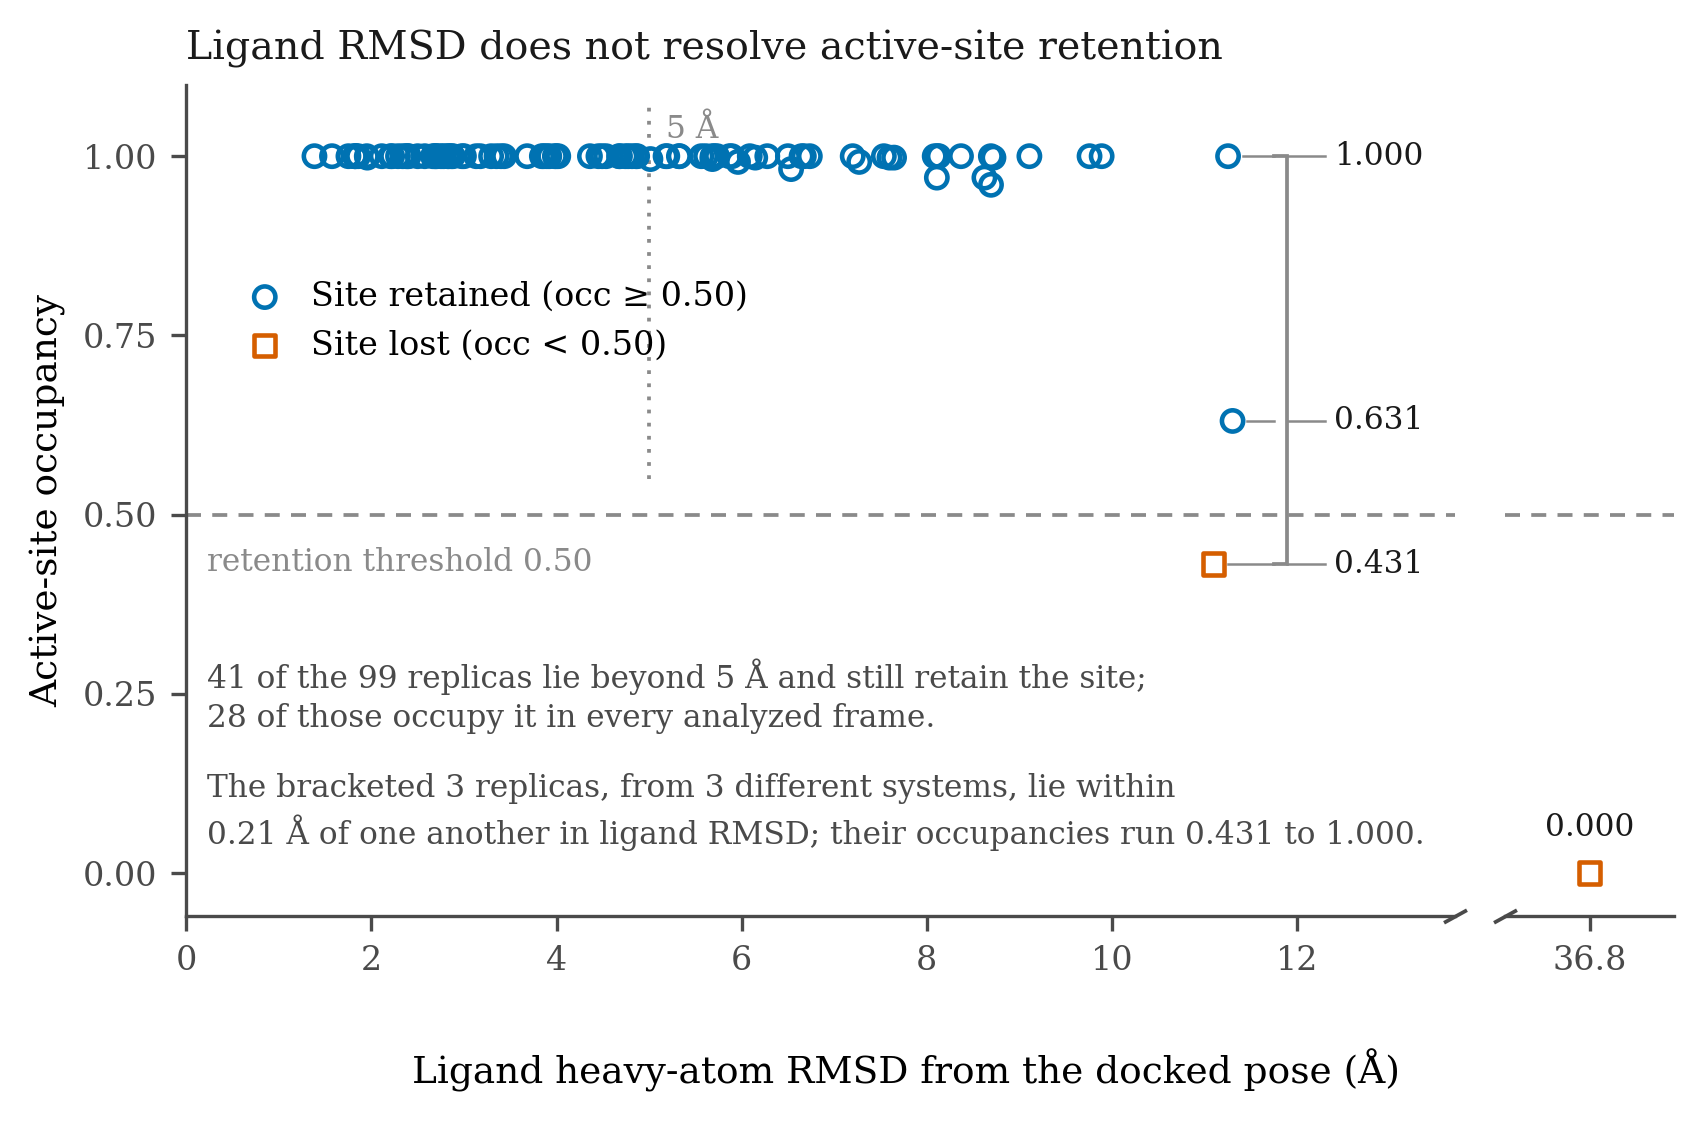

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_4.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_4.pdf`</sub>

In [11]:
# ============================================================
# Figure 2 · 位点占有率 对 配体 RMSD（99 条主臂复本）  （§3.2.2）
# ============================================================
pm = resolve("主臂占有率", ["results/aud_main_site_occupancy.csv"])
A = expect_rows(pd.read_csv(pm), 99, "99 条主臂复本，逐复本")
print("  实有列:", list(A.columns))
aocc = pick(A, "占有率", ["site_occupancy"])
armsd = pick(A, "配体 RMSD", ["rmsd_lig_mean_from_phase4", "rmsd_lig_mean"])
asys = pick(A, "体系", ["system"]); arep = pick(A, "复本", ["rep"])

occ  = pd.to_numeric(A[aocc], errors="raise").to_numpy(float)
rms  = pd.to_numeric(A[armsd], errors="raise").to_numpy(float)
lost = occ < 0.50
n_beyond = int(((rms > 5) & ~lost).sum())
n_full   = int(((rms > 5) & (occ >= 0.99995)).sum())
print("  rmsd_lig > 5 Å 且占有率 ≥ 0.50 者: %d  （§3.2.2 载 41）" % n_beyond)
print("  其中占有率 = 1.000 者:              %d  （§3.2.2 载 28）" % n_full)
print("  失位复本: %d  （§3.2.1 载 2）" % int(lost.sum()))
if n_beyond != 41: warn("Figure 2：rmsd_lig > 5 Å 而保持者实算 %d，§3.2.2 载 41。" % n_beyond)
if n_full   != 28: warn("Figure 2：其中占有率为 1.000 者实算 %d，§3.2.2 载 28。" % n_full)

# ---- 三复本之例：**由数据选出**，不写死 --------------------------------
# 取占有率跨度最大的那个体系；§3.2.2 的论据正是「同一体系三复本几乎同 RMSD 而结局迥异」。
# §3.2.2 的论据，是「配体 RMSD 几乎相同而结局迥异」。该论的锚点是**失位复本中最小的
# 那个 RMSD**：在它左右的窄带里，结局自失位到全占有皆有，故 RMSD 不能判去留。
# **不预设这些复本同属一个体系**——是不是一个体系，由数据说，并据实写进注记。
W1 = A.assign(_o=occ, _r=rms)
r0 = float(rms[lost].min())
BANDW = 0.5
TRI = W1[np.abs(W1["_r"] - r0) <= BANDW].sort_values("_o", ascending=False)
while len(TRI) > 6 and BANDW > 0.15:        # 带内过挤则收窄，免得直标叠成一片
    BANDW -= 0.1
    TRI = W1[np.abs(W1["_r"] - r0) <= BANDW].sort_values("_o", ascending=False)
tri_dr = float(TRI["_r"].max() - TRI["_r"].min())
nsys = int(TRI[asys].nunique())
print("  失位复本的最小配体 RMSD = %.2f Å（§3.2.2 载 11.10）" % r0)
print("  其 ±%.1f Å 带内共 %d 条复本，来自 %d 个体系，RMSD 相差 %.2f Å，占有率 %.3f–%.3f："
      % (BANDW, len(TRI), nsys, tri_dr, TRI["_o"].min(), TRI["_o"].max()))
for _, r in TRI.iterrows():
    print("     %-34s %-3s  occ %.3f   rmsd %.2f Å" % (r[asys], r[arep], r["_o"], r["_r"]))
# §3.2.2 载其为**三个不同候选**的三条复本（011 的 secondary 位姿 · 034/r2 · 243/r2）。
# 故此处核的是「确为多个体系」，而非报警。
if nsys == 1:
    warn("Figure 2：该窄带内的复本同属一个体系，而 §3.2.2 称其为三个不同候选 —— 须查清。")
else:
    print("  与 §3.2.2 相合：确为 %d 个不同候选的复本。" % nsys)

# ---- 断轴：**只在确有大空档时才断**，否则单幅 --------------------------
srt  = np.sort(rms); gaps = np.diff(srt); gi = int(np.argmax(gaps))
n_right = len(srt) - gi - 1
BREAK = (gaps[gi] >= 5.0) and (n_right <= 3)
print("  x 轴最大空档 %.1f Å（其右 %d 点）→ %s"
      % (gaps[gi], n_right, "断轴两幅" if BREAK else "单幅"))

# 直标一律置于**左幅所有点之右**的空白列：如此不论那三条复本落在何处，
# 标签都压不到任何点（第六版把标签贴在点旁，遇到近邻之点便相叠）。
XLAST = float(srt[gi]) if BREAK else float(srt[-1])
TBX   = XLAST + 0.45                        # 括号所在
TLX   = XLAST + 1.10                        # 标签列左缘
XC    = XLAST + 2.40                        # 右界：容得下括号、引线与标签
if BREAK:
    fig, (axL, axR) = plt.subplots(
        1, 2, figsize=(6.4, 3.6), sharey=True,
        gridspec_kw={"width_ratios": [7.5, 1.0], "wspace": 0.07})
    axL.set_xlim(0, XC)
    axR.set_xlim(srt[gi + 1] - 1.5, srt[-1] + 1.5)
    PANES = (axL, axR)
else:
    fig, axL = plt.subplots(figsize=(5.4, 3.6))
    axR = None; XC = XLAST + 2.40
    axL.set_xlim(0, XC)
    PANES = (axL,)

for ax in PANES:
    ax.axhline(0.50, color=MUTED, lw=0.9, ls=(0, (4, 3)), zorder=1)
    for m, c, lab, sel in ((M_KEEP, C_KEEP, "Site retained (occ ≥ 0.50)", ~lost),
                           (M_LOST, C_LOST, "Site lost (occ < 0.50)",     lost)):
        ax.scatter(rms[sel], occ[sel], s=26, marker=m, facecolor="none",
                   edgecolor=c, linewidth=1.1, zorder=3,
                   label=lab if ax is axL else None)
# 5 Å 之线只画在有点的那一带，免得横穿下方的注记
axL.plot([5.0, 5.0], [0.55, 1.08], color=MUTED, lw=0.9, ls=(0, (1, 2.5)), zorder=1)
axL.set_ylim(-0.06, 1.10)
axL.set_yticks([0.0, 0.25, 0.50, 0.75, 1.00])   # 0.50 上轴，使阈值自轴可读
axL.set_ylabel("Active-site occupancy")

# ---- 断口的记号与右幅的收拾 --------------------------------------------
if BREAK:
    axL.spines["right"].set_visible(False)
    axR.spines["left"].set_visible(False)
    axR.tick_params(axis="y", length=0)
    brk = dict(marker=[(-1, -0.55), (1, 0.55)], markersize=5.5, linestyle="none",
               color=INK2, mec=INK2, mew=0.9, clip_on=False)
    axL.plot([1], [0], transform=axL.transAxes, **brk)   # 断口之记只落在横轴上
    axR.plot([0], [0], transform=axR.transAxes, **brk)
    axR.set_xticks([float(srt[-1])]); axR.set_xticklabels(["%.1f" % srt[-1]])
    jlost = int(np.argmax(rms))
    axR.annotate("%.3f" % occ[jlost], (rms[jlost], occ[jlost]),
                 textcoords="offset points", xytext=(0, 9), zorder=6,
                 fontsize=7.5, color=INK, ha="center",
                 bbox=dict(facecolor="white", edgecolor="none", pad=0.8))
    fig.text(0.5, -0.045, "Ligand heavy-atom RMSD from the docked pose (Å)",
             ha="center", fontsize=9)
else:
    axL.set_xlabel("Ligand heavy-atom RMSD from the docked pose (Å)")

# ---- 三复本的括号与直标：置于点右侧的空白带，不压任何点 -----------------
ylo, yhi = float(TRI["_o"].min()), float(TRI["_o"].max())
axL.plot([TBX, TBX + 0.14, TBX + 0.14, TBX], [ylo, ylo, yhi, yhi],
         color=MUTED, lw=0.9, solid_joinstyle="miter", zorder=2)

# 纵向错开：两条占有率相近时（如 1.000 与 0.982）标签会相叠，故按字高留最小间距，
# 再以引线把每个标签接回它自己的那个点——引线在，错开就不致认错。
ylim0, ylim1 = axL.get_ylim()
fig.canvas.draw()
ax_h_in = axL.get_window_extent().height / fig.dpi
GAPY = (10.5 / 72.0) / max(ax_h_in, 1e-6) * (ylim1 - ylim0)   # 7.5 pt 字 + 行距
ys  = [float(v) for v in TRI["_o"]]                            # 已按降序
lys = list(ys)
for i in range(1, len(lys)):
    if lys[i - 1] - lys[i] < GAPY:
        lys[i] = lys[i - 1] - GAPY
if lys and lys[-1] < ylim0 + 0.04:                             # 压到下界则整体上移
    sh = (ylim0 + 0.04) - lys[-1]
    lys = [min(y + sh, ylim1 - 0.04) for y in lys]

for (_, r), y, ly in zip(TRI.iterrows(), ys, lys):
    axL.plot([float(r["_r"]) + 0.16, TBX], [y, y], color=MUTED, lw=0.6, zorder=2)
    axL.plot([TBX + 0.14, TLX - 0.10], [y, ly], color=MUTED, lw=0.6, zorder=2)
    axL.text(TLX, ly, "%.3f" % r["_o"], fontsize=7.5, color=INK,
             va="center", ha="left", zorder=6)

# ---- 两处注记：皆落在「按构造为空」之区 ---------------------------------
# §3.2.2 立定「失位复本的 rmsd_lig 下界为 11.10 Å」，故 x < 11 且 y < 0.50 一区必空。
axL.text(5.18, 1.015, "5 Å", color=MUTED, fontsize=7.5, va="bottom")
axL.text(0.22, 0.455, "retention threshold 0.50", color=MUTED, fontsize=7.5, va="top")
axL.text(0.22, 0.30,
         "%d of the 99 replicas lie beyond 5 Å and still retain the site;\n"
         "%d of those occupy it in every analyzed frame." % (n_beyond, n_full),
         fontsize=7.5, color=INK2, linespacing=1.35, va="top", ha="left")
axL.text(0.22, 0.14,
         "The bracketed %d replicas, from %d different system%s, lie within\n"
         "%.2f Å of one another in ligand RMSD; their occupancies run %.3f to %.3f."
         % (len(TRI), nsys, "" if nsys == 1 else "s", tri_dr,
            TRI["_o"].min(), TRI["_o"].max()),
         fontsize=7.5, color=INK2, linespacing=1.35, va="top", ha="left")
axL.legend(loc="upper left", bbox_to_anchor=(0.012, 0.80), handletextpad=0.4)
axL.set_title("Ligand RMSD does not resolve active-site retention",
              loc="left", color=INK)

save_fig(fig, 4, "occupancy vs ligand RMSD, 99 main-arm replicas",
         caption="Site occupancy against mean ligand RMSD for all 99 main-arm replicas. "
                 "Occupancy is the fraction of analyzed frames in which the minimum "
                 "ligand\u2013dyad heavy-atom distance is at most 5.0 \u00c5 (\u00a7S-16.2.1); the "
                 "per-replica retention threshold of 0.50 is drawn as a horizontal rule. Ligand "
                 "RMSD does not resolve retention in this cohort \u2014 the two populations "
                 "overlap across the RMSD range, and the lowest RMSD among non-retained replicas "
                 "exceeds that of many retained ones \u2014 so retention is read from the dyad "
                 "distance and not from ligand displacement. The bracketed replicas lie "
                 "within a narrow band of ligand RMSD centered on the smallest value reached "
                 "by any non-retained replica, and their occupancies nevertheless run from "
                 "loss of the site to occupancy in every analyzed frame (\u00a73.2.2).")

  → Figure_S3  (.png 300 dpi + .pdf)  per-replica occupancy distribution, 99 main-arm replicas
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S3.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S3.pdf   （矢量，ACS 投稿以此为佳）


**Figure S3.** Distribution of per-replica site occupancy across the 99 main-arm replicas, with replicas below and above the 0.50 retention threshold distinguished. The distribution is strongly bimodal: most replicas hold the site in nearly every analyzed frame, a small group holds it in almost none, and few lie between. The threshold therefore separates two populations rather than cutting through one, which is why a single fixed cut-off was retained in place of a graded score (§3.2.1).

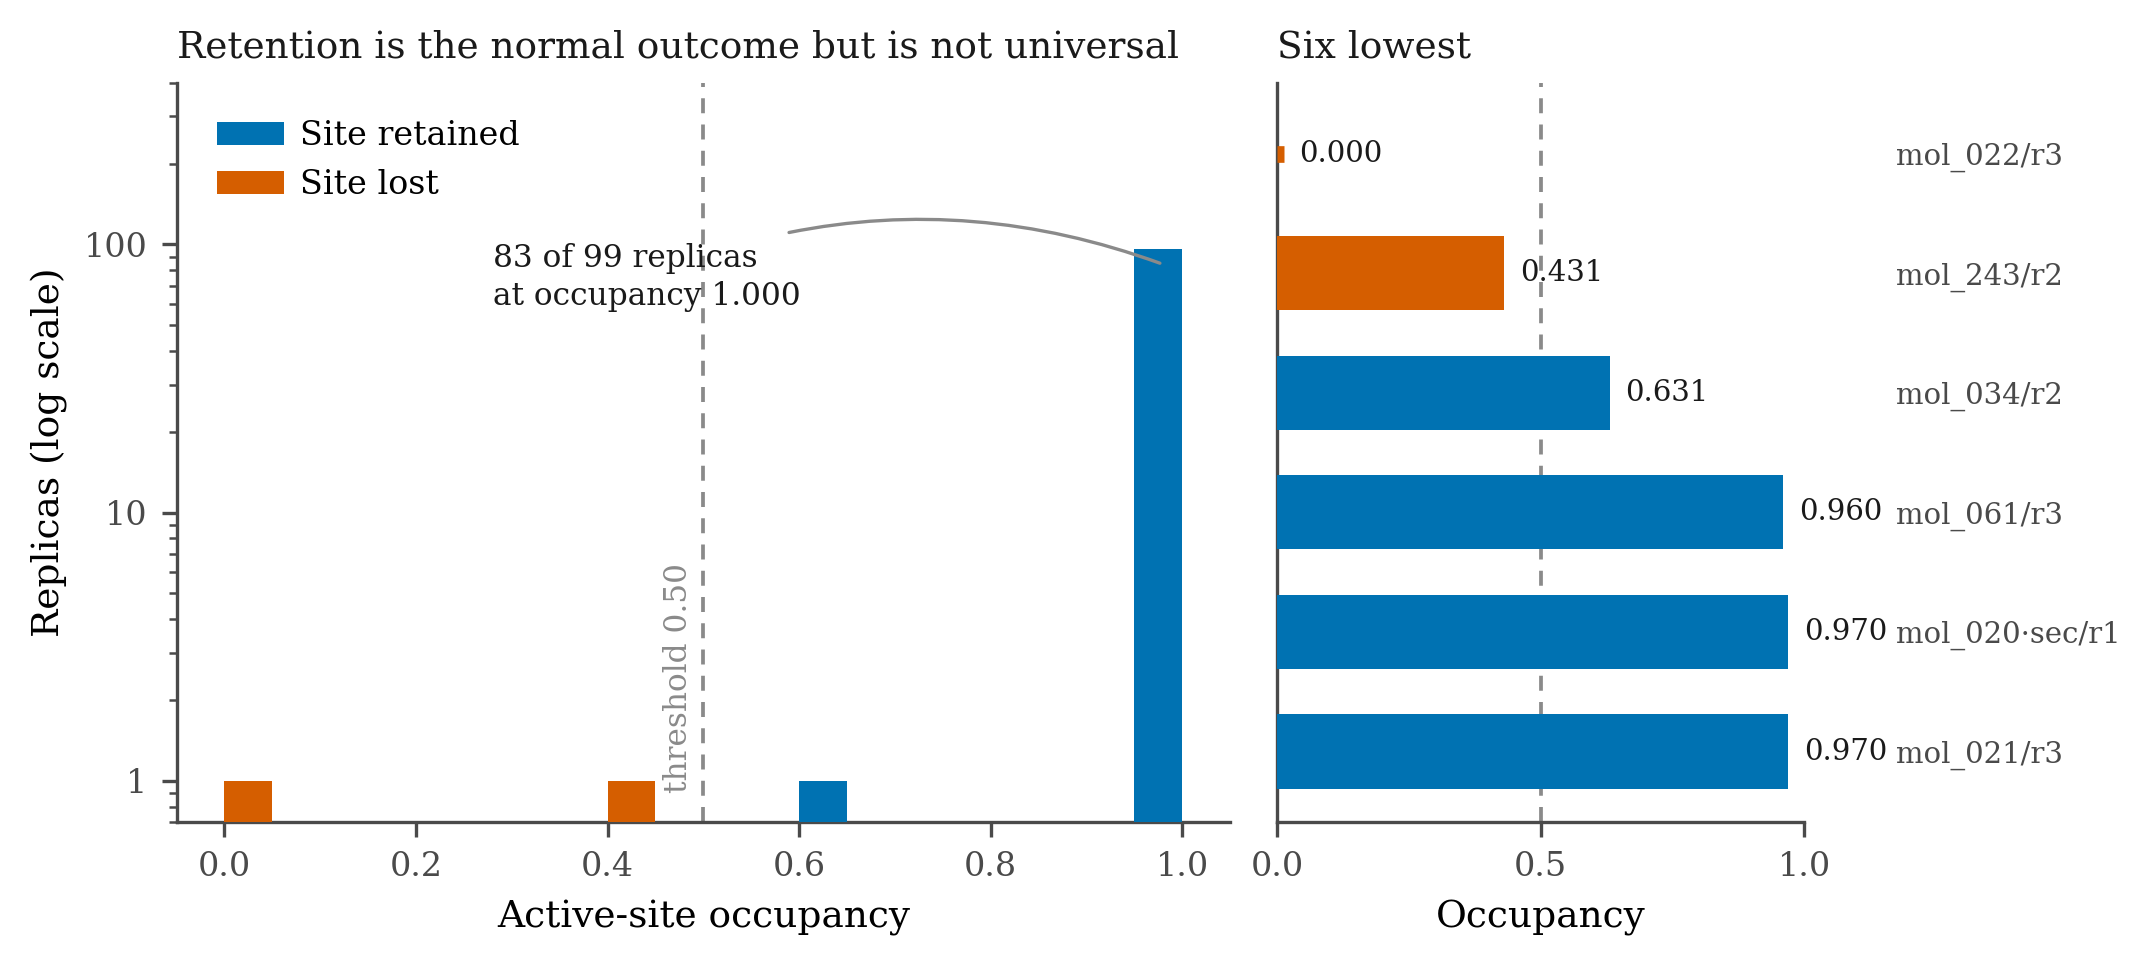

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S3.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S3.pdf`</sub>

In [12]:
# ============================================================
# Figure S3 · 99 条主臂复本的占有率分布              （§3.2.1）
# ============================================================
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.0, 3.2),
                             gridspec_kw={"width_ratios": [2.0, 1.0], "wspace": 0.06})

edges = np.linspace(0, 1, 21)
a1.hist(occ[~lost], bins=edges, color=C_KEEP, label="Site retained", zorder=3)
a1.hist(occ[lost],  bins=edges, color=C_LOST, label="Site lost", zorder=4)
a1.axvline(0.50, color=MUTED, lw=0.9, ls=(0, (4, 3)), zorder=2)
a1.set_yscale("log"); a1.set_ylim(0.7, 400)
a1.set_yticks([1, 10, 100]); a1.set_yticklabels(["1", "10", "100"])
a1.set_xlabel("Active-site occupancy"); a1.set_ylabel("Replicas (log scale)")
a1.text(0.49, 0.9, "threshold 0.50", color=MUTED, fontsize=7.5, rotation=90,
        ha="right", va="bottom")
n_full = int((occ >= 0.99995).sum())
a1.annotate("%d of 99 replicas\nat occupancy 1.000" % n_full,
            xy=(0.985, n_full), xycoords="data", xytext=(0.30, 0.70),
            textcoords="axes fraction", fontsize=7.5, color=INK, linespacing=1.3,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8,
                            connectionstyle="arc3,rad=-0.2"))
a1.legend(loc="upper left", bbox_to_anchor=(0.01, 0.99), handletextpad=0.5)
a1.set_title("Retention is the normal outcome but is not universal", loc="left",
             color=INK, fontsize=9)

# 2026-11-22：原以 argmin 按**值**回找下标，0.9701 处有两条（021/r3 与
# 020·sec/r1），argmin 两次皆返回同一个最先命中的下标，故一行被标两遍、
# 另一行的标号从未出现。改为按**下标**排序，身份随之带出。
_ord = np.argsort(occ, kind="stable")[:6]
low = np.asarray(occ)[_ord]
labs = []
for j in _ord:
    j = int(j)
    nm = (str(A[asys].iloc[j]).replace("pool_", "").replace("__6W63", "")
          .replace("__primary", "").replace("__secondary", "·sec"))
    labs.append("%s/%s" % (nm, A[arep].iloc[j]))
yy = np.arange(len(low))[::-1]
a2.barh(yy, low, height=0.62, color=[C_LOST if v < 0.5 else C_KEEP for v in low], zorder=3)
# 占有率为 0 者无长度可见，补一短刻度，否则该行看起来是缺失而非为零
for y, v in zip(yy, low):
    if v <= 0.0:
        a2.plot([0, 0.012], [y, y], color=C_LOST, lw=4, solid_capstyle="butt", zorder=4)
a2.axvline(0.50, color=MUTED, lw=0.9, ls=(0, (4, 3)), zorder=2)
a2.set_yticks(yy); a2.set_yticklabels(labs, fontsize=7)
a2.yaxis.tick_right(); a2.yaxis.set_label_position("right")
a2.tick_params(axis="y", length=0, pad=22)
a2.set_xlim(0, 1.0); a2.set_xticks([0, 0.5, 1.0])
a2.set_xlabel("Occupancy")
for y, v in zip(yy, low):
    a2.text(max(v, 0.012) + 0.03, y, "%.3f" % v, va="center", fontsize=7, color=INK)
a2.set_title("Six lowest", loc="left", color=INK, fontsize=9)
save_fig(fig, "S3", "per-replica occupancy distribution, 99 main-arm replicas",
         caption="Distribution of per-replica site occupancy across the 99 main-arm replicas, "
                 "with replicas below and above the 0.50 retention threshold distinguished. The "
                 "distribution is strongly bimodal: most replicas hold the site in nearly every "
                 "analyzed frame, a small group holds it in almost none, and few lie between. The "
                 "threshold therefore separates two populations rather than cutting through one, "
                 "which is why a single fixed cut-off was retained in place of a graded score "
                 "(\u00a73.2.1).")

  → Figure_9  (.png 300 dpi + .pdf)  per-axis decomposition of F, leads and demotions
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_9.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_9.pdf   （矢量，ACS 投稿以此为佳）


**Figure 9.** Per-axis decomposition of F(Γ), for the five leading candidates (above the divider) and for the candidates the dynamic stage demotes furthest, the last-placed one among them (below). Each bar is partitioned into the six contributions w_j z_j of Table 4; negative contributions are drawn to the left of zero and the net score is marked outside the bar. The legend states the applied weight carried by each axis, so the figure sets out the scoring function itself and not only its outcome. Candidates reaching comparable scores do so by dissimilar routes, so F(Γ) is not to be read as a single physical quantity: one leading candidate derives the majority of its positive contribution from ΔG_PBSA, the axis that failed external validation (§3.4.3, §3.5.2). The demoted bars show what the score penalizes, which the leading bars alone cannot (§3.5.2).

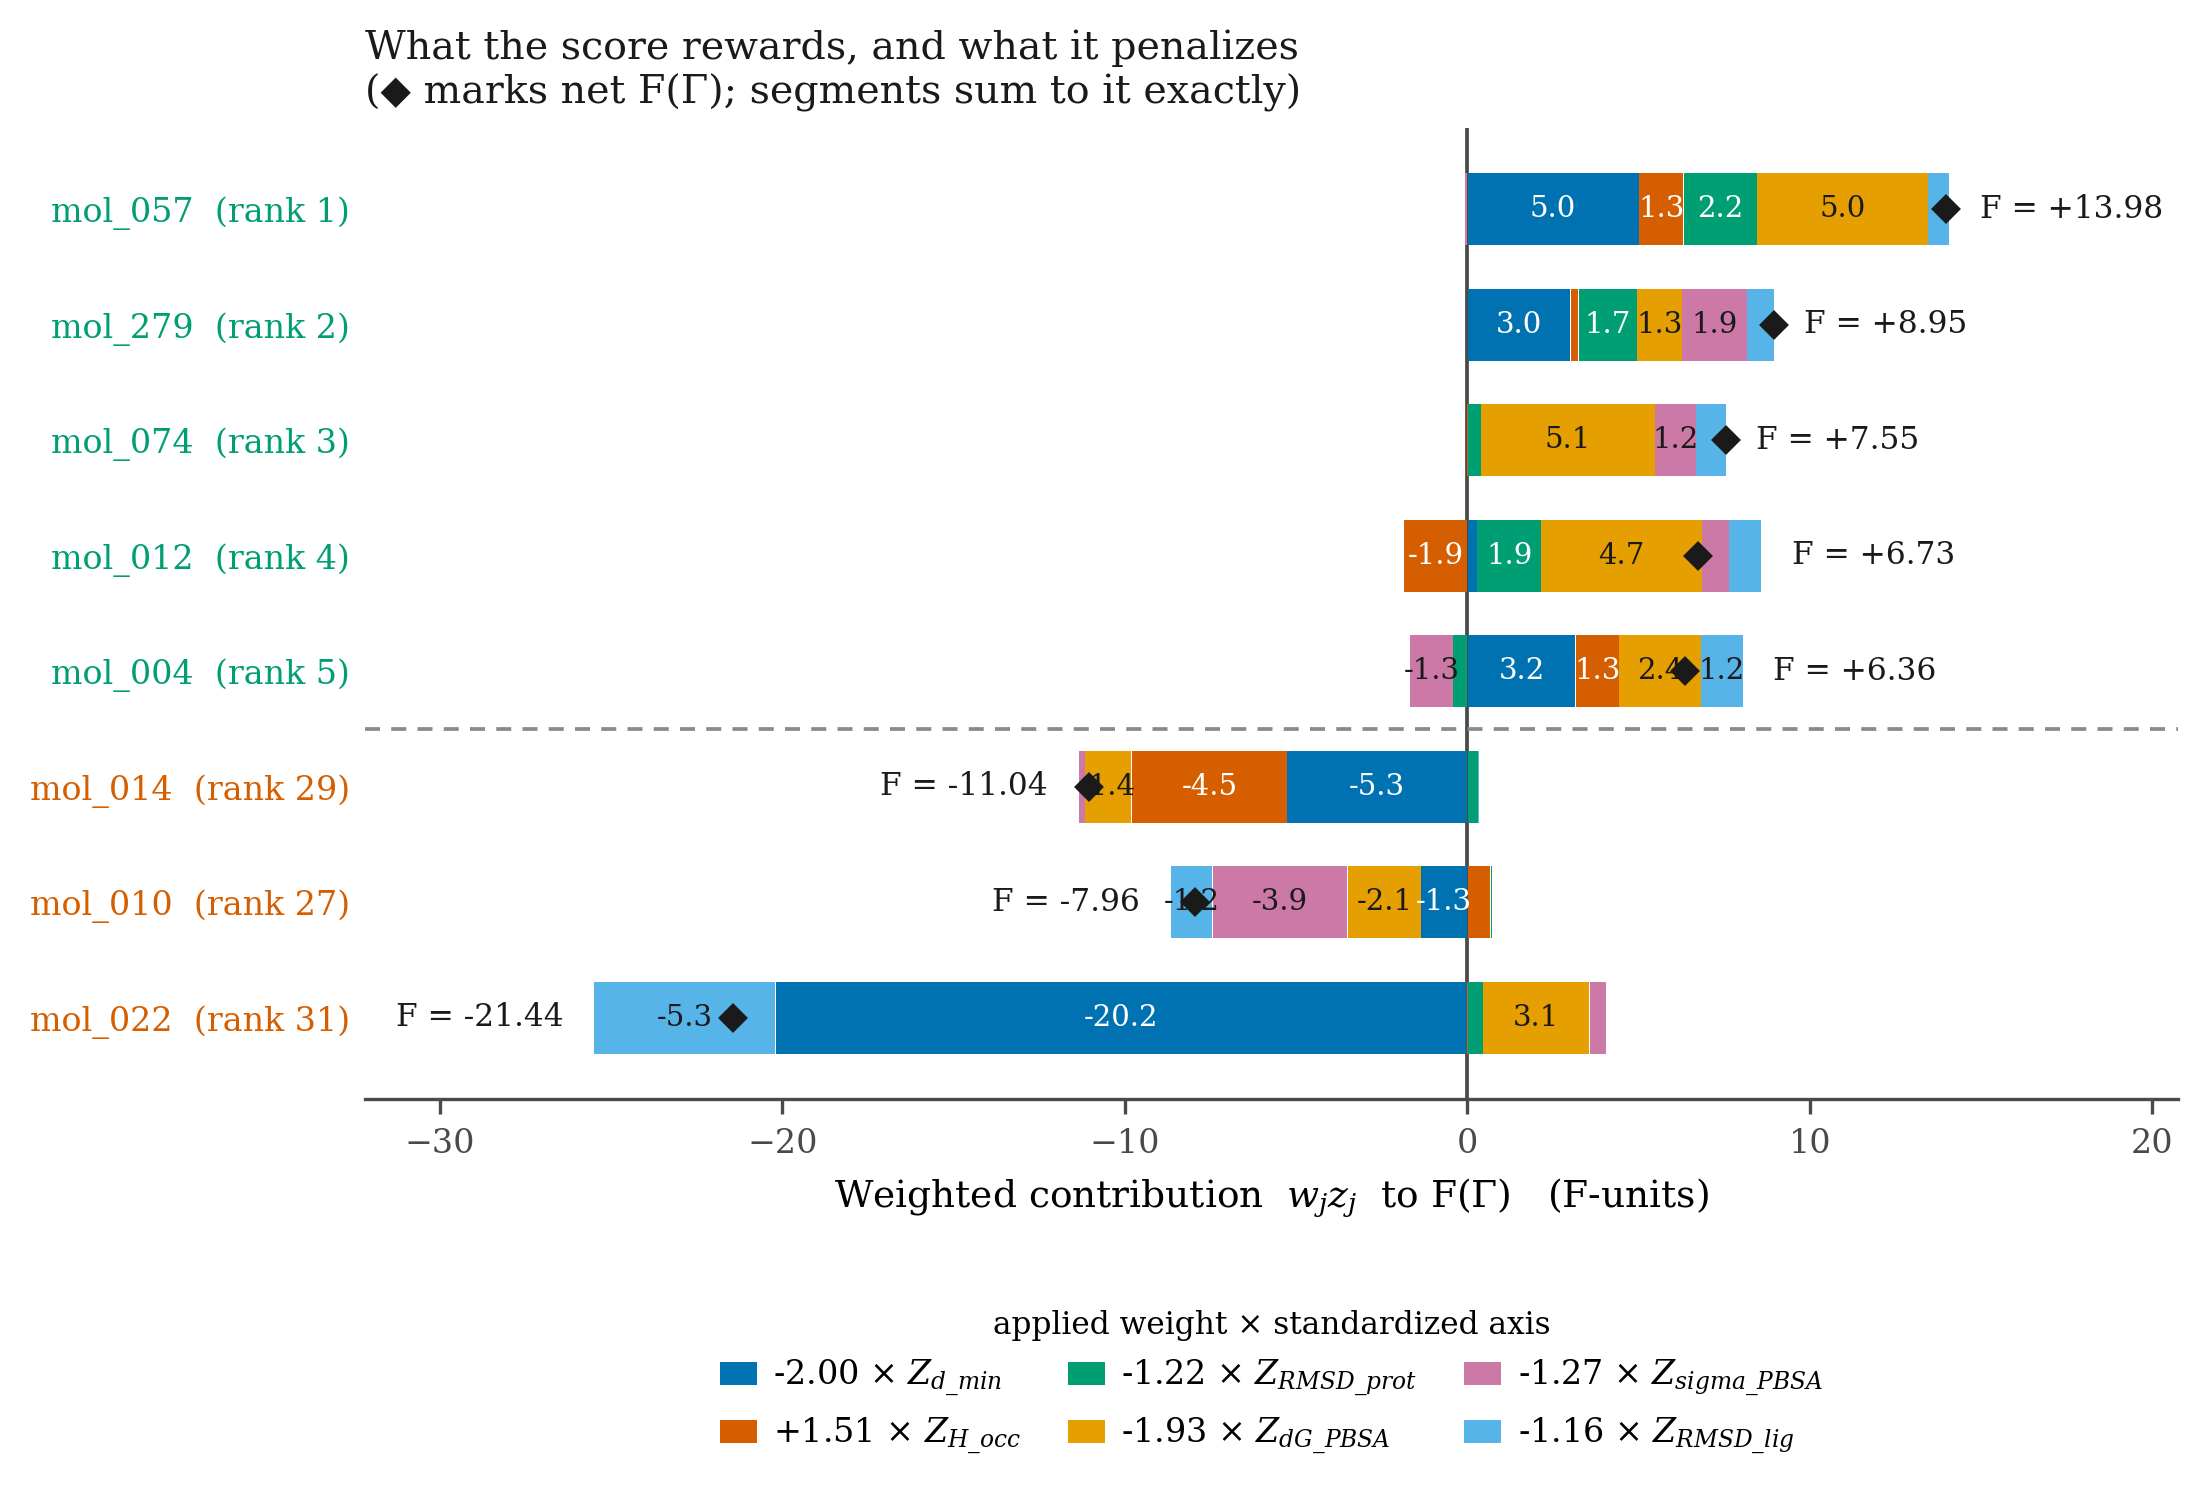

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_9.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_9.pdf`</sub>

In [13]:
# ============================================================
# Figure 5 · 领先候选的 F(Γ) 逐轴堆叠分解           （§3.5.2）
# ============================================================
# 领先五者 **与** 降级者并列：只画领先者，便看不出这个分数惩罚的是什么。
# 旧稿那一幅正是两半俱全，此处补齐（候选由 Table 3 cell 实测选出）。
ORD = LEAD5 + [m for m in DEMOTE if m not in LEAD5]
NLEAD = len(LEAD5)
idx = []
for l in ORD:
    m = [i for i in WZ.index if i == l]
    if len(m) != 1: raise KeyError("%s 在分解表中命中 %d 行" % (l, len(m)))
    idx.append(m[0])
Dp = WZ.loc[idx, AXES6]

# 浅色三色（橙/天蓝/紫）白底对比 < 3:1，故其上的直标改用深墨；深色三色用白字。
TEXTON = {"#0072B2": "white", "#D55E00": "white", "#009E73": "white",
          "#E69F00": INK, "#CC79A7": INK, "#56B4E9": INK}
# **横置**：候选八个、名字长，而数值跨度大（领先者至多十余，末位可达 −二十余），
# 故长轴给数值、短轴给候选。竖置时末位那一柱会把领先五者压成一线。
fig, axx = plt.subplots(figsize=(7.8, 4.2))
ys = np.arange(len(idx))[::-1]              # 自上而下：领先在上，降级在下
# 直标的门槛按**全幅跨度**定，不按绝对值：段窄而标在其上，几个数就连成一片。
span0 = float(max(Dp.clip(lower=0).sum(axis=1).max(),
                  abs(Dp.clip(upper=0).sum(axis=1).min())))
MINSEG = 0.045 * span0
GAP = 0.012
rp = np.zeros(len(idx)); rn = np.zeros(len(idx))
for a in AXES6:
    v = Dp[a].to_numpy(float)
    for k in range(len(idx)):
        if v[k] >= 0:
            axx.barh(ys[k], v[k] - GAP, left=rp[k] + GAP / 2, height=0.62,
                     color=AXCOL[a], zorder=3,
                     label=("%+.2f × $Z_{%s}$" % (W_APPLIED[a], a.replace("_", r"\_")))
                           if k == 0 else None)
            if v[k] > MINSEG:
                axx.text(rp[k] + v[k] / 2, ys[k], "%.1f" % v[k], ha="center", va="center",
                         fontsize=7, color=TEXTON[AXCOL[a]], zorder=4)
            rp[k] += v[k]
        else:
            axx.barh(ys[k], v[k] + GAP, left=rn[k] - GAP / 2, height=0.62,
                     color=AXCOL[a], zorder=3,
                     label=("%+.2f × $Z_{%s}$" % (W_APPLIED[a], a.replace("_", r"\_")))
                           if k == 0 else None)
            if v[k] < -MINSEG:
                axx.text(rn[k] + v[k] / 2, ys[k], "%.1f" % v[k], ha="center", va="center",
                         fontsize=7, color=TEXTON[AXCOL[a]], zorder=4)
            rn[k] += v[k]

span = float(max(rp.max(), abs(rn.min())))
pad  = 0.035 * span
for k in range(len(idx)):
    tot = float(Dp.iloc[k].sum())
    axx.plot([tot], [ys[k]], marker="D", ms=4.2, color=INK, zorder=6)   # 净 F
    if tot >= 0:
        axx.text(rp[k] + pad, ys[k], "F = %+.2f" % tot, ha="left", va="center",
                 fontsize=7.5, color=INK, zorder=6)
    else:
        axx.text(rn[k] - pad, ys[k], "F = %+.2f" % tot, ha="right", va="center",
                 fontsize=7.5, color=INK, zorder=6)
axx.axvline(0, color=INK2, lw=0.9, zorder=2)
# 领先者与降级者之间一道横线，刻度文字分色：绿为领先，红为降级
axx.axhline(ys[NLEAD - 1] - 0.5, color=MUTED, lw=0.9, ls=(0, (4, 3)), zorder=2)
axx.set_yticks(ys)
axx.set_yticklabels(["%s  (rank %d)" % (i.replace("pool_", ""), RANKOF[i]) for i in idx],
                    fontsize=8)
for t, i in zip(axx.get_yticklabels(), idx):
    t.set_color(PAL6[2] if i in LEAD5 else C_LOST)
axx.set_xlim(rn.min() - 7.5 * pad, rp.max() + 7.5 * pad)
axx.set_ylim(-0.7, len(idx) - 0.3)
axx.set_xlabel(r"Weighted contribution  $w_j z_j$  to F($\Gamma$)   (F-units)")
axx.spines["left"].set_visible(False); axx.tick_params(axis="y", length=0)
axx.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.40),
           columnspacing=1.4, handlelength=1.1, handletextpad=0.5,
           title="applied weight × standardized axis", title_fontsize=7.5)
axx.set_title("What the score rewards, and what it penalizes\n"
              "(◆ marks net F(Γ); segments sum to it exactly)", loc="left", color=INK)
save_fig(fig, 9, "per-axis decomposition of F, leads and demotions",
         caption="Per-axis decomposition of F(\u0393), for the five leading candidates (above "
                 "the divider) and for the candidates the dynamic stage demotes furthest, the "
                 "last-placed one among them (below). Each bar is partitioned into the six "
                 "contributions w_j z_j of Table 4; negative contributions are drawn to the left "
                 "of zero and the net score is marked outside the bar. The legend states the "
                 "applied weight carried by each axis, so the figure sets out the scoring "
                 "function itself and not only its outcome. Candidates reaching comparable "
                 "scores do so by dissimilar routes, so F(\u0393) is not to be read as a single "
                 "physical quantity: one leading candidate derives the majority of its positive "
                 "contribution from \u0394G_PBSA, the axis that failed external validation "
                 "(\u00a73.4.3, \u00a73.5.2). The demoted bars show what the score "
                 "penalizes, which the leading bars alone cannot (\u00a73.5.2).")

  保持带 2.39–2.74 Å · 失位带 7.62–21.48 Å · 间隙倍数 2.78
  → Figure_10  (.png 300 dpi + .pdf)  cross-ortholog: maximum per-replica mean dyad distance vs retention
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_10.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_10.pdf   （矢量，ACS 投稿以此为佳）


**Figure 10.** Cross-ortholog arm: for each of the twelve pairings, the largest of its three per-replica mean ligand–dyad distances, ordered by that value and coded by whether any replica lost the site. The quantity is a maximum over per-replica means, not a per-frame maximum. The two outcomes separate without a threshold being imposed: every pairing in which a replica lost the site lies above the gap and every pairing that retained it lies below, so the separation is a property of the measurements and not of the 0.50 cut-off (§3.6.2).

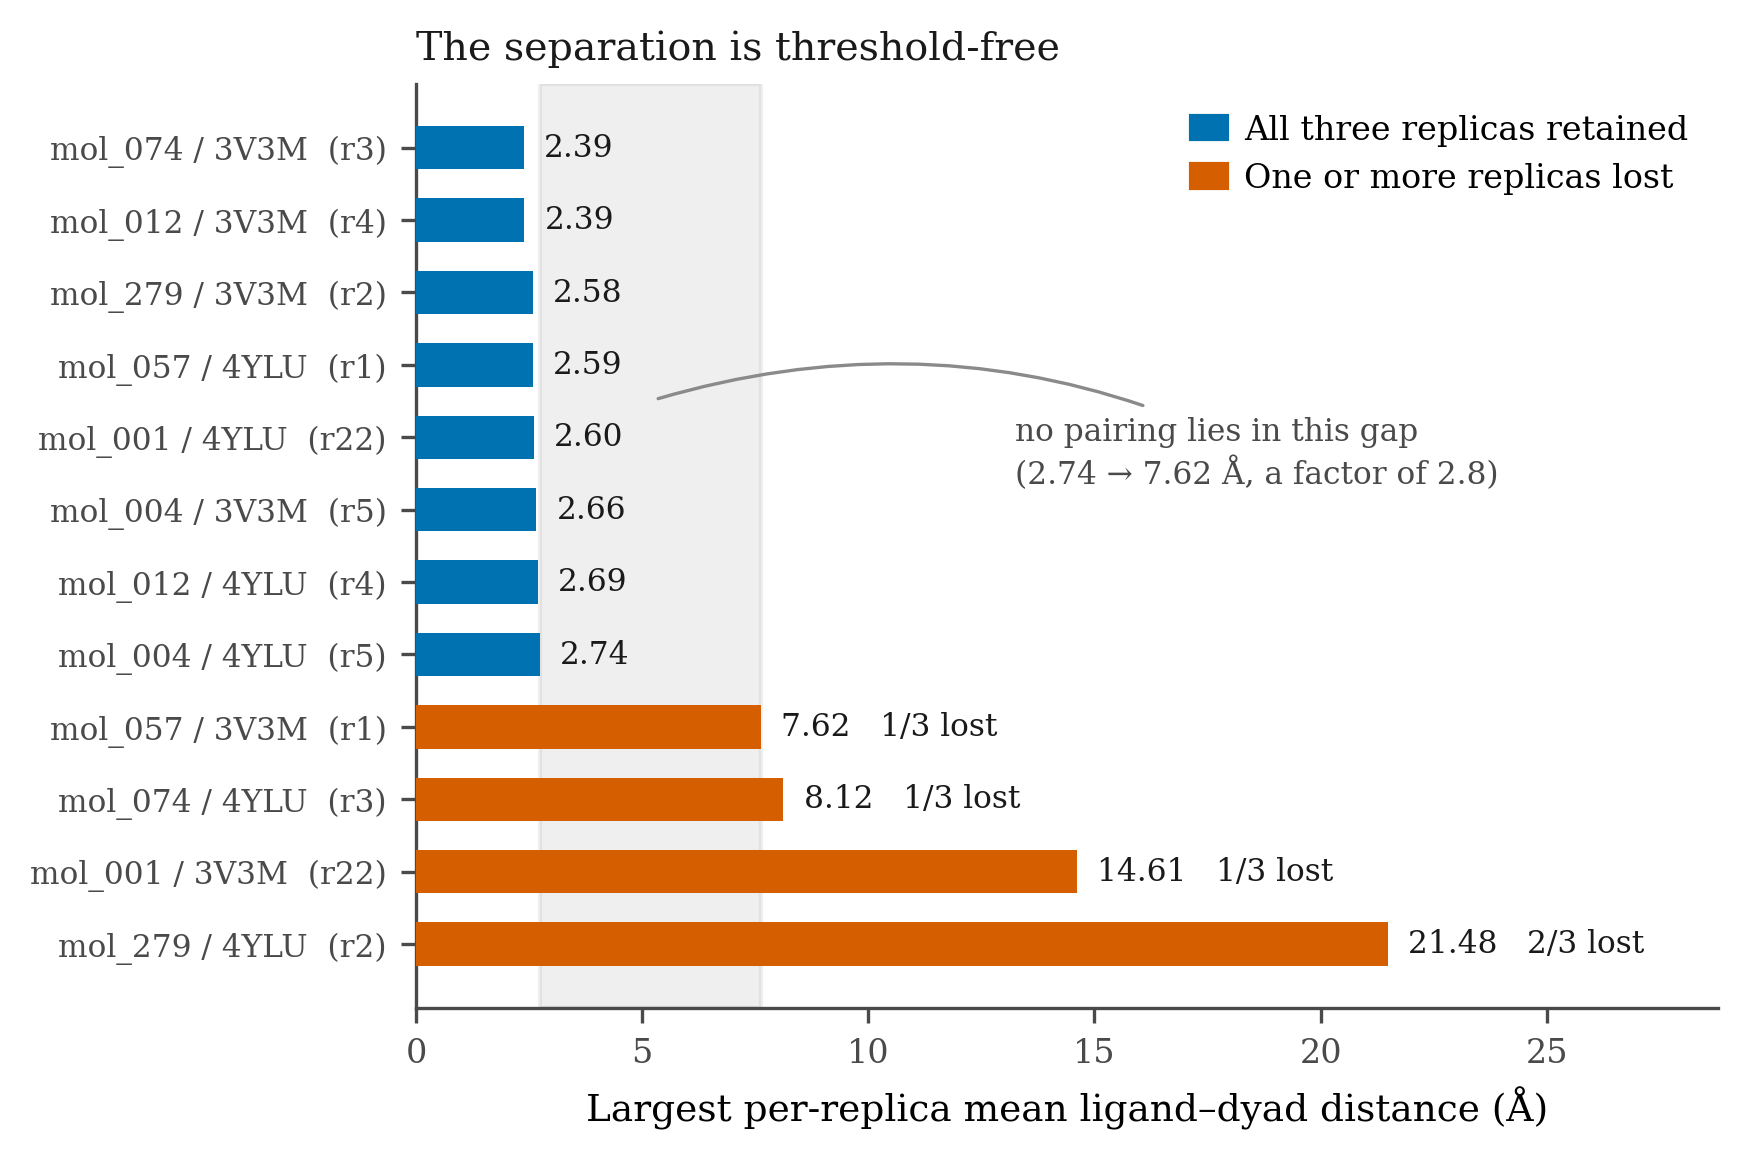

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_10.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_10.pdf`</sub>

In [14]:
# ============================================================
# Figure 6 · 跨臂：逐复本均距之最大值 对 保持与否    （§3.6.2）
# ============================================================
B = T8.sort_values("d_dyad_max_of_replica_means").reset_index(drop=True)
lab = (B[omol].str.replace("pool_", "", regex=False) + " / " + B[otgt].astype(str)
       + "  (r" + B["COMPASS_rank"].astype(int).astype(str) + ")")
islost = B.replicas_lost.to_numpy(int) > 0
vals = B.d_dyad_max_of_replica_means.to_numpy(float)

fig, axx = plt.subplots(figsize=(5.6, 4.0))
yy = np.arange(len(B))[::-1]
axx.barh(yy, vals, height=0.6,
         color=[C_LOST if L else C_KEEP for L in islost], zorder=3)
for y, v, L, n in zip(yy, vals, islost, B.replicas_lost.to_numpy(int)):
    axx.text(v + 0.45, y, "%.2f" % v + ("   %d/3 lost" % n if L else ""),
             va="center", fontsize=7.5, color=INK)
axx.set_yticks(yy); axx.set_yticklabels(lab, fontsize=7.5)
hi_keep, lo_lost = vals[~islost].max(), vals[islost].min()
axx.axvspan(hi_keep, lo_lost, color=MUTED, alpha=0.13, zorder=1)
axx.set_xlim(0, vals.max() * 1.34)
# 注记置于短柱右侧的空白带，以引线指向间隙，不压任何柱或标签
axx.annotate("no pairing lies in this gap\n(%.2f → %.2f Å, a factor of %.1f)"
             % (hi_keep, lo_lost, lo_lost / hi_keep),
             xy=((hi_keep + lo_lost) / 2, len(B) - 4.5), xycoords="data",
             xytext=(0.46, 0.60), textcoords="axes fraction",
             ha="left", va="center", fontsize=7.5, color=INK2, linespacing=1.3,
             arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8,
                             connectionstyle="arc3,rad=0.2"))
axx.set_xlabel("Largest per-replica mean ligand–dyad distance (Å)")
import matplotlib.patches as mpatches
# 图例置于右上：最短的几根柱在顶部，该区为空
axx.legend(handles=[mpatches.Patch(color=C_KEEP, label="All three replicas retained"),
                    mpatches.Patch(color=C_LOST, label="One or more replicas lost")],
           loc="upper right", bbox_to_anchor=(1.0, 1.0),
           handlelength=1.1, handletextpad=0.5)
axx.set_title("The separation is threshold-free", loc="left", color=INK)
print("  保持带 %.2f–%.2f Å · 失位带 %.2f–%.2f Å · 间隙倍数 %.2f"
      % (vals[~islost].min(), hi_keep, lo_lost, vals[islost].max(), lo_lost / hi_keep))
save_fig(fig, 10, "cross-ortholog: maximum per-replica mean dyad distance vs retention",
         caption="Cross-ortholog arm: for each of the twelve pairings, the largest of its three "
                 "per-replica mean ligand\u2013dyad distances, ordered by that value and coded by "
                 "whether any replica lost the site. The quantity is a maximum over per-replica "
                 "means, not a per-frame maximum. The two outcomes separate without a threshold "
                 "being imposed: every pairing in which a replica lost the site lies above the "
                 "gap and every pairing that retained it lies below, so the separation is a "
                 "property of the measurements and not of the 0.50 cut-off (\u00a73.6.2).")

  BBS 名次 对 F(Γ) 名次：Spearman ρ = +0.078  (p = 0.676)
  —— 此数若高，则「动力学把静态看好者降下」一论被削弱；低则此图为该论之直接图证。
  Tier 1: pool_mol_057, pool_mol_279, pool_mol_074
  降幅最大者（F(Γ) 名次 − BBS 名次）: pool_mol_014 +21, pool_mol_010 +21, pool_mol_022 +4
  → Table_S13  (.csv + .md)   7 行 × 3 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S13.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S13.md


**Table S13.** Rank concordance of the static score and of each dynamic axis with the composite ranking, over the 31 primary candidates.

| series     | rho_vs_COMPASS |        p |
|:-----------|---------------:|---------:|
| BBS        |       0.078226 | 0.675738 |
| d_min      |       0.754310 | 0.000001 |
| H_occ      |       0.426021 | 0.016865 |
| RMSD_prot  |       0.456048 | 0.009923 |
| dG_PBSA    |       0.620161 | 0.000198 |
| sigma_PBSA |       0.408468 | 0.022529 |
| RMSD_lig   |       0.727823 | 0.000003 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S13.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S13.md`</sub>

  → Figure_5  (.png 300 dpi + .pdf)  rank concordance, BBS through the six axes to F(Γ)
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_5.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_5.pdf   （矢量，ACS 投稿以此为佳）


**Figure 5.** Rank of every one of the 31 primary candidates under the static broad-spectrum score, under each of the six dynamic axes taken separately, and under the composite. (A) Each line is one candidate; a candidate's position on an axis is its rank when that axis alone is ordered by the sign of its applied weight, so rank 1 is always the most favorable. The five leading candidates and the largest static-to-dynamic demotions are highlighted; the remaining candidates are drawn in gray. (B) Spearman rank correlation of each series with the composite ranking. The static score enters this panel on the same footing as the six dynamic axes, so the degree to which the dynamic stage reorders the static selection can be read from the figure rather than asserted (§3.3.2). Significance markers in (B): *** p < 0.001, ** p < 0.01, * p < 0.05, ns not significant.

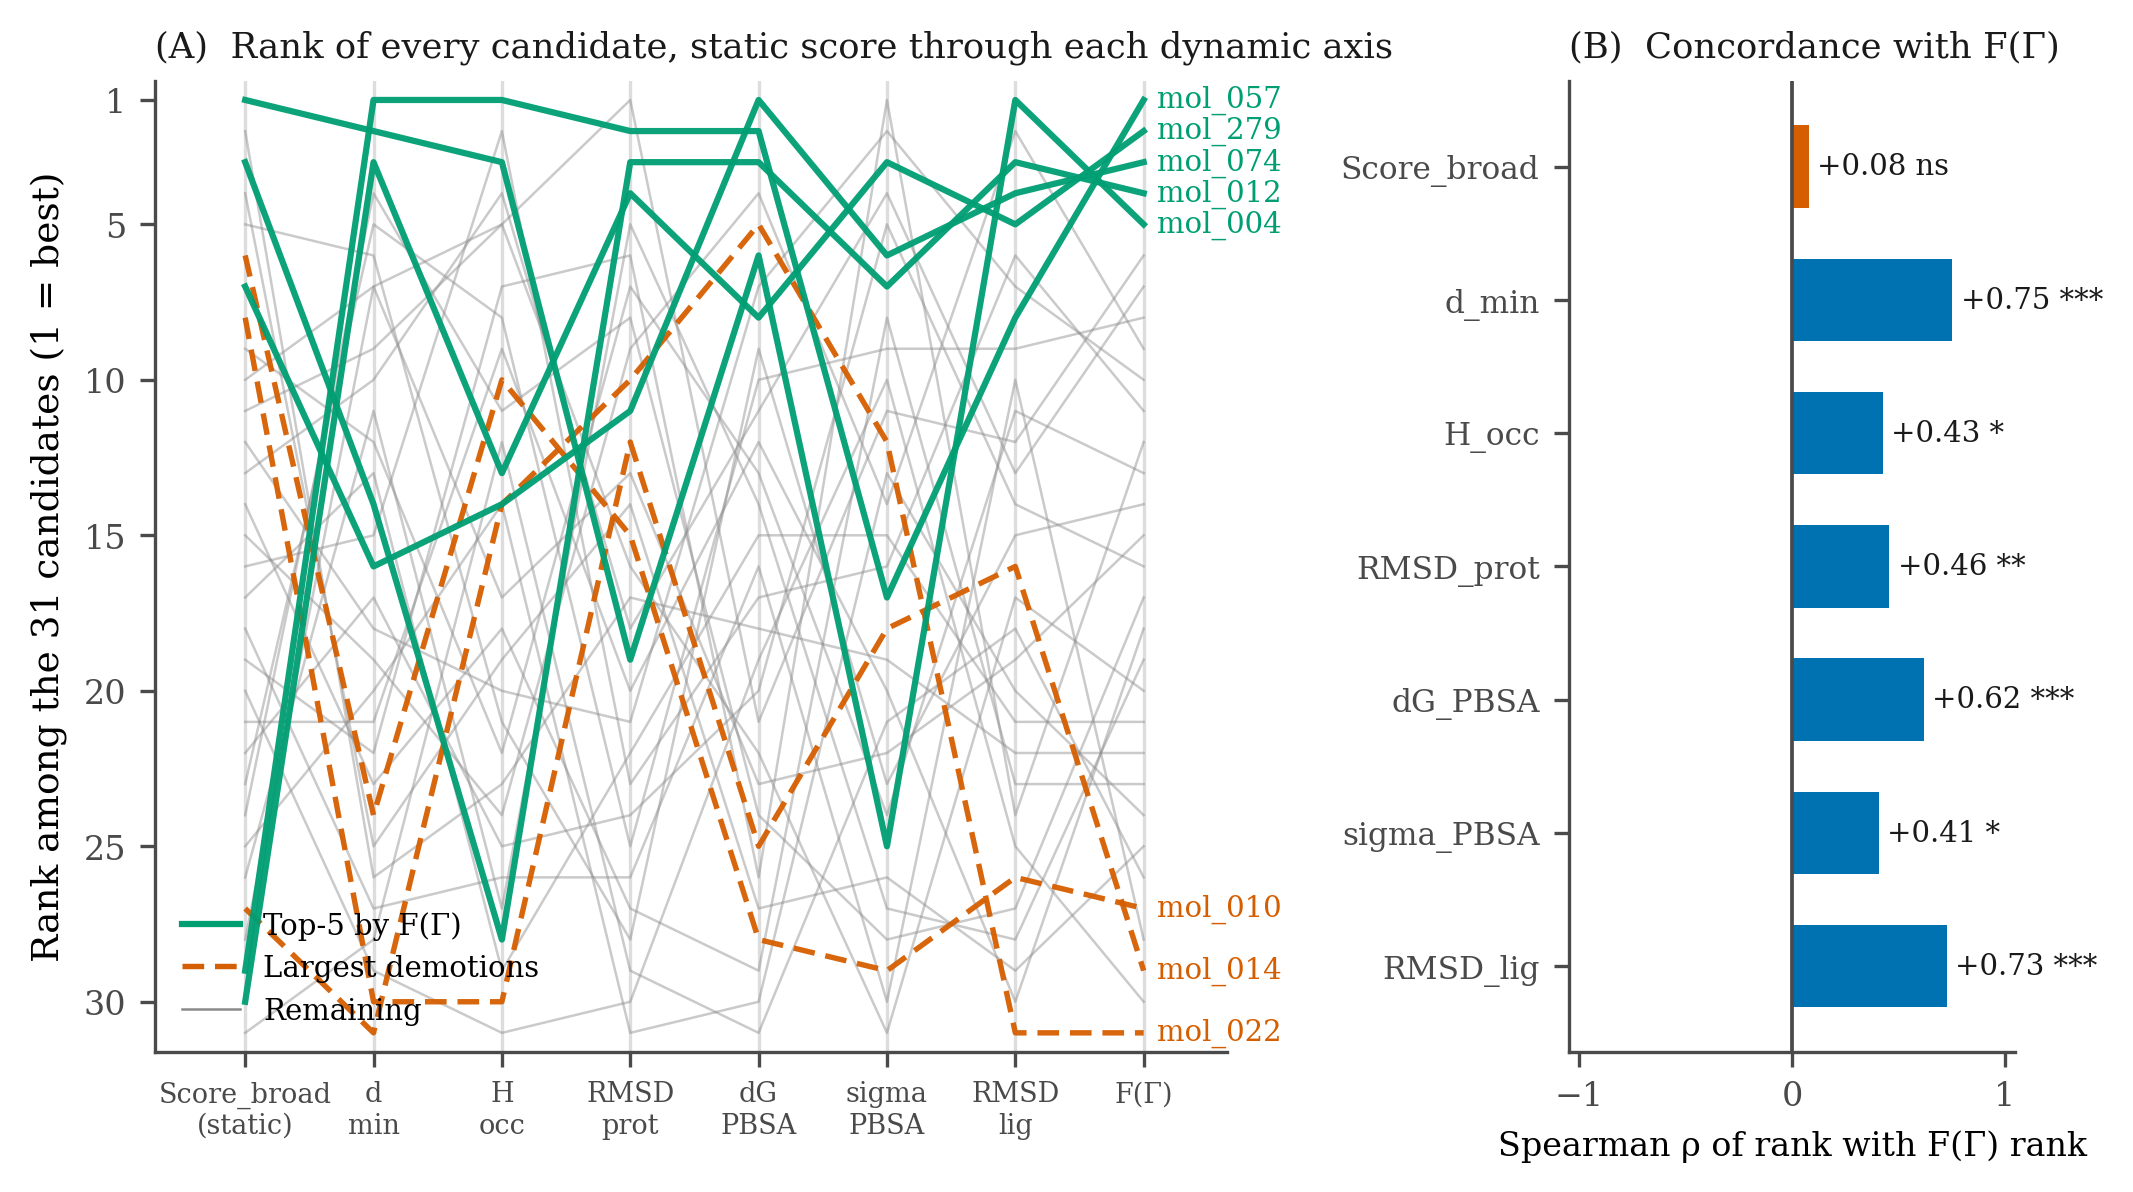

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_5.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_5.pdf`</sub>

In [15]:
# ============================================================
# Figure 3 · 多法名次一致性：BBS → 六轴 → COMPASS        （§3.5.1 · §3.3.3）
# ============================================================
# 本图所答的，是 §3.5.1 的核心之论：动力学一程把静态一程看好的候选降了下来。
# **BBS 与 COMPASS 的相关是这幅图的要害数**：若其高，此图不是支持该论而是削弱它。
# 故此处先算、先印，再由人定它入正文还是入 SI。
from scipy.stats import spearmanr as _sp5

ids5 = K[kid].astype(str).to_numpy()
# 逐轴名次：以 w_j·Z_j 降序定之，1 = 最有利。方向由权重的符号自带，不另设规则。
RK = pd.DataFrame(index=ids5)
RK["BBS"] = pd.to_numeric(K["rank_BBS"], errors="raise").to_numpy(int)
for a in AXES6:
    v = pd.to_numeric(K[ZCOL[a]], errors="raise").to_numpy(float) * W_APPLIED[a]
    RK[a] = pd.Series(-v, index=ids5).rank(method="min").astype(int)
RK["COMPASS"] = pd.to_numeric(K[kr], errors="raise").to_numpy(int)
COLS5 = ["BBS"] + AXES6 + ["COMPASS"]

# 要害数，先印
rho_bc, p_bc = _sp5(RK["BBS"], RK["COMPASS"])
print("  BBS 名次 对 F(Γ) 名次：Spearman ρ = %+.3f  (p = %.3g)" % (rho_bc, p_bc))
print("  —— 此数若高，则「动力学把静态看好者降下」一论被削弱；低则此图为该论之直接图证。")

# 降幅最大者：由数据选出，不写死
RK["drop"] = RK["COMPASS"] - RK["BBS"]
dem = list(DEMOTE)                      # 与 Table 4、Figure 5 同一组，不另选
tier1_ids = [str(x) for x in K.loc[K["tier"].astype(str).str.replace(" ", "") == "Tier1", kid]]
lead = list(LEAD5)
print("  Tier 1: %s" % ", ".join(tier1_ids))
print("  降幅最大者（F(Γ) 名次 − BBS 名次）: %s"
      % ", ".join("%s %+d" % (m, RK.loc[m, "drop"]) for m in dem))
if "pool_mol_022" not in dem:
    print("  注：§3.5.1 所举的末位 pool_mol_022 不在降幅最大的三者之列；其意义在于末位本身。")

fig, (p1, p2) = plt.subplots(1, 2, figsize=(8.0, 4.2),
                             gridspec_kw={"width_ratios": [2.4, 1.0], "wspace": 0.45})
xs = np.arange(len(COLS5))
for m in ids5:
    y = RK.loc[m, COLS5].to_numpy(float)
    if m in lead:
        p1.plot(xs, y, color=PAL6[2], lw=1.5, zorder=4, alpha=0.95)
    elif m in dem:
        p1.plot(xs, y, color=C_LOST, lw=1.3, ls=(0, (4, 2)), zorder=3, alpha=0.95)
    else:
        p1.plot(xs, y, color=MUTED, lw=0.6, zorder=1, alpha=0.45)
for x in xs:
    p1.axvline(x, color="#dddddd", lw=0.8, zorder=0)
p1.set_ylim(len(ids5) + 0.6, 0.4)          # 名次自 1 起，无第 0 名
p1.set_yticks([1] + list(range(5, len(ids5) + 1, 5)))
p1.set_xticks(xs)
p1.set_xticklabels(["Score_broad\n(static)"] + [a.replace("_", "\n") for a in AXES6] + ["F(Γ)"],
                   fontsize=6.5)
p1.set_ylabel("Rank among the 31 candidates (1 = best)")
p1.set_xlim(-0.70, len(COLS5) - 0.35)
for m in lead:
    p1.annotate(m.replace("pool_", ""), (xs[-1] + 0.10, RK.loc[m, "COMPASS"]),
                fontsize=7, color=PAL6[2], va="center", ha="left", clip_on=False)
for m in dem:
    p1.annotate(m.replace("pool_", ""), (xs[-1] + 0.10, RK.loc[m, "COMPASS"]),
                fontsize=7, color=C_LOST, va="center", ha="left", clip_on=False)
p1.set_title("(A)  Rank of every candidate, static score through each dynamic axis",
             loc="left", fontsize=8.5, color=INK)
from matplotlib.lines import Line2D
p1.legend(handles=[Line2D([], [], color=PAL6[2], lw=1.5, label="Top-5 by F(Γ)"),
                   Line2D([], [], color=C_LOST, lw=1.3, ls=(0, (4, 2)),
                          label="Largest demotions"),
                   Line2D([], [], color=MUTED, lw=0.6, label="Remaining")],
          loc="lower left", fontsize=7, handlelength=2.0)

# (B) 各列名次与 COMPASS 名次的一致性；(C) BBS 与六轴原值的相关
rows5 = []
for c in ["BBS"] + AXES6:
    r, pv = _sp5(RK[c], RK["COMPASS"])
    rows5.append({"series": c, "rho_vs_COMPASS": r, "p": pv})
CC = pd.DataFrame(rows5)
yy = np.arange(len(CC))[::-1]
p2.barh(yy, CC.rho_vs_COMPASS, color=[C_LOST if c == "BBS" else PAL6[0] for c in CC.series],
        height=0.62, zorder=3)
p2.axvline(0, color=INK2, lw=0.9, zorder=4)
_DISP5 = {"BBS": "Score_broad", "COMPASS": "F(Γ)"}
p2.set_yticks(yy); p2.set_yticklabels([_DISP5.get(c, c) for c in CC.series], fontsize=7.5)
p2.set_xlim(-1.05, 1.05)
p2.set_xlabel("Spearman ρ of rank with F(Γ) rank", fontsize=8)
for y, (_, r) in zip(yy, CC.iterrows()):
    star = "***" if r.p < 0.001 else "**" if r.p < 0.01 else "*" if r.p < 0.05 else "ns"
    off = 0.04 if r.rho_vs_COMPASS >= 0 else -0.04
    p2.text(r.rho_vs_COMPASS + off, y, "%+.2f %s" % (r.rho_vs_COMPASS, star),
            fontsize=7, va="center", color=INK,
            ha="left" if r.rho_vs_COMPASS >= 0 else "right")
p2.set_title("(B)  Concordance with F(Γ)", loc="left", fontsize=8.5, color=INK)

save_table(CC, "S13",
           "Rank concordance of the static score and of each dynamic axis with the composite "
           "ranking, over the 31 primary candidates. The static score is listed on the same "
           "footing as the six axes so that its relation to the final ranking can be read "
           "directly rather than inferred.", floatfmt="%.6f")

save_fig(fig, 5, "rank concordance, BBS through the six axes to F(Γ)",
         caption="Rank of every one of the 31 primary candidates under the static "
                 "broad-spectrum score, under each of the six dynamic axes taken separately, "
                 "and under the composite. (A) Each line is one candidate; a candidate's position on "
                 "an axis is its rank when that axis alone is ordered by the sign of its applied "
                 "weight, so rank 1 is always the most favorable. The five leading candidates "
                 "and the largest static-to-dynamic demotions are highlighted; the remaining "
                 "candidates are drawn in gray. (B) Spearman rank correlation of each series "
                 "with the composite ranking. The static score enters this panel on the same "
                 "footing as the six dynamic axes, so the degree to which the dynamic stage "
                 "reorders the static selection can be read from the figure rather than "
                 "asserted (§3.3.2). Significance markers in (B): *** p < 0.001, "
                 "** p < 0.01, * p < 0.05, ns not significant.")

In [16]:
# 并入自 cell_figdata.py（2026-11-20）
# ============================================================
# Figure 1 与 Figure 2 共用的取数层 —— 全部现算，无一键入
# ============================================================
# 2026-11-20 改写。本地原型（_fig1_data.py）有三处只在存档克隆上成立、上集群必坏：
#   一、路径按**存档**写（04_structural/results/… 等），而笔记本的 ROOT 是 **lang2**；
#   二、四个量自 tables_from_run.json 读表，而该 JSON **不是本笔记本的产物**
#       （本笔记本无一处写它），故那是一处跨笔记本、且跨轮次的陈旧输入依赖；
#   三、卡 8 的存档体量用 os.walk(ROOT) —— 在 lang2 上会把全部轨迹算进去，
#       印出的将是数万档、数百 GB，而非 665 档 / 52.51 MB。
# 今三处一并改：路径一律走 resolve()（lang2 口径）；四个量改自其底层 CSV 现算；
# 卡 8 改走**存档副本自己的根**，找不到则置 None 并当场出声，由图面省去该句，
# 而不是印一个错数。
#
# ⚠ 整个取数包在函数里，只留 _FIG_DATA 一个名字。

def _load_fig_data():
    # 笔记本的单元 1 只 import os/re/json/glob/hashlib/textwrap/datetime 与 np/pd/plt，
    # **没有 csv、io、math**。本档用到前两者，故在函数内补（不外泄）。
    import csv, io
    import re as _re
    import statistics as _st
    D = {}

    # —— 卡 1：范围记录母体数、实建微状态数 ——
    _psc = resolve("scope 表（1606 身份）", ["results/00_scope/all_candidates_v3_start.csv"])
    _pbb = resolve("对接母表（1765 微状态）", ["results/04_docking/node04_bbs_table.csv"])
    sc  = list(csv.DictReader(io.open(_psc, encoding="utf-8")))
    bbs = list(csv.DictReader(io.open(_pbb, encoding="utf-8")))
    D["scope"], D["micro"] = len(sc), len(bbs)
    D["cand"] = sum(1 for r in bbs if r["pool_class"] == "candidate")
    D["frag"] = sum(1 for r in bbs if r["pool_class"] == "fragment")

    # 母体 = 剥去微状态后缀 _sNN 的配体名。此约定由数据本身实测得出：
    # 1,765 条中 1,506 条为裸名、259 条带 _sNN；剥后唯一母体恰为 1,601，
    # 而范围记录的 1,606 减之即 5，正是 §S-16 所称「未被任何已对接微状态代表」者。
    # （已入库的 cohort31_provenance.py 第 62 行把后缀写作 pool_mol_001__m0，
    #   与数据不符；其代码用 search 故仍可跑，但那行注释应订正。）
    _par = lambda x: _re.sub(r"_s\d+$", "", x)
    _P = {_par(r["ligand"]) for r in bbs}
    D["parents"] = len(_P)
    D["unrep"]   = sorted({r["name"] for r in sc} - _P)

    # —— 卡 2：对接次数 = 微状态 × 受体 × 种子。后两者自对照 manifest 现算 ——
    _pman = resolve("对接对照 manifest",
                    ["results/04_docking/redock_control/crossdock_control_manifest.json"])
    _man = json.load(io.open(_pman, encoding="utf-8"))
    D["seeds"]  = len(_man["seeds"])
    D["recept"] = len({e["target"] for e in _man["matrix"]})
    D["runs"]   = D["micro"] * D["recept"] * D["seeds"]

    # —— 卡 3：候选数 = 排序表行数；三臂规模自 analysis.json 逐档点数 ——
    _prk = resolve("F(Γ) 排序", ["results/step8d_compass_ranking_SOLV_V3.csv"])
    RK = list(csv.DictReader(io.open(_prk, encoding="utf-8")))
    D["cands31"] = len(RK)
    _ARM = [("main", "step6e_solv_v3"), ("ref", "step6e_solv_v3_ref"), ("cross", "step6e_cross_v3")]
    _n = {}
    for _k, _d in _ARM:
        _f = glob.glob(os.path.join(ROOT, "results", _d, "*", "*", "analysis.json"))
        _n[_k] = len(_f)
        _sys = len({os.path.basename(os.path.dirname(os.path.dirname(x))) for x in _f})
        D["sys_" + _k] = _sys
    D["n_main"], D["n_ref"], D["n_cross"] = _n["main"], _n["ref"], _n["cross"]
    D["n_traj"] = sum(_n.values())
    D["n_sys"]  = D["sys_main"] + D["sys_ref"] + D["sys_cross"]
    if D["n_traj"] % D["n_sys"]:
        raise AssertionError("轨迹数 %d 不是体系数 %d 的整倍，副本数无法成立"
                             % (D["n_traj"], D["n_sys"]))
    D["reps"] = D["n_traj"] // D["n_sys"]

    # —— 卡 5：六轴权重（所施那一列）与 ρ ——
    _pw = resolve("权重·所施", ["results/Scoring_compass_weights_V3.csv"])
    D["W"] = [(r["axis"], float(r["W_published_V3"]))
              for r in csv.DictReader(io.open(_pw, encoding="utf-8"))]
    # ρ 不自 Table S13 读，而自排序表的两列名次现算（实测复现 0.078226，六位小数全同）
    _x = [float(r["rank_BBS"]) for r in RK]
    _y = [float(r["rank_COMPASS"]) for r in RK]
    _mx, _my = _st.mean(_x), _st.mean(_y)
    _num = sum((a - _mx) * (b - _my) for a, b in zip(_x, _y))
    _den = (sum((a - _mx) ** 2 for a in _x) * sum((b - _my) ** 2 for b in _y)) ** 0.5
    D["rho"] = _num / _den

    # —— 成对分辨下限（§3.4.1）：2 × 副本间离散度之**中位数** / √3 ——
    # 2.3347 是 31 个 σ_PBSA 的中位数（非均值 2.6362、非 RMS 3.0376），
    # 2 × 2.3347 / √3 = 2.6959 → 正文作 2.70 kcal/mol。
    _sig = sorted(float(r["sigma_PBSA"]) for r in RK)
    _m = len(_sig) // 2
    D["med_sigma"] = _sig[_m] if len(_sig) % 2 else (_sig[_m - 1] + _sig[_m]) / 2
    D["res_kcal"] = 2.0 * D["med_sigma"] / (3.0 ** 0.5)

    # —— 参考对之反序幅度（§3.4.3，稿载 +6.48）：自参考臂逐副本 TOTAL 现算 ——
    _ppb = resolve("参考臂 PB 逐副本 TOTAL",
                   ["Scoring/solv_alt_2026-11-16/ref_panel_PB_per_replica_TOTAL.csv"])
    _g = {}
    for r in csv.DictReader(io.open(_ppb, encoding="utf-8")):
        _g.setdefault(r["system"], []).append(float(r["TOTAL"]))
    _mean = lambda k: sum(_g[k]) / len(_g[k])
    D["dg_gap"] = _mean("ref_ensitrelvir__6W63__primary") - _mean("ref_AVI_1084__6W63__primary")
    if D["dg_gap"] <= 0:
        raise AssertionError("参考对之 Δ 须为正（潜能反序），实得 %+.4f" % D["dg_gap"])

    # —— 卡 7：保持比例。判据与 Figure 3 同：d ≤ 5.0 Å 之帧占比 ≥ 0.50 ——
    DCUT, GATE = 5.0, 0.50
    def held(pat, expect):
        f = resolve_many("逐帧二联体距离", pat, expect=expect)
        k = 0
        for p in f:
            z = np.load(p, allow_pickle=True)
            arr = np.asarray(z["d_dyad"] if "d_dyad" in z.files else z[z.files[0]])
            if (arr <= DCUT).mean() >= GATE: k += 1
        return k, len(f)
    D["main_held"],  D["main_n"]  = held("results/aud_main_site_occupancy_series/*.npz",  D["n_main"])
    D["cross_held"], D["cross_n"] = held("results/aud_cross_site_occupancy_series/*.npz", D["n_cross"])

    # —— 卡 7 另一量：配体 RMSD 偏高而仍占位的副本数（稿载 41）——
    # 出处是占有率审计档自身：它除 99 行逐副本外，还带 rmsd_lig_mean_from_phase4 一列，
    # 故无须与 phase4 体系级表相联。
    _pocc = resolve("主臂占有率", ["results/aud_main_site_occupancy.csv"])
    _occ = list(csv.DictReader(io.open(_pocc, encoding="utf-8")))
    D["rmsd_high"] = sum(1 for r in _occ
                         if float(r["rmsd_lig_mean_from_phase4"]) > 5.0
                         and float(r["site_occupancy"]) >= 0.50)
    # 伴随量：上述 rmsd>5 Å 子集（43 副本）中占有率满格者 28，正文第 301 行即此读法。
    # 注意它**嵌在** rmsd>5 Å 之内；若误作全队列 occ==1.000 则为 83，非同一量。
    D["rmsd_high_full"] = sum(1 for r in _occ
                              if float(r["rmsd_lig_mean_from_phase4"]) > 5.0
                              and abs(float(r["site_occupancy"]) - 1.0) < 1e-9)

    # —— 卡 8：存档体量。**不走 ROOT**（那是 lang2，含全部轨迹），走存档副本自己的根。——
    # 口径：§6.1 的 52.51 MB 是十进制 MB（/1e6），不是 MiB（/1048576）；
    # 且取**整树**（665 档）而非 MANIFEST 子集（656 条）。两者不可混用。
    _dep = None
    for _c in ("githubdyn", "../githubdyn", "GitHub/PRISM-Dyn", "PRISM-Dyn"):
        _p = os.path.join(ROOT, _c)
        if os.path.isdir(_p) and os.path.isfile(os.path.join(_p, "MANIFEST.sha256")):
            _dep = _p; break
    if _dep is None:
        D["dep_files"] = D["dep_mb"] = None
        print("  ⚠ 存档副本未找到（试过 githubdyn 等四处），卡 8 的「665 档 / 52.51 MB」"
              "本轮省去，图面不印该句。要印就把存档放到 ROOT/githubdyn。")
    else:
        n = s = 0
        for dp, dn, fn in os.walk(_dep):
            dn[:] = [x for x in dn if x != ".git"]
            for x in fn:
                n += 1; s += os.path.getsize(os.path.join(dp, x))
        D["dep_files"], D["dep_mb"] = n, s / 1000000.0
        print("  存档副本 %s → 整树 %d 档 · %.2f MB（十进制）"
              % (os.path.relpath(_dep, ROOT), n, D["dep_mb"]))
    return D

_FIG_DATA = _load_fig_data()
print("  取数层：范围 %d → 实建母体 %d → 微状态 %d（候选 %d + 片段 %d）· 对接 %s 次"
      % (_FIG_DATA["scope"], _FIG_DATA["parents"], _FIG_DATA["micro"],
         _FIG_DATA["cand"], _FIG_DATA["frag"], format(_FIG_DATA["runs"], ",")))
print("  三臂 %d 体系 / %d 轨迹（主 %d · 参 %d · 跨 %d）· 副本 %d · ρ %.6f"
      % (_FIG_DATA["n_sys"], _FIG_DATA["n_traj"], _FIG_DATA["n_main"],
         _FIG_DATA["n_ref"], _FIG_DATA["n_cross"], _FIG_DATA["reps"], _FIG_DATA["rho"]))
print("  保持 主 %d/%d · 跨 %d/%d · rmsd>5Å 且在位 %d（其中满格 %d）"
      % (_FIG_DATA["main_held"], _FIG_DATA["main_n"], _FIG_DATA["cross_held"],
         _FIG_DATA["cross_n"], _FIG_DATA["rmsd_high"], _FIG_DATA["rmsd_high_full"]))
print("  σ 中位 %.4f → 成对分辨下限 %.4f kcal/mol（正文作 %.2f）"
      % (_FIG_DATA["med_sigma"], _FIG_DATA["res_kcal"], _FIG_DATA["res_kcal"]))
print("  参考对 Δ %+.4f kcal/mol（正文作 %+.2f）· 超分辨下限 %.1f 倍"
      % (_FIG_DATA["dg_gap"], _FIG_DATA["dg_gap"], _FIG_DATA["dg_gap"] / _FIG_DATA["res_kcal"]))


  [scope 表（1606 身份）] results/00_scope/all_candidates_v3_start.csv
  [对接母表（1765 微状态）] results/04_docking/node04_bbs_table.csv
  [对接对照 manifest] results/04_docking/redock_control/crossdock_control_manifest.json
  [F(Γ) 排序] results/step8d_compass_ranking_SOLV_V3.csv
  [权重·所施] results/Scoring_compass_weights_V3.csv
  [参考臂 PB 逐副本 TOTAL] Scoring/solv_alt_2026-11-16/ref_panel_PB_per_replica_TOTAL.csv
  [逐帧二联体距离] results/aud_main_site_occupancy_series/*.npz → 99 个
  [逐帧二联体距离] results/aud_cross_site_occupancy_series/*.npz → 36 个
  [主臂占有率] results/aud_main_site_occupancy.csv
  存档副本 githubdyn → 整树 663 档 · 52.24 MB（十进制）
  取数层：范围 1606 → 实建母体 1601 → 微状态 1765（候选 1689 + 片段 76）· 对接 26,475 次
  三臂 49 体系 / 147 轨迹（主 99 · 参 12 · 跨 36）· 副本 3 · ρ 0.078226
  保持 主 97/99 · 跨 31/36 · rmsd>5Å 且在位 41（其中满格 28）
  σ 中位 2.3347 → 成对分辨下限 2.6959 kcal/mol（正文作 2.70）
  参考对 Δ +6.4833 kcal/mol（正文作 +6.48）· 超分辨下限 2.4 倍


  六个权重已与所施之权重逐轴对账。
  取数：候选 31 · rho = +0.078 (p = 0.676) · 三臂 99+12+36 = 147 · 六轴已列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_1_study_design.png   （600 dpi，双栏宽 7.2 in）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_1_study_design.pdf   （同上，矢量）


**Figure 1.** Architecture of the dynamic evaluation, and the score it places under test. A single hard gate selects the cohort — a threshold on a docking-derived score, applied once with charge stratification (§2.3.1; labeled `BBS` in the figure and deposited files, and `Score_broad` in the text) — and the three arms that follow apply no further gate and are not sequential refinement stages; two of them are controls. **The reference panel is external to the cohort**: AVI-1084, ensitrelvir and X77 were never generated by this campaign, never entered the 1,606-identity pool and never passed the selection gate. They were simulated against the same receptor under the same protocol and are projected onto the scale the 31 candidates define rather than being members of it, which is what allows them to serve as an external anchor at all. The lower panel gives the composite itself, because the findings of the first two arms bear on specific axes of it. Active-site occupancy, a site-resolved quantity computed here, is measured separately and is deliberately not a seventh axis (§3.2.4). Counts are trajectories: 147 in all, each of 100 ns, in three independent replicas per system against three main proteases. The figure is drawn as parallel arms rather than as a funnel because the dynamic stage eliminates no candidate, which is a property of the method and not of this cohort. It reports the design of the evaluation and not its outcome; the results of the three arms are given in §3.3, §3.4 and §3.6 respectively.

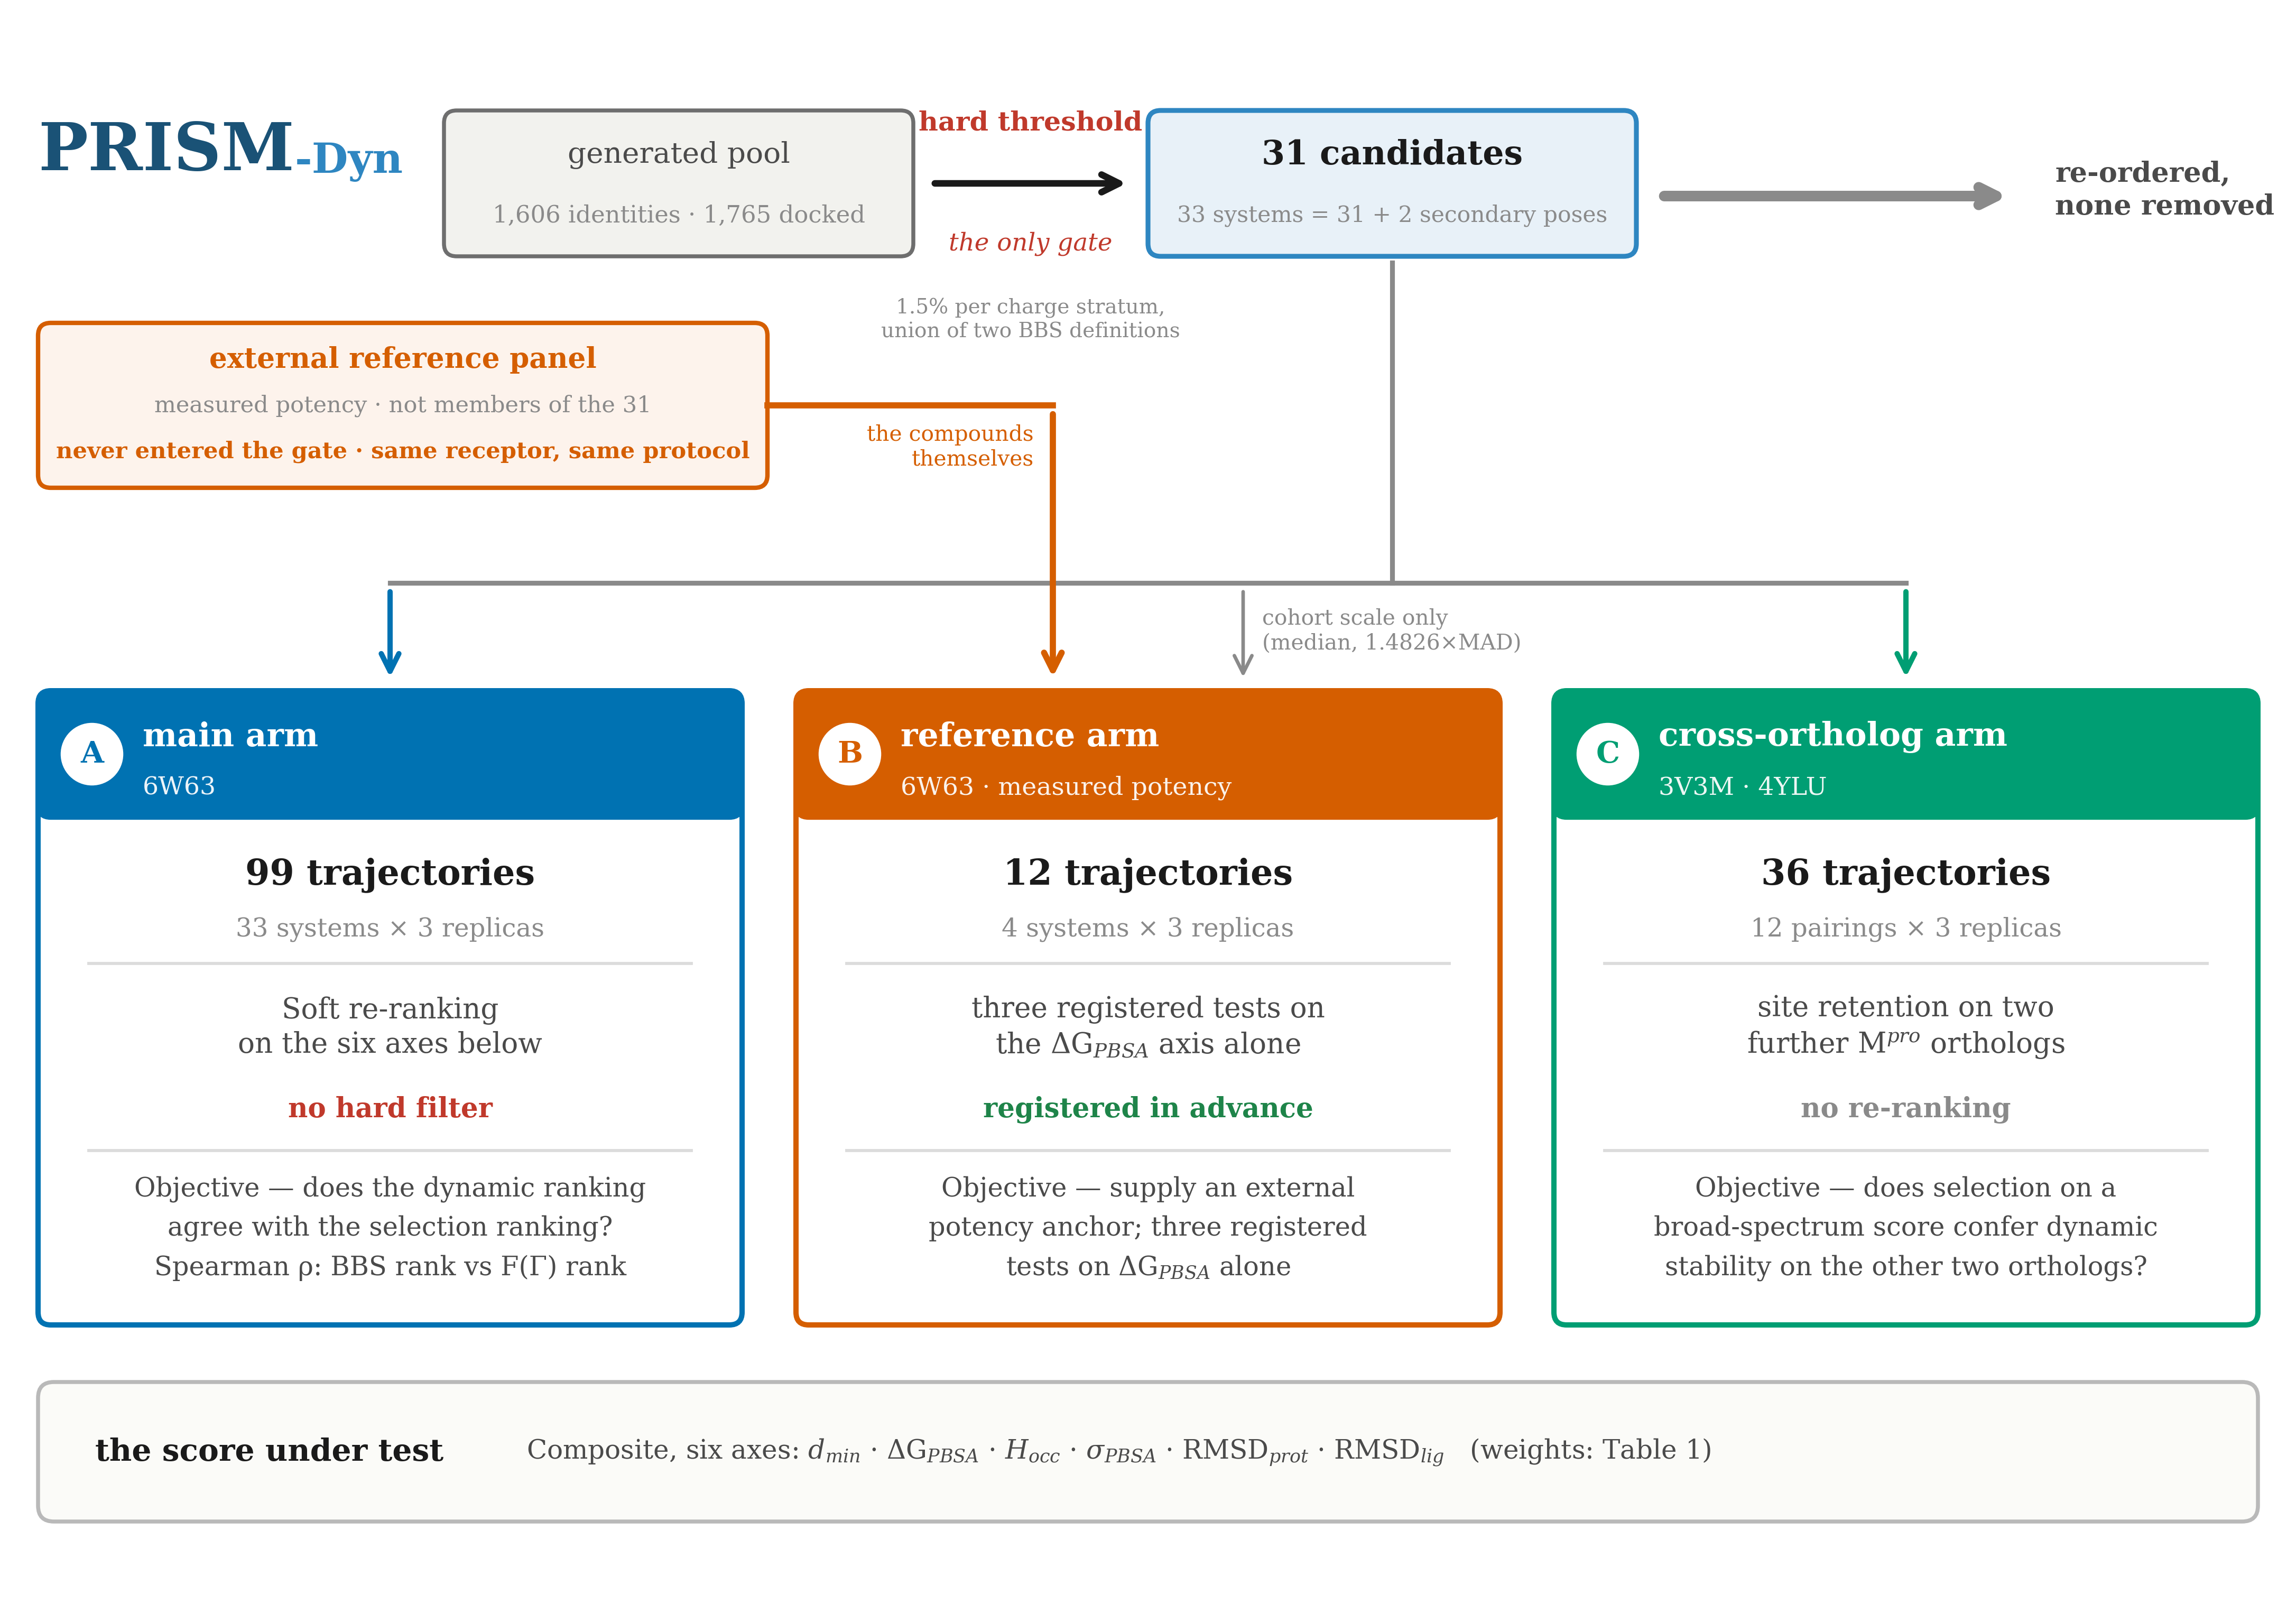

In [17]:
# ============================================================
# Figure 1 · PRISM-Dyn 实验设计图：一闸 · 三臂 · 受检之分数本身     （§2 · §3）
# ============================================================
# **两条设计判断写在这里，免得日后被改坏。**
#
# 一 · **本图不得画成漏斗。** PRISM-Gen 的 Fig. 1 是漏斗（4,136 → … → 36），
#   逐级筛减。PRISM-Dyn 恰恰相反：动态阶段**不设硬阈**（摘要自书 "applied no
#   hard filter"），31 进 31 出只是次序变了；三臂中两臂是**对照**而非后续工位；
#   且本文头条结论为**阴性**。漏斗图说「我们筛出了赢家」，与摘要
#   "We report an evaluation rather than a discovery" 直接相抵。
#
# 二 · **COMPASS 这只黑箱须打开**（2026-11-01 据所收建议施行）。只写
#   "six-axis composite"，读者无从知道那六个轴是什么、尺度从何而来，于是主臂与
#   参考臂的两项阴性结论**没有靶**。故加一条横带，逐轴列其名、单位与所施权重：
#     · 尺度由这 31 个分子自身定义（median 与 1.4826×MAD），是**内部**排序，
#       与参考臂的 "measured potency" 恰成对照——此即 §1.2 第二处关切；
#     · ◆ 标出名字暗示位点分辨的两轴（d_min · H_occ）。依 §2.6.1：d_min 是配体到
#       **任一蛋白重原子**之距（nm），而位点占有率用的是配体到**催化二联体**之距（Å），
#       「They are different quantities in different units」——此即 §1.2 第一处关切；
#     · ✗ 标出预登记检验所证伪的那一轴（ΔG_PBSA），其所施权重 −1.93 在六轴中
#       绝对值第二大（§4.5 第 1 条）。权重作条，一眼看见失败打在第二重的轴上；
#     · 并注明：真正位点分辨的那个量**刻意不入第七轴**（§1.4）。
#
# 图上每个数先自 notebook 既有对象取，再与稿件所载互验；不符即 warn，不静默。
#
# ⚠ **整个绘图过程包在一个函数里，这是 2026-11-01 一次真故障换来的。**
# 本 cell 原先在顶层绑定了 76 个名字，其中 12 个与上游同名且后续仍要用——
# `ARMS`（上游是五元组，这里被改绑成字典列表）与 `A`（上游是 DataFrame，
# 这里被 for 循环改绑成字典）两处，直接把 Table S2 · S3 · S10 三个 cell 打挂：
#     ValueError: too many values to unpack (expected 5)
#     TypeError: unhashable type: 'list'
# 它一开始没显形，是因为那时本 cell 在那三个 cell **之前**跑；把它后移以修
# `_sp5` 的 NameError 之后，它的绑定就活到了下游，于是撞上。
# 包成函数，其局部一个也不外泄——这堵的是一整类问题，不是那 12 个名字。
from matplotlib.patches import FancyBboxPatch, Circle, Polygon, Rectangle

def _figure_A():
    N_CAND = int(len(K))
    _rho_a, _p_a = _sp5(RK["BBS"], RK["COMPASS"])
    RHO_BBS, P_BBS = float(_rho_a), float(_p_a)
    # 2026-11-20：以下七个量原为键入后以 warn 核对。那是良好的防御习惯，但并不严格
    # 满足 §6.1（"reads only the deposited derived data"）—— 键入值仍是键入值。
    # 今一律改取取数层，与 Figure 2 同源，故相邻两图在结构上不可能相左。
    N_POOL_ID, N_POOL_MS = _FIG_DATA["scope"], _FIG_DATA["micro"]
    N_SYS, N_MAIN = _FIG_DATA["sys_main"], _FIG_DATA["n_main"]
    N_REF, N_CROSS = _FIG_DATA["n_ref"], _FIG_DATA["n_cross"]
    N_RMSD_HIGH, DG_GAP = _FIG_DATA["rmsd_high"], _FIG_DATA["dg_gap"]
    FOLD_LO, FOLD_HI = 592, 2231
    # 跨臂失位数现算（跨臂副本数 − 保持数）；成对失位的 4 仍键入，其判据不在取数层。
    N_CROSS_LOST = _FIG_DATA["cross_n"] - _FIG_DATA["cross_held"]
    N_CROSS_PAIR_LOST = 4
    FS = 1.00          # 全局字号倍数：下面每个 fontsize 都乘它；想整体大一点改成 1.05
    OCC_CUT, OCC_WIN, OCC_FRAMES = 5.0, 50, 501
    BBS_SPAN_PCT = 14        # §3.3.2：31 个只占所自出之标注集 BBS 全距的 14%
    # 2026-11-20 裁定：RES_F（0.904）删去 —— 它在正文无一处出现，其注释所指的 §3.5.1
    # 并不含此数，且七种候选构造皆不能复现它（最近者 1.083）。不另定新的 F 标尺阈值：
    # 在数据已看清、稿件已冻结之后新造一个量，是事后指标。kcal 标尺的 2.70 正文已论证，
    # 删 F 侧不损失论证。RES_KCAL 亦不再键入，改取取数层（与 Figure 2 同源）：
    RES_KCAL = _FIG_DATA["res_kcal"]        # = 2 × median(σ_PBSA) / √3 = 2.6959 → 2.70
    BBS_MAXR = 0.13          # §2.6.1：BBS 与六轴之最大 |r|

    # 六轴：名 · 单位 · 所施权重 · 名字是否暗示位点分辨 · 是否为预登记检验所证伪
    # （此表在 arch_fig.py 中位于绘图体之前，拼 cell 时须随头部一并带入——
    #   2026-11-01 第一次拼接即漏了它，而试跑立刻以 NameError 报了出来。）
    AXES = [
        ("$d$$_{min}$",         "nm",       -2.00, True,  False),
        (r"$\Delta$G$_{PBSA}$", "kcal/mol", -1.93, False, True),
        ("$H$$_{occ}$",         "fraction", +1.51, True,  False),
        (r"$\sigma$$_{PBSA}$",  "kcal/mol", -1.27, False, False),
        ("RMSD$_{prot}$",       "Å",        -1.22, False, False),
        ("RMSD$_{lig}$",        "Å",        -1.16, False, False),
    ]
    assert len(AXES) == 6
    assert abs(max(abs(w) for _n, _u, w, _s, _f in AXES) - 2.00) < 1e-9, "归一化锚须为 |w| = 2.00"

    # ── 与 Table 1 所施之权重对账：图上所画者须与所施者逐轴相符 ──────────
    _WANT = {"d_min": -2.00, "H_occ": 1.51, "RMSD_prot": -1.22,
             "dG_PBSA": -1.93, "sigma_PBSA": -1.27, "RMSD_lig": -1.16}
    _wsrc = None
    # 注：**包进函数之后，dir() 看到的是局部名**，故此处须查 globals()。
    # 2026-11-01 包装时一度仍写 dir()，于是权重对账静默地「找不到对象」而跳过——
    # 对账跳过了却照常出图，是比报错更坏的一种失效，故记此一笔。
    for _nm in ("W_published_V3", "W_APPLIED", "WPUB"):
        if _nm in globals():
            _wsrc = globals()[_nm]; break
    if isinstance(_wsrc, dict):
        for _k, _v in _WANT.items():
            _got = _wsrc.get(_k)
            if _got is not None and abs(float(_got) - _v) > 0.005:
                warn("Figure 1：轴 %s 的所施权重实为 %+.3f，图上画的是 %+.2f。"
                     % (_k, float(_got), _v))
        print("  六个权重已与所施之权重逐轴对账。")
    else:
        print("  注：所施权重的对象不在命名空间内（试过 W_published_V3 · W_APPLIED · WPUB，")
        print("      规则 23），故图上六个权重本次未经机器对账；其值取自 §2.6.2。")

    if N_CAND != 31:
        warn("Figure 1：K 表给出 %d 个候选，稿件通篇作 31 —— 先查清，勿改图。" % N_CAND)
    if N_SYS * 3 != N_MAIN:
        warn("Figure 1：%d 系统 × 3 不等于 %d 条主臂轨迹。" % (N_SYS, N_MAIN))
    if N_MAIN + N_REF + N_CROSS != 147:
        warn("Figure 1：三臂之和为 %d，§2.7.3 的清册载 147。" % (N_MAIN + N_REF + N_CROSS))
    if abs(RHO_BBS - 0.078) > 0.005:
        warn("Figure 1：BBS 对 F(Γ) 实算 rho = %+.3f，稿载 +0.078。" % RHO_BBS)
    print("  取数：候选 %d · rho = %+.3f (p = %.3f) · 三臂 %d+%d+%d = %d · 六轴已列"
          % (N_CAND, RHO_BBS, P_BBS, N_MAIN, N_REF, N_CROSS, N_MAIN + N_REF + N_CROSS))

    # 本 cell 出的是**正文用的实验设计图**：剥去一切结果，只留拓扑与设计属性。
    # 缘由（2026-11-01 采纳之意见）：正文开篇的流程图其职在示「我们做了什么」，
    # 不在剧透「我们发现了什么」。阴性结论（rho、FAILED、5/36）已尽数移出图外——
    # 它们属于 §3，而设计属性（不设硬阈、事先登记、不重排）是方法的性质，故留。
    # 自图上移出的那几段散文（147 条轨迹、位点保持之定义、尺度为内部、BBS 排除之由），
    # **一并移入下方的图题注**：期刊排版不收被「烤」进 PNG 的大段文字，
    # 那样的字既不可检索，也随图一并被缩放。
    # 若要带结果的完整版（报告或 cover letter 用），把 DESIGN 改为 False。
    DESIGN = True
    LEAN = True          # DESIGN 蕴含 LEAN
    STEM = "Figure_1_study_design"
    C_NEG, C_POS = "#C0392B", "#1E8449"
    C_EDGE, C_RULE = "#6E6E6E", "#DCDCDC"

    W, H = (7.2, 5.08) if DESIGN else (7.2, 5.66) if LEAN else (7.2, 6.92)
    fig = plt.figure(figsize=(W, H))
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, W); ax.set_ylim(0, H); ax.axis("off")
    fig.patch.set_facecolor("white")


    def box(x, y, w, h, fc="white", ec=C_EDGE, lw=0.9, z=2, rs=0.04):
        ax.add_patch(FancyBboxPatch((x, y), w, h,
                                    boxstyle="round,pad=0,rounding_size=%g" % rs,
                                    facecolor=fc, edgecolor=ec, linewidth=lw, zorder=z))


    def fits(s_txt, fs, boxw, where, pad=0.10):
        # 量一行字的实际宽度，超出框宽即报——这一类溢出先前只能靠眼睛看出来。
        # 2026-11-01：「33 systems · 31 primary + 2 secondary poses」实测 1.63 in，
        # 而「31 candidates」框净宽 1.54 in、留边后 1.44 in，溢出 0.19 in 而无人拦。
        # 注：此处用注释而非 docstring —— 本函数的源码要被 code(r"..."...) 包起来，
        # 内层再出现三重双引号会提前关掉外层（今日第二次栽在同一处，故记明）。
        t = ax.text(0, -99, s_txt, fontsize=fs)
        fig.canvas.draw()
        w = t.get_window_extent(renderer=fig.canvas.get_renderer()).width / fig.dpi
        t.remove()
        if w > boxw - pad:
            raise AssertionError("[%s] 文字宽 %.2f in，框宽 %.2f in（留边 %.2f）——超出 %.2f in：\n    %s"
                                 % (where, w, boxw, pad, w - (boxw - pad), s_txt))
        return s_txt


    def arrow(x0, y0, x1, y1, c=INK, lw=1.3, z=12, ls="-"):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=z,
                    arrowprops=dict(arrowstyle="->", color=c, lw=lw,
                                    mutation_scale=10, linestyle=ls))


    # ══ 一 · 上带：池 → 唯一一道硬闸 → 31 候选 → 棱镜 ════════════════════
    TY = 4.52 if DESIGN else 5.16 if LEAN else 6.40
    # 字标合为一词。「-Dyn」的起笔不硬写：先画「PRISM」，量其收笔处，
    # 再自那里起笔。集群与本机的字体不同（一为衬线，一为无衬线），同样
    # 15 pt 粗体的「PRISM」宽度相差 0.125 in，钉死坐标必致相叠或裂开。
    # 「PRISM」仍起于 0.10，即三臂、reference panel 框、底带与脚注共用的左缘。
    _t_prism = ax.text(0.10, TY + 0.10, "PRISM", fontsize=15*FS, fontweight="bold",
            color="#1A5276", va="center")
    fig.canvas.draw()
    _x_dyn = ax.transData.inverted().transform(
        _t_prism.get_window_extent(fig.canvas.get_renderer()))[1][0]
    ax.text(_x_dyn, TY + 0.07, "-Dyn", fontsize=9.5*FS, fontweight="bold",
            color="#2E86C1", va="center")

    box(1.38, TY - 0.23, 1.48, 0.46, fc="#F2F2EE")
    ax.text(2.12, TY + 0.09, "generated pool", fontsize=6.6*FS, color=INK2, ha="center", va="center")
    ax.text(2.12, TY - 0.10,
            fits("%s identities · %s docked" % (f"{N_POOL_ID:,}", f"{N_POOL_MS:,}"),
                 5.4*FS, 1.48, "generated pool 副标题"),
            fontsize=5.4*FS, color=MUTED, ha="center", va="center")

    arrow(2.90, TY, 3.56, TY, lw=1.5)
    ax.text(3.23, TY + 0.15, "hard threshold", fontsize=6.1*FS, color=C_NEG,
            ha="center", va="bottom", fontweight="bold")
    ax.text(3.23, TY - 0.15, "the only gate", fontsize=5.6*FS, color=C_NEG,
            ha="center", va="top", style="italic")
    # §2.3.1 明言「a resource budget and not a threshold」：取两种 BBS 定义之并集、
    # 按电荷分层各取 1.5 百分位，且缺口扫描未见不连续。故此处**不得**写成单一数值阈。
    ax.text(3.23, TY - 0.36, "1.5% per charge stratum,\nunion of two BBS definitions",
            fontsize=4.7*FS, color=MUTED, ha="center", va="top", linespacing=1.25)

    box(3.60, TY - 0.23, 1.54, 0.46, fc="#E8F1F8", ec="#2E86C1", lw=1.1)
    ax.text(4.37, TY + 0.09, "%d candidates" % N_CAND, fontsize=7.6*FS,
            color=INK, ha="center", va="center", fontweight="bold")
    ax.text(4.37, TY - 0.10,
            fits("%d systems = 31 + 2 secondary poses" % N_SYS,
                 5.1*FS, 1.54, "31 candidates 副标题"),
            fontsize=5.1*FS, color=MUTED, ha="center", va="center")

    # 棱镜徽标已移至 Figure 2（七卡图），此处不再重复；裁定在案。
    # 只留「re-ordered, none removed」一句：它是本文要旨（31 进 31 出，只换次序），
    # 与徽标无关。原六条多色箭头对应六轴，而六轴在下方横带中已逐轴列名、注单位与权重，
    # 故删之不丢信息；入射箭头改为自候选框直指该句。
    py = TY
    arrow(5.20, py - 0.04, 6.34, py - 0.04, c=MUTED, lw=2.4, z=4)
    ax.text(6.46, py - 0.02, "re-ordered,\nnone removed", fontsize=6.3*FS, color=INK2,
            va="center", ha="left", linespacing=1.3, fontweight="bold")

    # ══ 二 · 三臂 ════════════════════════════════════════════════════════
    ARM_Y, ARM_H, ARM_W = ((0.92, 2.00, 2.22) if DESIGN else
                           (1.98, 1.86, 2.22) if LEAN else (2.42, 2.72, 2.22))
    GAP = (W - 0.20 - 3 * ARM_W) / 2
    AXS = [0.10 + i * (ARM_W + GAP) for i in range(3)]
    CX = [x + ARM_W / 2 for x in AXS]
    TOPB = ARM_Y + ARM_H
    BAR = TOPB + 0.34
    ax.plot([4.37, 4.37], [TY - 0.25, BAR], color=MUTED, lw=1.1, zorder=3)
    ax.plot([CX[0], CX[2]], [BAR, BAR], color=MUTED, lw=1.1, zorder=3)
    # 注：横杆横跨 A 到 C，但**只有 A 与 C 自其落下**；B 臂的来源另见下方。

    # 参考物自有来源：AVI-1084 · ensitrelvir · X77（两起始位姿），四系统 × 3 复本。
    # **它们不是这 31 个的成员**，未经对接分数筛选；只是投影到由这 31 个算出的
    # 中位数与 MAD 标尺上（§3.4.5 作「4th of 32」「8th of 32」）。
    # 先前把 B 臂画成自「31 candidates」分出的枝，是对其来源的误述，已改。
    # DESIGN 下给 0.72：原先 0.48 使面板底边与分派横杆只隔 0.02 in，看上去是贴着的。
    REFY = ARM_Y + ARM_H + (0.90 if DESIGN else 0.62 if LEAN else 0.66)
    # 框加高为三行：第三行把「从未进过那道闸」说死。
    # 2026-11-01 一位读者对着**上一版**的图仍读成「B 臂自 31 candidates 分出」——
    # 那一版确实如此，此版已改；但那次误读本身说明这条路径容易被描错，
    # 故此处再加一道字面的保险，不靠读者去追线。
    box(0.10, REFY - 0.26, 2.30, 0.52, fc="#FDF3EC", ec=PAL6[1], lw=1.0)
    ax.text(1.25, REFY + 0.145, "external reference panel", fontsize=6.4*FS,
            color=PAL6[1], ha="center", va="center", fontweight="bold")
    ax.text(1.25, REFY + 0.00, "measured potency · not members of the 31",
            fontsize=5.2*FS, color=MUTED, ha="center", va="center")
    ax.text(1.25, REFY - 0.145, "never entered the gate · same receptor, same protocol",
            fontsize=5.2*FS, color=PAL6[1], ha="center", va="center", fontweight="bold")
    # 实线：自外部来源入 B 臂（同一受体、同一协议，实跑）
    ax.plot([2.40, CX[1] - 0.30], [REFY, REFY], color=PAL6[1], lw=1.4, zorder=6)
    arrow(CX[1] - 0.30, REFY, CX[1] - 0.30, TOPB + 0.015, c=PAL6[1], lw=1.4, z=6)
    ax.text(CX[1] - 0.36, REFY - 0.13, "the compounds\nthemselves",
            fontsize=4.9*FS, color=PAL6[1], ha="right", va="center", linespacing=1.2)
    # 虚线：自队列取标尺，**仅供投影**，不是把参考物算作队列成员
    ax.plot([4.37, CX[1] + 0.30], [BAR, BAR], color=MUTED, lw=0.8,
            linestyle=(0, (2, 2)), zorder=3)
    arrow(CX[1] + 0.30, BAR, CX[1] + 0.30, TOPB + 0.015, c=MUTED, lw=0.8, z=4)
    ax.text(CX[1] + 0.36, (BAR + TOPB) / 2 + 0.02,
            "cohort scale only\n(median, 1.4826\u00d7MAD)", fontsize=4.9*FS, color=MUTED,
            ha="left", va="center", linespacing=1.2)

    ARMS = [
        dict(tag="A", name="main arm", rec="6W63", col=PAL6[0],
             n=N_MAIN, sub="%d systems × 3 replicas" % N_SYS,
             does="Soft re-ranking\non the six axes below",
             hard="no hard filter", hc=C_NEG,
             obj=["Objective — does the dynamic ranking",
                  "agree with the selection ranking?",
                  "Spearman ρ: BBS rank vs F(Γ) rank"],
             out=[("%d → %d, re-ordered" % (N_CAND, N_CAND), INK, 1),
                  ("ρ = %+.2f vs static rank (n.s.)" % RHO_BBS, C_NEG, 1),
                  ("band spans %d%% of the pool's BBS range:" % BBS_SPAN_PCT, "#8A6D00", 0),
                  ("attenuated — not detected, not orthogonality", "#8A6D00", 1),
                  ("%d of %d replicas exceed 5 Å RMSD$_{lig}$" % (N_RMSD_HIGH, N_MAIN), MUTED, 0),
                  ("yet retain the site", C_NEG, 1)]),
        dict(tag="B", name="reference arm", rec="6W63 · measured potency", col=PAL6[1],
             n=N_REF, sub="4 systems × 3 replicas",
             does="three registered tests on\nthe ΔG$_{PBSA}$ axis alone",
             hard="registered in advance", hc=C_POS,
             obj=["Objective — supply an external",
                  "potency anchor; three registered",
                  "tests on ΔG$_{PBSA}$ alone"],
             out=[("the test FAILED", C_NEG, 1),
                  ("a compound %s–%s× more potent" % (f"{FOLD_LO:,}", f"{FOLD_HI:,}"), MUTED, 0),
                  ("scored ΔG$_{PBSA}$ %.2f kcal/mol worse," % DG_GAP, MUTED, 0),
                  ("six to eight SE the wrong way", C_NEG, 1),
                  ("resolution floor %.2f kcal/mol — the gap" % RES_KCAL, MUTED, 0),
                  ("exceeds it %.1f×" % (DG_GAP / RES_KCAL), MUTED, 0),
                  ("scale anchor unestablished: absolute", MUTED, 0),
                  ("ΔG$_{PBSA}$ stays uncalibrated", C_NEG, 1)]),
        dict(tag="C", name="cross-ortholog arm", rec="3V3M · 4YLU", col=PAL6[2],
             n=N_CROSS, sub="12 pairings × 3 replicas",
             does="site retention on two\nfurther M$^{pro}$ orthologs",
             hard="no re-ranking", hc=MUTED,
             obj=["Objective — does selection on a",
                  "broad-spectrum score confer dynamic",
                  "stability on the other two orthologs?"],
             out=[("%d of %d replicas lost the site" % (N_CROSS_LOST, N_CROSS), C_NEG, 1),
                  ("in %d of 12 pairings" % N_CROSS_PAIR_LOST, MUTED, 0),
                  ("broad-spectrum selection did not", MUTED, 0),
                  ("confer dynamic stability", C_NEG, 1),
                  ("same truncated band as arm A", "#8A6D00", 0)]),
    ]

    for A, x, cx in zip(ARMS, AXS, CX):
        if A["tag"] != "B":          # B 臂的两条来源线已在上方单独画过
            arrow(cx, BAR, cx, TOPB + 0.015, c=A["col"], lw=1.2, z=4)
        box(x, ARM_Y, ARM_W, ARM_H, ec=A["col"], lw=1.2)
        ax.add_patch(FancyBboxPatch((x, TOPB - 0.40), ARM_W, 0.40,
                                    boxstyle="round,pad=0,rounding_size=0.04",
                                    facecolor=A["col"], edgecolor=A["col"], zorder=3))
        ax.add_patch(Circle((x + 0.17, TOPB - 0.20), 0.105, facecolor="white",
                            edgecolor=A["col"], lw=0.9, zorder=6))
        ax.text(x + 0.17, TOPB - 0.20, A["tag"], fontsize=6.8*FS, fontweight="bold",
                color=A["col"], ha="center", va="center", zorder=7)
        ax.text(x + 0.33, TOPB - 0.145, A["name"], fontsize=7.4*FS, fontweight="bold",
                color="white", ha="left", va="center", zorder=7)
        ax.text(x + 0.33, TOPB - 0.305, A["rec"], fontsize=5.7*FS, color="white",
                ha="left", va="center", zorder=7, alpha=0.93)
        ax.text(cx, TOPB - 0.58, "%d trajectories" % A["n"], fontsize=8.0*FS,
                fontweight="bold", color=INK, ha="center", va="center")
        ax.text(cx, TOPB - 0.75, A["sub"], fontsize=5.8*FS, color=MUTED, ha="center", va="center")
        ax.plot([x + 0.16, x + ARM_W - 0.16], [TOPB - 0.86] * 2, color=C_RULE, lw=0.7)
        ax.text(cx, TOPB - 1.06, A["does"], fontsize=6.4*FS, color=INK2,
                ha="center", va="center", linespacing=1.30)
        ax.text(cx, TOPB - 1.32, A["hard"], fontsize=6.2*FS, color=A["hc"],
                ha="center", va="center", fontweight="bold")
        ax.plot([x + 0.16, x + ARM_W - 0.16], [TOPB - 1.45] * 2, color=C_RULE, lw=0.7)
        if DESIGN:
            outs = [(t, INK2, 0) for t in A["obj"]]
        else:
            outs = A["out"][:2] if LEAN else A["out"]
        yy = TOPB - 1.57
        for txt, c, bold in outs:
            ax.text(cx, yy, txt, fontsize=5.95*FS, color=c, ha="center", va="center",
                    fontweight=("bold" if bold else "normal"))
            yy -= 0.124
        # **断言不按模式豁免。** 先前写作 `... or LEAN`，于是 DESIGN（蕴含 LEAN）下
        # 这条看守形同虚设，末行压到框底也无人拦——2026-11-01 的「字太靠近下边线」
        # 即出于此。豁免一条断言，等于把它删掉，只是看上去还在。
        assert yy + 0.124 > ARM_Y + 0.08, (
            "臂 %s：末行 y=%.3f，距框底 %.3f in，不足 0.08 —— 调大 ARM_H 或减行"
            % (A["tag"], yy + 0.124, yy + 0.124 - ARM_Y))

    CY, CH = (0.30, 0.44) if DESIGN else (1.02, 0.62) if LEAN else (0.86, 1.48)   # 两分支都要用，故提到分支之前
    # ══ 三 · COMPASS 一句（精简版不画权重条：Table 1 才是权重之来源）══════
    # **规则 3：数字只有一个来源。** Table 1 就是 COMPASS 权重的推导表；
    # 把那六个权重再画到图上，等于把同一组数键入第二处。v3-01 的 −1.49 对 −1.48
    # 正是这么来的，而那桩事是本项目自己记下的前车之鉴。故精简版只留一句定性的话，
    # 把数留给 Table 1，把 d_min 与二联体距离之别留给 §2.6.1。
    if LEAN:
        box(0.10, CY, W - 0.20, CH, fc="#FBFBF8", ec="#B9B9B9", lw=0.9, rs=0.05)
        ax.text(0.28, CY + CH/2, "the score under test", fontsize=7.0*FS,
                fontweight="bold", color=INK, va="center")
        ax.text(1.64, CY + CH/2,
                "Composite, six axes: $d$$_{min}$ · $\\Delta$G$_{PBSA}$ · $H$$_{occ}$ · "
                "$\\sigma$$_{PBSA}$ · RMSD$_{prot}$ · RMSD$_{lig}$   (weights: Table 1)",
                fontsize=6.0*FS, color=INK2, va="center")
        if not DESIGN:
            ax.text(0.28, CY + 0.17,
                "Scale is set by this cohort (median, 1.4826\u00d7MAD), so the result is an "
                "internal ordering; BBS is excluded by design, which is what permits the "
                "comparison with the selection score.",
                fontsize=5.8*FS, color=C_NEG, va="center", ha="left")
    else:
        # ══ 三 · COMPASS 横带：受检之分数本身 ════════════════════════════════
        box(0.10, CY, W - 0.20, CH, fc="#FBFBF8", ec="#B9B9B9", lw=0.9, rs=0.05)
        ax.text(0.26, CY + CH - 0.16, "the score under test", fontsize=7.2*FS,
                fontweight="bold", color=INK, va="center")
        ax.text(1.62, CY + CH - 0.165,
                "F($\\Gamma$) = $\\sum_j$ $w_j$ $z_j$   —   "
                "$z_j$ robust-standardized on median and 1.4826×MAD",
                fontsize=5.9*FS, color=INK2, va="center")
        ax.text(W - 0.26, CY + CH - 0.165,
                "scale defined by this cohort", fontsize=6.1*FS, color=C_NEG,
                va="center", ha="right", fontweight="bold")

        # 六轴：两列三行。
        # **条自同一左基线向右，长度 ∝ |w|，符号由颜色与所印之值承载。**
        # 先前画的是有符号条（零线居中、负者向左），结果条压住了单位文字，且 ◆/✗ 两个
        # 记号被条盖住——六轴中五轴为负，有符号条并不比「长度 + 印出的值」多说什么，
        # 却多占一倍横向。故改为左基线，各列的位次自此互不相犯。
        W0 = max(abs(w) for _n, _u, w, _s, _f in AXES)
        COLW = 3.42
        for i, (nm, unit, w, implies, falsified) in enumerate(AXES):
            col, row = i // 3, i % 3
            bx = 0.30 + col * COLW
            by = CY + CH - 0.42 - row * 0.235
            if falsified:
                ax.text(bx, by, "✗", fontsize=6.4*FS, color=PAL6[1],
                        va="center", ha="left", fontweight="bold")
            elif implies:
                ax.text(bx, by, "◆", fontsize=5.4*FS, color="#B07A00", va="center", ha="left")
            ax.text(bx + 0.18, by, nm, fontsize=6.6*FS, color=INK, va="center", ha="left")
            ax.text(bx + 0.94, by, unit, fontsize=5.3*FS, color=MUTED, va="center", ha="left")
            b0 = bx + 1.56                                   # 共同的左基线
            ax.plot([b0, b0], [by - 0.078, by + 0.078], color="#B4B4B4", lw=0.7, zorder=3)
            L = abs(w) / W0 * 0.92
            c = PAL6[1] if falsified else (PAL6[2] if w > 0 else "#9AA7B0")
            ax.add_patch(Rectangle((b0, by - 0.047), L, 0.094,
                                   facecolor=c, edgecolor="none", zorder=4))
            ax.text(b0 + 0.98, by, "%+.2f" % w, fontsize=5.9*FS, color=INK2,
                    va="center", ha="left")

        ax.text(0.30, CY + 0.42,
                "◆  name suggests site resolution, but neither is dyad-specific: "
                "$d$$_{min}$ is to any protein heavy atom (nm), $H$$_{occ}$ to any donor–acceptor pair",
                fontsize=5.5*FS, color="#8A6D00", va="center", ha="left")
        ax.text(0.30, CY + 0.305,
                "✗  the axis the registered sign test falsified — and the second-heaviest "
                "of the six.   Active-site occupancy is measured separately and is "
                "deliberately not a seventh axis.",
                fontsize=5.5*FS, color=INK2, va="center", ha="left")
        # 权重之来历与那道唯一的反循环护栏，图上不写便是隐身的。
        # §2.6.1 自书：「This is what permits the resulting ranking to be compared against
        # the selection score without circularity.」
        ax.text(0.30, CY + 0.185,
                "Weights come from this cohort's own inter-axis correlation matrix, so the score is "
                "parameterized on the data it ranks.",
                fontsize=5.5*FS, color=INK2, va="center", ha="left")
        ax.text(0.30, CY + 0.070,
                "BBS is excluded by design (max |$r$| = %.2f with any axis) — which is what permits "
                "the ranking to be compared with the selection score without circularity.   "
                "Stability: Monte Carlo ±30%%, 1,000 draws." % BBS_MAXR,
                fontsize=5.5*FS, color="#1A5276", va="center", ha="left")

        # 引线已去：◆/✗ 两记号与带下两行注已把「哪项发现打中哪一轴」接上，
        # 再画两条跨区虚线只添杂乱，且其一在主臂下缩成一团。

    # ══ 四 · 页脚（DESIGN 不画：依所采纳之意见，整段移入图题注）══
    if not DESIGN:
        pass
    # ══ 四 · 页脚 ════════════════════════════════════════════════════════
    if not DESIGN:
        ax.text(0.10, 0.70, "147 trajectories · 100 ns each · three replicas per system · "
                            "three M$^{pro}$ orthologs",
                fontsize=6.9*FS, color=INK, va="center", ha="left")
        ax.text(0.10, 0.48, "Site retention is defined by the ligand–catalytic-dyad distance "
                            "(< %.1f Å in a frame, over the final %d ns: %d frames), "
                            "not by ligand RMSD." % (OCC_CUT, OCC_WIN, OCC_FRAMES),
                fontsize=6.2*FS, color=INK2, va="center", ha="left")
        ax.text(0.10, 0.30, "No candidate is eliminated by the dynamic stage: it re-ranks the same "
                            "%d candidates and applies no filter of its own." % N_CAND,
                fontsize=6.2*FS, color=INK2, va="center", ha="left")
        ax.text(0.10, 0.11, "An evaluation of what a dynamic re-ranking stage establishes about its "
                            "own descriptors — not a discovery pipeline.",
                fontsize=6.3*FS, color=C_NEG, va="center", ha="left", style="italic")

    apath = os.path.join(OUTDIR, "%s.png" % STEM)
    fig.savefig(apath, dpi=600, facecolor="white", bbox_inches="tight", pad_inches=0.02)
    fig.savefig(apath.replace(".png", ".pdf"), facecolor="white",
                bbox_inches="tight", pad_inches=0.02)
    plt.close(fig)
    CAPTIONS.append(("Figure", "1",
        "Architecture of the dynamic evaluation, and the score it places under test. A single hard gate "
        "selects the cohort — a threshold on a docking-derived score, applied once with charge "
        "stratification (§2.3.1; labeled `BBS` in the figure and deposited files, and "
        "`Score_broad` in the text) — and the three arms that follow apply no further gate and are not "
        "sequential refinement stages; two of them are controls. **The reference panel is external to the "
        "cohort**: AVI-1084, ensitrelvir and X77 were never generated by this campaign, never entered the "
        "1,606-identity pool and never passed the selection gate. They were simulated against the same "
        "receptor under the same protocol and are projected onto the scale the 31 candidates define "
        "rather than being members of it, which is what allows them to serve as an external anchor at "
        "all. The lower panel gives the composite itself, because the findings of the first two arms bear "
        "on specific axes of it. Active-site occupancy, a site-resolved quantity computed here, is "
        "measured separately and is deliberately not a seventh axis (§3.2.4). Counts are trajectories: 147 "
        "in all, each of 100 ns, in three independent replicas per system against three main proteases. "
        "The figure is drawn as parallel arms rather than as a funnel because the dynamic stage "
        "eliminates no candidate, which is a property of the method and not of this cohort. It reports "
        "the design of the evaluation and not its outcome; the results of the three arms are given in "
        "§3.3, §3.4 and §3.6 respectively."))
    a1 = saved(apath, "600 dpi，双栏宽 7.2 in")
    a2 = saved(apath.replace(".png", ".pdf"), "同上，矢量")
    _show_md("**Figure 1.** %s" % CAPTIONS[-1][2])
    _show_png(a1, 780)

# 调用；其局部一个也不外泄。下面两条断言把这件事钉住：
_fa_A_before, _fa_ARMS_before = A, ARMS
_figure_A()
assert A is _fa_A_before, 'Figure 1 改绑了上游的 A —— 下游 Table S10 会挂'
assert ARMS is _fa_ARMS_before, 'Figure 1 改绑了上游的 ARMS —— 下游 Table S2/S3 会挂'
del _fa_A_before, _fa_ARMS_before


虚线框内余量 5.66 pt（7.9 px @ 100 dpi）✓
  → Figure_2  (.png 300 dpi + .pdf)  computational execution workflow: seven stages, one gate, three arms
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_2.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_2.pdf   （矢量，ACS 投稿以此为佳）


**Figure 2.** Computational execution of the study. Stage 1 prepares 1,765 docked microstates — single stereoisomeric forms — of 1,601 parent molecules (§S-3); the scope record lists 1,606 parents, five of which are not represented by any docked microstate. Stage 2 docks every microstate against three M^pro orthologs under the worst-of-three rule. Stage 3 is the only hard gate in the study. Stages 4 to 7 follow that gate and remove nothing: the 147 trajectories are read three ways in parallel, and the cohort is re-ordered rather than filtered. Software versions, force fields and simulation conditions appear on the cards; Figure 1 gives the study design that these stages execute. Every number shown is computed from the deposited data by the notebook that draws the figure (§6.1).

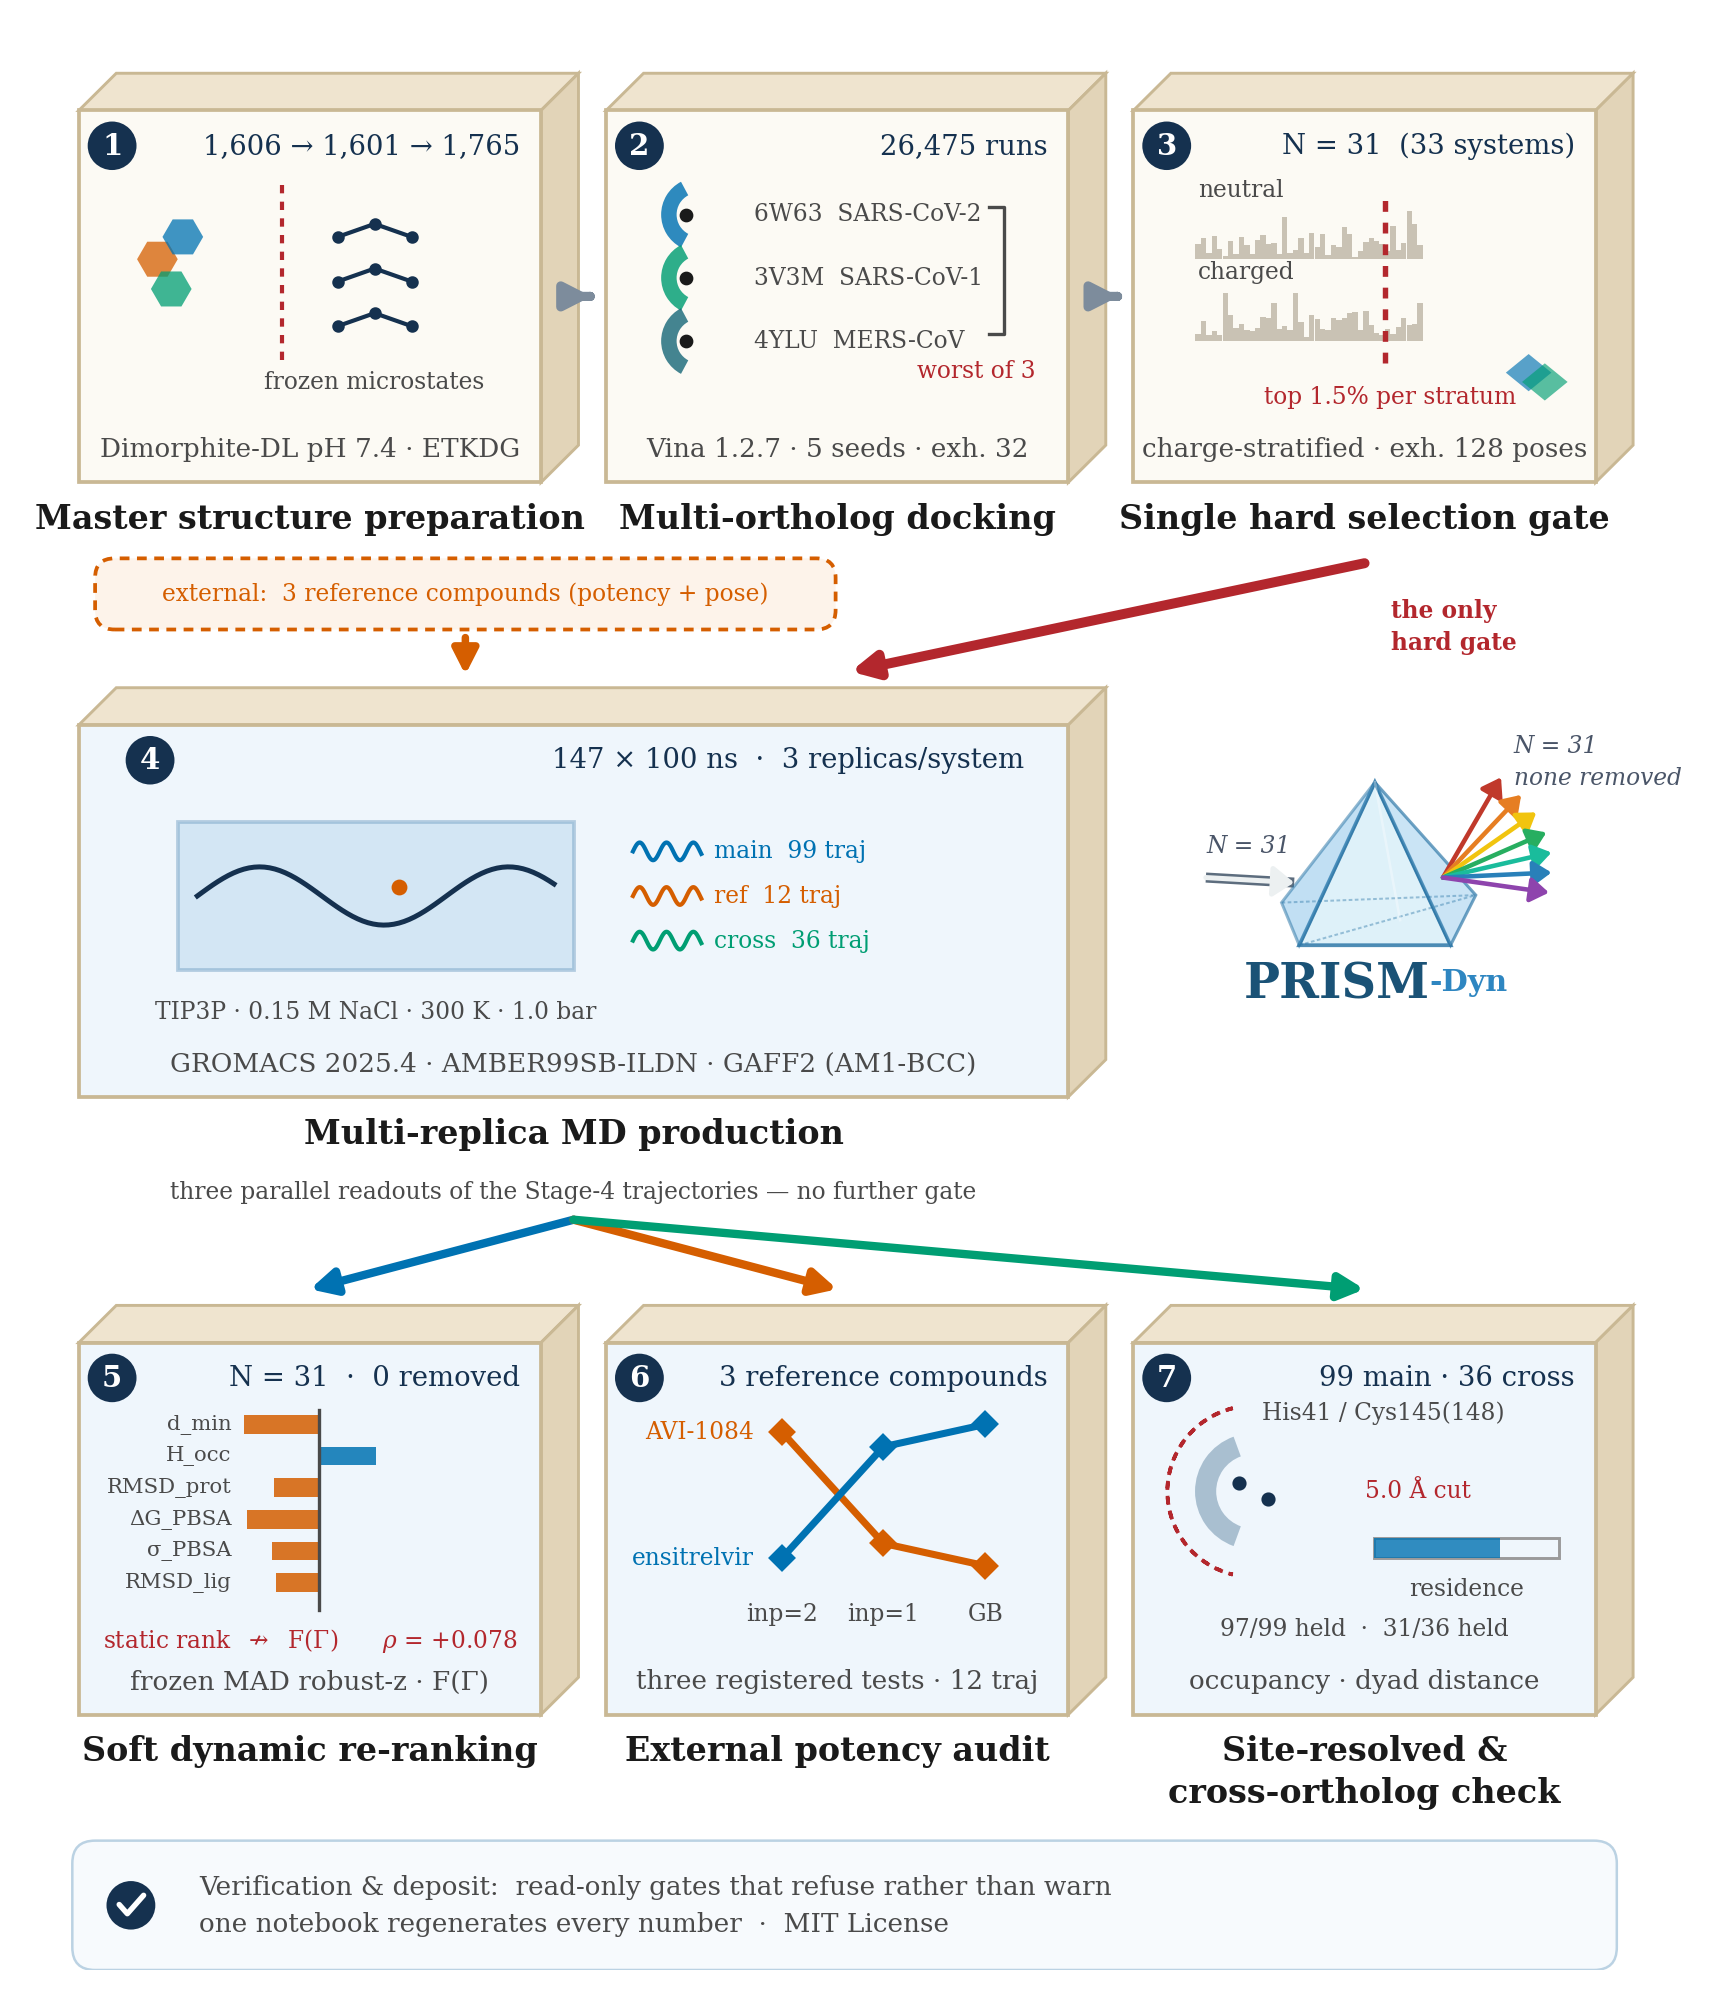

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_2.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_2.pdf`</sub>

In [18]:
# 并入自 cell_figure2.py（2026-11-20）
# ============================================================
# Figure 2 · 计算执行路线图（七卡）                              （§2）
# ============================================================
# 与 Figure 1 分工：Figure 1 答「测什么」（概念设计），本图答「怎么算」
# （软件版本、力场、模拟条件、规模）。二者互补，不重复。
#
# 卡面每一个数字都由存档现算，无一键入 —— 与 §6.1「reads only the deposited
# derived data」一致。取数在 _fig1_data.load()，与 Figure 1 共用同一个 loader，
# 故相邻两图在结构上不可能相左。
#
# ⚠ 整幅包在函数里，其局部一个也不外泄 —— 与单元 16 同例，
#   那里的注记写明此法是 2026-11-01 一次真故障换来的。
def _figure_workflow():
    from matplotlib.patches import Polygon, Rectangle, Circle, Wedge, FancyBboxPatch
    D    = _FIG_DATA      # 上游一次载入，与 Figure 1 共用
    SANS = False          # 全套衬线，与 plt.rcParams 的 font.family 一致
    NAVY,INK,INK2,MUTED="#15314f","#1a1a1a","#4a4a4a","#9a9a9a"
    CRIM,ORG,BLU,GRN,TEAL="#b3272d","#D55E00","#0072B2","#009E73","#1b6a7a"
    WARM=dict(face="#FCFAF4",top="#EFE4CF",side="#E2D4B8",edge="#C9B894")
    # PRISM-Gen 七张卡用的是同一套暖棕倒角，冷暖只体现在卡面。此处照办：
    # 倒角统一取暖色，卡面仍冷（1–3 暖＝MD 之前，4–7 冷＝MD 及其评估），语义不丢而整幅更齐。
    COOL=dict(face="#EFF6FC",top="#EFE4CF",side="#E2D4B8",edge="#C9B894")
    FS_T,FS_S,FS_C,FS_I=8.0,6.3,6.6,5.6

    # ── 取数：卡面每一个数字皆自存档现算 ──────────────────────────────
    # 第一个非 flag 参数为存档根；第二个为 tables_from_run.json。
    # 并入 make_tablefig_V3.ipynb 后，这几张表直接取笔记本内存中的对象，不再读 JSON。
    fig,ax=plt.subplots(figsize=(7.0,8.4)); ax.set_xlim(0,100); ax.set_ylim(0,120); ax.axis("off")
    CW,CH,BV=28.4,23.0,2.3
    CW4=CW*2+4.0
    COL=[3.0,35.4,67.8]; ROW=[92.0,54.0,15.8]
    _W={}; BADGE=[]      # BADGE：徽标圆，字压其上是本意，校验时放行

    def _box(x,y,w,h,pal):
        ax.add_patch(Polygon([(x,y+h),(x+BV,y+h+BV),(x+w+BV,y+h+BV),(x+w,y+h)],
                     fc=pal["top"],ec=pal["edge"],lw=0.7,zorder=2))
        ax.add_patch(Polygon([(x+w,y),(x+w+BV,y+BV),(x+w+BV,y+h+BV),(x+w,y+h)],
                     fc=pal["side"],ec=pal["edge"],lw=0.7,zorder=2))
        ax.add_patch(Rectangle((x,y),w,h,fc=pal["face"],ec=pal["edge"],lw=0.9,zorder=3))
    def card(i,j,pal):
        x,y=COL[i],ROW[j]; _box(x,y,CW,CH,pal); _W[(x,y)]=CW; return x,y
    def card4():
        x,y=COL[0],ROW[1]; _box(x,y,CW4,CH,COOL); _W[(x,y)]=CW4; return x,y
    def P(x,y,u,v,w=None): return x+u*(w or _W.get((x,y),CW)), y+v*CH
    def deco(x,y,n,count,sub,title):
        w=_W.get((x,y),CW)
        _c=Circle((x+0.072*w,y+0.905*CH),1.5,fc=NAVY,ec="none",zorder=8)
        ax.add_patch(_c); BADGE.append(_c)
        ax.text(x+0.072*w,y+0.905*CH,str(n),ha="center",va="center",fontsize=7.0,color="white",
                weight="bold",zorder=9)
        ax.text(x+0.955*w,y+0.905*CH,count,ha="right",va="center",fontsize=FS_C,color=NAVY,zorder=8)
        ax.text(x+0.5*w,y+0.055*CH,sub,ha="center",va="bottom",fontsize=FS_S,color=INK2,zorder=8,
                linespacing=1.5)
        ax.text(x+0.5*w,y-0.055*CH,title,ha="center",va="top",fontsize=FS_T,color=INK,
                weight="bold",zorder=8,linespacing=1.35)
    def arrow(x0,y0,x1,y1,c="#7d8c9c",lw=2.2):
        ax.annotate("",(x1,y1),(x0,y0),zorder=6,
            arrowprops=dict(arrowstyle="-|>,head_width=0.28,head_length=0.55",color=c,lw=lw,
                            shrinkA=0,shrinkB=0))

    # 1 · 结构准备
    x,y=card(0,0,WARM)
    for dx,dy,c in [(0,0.04,ORG),(0.055,0.10,BLU),(0.03,-0.04,GRN)]:
        a=np.linspace(0,2*np.pi,7); px,py=P(x,y,0.17+dx,0.56+dy)
        ax.add_patch(Polygon(np.c_[px+1.25*np.cos(a),py+1.25*np.sin(a)],fc=c,alpha=0.75,ec="none",zorder=5))
    ax.plot([P(x,y,0.44,0)[0]]*2,[P(x,y,0,0.33)[1],P(x,y,0,0.80)[1]],ls=(0,(2,2)),color=CRIM,lw=1.0,zorder=5)
    for k,v in enumerate([0.66,0.54,0.42]):
        xs=[P(x,y,0.56,0)[0],P(x,y,0.64,0)[0],P(x,y,0.72,0)[0]]
        ys=[P(x,y,0,v)[1],P(x,y,0,v+0.035)[1],P(x,y,0,v)[1]]
        ax.plot(xs,ys,color=NAVY,lw=1.0,zorder=5); ax.plot(xs,ys,"o",ms=2.0,color=NAVY,zorder=6)
    ax.text(*P(x,y,0.64,0.30),"frozen microstates",ha="center",va="top",fontsize=FS_I,color=INK2,zorder=6)
    deco(x,y,1,"{:,} \u2192 {:,} \u2192 {:,}".format(D["scope"],D["parents"],D["micro"]),"Dimorphite-DL pH 7.4 \u00b7 ETKDG","Master structure preparation")

    # 2 · 三靶点对接
    x,y=card(1,0,WARM)
    for k,(lab,c) in enumerate([("6W63  SARS-CoV-2",BLU),("3V3M  SARS-CoV-1",GRN),("4YLU  MERS-CoV",TEAL)]):
        cx,cy=P(x,y,0.20,0.72-k*0.17)
        ax.add_patch(Wedge((cx,cy),2.3,118,242,width=0.95,fc=c,ec="none",alpha=0.82,zorder=5))
        ax.plot([cx-0.8],[cy],"o",ms=2.3,color=INK,zorder=6)
        ax.text(cx+3.4,cy,lab,ha="left",va="center",fontsize=FS_I,color=INK2,zorder=6)
    bx=P(x,y,0.86,0)[0]
    ax.plot([bx-0.9,bx,bx,bx-0.9],[P(x,y,0,0.74)[1],P(x,y,0,0.74)[1],P(x,y,0,0.40)[1],P(x,y,0,0.40)[1]],
            color=INK2,lw=0.8,zorder=5)
    ax.text(*P(x,y,0.80,0.33),"worst of 3",ha="center",va="top",fontsize=FS_I,color=CRIM,zorder=6)
    deco(x,y,2,"{:,} runs".format(D["runs"]),"Vina 1.2.7 · 5 seeds · exh. 32","Multi-ortholog docking")

    # 3 · 唯一硬门控
    x,y=card(2,0,WARM)
    rs=np.random.RandomState(4)
    for k,(lab,v) in enumerate([("neutral",0.60),("charged",0.38)]):
        h=rs.gamma(2.2,1.0,42); h=h/h.max()
        xs=np.linspace(P(x,y,0.14,0)[0],P(x,y,0.62,0)[0],42)
        ax.bar(xs,h*3.0,width=0.33,bottom=P(x,y,0,v)[1],color="#c9c2b4",ec="none",zorder=5)
        ax.text(*P(x,y,0.14,v+0.155),lab,ha="left",va="bottom",fontsize=FS_I,color=INK2,zorder=6)
    cx=P(x,y,0.545,0)[0]
    ax.plot([cx,cx],[P(x,y,0,0.32)[1],P(x,y,0,0.76)[1]],ls=(0,(2,2)),color=CRIM,lw=1.3,zorder=6)
    ax.text(*P(x,y,0.555,0.26),"top 1.5% per stratum",ha="center",va="top",fontsize=FS_I,
            color=CRIM,zorder=6,linespacing=1.4)
    # 原置于 (0.74,0.28)/(0.775,0.255)，两枚菱形压住 "top 1.5% per stratum" 的尾字。
    # 今右移出文字之外；具体间距在末尾由"文字 × patch"校验器按实际路径把关，不靠目测。
    _DIA=[]
    for k,(du,dv) in enumerate([(0,0),(0.035,-0.025)]):
        cx2,cy2=P(x,y,0.855+du,0.295+dv)
        _d=Polygon([(cx2-1.4,cy2),(cx2,cy2+1.15),(cx2+1.4,cy2),(cx2,cy2-1.15)],
                   fc=(BLU if k==0 else GRN),alpha=0.65,ec="none",zorder=6)
        ax.add_patch(_d); _DIA.append(_d)
    deco(x,y,3,"N = {}  ({} systems)".format(D["cands31"],D["sys_main"]),"charge-stratified \u00b7 exh. 128 poses","Single hard selection gate")

    # 4 · 多副本 MD（第二行最右）
    x,y=card4()
    bx0,by0=P(x,y,0.10,0.34); bw,bh=CW4*0.40,CH*0.40
    ax.add_patch(Rectangle((bx0,by0),bw,bh,fc="#bcd9ef",alpha=0.55,ec="#7fa9c9",lw=0.9,zorder=5))
    tt=np.linspace(0,1,70)
    ax.plot(bx0+1.2+tt*(bw-2.4),by0+bh*0.5+1.8*np.sin(tt*9),color=NAVY,lw=1.2,zorder=6)
    ax.plot([bx0+bw*0.56],[by0+bh*0.56],"o",ms=2.8,color=ORG,zorder=7)
    for k,(lab,c,v) in enumerate([("main  %d traj"%D["n_main"],BLU,0.66),
                                  ("ref  %d traj"%D["n_ref"],ORG,0.54),
                                  ("cross  %d traj"%D["n_cross"],GRN,0.42)]):
        sx,sy=P(x,y,0.56,v)
        ax.plot(sx+tt*4.2,sy+0.55*np.sin(tt*16),color=c,lw=1.0,zorder=6)
        ax.text(sx+5.0,sy,lab,ha="left",va="center",fontsize=FS_I,color=c,zorder=6)
    ax.text(*P(x,y,0.30,0.26),"TIP3P · 0.15 M NaCl · 300 K · 1.0 bar",ha="center",va="top",
            fontsize=FS_I,color=INK2,zorder=6)
    # 蛋白力场与配体力场并置：读者查力场只看这一行。三值皆出自 §Methods
    # （"ACPYPE 2023.10.27 under GAFF2 with AM1-BCC partial charges"；300 K；1.0 bar）。
    # 分析窗口（最后 50 ns）不写在本卡：那是卡 5/6/7 之事，且稿中明言同一 50 ns 有两套取样
    # （结构与占据 100 ps / 501 帧；端点 250 ps / 200 帧），一行写不下而不失真。
    deco(x,y,4,"{} \u00d7 100 ns  \u00b7  {} replicas/system".format(D["n_traj"],D["reps"]),
         "GROMACS 2025.4 \u00b7 AMBER99SB-ILDN \u00b7 GAFF2 (AM1-BCC)",
         "Multi-replica MD production")

    # 5 · 软重排
    x,y=card(0,2,COOL)
    _LBL={"d_min":"d_min","H_occ":"H_occ","RMSD_prot":"RMSD_prot",
          "dG_PBSA":"\u0394G_PBSA","sigma_PBSA":"\u03c3_PBSA","RMSD_lig":"RMSD_lig"}
    AX=[_LBL[a] for a,_ in D["W"]]; VV=[w for _,w in D["W"]]
    zx=P(x,y,0.52,0)[0]
    for k,(a,v) in enumerate(zip(AX,VV)):
        yy=P(x,y,0,0.78-k*0.085)[1]
        ax.barh(yy,v*2.3,height=CH*0.050,left=zx,color=(BLU if v>0 else ORG),alpha=0.85,ec="none",zorder=5)
        ax.text(zx-5.4,yy,a,ha="right",va="center",fontsize=FS_I-0.5,color=INK2,zorder=6)
    ax.plot([zx,zx],[P(x,y,0,0.28)[1],P(x,y,0,0.82)[1]],color=INK2,lw=0.8,zorder=6)
    # ↛（U+21AE）Liberation Sans 无此字，换 serif 时又有；故一律走 mathtext，由数学字族出字。
    ax.text(*P(x,y,0.5,0.20),"static rank  $\\nrightarrow$  F($\\Gamma$)      $\\rho$ = %+.3f"%D["rho"],
            ha="center",va="center",fontsize=FS_I,color=CRIM,zorder=7)
    deco(x,y,5,"N = %d  ·  0 removed"%D["cands31"],"frozen MAD robust-z \u00b7 F(\u0393)",
         "Soft dynamic re-ranking")

    # 6 · 外部效价审计
    x,y=card(1,2,COOL)
    xs=[P(x,y,u,0)[0] for u in (0.38,0.60,0.82)]
    A=[P(x,y,0,v)[1] for v in (0.76,0.46,0.40)]; E=[P(x,y,0,v)[1] for v in (0.42,0.72,0.78)]
    ax.plot(xs,A,"-D",color=ORG,lw=1.7,ms=3.6,zorder=6); ax.plot(xs,E,"-D",color=BLU,lw=1.7,ms=3.6,zorder=6)
    ax.text(*P(x,y,0.32,0.76),"AVI-1084",ha="right",va="center",fontsize=FS_I,color=ORG,
            zorder=6,linespacing=1.4)
    ax.text(*P(x,y,0.32,0.42),"ensitrelvir",ha="right",va="center",fontsize=FS_I,
            color=BLU,zorder=6,linespacing=1.4)
    for u,lab in ((0.38,"inp=2"),(0.60,"inp=1"),(0.82,"GB")):
        ax.text(*P(x,y,u,0.30),lab,ha="center",va="top",fontsize=FS_I,color=INK2,zorder=6)
    deco(x,y,6,"3 reference compounds","three registered tests · %d traj"%D["n_ref"],"External potency audit")

    # 7 · 位点分辨与跨臂（第三行最左）
    x,y=card(2,2,COOL)
    cx,cy=P(x,y,0.26,0.60)
    ax.add_patch(Wedge((cx,cy),3.6,110,250,width=1.3,fc="#9db6c9",ec="none",alpha=0.85,zorder=5))
    ax.add_patch(Wedge((cx,cy),5.3,104,256,width=0.0,fc="none",ec=CRIM,lw=0.9,ls=(0,(2,2)),zorder=6))
    ax.plot([cx-0.9,cx+0.9],[cy+0.5,cy-0.5],"o",ms=2.4,color=NAVY,zorder=7)
    ax.text(*P(x,y,0.54,0.78),"His41 / Cys145(148)",ha="center",va="bottom",
            fontsize=FS_I,color=INK2,zorder=6)
    ax.text(*P(x,y,0.50,0.60),"5.0 Å cut",ha="left",va="center",fontsize=FS_I,color=CRIM,zorder=6)
    rx,ry=P(x,y,0.52,0.42); rw=CW*0.40
    ax.add_patch(Rectangle((rx,ry),rw,CH*0.055,fc="none",ec=MUTED,lw=0.7,zorder=5))
    ax.add_patch(Rectangle((rx,ry),rw*0.68,CH*0.055,fc=BLU,ec="none",alpha=0.8,zorder=6))
    ax.text(rx+rw/2,ry-1.2,"residence",ha="center",va="top",fontsize=FS_I,color=INK2,zorder=6)


    ax.text(*P(x,y,0.50,0.26),"%d/%d held  ·  %d/%d held"%(D["main_held"],D["main_n"],D["cross_held"],D["cross_n"]),ha="center",va="top",fontsize=FS_I,
            color=INK2,zorder=6)
    deco(x,y,7,"{} main · {} cross".format(D["n_main"],D["n_cross"]),"occupancy \u00b7 dyad distance","Site-resolved &\ncross-ortholog check")


    # 外部引入：三个参照物不出自候选池。前一版只画一条竖箭头、起点落在空白里，
    # 而该起点恰在卡 1 标题之下、直指卡 4，读来像"卡 1 → 卡 4 的旁路"。今给它一个
    # 看得见的出处：虚线小框 = 流程之外，实心卡 = 流程之内；箭头自框的下沿出发。
    # 2026-11-20：框高自 3.2 放到 4.4 单位。那道余量断言取四边间隙之**最小值**，
    # 而卡死的一直是**上下**而非左右（故先前只放宽右沿，3.41 pt 丝毫未动）。
    # 此处上下各放 0.6：框所处的 79.3–92 单位之间本就空着，两头都不挨着谁。
    _py0,_py1=ROW[1]+CH+BV+3.6,ROW[1]+CH+BV+8.0          # 框的上下沿
    # 2026-11-20：右沿自 44.0 放宽到 46.5。原余量仅 3.4 pt，虽过阈（2.4 pt）却太薄：
    # 若集群上衬线字族的度量稍异，字宽一变就可能转负。放宽 2.5 单位不触碰任何数据，
    # 纯属版面余量，且下方「文字×图元」校验器会把放宽后有无新碰撞一并验过。
    _px0,_px1=COL[0]+1.0,COL[0]+46.5                      # 框的左右沿
    ax.add_patch(FancyBboxPatch((_px0,_py0),_px1-_px0,_py1-_py0,
                 boxstyle="round,pad=0.0,rounding_size=1.2",fc="#FDF3EA",ec=ORG,lw=0.9,
                 ls=(0,(2.6,2.0)),zorder=4))
    # 文案仍用 "external:"：歧义本不在用词，而在箭头没有出处；虚线框一给，歧义即消。
    # 曾改作 "outside the pipeline:…"，字宽 43 单位而框宽 36，撑出框外，故退回。
    _pt=ax.text((_px0+_px1)/2,(_py0+_py1)/2,
            "external:  3 reference compounds (potency + pose)",
            ha="center",va="center",fontsize=FS_I,color=ORG,zorder=9)
    _ax=(_px0+_px1)/2
    arrow(_ax,_py0-0.5,_ax,ROW[1]+CH+BV+0.8,ORG,1.8)

    # ── 徽标（第二行最右）
    # 逐坐标照搬 PRISM_Gen_GA_v10.svg 的 <g id="prism_logo">（v9 与 v10 的该段完全相同，
    # 两版之别只在卡 4→卡 5 那一条箭头）。成稿徽标是**手写 SVG**，不是 matplotlib：
    # 笔记本里的 draw_optical_prism 是另一套更早的设计（平面三角），并非成稿所用。
    # 原作为**四面体**：正面 + 右面 + 左面，三面取色与透明度各异，另有两条虚线画出隐藏底棱。
    # 坐标系：SVG 画布 720×345、y 轴向下；本图 xlim 0–100 / ylim 0–120、y 轴向上。
    # _S() 只做这一次平移与缩放，顶点、配色、透明度、虚线样式一字未改。
    ex,ey=COL[2]+1.0,ROW[1]+2.0
    _SX,_SY,_SC=72.25,59.5,0.155
    def _S(x,y): return (_SX+(x-78.0)*_SC, _SY+(290.0-y)*_SC)
    _U=_SC*3.906                      # 1 SVG 单位 = 多少 pt（线宽、虚线、字号皆据此折算）

    ax.add_patch(Polygon([_S(145,200),_S(115,265),_S(175,265)],closed=True,
                 facecolor="#D6EEF8",edgecolor="#2471A3",lw=1.5*_U,alpha=0.80,zorder=8))
    ax.add_patch(Polygon([_S(145,200),_S(175,265),_S(185,245)],closed=True,
                 facecolor="#AED6F1",edgecolor="#2471A3",lw=1.2*_U,alpha=0.65,zorder=8))
    ax.add_patch(Polygon([_S(145,200),_S(115,265),_S(108,248)],closed=True,
                 facecolor="#85C1E9",edgecolor="#2471A3",lw=1.2*_U,alpha=0.50,zorder=8))
    for _a,_b in (((115,265),(185,245)),((108,248),(185,245))):      # 隐藏底棱，虚线
        _p,_q=_S(*_a),_S(*_b)
        ax.plot([_p[0],_q[0]],[_p[1],_q[1]],color="#2471A3",lw=0.8*_U,alpha=0.4,
                ls=(0,(3*_U,2*_U)),zorder=9)
    _p,_q=_S(145,200),_S(155,255)                                    # 内部白色高光棱
    ax.plot([_p[0],_q[0]],[_p[1],_q[1]],color="white",lw=1.0*_U,alpha=0.35,zorder=9)

    # 入射白光束：灰在下、白在上，白色箭头（原作 marker 填 #ECF0F1）
    _b0,_b1=_S(78,238),_S(113,240)
    ax.plot([_b0[0],_b1[0]],[_b0[1],_b1[1]],color="#5D6D7E",lw=4.0*_U,zorder=7,
            solid_capstyle="butt")
    ax.annotate("",xy=_b1,xytext=_b0,zorder=8,
        arrowprops=dict(arrowstyle="-|>,head_width=0.29,head_length=0.40",
                        color="#ECF0F1",lw=2.0*_U,mutation_scale=17.5*_U,shrinkA=0,shrinkB=0))

    # 出射七线：起点与七个终点全部照抄，角度 +60.1° 至 −8.1°，非对称扇形
    RAY=[("#C0392B",195,198),("#E67E22",203,205),("#F1C40F",209,212),("#27AE60",213,220),
         ("#1ABC9C",215,228),("#2980B9",215,236),("#8E44AD",214,244)]
    _O=_S(172,238)
    for _c,_x,_y in RAY:
        ax.annotate("",xy=_S(_x,_y),xytext=_O,zorder=9,
            arrowprops=dict(arrowstyle="-|>,head_width=0.27,head_length=0.40",
                            color=_c,lw=1.8*_U,mutation_scale=15.0*_U,shrinkA=0,shrinkB=0))

    # 标注：原作 font-size=6，折到本图只有 2.9 pt，低于 ACS 的 4.5 pt 下限，
    # 故字号用本图自己的 FS_I（置于 7.0 in 后约 6.3 pt），只沿用原作的斜体与 #4A5568。
    _t=_S(95,230);  ax.text(_t[0],_t[1],"N = %d"%D["cands31"],ha="center",va="bottom",fontsize=FS_I,
                            color="#4A5568",style="italic",zorder=10)
    _t=_S(200,192); ax.text(_t[0],_t[1],"N = %d\nnone removed"%D["cands31"],ha="left",va="center",
                            fontsize=FS_I,color="#4A5568",style="italic",zorder=10,linespacing=1.5)

    # 字标：原作 PRISM 19 pt「Arial Black」、-Gen 12 pt，基线锚定且 -Gen 高 3 个单位。
    # 本机无 Arial Black，取本图字族的粗体；字号、配色、位置与高差皆按原作折算。
    _t=_S(130,286); _tp=ax.text(_t[0],_t[1],"PRISM",ha="center",va="baseline",
                            fontsize=19*_U,fontweight="bold",color="#1A5276",zorder=10)
    fig.canvas.draw()
    _xd = ax.transData.inverted().transform(
        _tp.get_window_extent(fig.canvas.get_renderer()))[1][0]
    _t=_S(170,283); ax.text(_xd,_t[1],"-Dyn",ha="left",va="baseline",
                            fontsize=12*_U,fontweight="bold",color="#2E86C1",zorder=10)

    # ── 卡 8 压成页脚细条（口径统一为全树 665 / 52.51 MB）
    ax.add_patch(FancyBboxPatch((COL[0],0.4),97.1-COL[0],7.2,
                 boxstyle="round,pad=0.4,rounding_size=1.4",fc="#F7FAFD",ec="#BBD2E3",lw=0.6,zorder=3))
    ax.add_patch(Circle((COL[0]+3.2,4.0),1.5,fc=NAVY,ec="none",zorder=8))
    _cx,_cy=COL[0]+3.2,4.0
    ax.plot([_cx-0.72,_cx-0.22,_cx+0.78],[_cy+0.05,_cy-0.52,_cy+0.62],color="white",lw=1.3,
            zorder=9,solid_capstyle="round")
    # \u5b58\u6863\u4f53\u91cf\u53d6\u81ea\u5b58\u6863\u526f\u672c\u81ea\u5df1\u7684\u6839\uff08\u975e ROOT \u2014\u2014 \u90a3\u662f lang2\uff0c\u542b\u5168\u90e8\u8f68\u8ff9\uff09\u3002
    # \u526f\u672c\u4e0d\u5728\u76d8\u4e0a\u65f6\u53d6\u6570\u5c42\u7f6e None\uff0c\u6b64\u5904\u4fbf\u7701\u53bb\u8be5\u53e5\uff0c\u800c\u4e0d\u662f\u5370\u4e00\u4e2a\u9519\u6570\u3002
    # 2026-11-22 裁定：克隆文件数与十进制 MB 只出于 §6.1，图上不再并载。
    # 其一为第 3 条「数字只有一个来源」；其二，此处测的是跑笔记本当时盘上的
    # 那份克隆，而真值要到存档重建并经全新克隆校验之后才定得下来，必不同步；
    # 其三，体积是在一个含 Figure_2.png 自身的树上测的，改图即改数，不收敛。
    # 置空走的是本单元原有的「盘上无克隆」分支，版面与字串皆不另造。
    _dep_clause = ""
    ax.text(COL[0]+7.4,4.0,
            "Verification & deposit:  read-only gates that refuse rather than warn\n"
            "one notebook regenerates every number%s  \u00b7  MIT License" % _dep_clause,
            ha="left",va="center",fontsize=FS_S,color=INK2,zorder=9,linespacing=1.6)

    # ── 连接：1→2→3 顺序；经唯一硬门控落到 4；再由 4 分出三支并行
    arrow(COL[0]+CW+BV+0.7,ROW[0]+CH/2,COL[1]-0.9,ROW[0]+CH/2)
    arrow(COL[1]+CW+BV+0.7,ROW[0]+CH/2,COL[2]-0.9,ROW[0]+CH/2)
    arrow(COL[2]+CW/2,ROW[0]-5.0,COL[0]+CW4*0.78,ROW[1]+CH+BV+1.0,CRIM,2.4)
    ax.text(COL[2]+CW/2+1.6,ROW[0]-7.2,"the only\nhard gate",ha="left",va="top",fontsize=FS_I,
            color=CRIM,weight="bold",zorder=9,linespacing=1.4)
    hub=(COL[0]+CW4*0.5,ROW[1]-7.6)
    for tgt,c in ((COL[0]+CW/2,BLU),(COL[1]+CW/2,ORG),(COL[2]+CW/2,GRN)):
        arrow(hub[0],hub[1],tgt,ROW[2]+CH+BV+1.0,c,2.0)
    # 原作"three parallel arms on the same 147 trajectories"。稿中"arm"专指
    # main（33 体系 99 条）/ reference（4 体系 12 条）/ cross（12 体系 36 条）三臂，
    # 而三支箭头所指是卡 5/6/7 三项**评估**，并非三臂：卡 5 只用主臂 99，卡 6 只用参考臂 12，
    # 卡 7 跨主臂与跨臂（99 + 36）。故"三臂"与"三箭头"并非一一对应，且"on the same 147"
    # 易读成"每一支都用满 147"。改述为"对第 4 阶段轨迹的三项并行读出"，要旨（此后再无门控）不变。
    ax.text(hub[0],hub[1]+1.0,"three parallel readouts of the Stage-4 trajectories \u2014 no further gate",
            ha="center",va="bottom",fontsize=FS_I,color=INK2,zorder=9)

    fig.canvas.draw(); _rr0=fig.canvas.get_renderer()
    _tb=_pt.get_window_extent(renderer=_rr0)
    _pb=[q for q in ax.patches if isinstance(q,FancyBboxPatch)][0].get_window_extent(renderer=_rr0)
    _m=min(_tb.x0-_pb.x0,_pb.x1-_tb.x1,_tb.y0-_pb.y0,_pb.y1-_tb.y1)
    # 2026-11-20：原阈值写作「> 6.0 px」。像素随 figure.dpi 变，而本地试跑架当时
    # 设了 dpi=150、笔记本不设（默认 100），故同一版面在本地量得 ~6.9 px、在集群上
    # 只有 4.6 px，断言遂在集群上误报。改按**点**计，与 dpi 无关。
    _m_pt = _m * 72.0 / fig.dpi
    assert _m_pt > 2.4, "虚线框内文字余量仅 %.2f pt（%.1f px @ %g dpi），撑框了" % (
        _m_pt, _m, fig.dpi)
    print("虚线框内余量 %.2f pt（%.1f px @ %g dpi）✓" % (_m_pt, _m, fig.dpi))
    # ── 落盘前自检：文字互压、文字压图元（按实际路径，非外接框）──────────
    # 这道闸是 2026-11-20 换来的：卡 ③ 的构象图标曾压住 "stratum" 一词，
    # 而当时的校验器只比文字与文字，故放了过去。现对每个图元按其 path 比对。
    import matplotlib.patches as _mp, matplotlib.text as _mt
    fig.canvas.draw(); _rr = fig.canvas.get_renderer()
    _T = [t for t in ax.texts if t.get_text().strip()]
    def _bb(o): return o.get_window_extent(renderer=_rr)
    _pad_px = 0.5 * fig.dpi / 72.0        # 原为固定 0.5 px；折成 pt 后与 dpi 无关
    def _hit(a, b, pad=None):
        pad = _pad_px if pad is None else pad
        return not (a.x1+pad < b.x0 or b.x1+pad < a.x0 or a.y1+pad < b.y0 or b.y1+pad < a.y0)
    _WORD = {"PRISM", "-Dyn"}
    _bad = [(x.get_text()[:18], y.get_text()[:18]) for i, x in enumerate(_T) for y in _T[i+1:]
            if _hit(_bb(x), _bb(y)) and not {x.get_text(), y.get_text()} <= _WORD]
    assert not _bad, "Figure 2：文字互压 %s" % _bad[:4]
    _skip = set(map(id, BADGE))
    _bad2 = []
    for _t in _T:
        _tb = _bb(_t)
        for _q in ax.patches:
            if id(_q) in _skip: continue
            if isinstance(_q, _mp.Rectangle) and _q.get_width() > 20: continue   # 卡面
            if isinstance(_q, _mp.FancyBboxPatch): continue                      # 已单独验
            if _q.get_path().transformed(_q.get_transform()).intersects_bbox(_tb, filled=True):
                _bad2.append((_t.get_text()[:22], type(_q).__name__))
    assert not _bad2, "Figure 2：文字压图元 %s" % _bad2[:4]

    return fig

_f2 = _figure_workflow()
save_fig(_f2, 2, "computational execution workflow: seven stages, one gate, three arms",
         caption=(
             "Computational execution of the study. Stage 1 prepares 1,765 docked microstates "
             "\u2014 single stereoisomeric forms \u2014 of 1,601 parent molecules (\u00a7S-3); the scope "
             "record lists 1,606 parents, five of which are not represented by any docked "
             "microstate. Stage 2 docks every microstate against three M^pro orthologs under "
             "the worst-of-three rule. Stage 3 is the only hard gate in the study. Stages 4 to 7 "
             "follow that gate and remove nothing: the 147 trajectories are read three ways in "
             "parallel, and the cohort is re-ordered rather than filtered. Software versions, "
             "force fields and simulation conditions appear on the cards; Figure 1 gives the "
             "study design that these stages execute. Every number shown is computed from the "
             "deposited data by the notebook that draws the figure (\u00a76.1)."))


  [主臂 ΔG 汇总（33 体系）] results/phase3_dG_aggregated_SOLV_V3.csv
  → Figure_6  (.png 300 dpi + .pdf)  inter-replica dispersion and the adjudication of ambiguous poses
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_6.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_6.pdf   （矢量，ACS 投稿以此为佳）


**Figure 6.** The precision limit of a three-replica endpoint. (A) Mean ΔG_PBSA with ±1 σ for each of the 31 primary candidates, ordered on that axis alone; the open points show the three individual replicas of one system, so the spread of a single candidate can be compared against the spread of the cohort. (B) The two systems whose docked poses were ambiguous, with each pose's replicas shown separately; the adjudication of §3.4.8 follows from the separation shown here, not from the means alone. (C) Per-candidate dispersion against the pairwise resolution of the design, 2 SE = 2.70 kcal/mol (§3.4.1), which is twice the median inter-replica dispersion divided by √3: 11 of the 31 candidates disperse more widely than two systems must differ before three replicas can separate them. Every value is computed from the deposited per-system endpoint table by the notebook that draws the figure (§6.1).

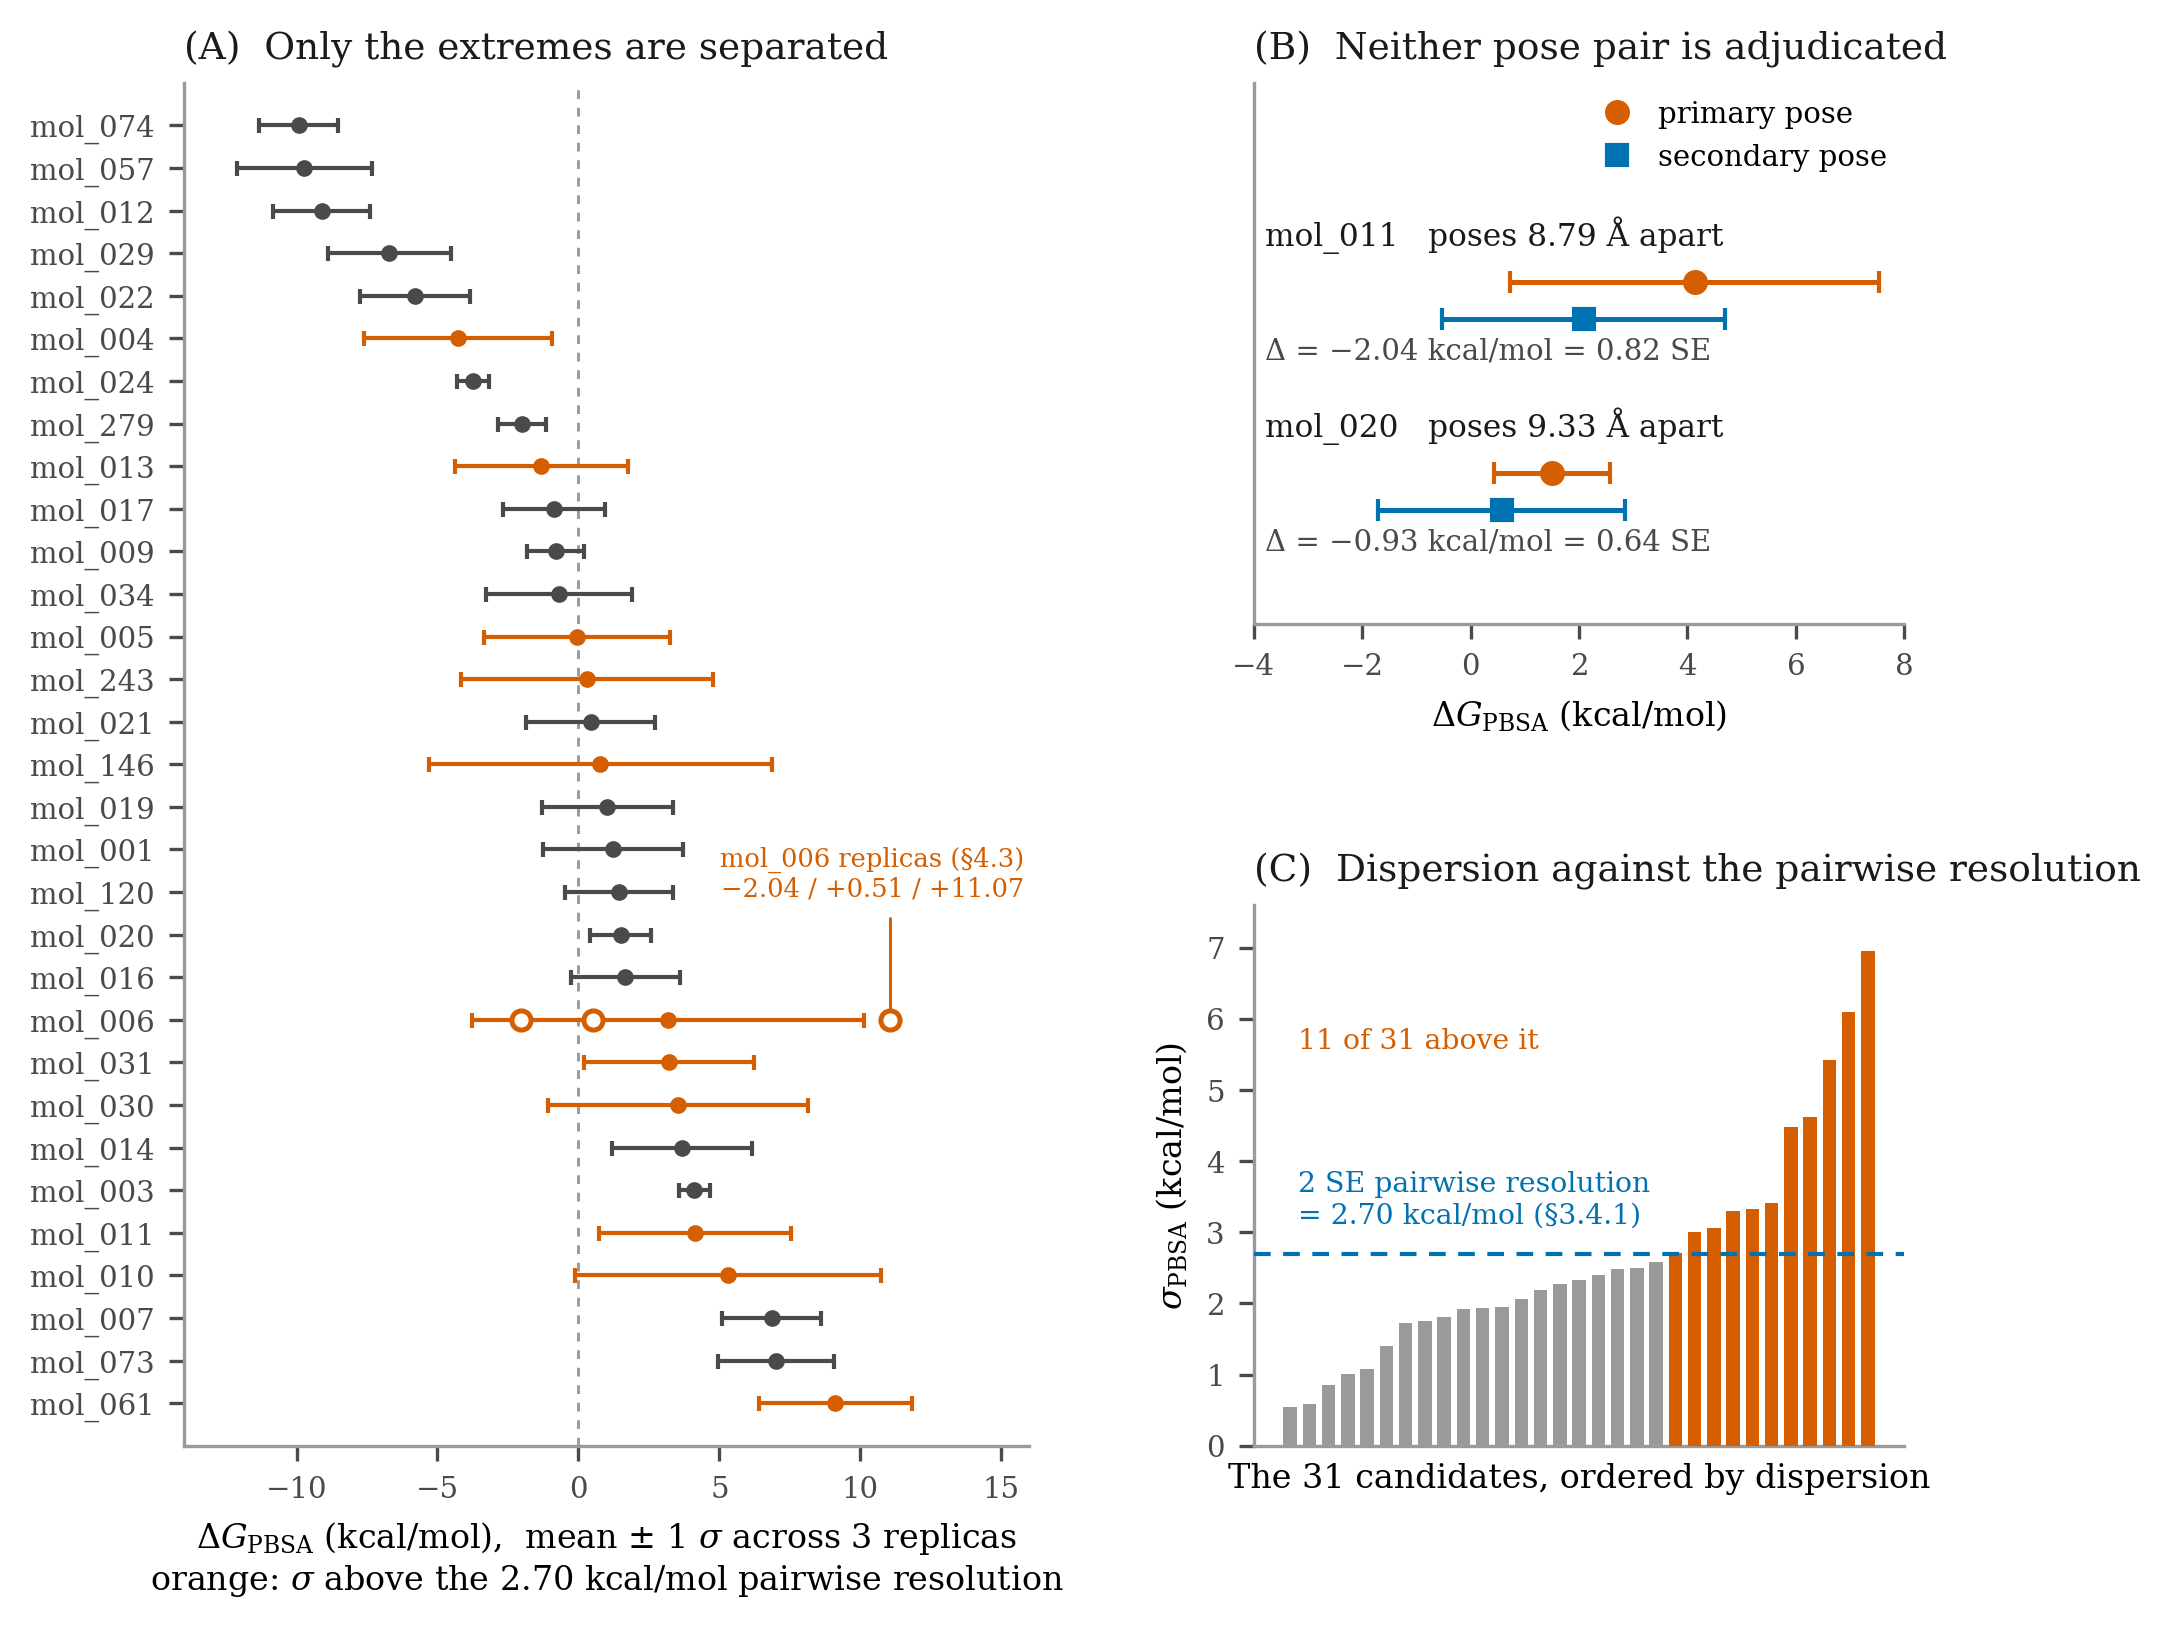

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_6.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_6.pdf`</sub>

In [19]:
# 并入自 cell_figure6.py（2026-11-20）
# ==========================================================
# Figure 6 · （由 mock_cat.py 转录；路径改为 lang2 口径，取数一律走 resolve）
# ==========================================================
# ⚠ 整幅包在函数里，其局部一个也不外泄。

def _figure_cat():
    import csv, io, math        # 笔记本单元 1 未 import 这三个
    _P_CAT = resolve("主臂 ΔG 汇总（33 体系）", ["results/phase3_dG_aggregated_SOLV_V3.csv"])
    INK,INK2,MUTED="#1a1a1a","#4a4a4a","#9a9a9a"; C1,C2="#0072B2","#D55E00"
    R=[r for r in csv.DictReader(io.open(_P_CAT,encoding='utf-8')) if r['mol_dir'].endswith('__primary')]
    D=sorted([(r['mol_dir'].split('__')[0].replace('pool_mol_','mol_'),
               float(r['dG_PBSA_mean']),float(r['sigma_PBSA'])) for r in R],key=lambda z:z[1])
    import statistics as _st
    import os as _os
    _XH=16.0   # 右缘留白：mol_006 直标须离最近误差棒 >10 px（实测 16.5）
    RES=2.0*_st.median([d[2] for d in D])/math.sqrt(3.0)   # §3.4.1: 2 SE 成对分辨阈
    N=len(D); ys=np.arange(N)[::-1]

    fig=plt.figure(figsize=(7.4,5.9))
    gs=fig.add_gridspec(2,2,width_ratios=[1.30,1.0],height_ratios=[1.0,1.0],
                        wspace=0.30,hspace=0.52)
    a1=fig.add_subplot(gs[:,0]); a2=fig.add_subplot(gs[0,1]); a3=fig.add_subplot(gs[1,1])

    # ── (A) 毛毛虫
    a1.axvline(0,color=MUTED,lw=0.7,ls=(0,(3,3)),zorder=1)
    for k,(nm,m,s) in enumerate(D):
        c=C2 if s>RES else INK2
        a1.errorbar([m],[ys[k]],xerr=[s],fmt="o",ms=3.0,color=c,ecolor=c,
                    elinewidth=1.0,capsize=1.8,zorder=4)
    k6=[i for i,(n,_,_) in enumerate(D) if n=="mol_006"][0]
    a1.plot([-2.04,0.51,11.07],[ys[k6]]*3,marker="o",ls="none",ms=4.6,mfc="white",
            mec=C2,mew=1.2,zorder=6)
    a1.annotate("mol_006 replicas (§4.3)\n−2.04 / +0.51 / +11.07",
                (11.07,ys[k6]),xytext=(_XH-0.2,ys[k6]+2.9),fontsize=6.2,color=C2,ha="right",
                arrowprops=dict(arrowstyle="-",color=C2,lw=0.7,
                                connectionstyle="angle,angleA=0,angleB=90,rad=3"))
    a1.set_yticks(ys); a1.set_yticklabels([d[0] for d in D],fontsize=6.0)
    a1.set_ylim(-1.0,N); a1.set_xlim(-14,_XH)
    a1.set_xlabel("$\\Delta G_{\\mathrm{PBSA}}$ (kcal/mol),  mean $\\pm$ 1 $\\sigma$ across 3 replicas\norange: $\\sigma$ above the %.2f kcal/mol pairwise resolution"%RES,fontsize=8)
    a1.set_title("(A)  Only the extremes are separated",loc="left",color=INK,fontsize=9)

    # ── (B) Table S11：均值与 sigma 自档读，差值与 SE 现算；只有两构象间 RMSD 取自 Table S11
    ALL={r['mol_dir']:r for r in csv.DictReader(io.open(_P_CAT,encoding='utf-8'))}
    PRMSD={"mol_011":8.79,"mol_020":9.33}          # Table S11
    yb=np.array([1.45,0.0])
    for j,mm in enumerate(("011","020")):
        P=ALL["pool_mol_%s__6W63__primary"%mm]; S=ALL["pool_mol_%s__6W63__secondary"%mm]
        p_,sp=float(P['dG_PBSA_mean']),float(P['sigma_PBSA'])
        s_,ss=float(S['dG_PBSA_mean']),float(S['sigma_PBSA'])
        diff=s_-p_; se=math.sqrt((sp*sp+ss*ss)/3.0); nm="mol_"+mm
        a2.errorbar([p_],[yb[j]+0.14],xerr=[sp],fmt="o",ms=5,color=C2,ecolor=C2,
                    elinewidth=1.2,capsize=2.6,zorder=5)
        a2.errorbar([s_],[yb[j]-0.14],xerr=[ss],fmt="s",ms=5,color=C1,ecolor=C1,
                    elinewidth=1.2,capsize=2.6,zorder=5)
        a2.annotate("%s   poses %.2f \u00c5 apart"%(nm,PRMSD[nm]),(-3.8,yb[j]+0.42),
                    fontsize=7.5,color=INK,ha="left")
        a2.annotate(("\u0394 = %+.2f kcal/mol = %.2f SE"%(diff,abs(diff)/se)).replace("-","\u2212"),
                    (-3.8,yb[j]-0.44),fontsize=7,color=INK2,ha="left")
    a2.plot([],[],"o",ms=5,color=C2,label="primary pose"); a2.plot([],[],"s",ms=5,color=C1,label="secondary pose")
    a2.legend(loc="upper right",frameon=False,fontsize=7,handletextpad=0.4,borderpad=0.1)
    a2.set_yticks([]); a2.set_ylim(-1.00,3.10); a2.set_xlim(-4,8)
    a2.set_xlabel("$\\Delta G_{\\mathrm{PBSA}}$ (kcal/mol)",fontsize=8)
    a2.set_title("(B)  Neither pose pair is adjudicated",loc="left",color=INK,fontsize=9)

    # ── (C) sigma 对阈
    S=sorted([d[2] for d in D]); over=[v for v in S if v>RES]
    a3.bar(np.arange(N),S,width=0.70,color=[C2 if v>RES else MUTED for v in S],zorder=3)
    a3.axhline(RES,color=C1,lw=1.0,ls=(0,(4,3)),zorder=4)
    a3.annotate("2 SE pairwise resolution\n= %.2f kcal/mol (§3.4.1)"%RES,(0.4,RES+0.35),
                fontsize=6.8,color=C1,ha="left",va="bottom")
    a3.annotate("%d of 31 above it"%len(over),(0.4,5.5),fontsize=6.8,color=C2,ha="left",va="bottom")
    a3.set_xticks([]); a3.set_ylim(0,7.6)
    a3.set_xlabel("The 31 candidates, ordered by dispersion",fontsize=8)
    a3.set_ylabel("$\\sigma_{\\mathrm{PBSA}}$ (kcal/mol)",fontsize=8)
    a3.set_title("(C)  Dispersion against the pairwise resolution",loc="left",color=INK,fontsize=9)

    for ax in (a1,a2,a3):
        for sp_ in ("top","right"): ax.spines[sp_].set_visible(False)
        ax.spines["left"].set_color(MUTED); ax.spines["bottom"].set_color(MUTED)
        ax.tick_params(colors=INK2,labelsize=7)
    return fig

_f6 = _figure_cat()
save_fig(_f6, 6, "inter-replica dispersion and the adjudication of ambiguous poses",
         caption=(
             "The precision limit of a three-replica endpoint. (A) Mean ΔG_PBSA with ±1 "
             "σ for each of the 31 primary candidates, ordered on that axis alone; the open points show "
             "the three individual replicas of one system, so the spread of a single candidate can be "
             "compared against the spread of the cohort. (B) The two systems whose docked poses were "
             "ambiguous, with each pose's replicas shown separately; the adjudication of §3.4.8 follows "
             "from the separation shown here, not from the means alone. (C) Per-candidate dispersion "
             "against the pairwise resolution of the design, 2 SE = 2.70 kcal/mol (§3.4.1), which is twice "
             "the median inter-replica dispersion divided by √3: 11 of the 31 candidates disperse more "
             "widely than two systems must differ before three replicas can separate them. Every value is "
             "computed from the deposited per-system endpoint table by the notebook that draws the figure "
             "(§6.1)."))


  [F(Γ) 排序] results/step8d_compass_ranking_SOLV_V3.csv
  [参考臂 PB 逐副本 TOTAL] Scoring/solv_alt_2026-11-16/ref_panel_PB_per_replica_TOTAL.csv
  [参考臂 PB inp=1 逐副本] Scoring/solv_alt_2026-11-16/B_inp1_per_replica_TOTAL.csv
  [参考臂 GB igb=5 逐副本] Scoring/solv_alt_2026-11-16/A_gb_per_replica_TOTAL.csv
  → Figure_7  (.png 300 dpi + .pdf)  PB and GB endpoints computed on the same frames
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_7.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_7.pdf   （矢量，ACS 投稿以此为佳）


**Figure 7.** The endpoint does not recover the known potency order, and the order it returns follows the solvation configuration. (A) The 31 primary candidates ordered by ΔG_PBSA, with the three reference compounds placed on the same axis: the weakest compound of the panel ranks ahead of the most potent, the two separated by 6.48 kcal/mol in the direction opposite to their measured activity (§3.4.3). Ranks are given out of 32, the 31 candidates plus the compound shown. (B) The same pair under three implicit-solvent configurations computed on identical frames of identical trajectories, plotted as deviation from each configuration's pair mean so that the three are comparable despite shifts of 26 and 34 kcal/mol in location relative to the original configuration. Both follow-up configurations recover the experimental order, one by changing only the non-polar definition (§3.4.9). Error bars are ±1 σ across the three replicas of each system. All eighteen values are read from the three deposited per-replica tables of the 2026-11-16 control experiments, which carry their own pointers to the endpoint program's output files; no value in this figure is typed.

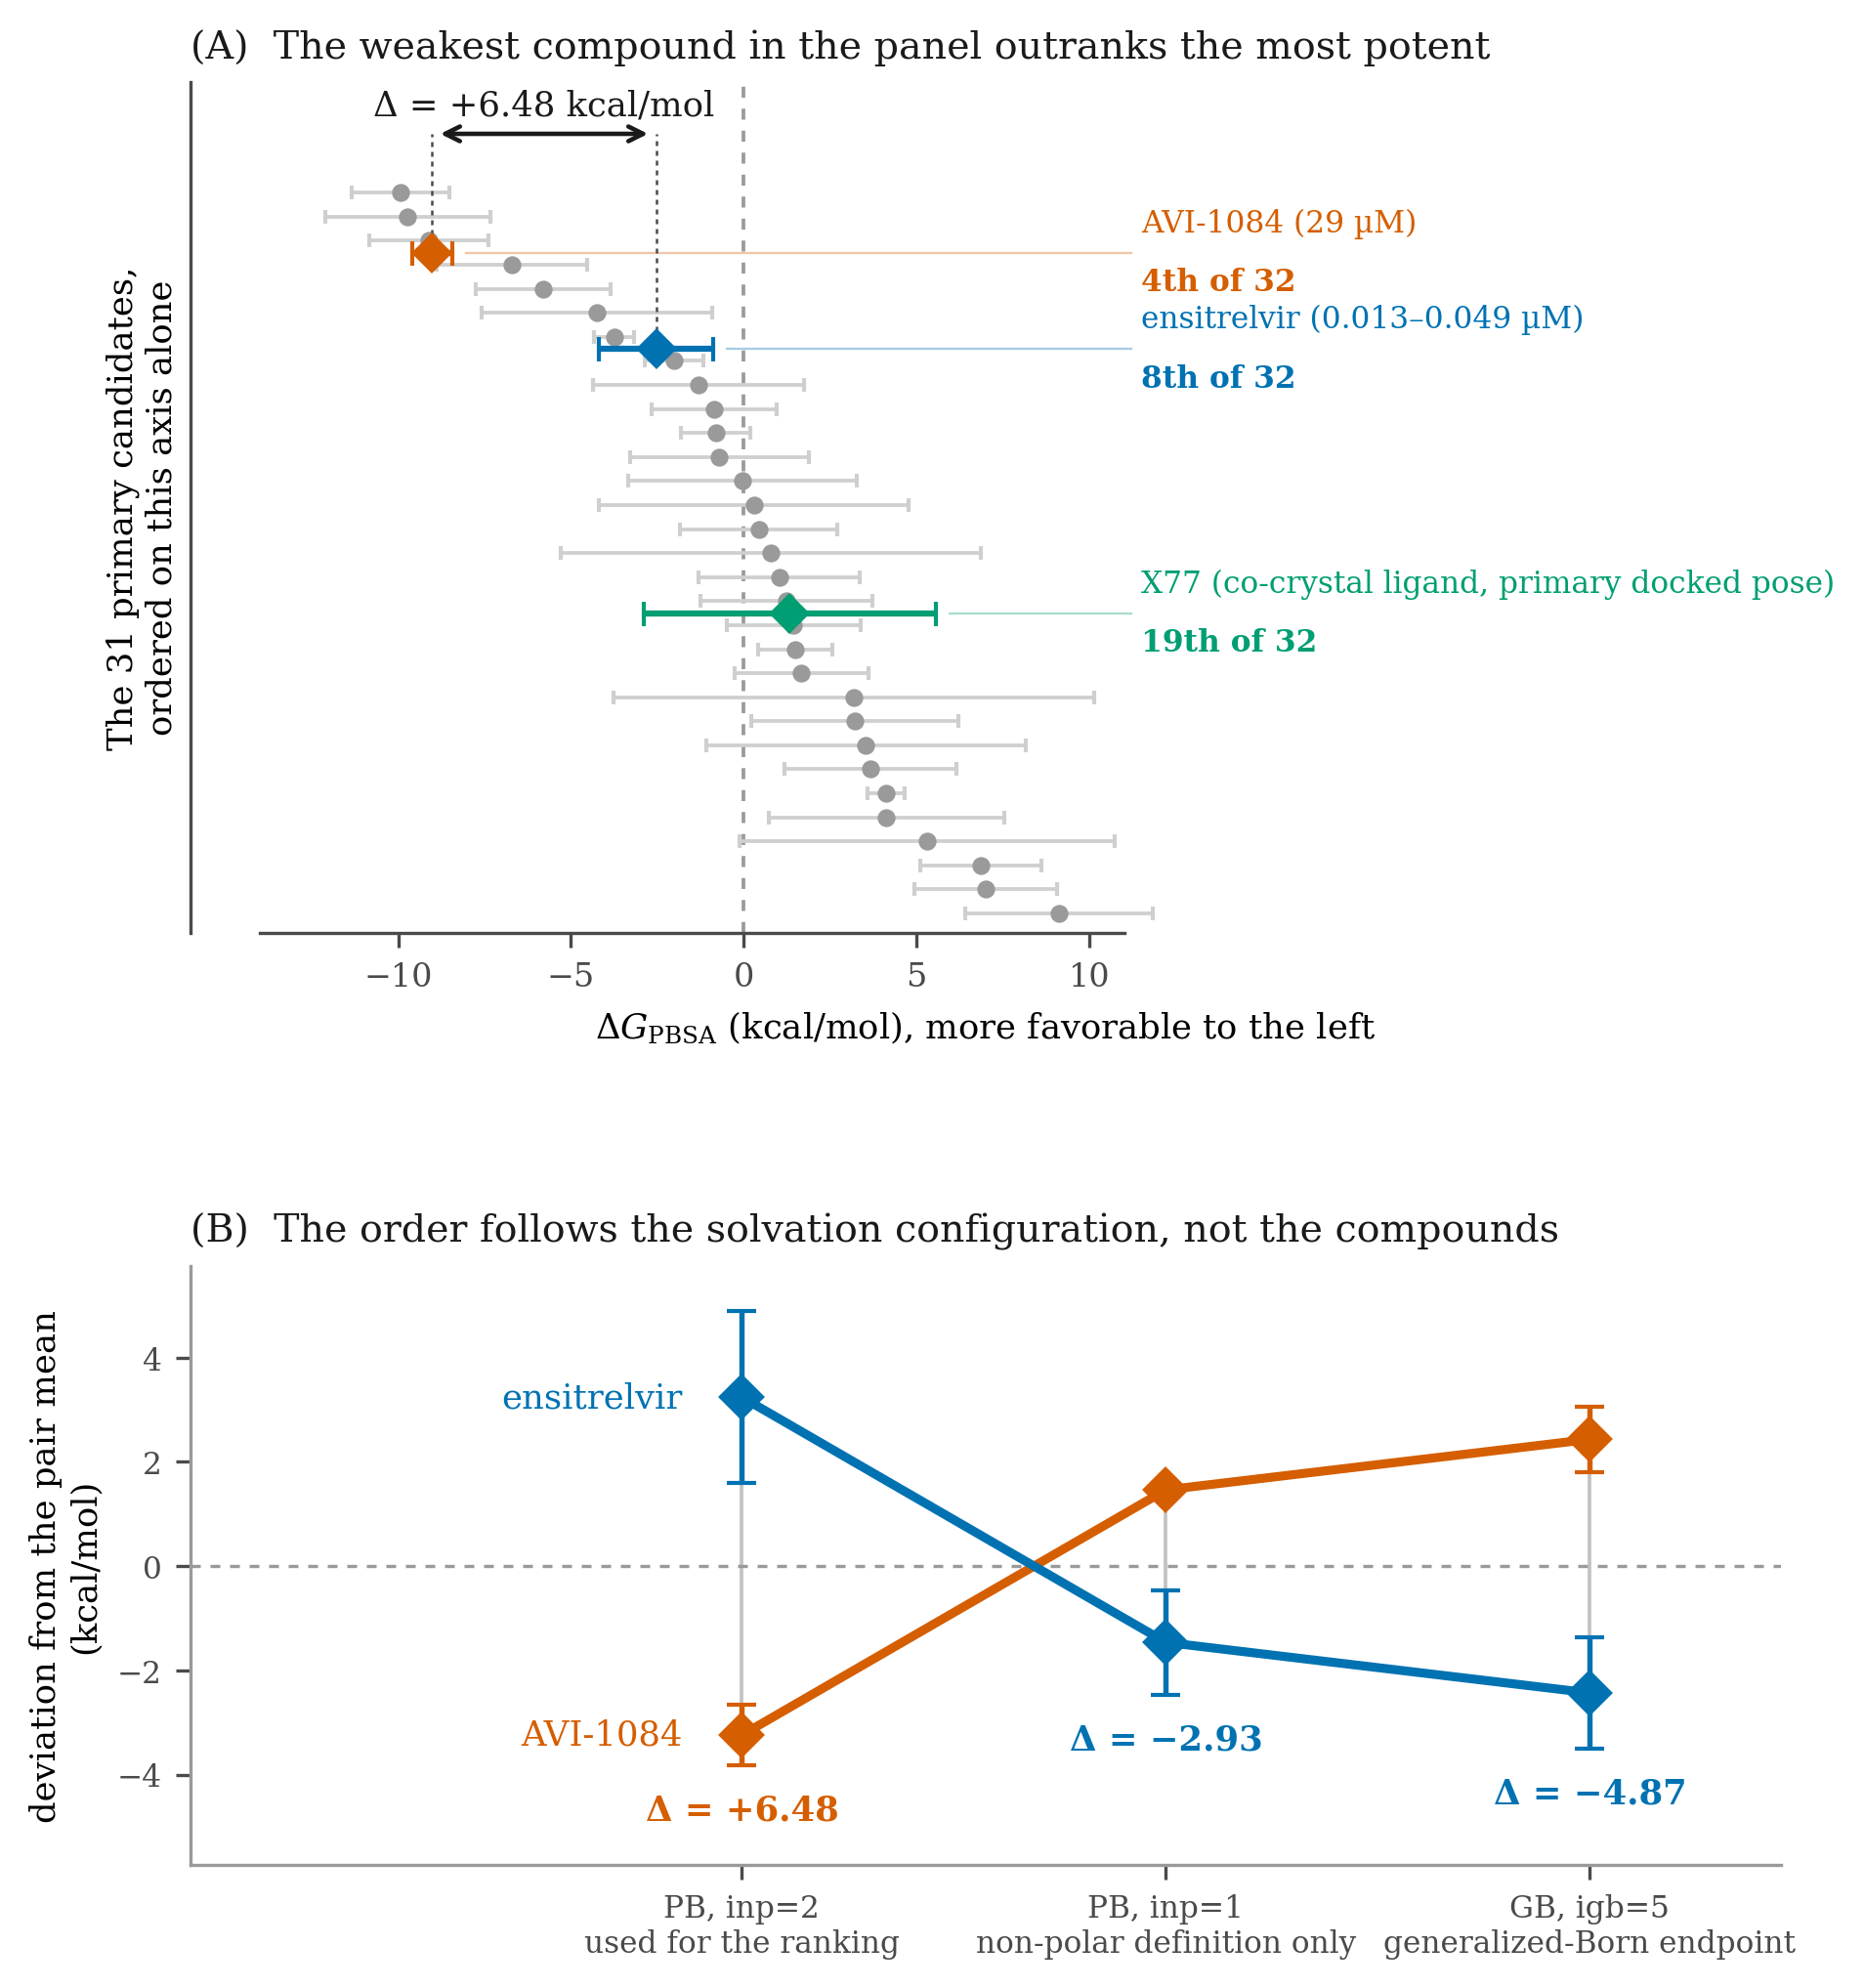

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_7.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_7.pdf`</sub>

In [20]:
# 并入自 cell_figure7.py（2026-11-20）
# ============================================================
# Figure 7 · 同一批帧上的 PB 与 GB 端点                        （§3.4.3 · §3.4.9）
# ============================================================
# 2026-11-20：本图原为六图中唯一尚未接线者，其 18 个数值皆为键入。
# 现已全部改读档 —— 2026-11-16 的两次登记对照实验已入库（提交 cdcf48b），
# 三份逐副本档各 12 行，且自带指向 FINAL_RESULTS.dat 的 src 列：
#     Scoring/solv_alt_2026-11-16/ref_panel_PB_per_replica_TOTAL.csv   （PB, inp=2）
#     Scoring/solv_alt_2026-11-16/B_inp1_per_replica_TOTAL.csv         （PB, inp=1）
#     Scoring/solv_alt_2026-11-16/A_gb_per_replica_TOTAL.csv           （GB, igb=5）
# 故本图再无一个键入数值：均值、标准差、Δ 与三个锚点的名次一概现算。
#
# ⚠ 整幅包在函数里，其局部一个也不外泄。

def _figure_pair():
    import csv, io              # 笔记本单元 1 未 import
    import statistics as _st
    import matplotlib.text as mtext
    INK, INK2, MUTED = "#1a1a1a", "#4a4a4a", "#9a9a9a"
    C_A, C_E, C_X = "#D55E00", "#0072B2", "#009E73"
    FS_MIN, FS_TITLE = 7.5, 9.5
    AVI, ENS = "ref_AVI_1084__6W63__primary", "ref_ensitrelvir__6W63__primary"
    X77P = "ref_X77__6W63__primary"

    # ── 31 个主候选（受检之分布）────────────────────────────────────
    _pr = resolve("F(Γ) 排序", ["results/step8d_compass_ranking_SOLV_V3.csv"])
    R = sorted([(r["mol_id"], float(r["dG_PBSA_mean"]), float(r["sigma_PBSA"]))
                for r in csv.DictReader(io.open(_pr, encoding="utf-8"))], key=lambda z: z[1])
    if len(R) != 31:
        raise AssertionError("主候选须 31，实得 %d" % len(R))
    ys = np.arange(len(R))[::-1]

    # ── 三个配置的逐副本 TOTAL（全部读档）──────────────────────────
    def per_sys(path, col):
        g = {}
        for r in csv.DictReader(io.open(path, encoding="utf-8")):
            g.setdefault(r["system"], []).append(float(r[col]))
        for k, v in g.items():
            if len(v) != 3:
                raise AssertionError("%s 的 %s 不是 3 个副本，实得 %d" % (path, k, len(v)))
        # 标准差用 n−1（与 Table 2 的 sigma_PBSA 同口径，已逐值核对相符）
        return {k: (_st.mean(v), _st.stdev(v)) for k, v in g.items()}

    _p_pb  = resolve("参考臂 PB 逐副本 TOTAL",
                     ["Scoring/solv_alt_2026-11-16/ref_panel_PB_per_replica_TOTAL.csv"])
    _p_in1 = resolve("参考臂 PB inp=1 逐副本",
                     ["Scoring/solv_alt_2026-11-16/B_inp1_per_replica_TOTAL.csv"])
    _p_gb  = resolve("参考臂 GB igb=5 逐副本",
                     ["Scoring/solv_alt_2026-11-16/A_gb_per_replica_TOTAL.csv"])
    PB   = per_sys(_p_pb,  "TOTAL")
    IN1  = per_sys(_p_in1, "inp1_TOTAL")
    GB   = per_sys(_p_gb,  "GB_TOTAL")
    # 三档各自带的 PB 对照列须与主 PB 档一致，否则是三者不同源
    for _nm, _p, _c in (("B", _p_in1, "inp2_TOTAL"), ("A", _p_gb, "PB_TOTAL")):
        _chk = per_sys(_p, _c)
        for _k in PB:
            if abs(_chk[_k][0] - PB[_k][0]) > 5e-4:
                raise AssertionError("实验 %s 的 PB 对照列与主 PB 档不符：%s %.4f vs %.4f"
                                     % (_nm, _k, _chk[_k][0], PB[_k][0]))

    DG_GAP = PB[ENS][0] - PB[AVI][0]          # 现算，不键入（稿载 +6.48）

    # 三个锚点在「31 候选 + 该锚点」共 32 个中的名次
    def rank_in(v):
        return sum(1 for _, x, _ in R if x < v) + 1
    AN = [("AVI-1084 (29 µM)",                           AVI,  C_A),
          ("ensitrelvir (0.013–0.049 µM)",          ENS,  C_E),
          ("X77 (co-crystal ligand, primary docked pose)",  X77P, C_X)]
    ORD = {"1": "st", "2": "nd", "3": "rd"}

    fig = plt.figure(figsize=(7.0, 7.9))
    gs = fig.add_gridspec(2, 1, height_ratios=[1.42, 1.0], hspace=0.46)
    a1 = fig.add_subplot(gs[0]); a2 = fig.add_subplot(gs[1])

    # ───── (A) 现象 ─────
    a1.axvline(0, color=MUTED, lw=0.9, ls=(0, (3, 3)), zorder=1)
    a1.errorbar([r[1] for r in R], ys, xerr=[r[2] for r in R], fmt="o", ms=3.4,
                color=MUTED, ecolor="#cfcfcf", elinewidth=0.9, capsize=1.6, zorder=3)
    LX = 11.5
    _yof = {}
    for nm, key, c in AN:
        v, sd = PB[key]
        rk = rank_in(v); _yof[key] = y = len(R) - rk + 0.5
        rt = "%d%s of %d" % (rk, ORD.get(str(rk)[-1], "th") if not 10 <= rk % 100 <= 13 else "th",
                             len(R) + 1)
        a1.errorbar([v], [y], xerr=[sd], fmt="D", ms=6.2, color=c, ecolor=c,
                    elinewidth=1.5, capsize=3, zorder=6)
        a1.plot([v + sd + 0.4, LX - 0.3], [y, y], color=c, lw=0.55, alpha=0.35, zorder=2)
        a1.annotate(nm, (LX, y + 0.60), ha="left", va="bottom", fontsize=FS_MIN, color=c)
        a1.annotate(rt, (LX, y - 0.60), ha="left", va="top", fontsize=FS_MIN,
                    color=c, weight="bold")
    xa, xe = PB[AVI][0], PB[ENS][0]
    yA, yE = _yof[AVI], _yof[ENS]; ybar = len(R) + 1.45
    a1.plot([xa, xa], [yA + 0.35, ybar], color=INK2, lw=0.6, ls=(0, (2, 2)), zorder=4)
    a1.plot([xe, xe], [yE + 0.35, ybar], color=INK2, lw=0.6, ls=(0, (2, 2)), zorder=4)
    a1.annotate("", (xa, ybar), (xe, ybar), arrowprops=dict(arrowstyle="<->", color=INK, lw=1.1))
    a1.annotate(("Δ = %+.2f kcal/mol" % DG_GAP).replace("-", "−"),
                ((xa + xe) / 2, ybar + 0.50),
                ha="center", va="bottom", fontsize=8.5, color=INK)
    a1.set_yticks([]); a1.set_xlim(-16, 30); a1.set_ylim(-0.8, len(R) + 3.6)
    a1.set_xticks([-10, -5, 0, 5, 10]); a1.spines["bottom"].set_bounds(-14, 11.0)
    a1.set_xlabel("$\\Delta G_{\\mathrm{PBSA}}$ (kcal/mol), more favorable to the left",
                  fontsize=8.5)
    a1.set_ylabel("The %d primary candidates,\nordered on this axis alone" % len(R),
                  fontsize=8.5, labelpad=3)
    a1.set_title("(A)  The weakest compound in the panel outranks the most potent",
                 loc="left", color=INK, fontsize=FS_TITLE)
    for s_ in ("top", "right"): a1.spines[s_].set_visible(False)

    # ───── (B) 诊断 ─────
    CFG = [("PB, inp=2",  "used for the ranking",        PB),
           ("PB, inp=1",  "non-polar definition only",   IN1),
           ("GB, igb=5",  "generalized-Born endpoint",   GB)]
    xs = np.arange(3)
    A  = [t[AVI][0] - (t[AVI][0] + t[ENS][0]) / 2 for _, _, t in CFG]
    E  = [t[ENS][0] - (t[AVI][0] + t[ENS][0]) / 2 for _, _, t in CFG]
    SA = [t[AVI][1] for _, _, t in CFG]
    SE_ = [t[ENS][1] for _, _, t in CFG]
    for k in range(3):
        a2.plot([k, k], [A[k], E[k]], color=MUTED, lw=0.9, alpha=0.6, zorder=3)
    a2.axhline(0, color=MUTED, lw=0.8, ls=(0, (3, 3)), zorder=1)
    a2.errorbar(xs, A, yerr=SA, fmt="-D", color=C_A, ecolor=C_A, lw=2.2, ms=7,
                elinewidth=1.3, capsize=3.5, zorder=5)
    a2.errorbar(xs, E, yerr=SE_, fmt="-D", color=C_E, ecolor=C_E, lw=2.2, ms=7,
                elinewidth=1.3, capsize=3.5, zorder=5)
    # 轴域先定：下缘须容得下三个 Δ 标注，否则标注要么被裁，要么挤回须端
    _lo = min(min(a - s for a, s in zip(A, SA)), min(e - s for e, s in zip(E, SE_)))
    _hi = max(max(a + s for a, s in zip(A, SA)), max(e + s for e, s in zip(E, SE_)))
    _sp = _hi - _lo
    a2.set_ylim(_lo - 0.22 * _sp, _hi + 0.10 * _sp)
    # 标注锚在下须末端，再以**点**为单位下移 7 pt，且向下生长（va="top"）。
    # 旧法 (k, top−0.42) 配 va="bottom" 是自锚点**向上**生长，而 8.5 pt 的行高
    # 大于 0.42 个数据单位，于是文字顶部顶回须端，与误差棒帽相叠——2026-11-20
    # 所见之症（初看似减号错排，实为两个图元相撞）。以 offset points 定距，则
    # 不随 dpi 变，也不随日后 ylim 的改动变。
    # Δ 用码位 U+0394 而非 $\Delta$：mathtext 取 dejavusans，与本行其余
    # 的衬线粗体不同面，放大后一眼可辨；Figure 6 面板 B 早已用码位，此处从之。
    _GAP_PT, _labs, _tops = 7.0, [], []
    for k, (_, _, t) in enumerate(CFG):
        g = t[ENS][0] - t[AVI][0]
        top = min(A[k] - SA[k], E[k] - SE_[k]); _tops.append(top)
        _labs.append(a2.annotate(
            ("Δ = %+.2f" % g).replace("-", "−"), (k, top),
            xytext=(0, -_GAP_PT), textcoords="offset points",
            ha="center", va="top", fontsize=8.5,
            color=(C_A if g > 0 else C_E), weight="bold"))
    a2.annotate("AVI-1084", (-0.14, A[0]), ha="right", va="center", fontsize=8.5, color=C_A)
    a2.annotate("ensitrelvir", (-0.14, E[0]), ha="right", va="center", fontsize=8.5, color=C_E)
    a2.set_xticks(xs)
    a2.set_xticklabels(["%s\n%s" % (n, s) for n, s, _ in CFG], fontsize=FS_MIN, color=INK2)
    a2.set_xlim(-1.30, 2.45)
    a2.set_ylabel("deviation from the pair mean\n(kcal/mol)", fontsize=8.5)
    a2.set_title("(B)  The order follows the solvation configuration, not the compounds",
                 loc="left", color=INK, fontsize=FS_TITLE)
    for s_ in ("top", "right"): a2.spines[s_].set_visible(False)
    a2.spines["left"].set_color(MUTED); a2.spines["bottom"].set_color(MUTED)
    a2.tick_params(colors=INK2, labelsize=FS_MIN)

    # 两道断言：符号与量级须与 §3.4.3 / §3.4.9 相符，否则宁可中断
    if not (DG_GAP > 0):
        raise AssertionError("PB inp=2 下 Δ 须为正（潜能反序），实得 %+.4f" % DG_GAP)
    for _nm, _t in (("inp=1", IN1), ("igb=5", GB)):
        _g = _t[ENS][0] - _t[AVI][0]
        if not (_g < 0):
            raise AssertionError("%s 下 Δ 须为负（符号恢复），实得 %+.4f" % (_nm, _g))

    # 第三道：面板 B 的三个 Δ 标注既不得与误差棒相撞，也不得越出轴域下缘。
    # 2026-11-20 之症正是前者：文字顶部与须端只差 0.03 个数据单位，帽线一画即叠。
    # 阈值一律按**点**计——像素阈值随 dpi 变（笔记本 100、他处或 150），
    # 这是 Figure 2 余量断言上已栽过的同一个跟头。
    fig.canvas.draw()
    _rd = fig.canvas.get_renderer(); _ppx = fig.dpi / 72.0
    _abb = a2.get_window_extent(_rd)
    for _k, (_t, _tp) in enumerate(zip(_labs, _tops)):
        _tb = _t.get_window_extent(_rd)
        _gap = (a2.transData.transform((_k, _tp))[1] - _tb.y1) / _ppx
        if _gap < 4.0:
            raise AssertionError("面板 B 第 %d 个 Δ 标注距误差棒末端仅 %.2f pt（须 ≥ 4）"
                                 % (_k + 1, _gap))
        if _tb.y0 < _abb.y0:
            raise AssertionError("面板 B 第 %d 个 Δ 标注越出轴域下缘 %.2f pt"
                                 % (_k + 1, (_abb.y0 - _tb.y0) / _ppx))
    return fig

_f7 = _figure_pair()
save_fig(_f7, 7, "PB and GB endpoints computed on the same frames",
         caption=(
             "The endpoint does not recover the known potency order, and the order it returns "
             "follows the solvation configuration. (A) The 31 primary candidates ordered by "
             "ΔG_PBSA, with the three reference compounds placed on the same "
             "axis: the weakest compound of the panel ranks ahead of the most potent, the two "
             "separated by 6.48 kcal/mol in the direction opposite to their measured activity "
             "(§3.4.3). Ranks are given out of 32, the 31 candidates plus the compound shown. "
             "(B) The same pair under three implicit-solvent configurations computed on identical "
             "frames of identical trajectories, plotted as deviation from each configuration's "
             "pair mean so that the three are comparable despite shifts of 26 and 34 kcal/mol in "
             "location relative to the original configuration. Both follow-up configurations "
             "recover the experimental order, one by "
             "changing only the non-polar definition (§3.4.9). Error bars are ±1 σ across the "
             "three replicas of each system. All eighteen values are read from the three deposited "
             "per-replica tables of the 2026-11-16 control experiments, which carry their own "
             "pointers to the endpoint program's output files; no value in this figure is typed."))


In [21]:
# 并入自 cell_tableS19.py（2026-11-20）
# ============================================================
# Table S19 · 参考面板在三种溶剂化配置下的逐副本端点值      （§3.4.9 · §S-17.1.10）
# ============================================================
# 2026-11-20：此表此前**以 markdown 手写在 §S-17.1.10 之中**，其 24 个汇总值
# （12 均值 + 12 σ）虽已逐一核对与存档相符，毕竟是手写之数。今改由本单元自那三份
# 逐副本对照档现算，手写块随之自稿中删去 —— 一个数只有一处来源（规则 3），
# 且 §6.1 之「reads only the deposited derived data」方才名实相符。
#
# 表的列序、行序、显示名与题注，一概照手写原表：
#   列 = System | Replica | GB, igb=5 | PB, inp=1 | PB, inp=2
#   每体系三条逐副本行，后随一条 mean (σ) 行；末行为 ensitrelvir − AVI-1084 之差。
#
# **单元格一律纯文本：不嵌 `**`，不嵌反引号。** 原因是渲染路径变了——
# 手写表走 md_table，每格经 add_runs() 解析 markdown；而笔记本产物走 real_table()，
# 其单元按**字面**排入（那是为护住 Table S9 的 3*50*30 不被当作斜体吞掉星号）。
# 故若把 `**` 写进单元，docx 会原样印出星号，入库的 .csv 也会夹带标记而伤机读。
# 四条 mean (σ) 行与末行差值行的粗体，已移至 md2docx_prism.py 的 real_table()
# 按行施加——呈现之事归呈现层。
#
# σ 为**总体标准差**（除以 n = 3），与 §S-17.1.3 所论之「divisor 3」一致；
# 若误用样本标准差（除以 n − 1），AVI 的 GB 侧会由 0.508 变成 0.622。

def _table_S19():
    import csv, io
    import statistics as _st
    SRC = [("GB, igb=5",  "Scoring/solv_alt_2026-11-16/A_gb_per_replica_TOTAL.csv",         "GB_TOTAL"),
           ("PB, inp=1",  "Scoring/solv_alt_2026-11-16/B_inp1_per_replica_TOTAL.csv",       "inp1_TOTAL"),
           ("PB, inp=2",  "Scoring/solv_alt_2026-11-16/ref_panel_PB_per_replica_TOTAL.csv", "TOTAL")]
    COLS = [c for c, _, _ in SRC]
    dat = {}
    for col, path, field in SRC:
        p = resolve("参考臂逐副本 TOTAL · %s" % col, [path])
        g = {}
        for r in csv.DictReader(io.open(p, encoding="utf-8")):
            g.setdefault(r["system"], {})[r["rep"]] = float(r[field])
        if len(g) != 4 or any(len(v) != 3 for v in g.values()):
            raise AssertionError("%s：须 4 体系 × 3 副本，实得 %s"
                                 % (col, {k: len(v) for k, v in g.items()}))
        dat[col] = g
    _keys = [sorted((s, r) for s, v in dat[c].items() for r in v) for c in COLS]
    if _keys[0] != _keys[1] or _keys[1] != _keys[2]:
        raise AssertionError("三档的 体系×副本 键不一致，不可并表")

    ORDER = [("ref_AVI_1084__6W63__primary",    "AVI-1084"),
             ("ref_X77__6W63__nearnative",      "X77, near-native pose"),
             ("ref_X77__6W63__primary",         "X77, primary pose"),
             ("ref_ensitrelvir__6W63__primary", "ensitrelvir")]
    for sysid, _ in ORDER:
        if sysid not in dat[COLS[0]]:
            raise AssertionError("存档中无体系 %s" % sysid)
    MINUS = "−"                      # U+2212，与稿中其余数字同形
    def f(x, nd):
        return ("%+." + str(nd) + "f") % x if x >= 0 else (MINUS + ("%." + str(nd) + "f") % abs(x))

    rows = []
    for sysid, disp in ORDER:
        reps = sorted(dat[COLS[0]][sysid])
        for rp in reps:
            rows.append({"System": disp, "Replica": rp,
                         **{c: f(dat[c][sysid][rp], 2) for c in COLS}})
        cell = {c: "%s (%.3f)" % (f(_st.mean([dat[c][sysid][rp] for rp in reps]), 3),
                                  _st.pstdev([dat[c][sysid][rp] for rp in reps]))
                for c in COLS}
        rows.append({"System": disp, "Replica": "mean (σ)", **cell})
    dif = {}
    for c in COLS:
        a = _st.mean(list(dat[c]["ref_AVI_1084__6W63__primary"].values()))
        e = _st.mean(list(dat[c]["ref_ensitrelvir__6W63__primary"].values()))
        dif[c] = e - a
    rows.append({"System": "ensitrelvir " + MINUS + " AVI-1084", "Replica": "—",
                 **{c: f(dif[c], 3) for c in COLS}})

    T = pd.DataFrame(rows, columns=["System", "Replica"] + COLS)
    expect_rows(T, 17, "4 体系 × (3 副本 + 1 均值行) + 1 差值行")

    # —— 自检一：三个差值须复现 §3.4.9 / §S-17.1.10 所载 ——
    for c, want in (("GB, igb=5", -4.867), ("PB, inp=1", -2.927), ("PB, inp=2", 6.483)):
        if abs(dif[c] - want) > 6e-4:
            raise AssertionError("%s 之差算得 %+.4f，而稿载 %+.3f" % (c, dif[c], want))
    # —— 自检二：PB inp=2 须为正（潜能反序），两个后续配置须为负（符号恢复）——
    if not (dif["PB, inp=2"] > 0 > dif["PB, inp=1"] and dif["GB, igb=5"] < 0):
        raise AssertionError("三配置之符号不合 §3.4.9 所述")
    # —— 自检三：单元内不得含 markdown 标记（渲染层按字面排入，嵌之即原样印出）——
    _marks = [(r["System"], r["Replica"], k, v) for r in rows for k, v in r.items()
              if any(ch in str(v) for ch in ("*", "`", "_"))]
    if _marks:
        raise AssertionError("单元含 markdown 标记 %s —— real_table 按字面排入，会原样印出"
                             % _marks[:3])
    print("  三配置之差：GB %+.3f · inp=1 %+.3f · inp=2 %+.3f   与稿载相符；单元无标记字符"
          % (dif["GB, igb=5"], dif["PB, inp=1"], dif["PB, inp=2"]))
    return T

S19 = _table_S19()
save_table(S19, "S19",
           "Per-replica interaction energies for the reference panel under the three solvation "
           "configurations, on identical frames of identical trajectories, in kcal/mol. "
           "`inp=2` is the configuration of §2.5 used for ranking; `inp=1` differs from it only "
           "in the non-polar definition; `igb=5` is the generalized-Born endpoint. Means are "
           "per-system over three replicas; σ is the population standard deviation across "
           "replicas. **The `inp=2` column reproduces §S-17.1.3 from the deposited files**, "
           "returning the anchor difference as +6.4833 kcal/mol at 6.44 to 7.88 standard errors, "
           "which is the 6.4 to 7.9 reported there.",
           floatfmt=None)


  [参考臂逐副本 TOTAL · GB, igb=5] Scoring/solv_alt_2026-11-16/A_gb_per_replica_TOTAL.csv
  [参考臂逐副本 TOTAL · PB, inp=1] Scoring/solv_alt_2026-11-16/B_inp1_per_replica_TOTAL.csv
  [参考臂逐副本 TOTAL · PB, inp=2] Scoring/solv_alt_2026-11-16/ref_panel_PB_per_replica_TOTAL.csv
  条数 17 ✓  (4 体系 × (3 副本 + 1 均值行) + 1 差值行)
  三配置之差：GB -4.867 · inp=1 -2.927 · inp=2 +6.483   与稿载相符；单元无标记字符
  → Table_S19  (.csv + .md)   17 行 × 5 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S19.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S19.md


**Table S19.** Per-replica interaction energies for the reference panel under the three solvation configurations, on identical frames of identical trajectories, in kcal/mol. `inp=2` is the configuration of §2.5 used for ranking; `inp=1` differs from it only in the non-polar definition; `igb=5` is the generalized-Born endpoint. Means are per-system over three replicas; σ is the population standard deviation across replicas. **The `inp=2` column reproduces §S-17.1.3 from the deposited files**, returning the anchor difference as +6.4833 kcal/mol at 6.44 to 7.88 standard errors, which is the 6.4 to 7.9 reported there.

| System                 | Replica  | GB, igb=5       | PB, inp=1       | PB, inp=2      |
|:-----------------------|:---------|:----------------|:----------------|:---------------|
| AVI-1084               | r1       | −37.40          | −30.52          | −9.68          |
| AVI-1084               | r2       | −37.47          | −30.61          | −8.63          |
| AVI-1084               | r3       | −36.36          | −30.78          | −8.74          |
| AVI-1084               | mean (σ) | −37.077 (0.508) | −30.637 (0.108) | −9.017 (0.471) |
| X77, near-native pose  | r1       | −42.23          | −33.35          | −4.29          |
| X77, near-native pose  | r2       | −31.48          | −24.13          | +3.58          |
| X77, near-native pose  | r3       | −38.18          | −30.95          | −0.87          |
| X77, near-native pose  | mean (σ) | −37.297 (4.433) | −29.477 (3.906) | −0.527 (3.222) |
| X77, primary pose      | r1       | −24.76          | −21.59          | +2.10          |
| X77, primary pose      | r2       | −44.70          | −33.63          | −3.23          |
| X77, primary pose      | r3       | −29.44          | −21.93          | +5.13          |
| X77, primary pose      | mean (σ) | −32.967 (8.514) | −25.717 (5.597) | +1.333 (3.456) |
| ensitrelvir            | r1       | −42.36          | −32.51          | −0.66          |
| ensitrelvir            | r2       | −42.74          | −34.51          | −3.75          |
| ensitrelvir            | r3       | −40.73          | −33.67          | −3.19          |
| ensitrelvir            | mean (σ) | −41.943 (0.872) | −33.563 (0.820) | −2.533 (1.344) |
| ensitrelvir − AVI-1084 | —        | −4.867          | −2.927          | +6.483         |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S19.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S19.md`</sub>

,System,Replica,"GB, igb=5","PB, inp=1","PB, inp=2"
0,AVI-1084,r1,−37.40,−30.52,−9.68
1,AVI-1084,r2,−37.47,−30.61,−8.63
2,AVI-1084,r3,−36.36,−30.78,−8.74
3,AVI-1084,mean (σ),−37.077 (0.508),−30.637 (0.108),−9.017 (0.471)
4,"X77, near-native pose",r1,−42.23,−33.35,−4.29
5,"X77, near-native pose",r2,−31.48,−24.13,+3.58
6,"X77, near-native pose",r3,−38.18,−30.95,−0.87
7,"X77, near-native pose",mean (σ),−37.297 (4.433),−29.477 (3.906),−0.527 (3.222)
8,"X77, primary pose",r1,−24.76,−21.59,+2.10
9,"X77, primary pose",r2,−44.70,−33.63,−3.23


  [交叉对接对照目录] results/04_docking/redock_control/crossdock_control_manifest.json
  → Figure_11  (.png 300 dpi + .pdf)  3×3 cross-receptor co-crystal ligand docking control
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_11.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_11.pdf   （矢量，ACS 投稿以此为佳）


**Figure 11.** A docking control on the three receptors used in this work. (A) Each of the three co-crystal ligands docked into each of the three receptors, colored by deviation from that ligand's own row mean, so that the question asked is which receptor each ligand scores best in rather than which ligand scores best. The crystallographic pairing is outlined in bold and the median redocking RMSD is printed beneath it. The native receptor ranked first for one of the three ligands. (B) For each ligand, the margin between its native receptor and its best non-native one, set against the seed-to-seed spread of that same ligand's own redocking runs. The per-receptor baselines differ by 0.386 kcal/mol across the three targets (§S-10), which is the scale against which any cross-ortholog difference must be read. Both panels are computed from the two deposited docking-control manifests (§6.1).

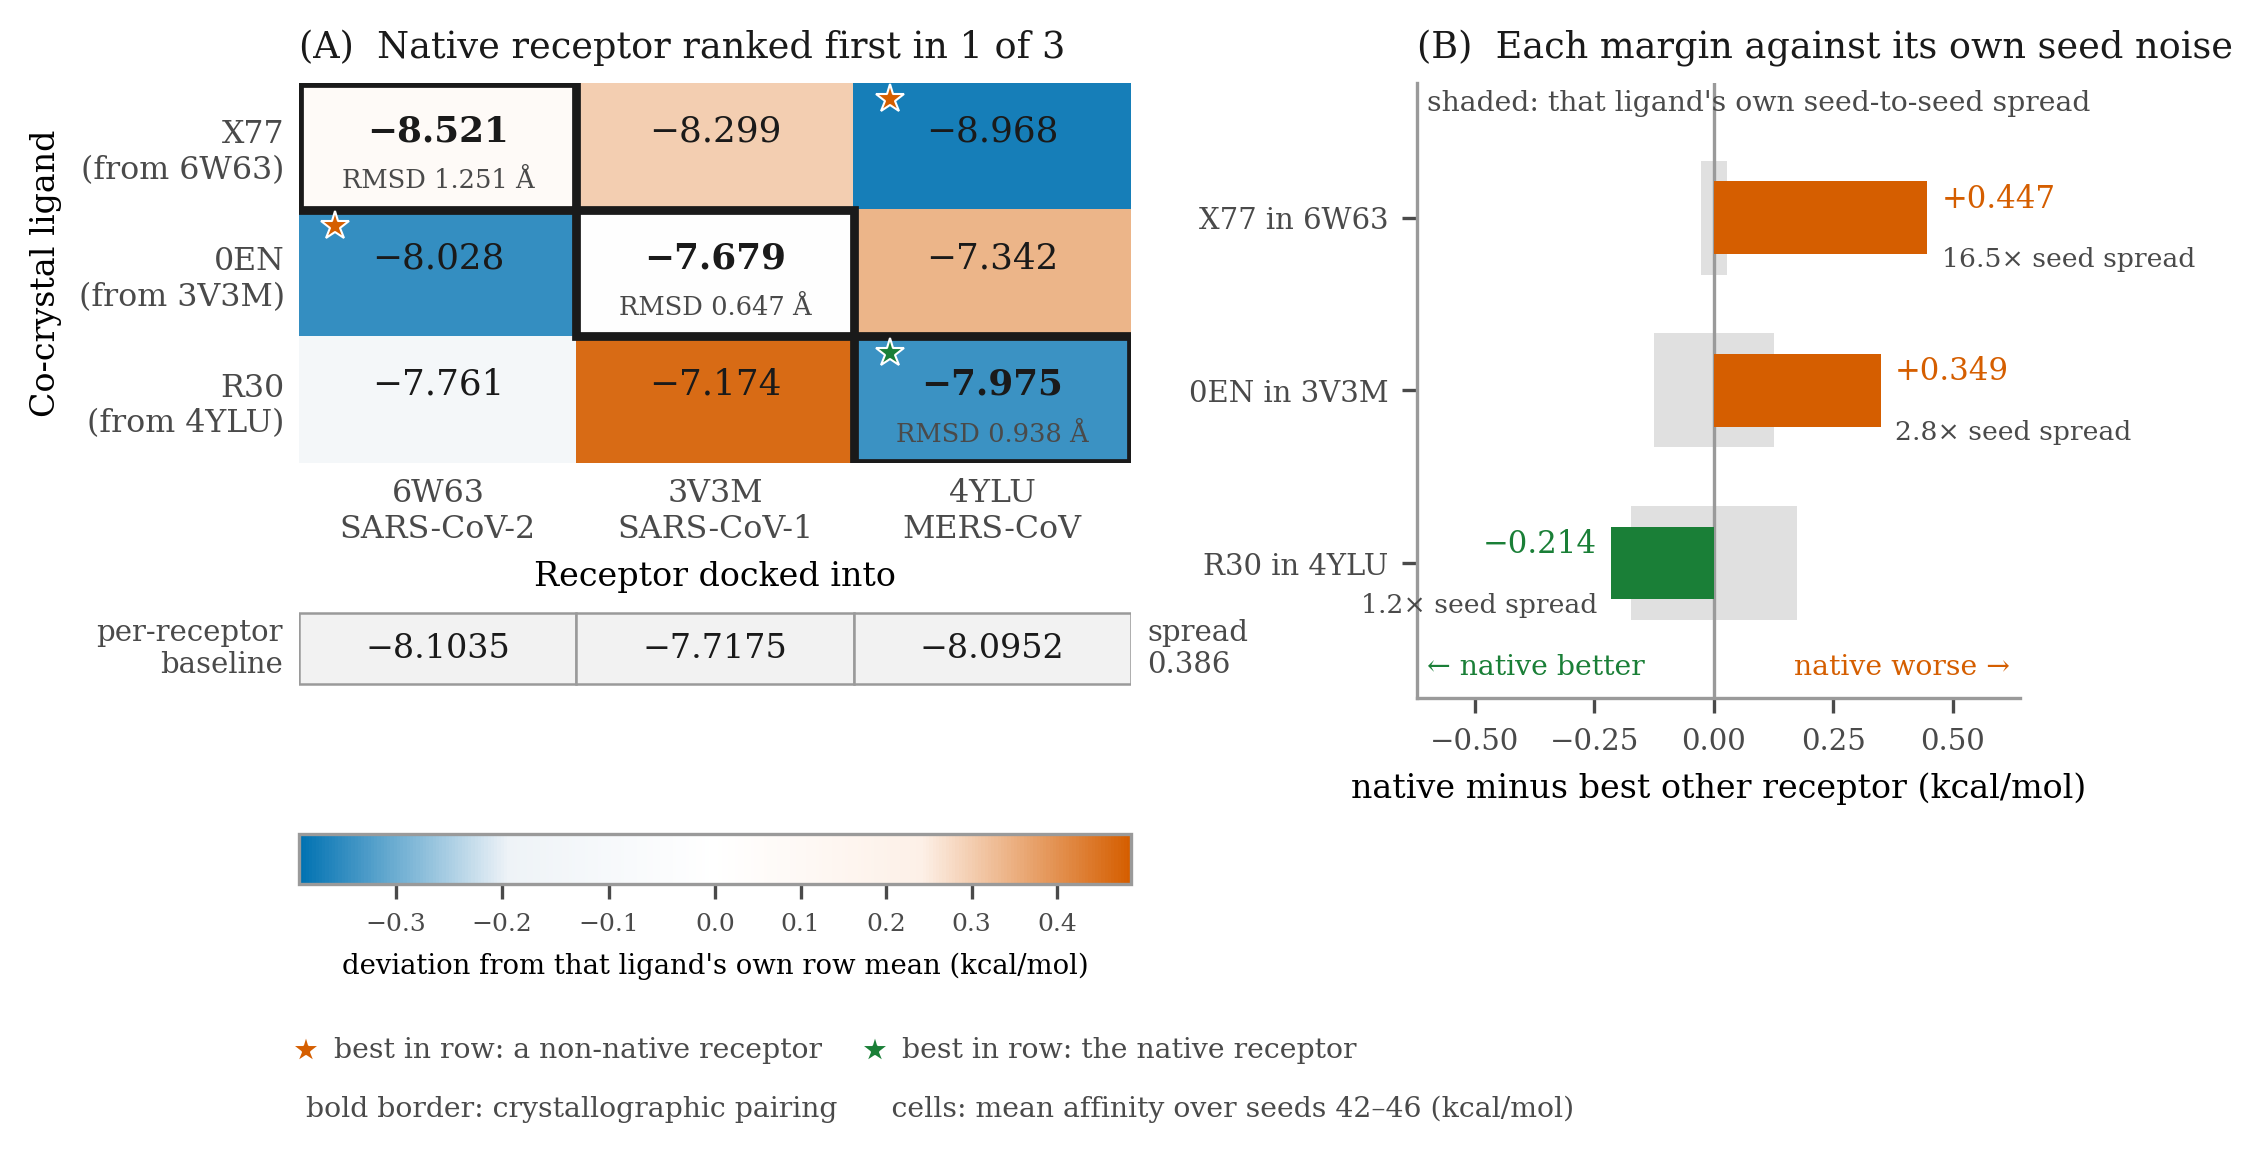

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_11.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_11.pdf`</sub>

In [22]:
# 并入自 cell_figure11.py（2026-11-20）
# ==========================================================
# Figure 11 · （由 mock_xdock.py 转录；路径改为 lang2 口径，取数一律走 resolve）
# ==========================================================
# ⚠ 整幅包在函数里，其局部一个也不外泄。

def _figure_xdock():
    import io                   # 笔记本单元 1 未 import
    from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
    from matplotlib.patches import Rectangle
    _D_XD = os.path.dirname(resolve("交叉对接对照目录", ["results/04_docking/redock_control/crossdock_control_manifest.json"]))
    INK,INK2,MUTED="#1a1a1a","#4a4a4a","#9a9a9a"; C1,C2="#0072B2","#D55E00"

    X=json.load(io.open(os.path.join(_D_XD,"crossdock_control_manifest.json"),encoding='utf-8'))
    Rk=json.load(io.open(os.path.join(_D_XD,"redock_control_manifest.json"),encoding='utf-8'))
    LIG=["X77","0EN","R30"]; REC=["6W63","3V3M","4YLU"]
    NATIVE={t["cocrystal_ligand"]:r for r,t in Rk["targets"].items()}      # X77->6W63 ...
    SPEC={"6W63":"SARS-CoV-2","3V3M":"SARS-CoV-1","4YLU":"MERS-CoV"}
    cell={(m["ligand"],m["target"]):m["mean_affinity"] for m in X["matrix"]}
    A=np.array([[cell[(l,r)] for r in REC] for l in LIG])
    dev=A-A.mean(axis=1,keepdims=True)                                     # 行内偏差
    RM={l:Rk["targets"][NATIVE[l]]["rmsd_top_median"] for l in LIG}
    SEED={l:(lambda v:(max(v)-min(v)))([s["affinity_best"] for s in Rk["targets"][NATIVE[l]]["per_seed"]]) for l in LIG}

    cmap=LinearSegmentedColormap.from_list("bo",[C1,"#eef3f7","#ffffff","#fdf0e7",C2])
    norm=TwoSlopeNorm(vmin=dev.min()*1.05,vcenter=0.0,vmax=dev.max()*1.05)

    fig=plt.figure(figsize=(7.4,4.55))
    gs=fig.add_gridspec(4,2,width_ratios=[1.38,1.0],height_ratios=[1.0,0.26,0.13,0.30],
                        wspace=0.40,hspace=0.85)
    ah=fig.add_subplot(gs[0,0]); ab=fig.add_subplot(gs[1,0])
    cax=fig.add_subplot(gs[2,0]); am=fig.add_subplot(gs[0:2,1]); alg=fig.add_subplot(gs[3,:])

    # ── 热图
    ah.imshow(dev,cmap=cmap,norm=norm,aspect="auto")
    for i,l in enumerate(LIG):
        for j,r in enumerate(REC):
            nat = NATIVE[l]==r
            ah.text(j,i-0.12,("%.3f"%A[i,j]).replace("-","\u2212"),ha="center",va="center",fontsize=8.6,color=INK,
                    fontweight="bold" if nat else "normal")
            if nat:
                ah.add_patch(Rectangle((j-0.5,i-0.5),1,1,fill=False,ec=INK,lw=2.1,zorder=5))
                ah.text(j,i+0.27,"RMSD %.3f Å"%RM[l],ha="center",va="center",
                        fontsize=6.2,color=INK2)
        b=int(np.argmin(A[i]))                                             # 行内最优（最负）
        ah.plot([b-0.37],[i-0.37],marker="*",ms=7.2,color=C2 if REC[b]!=NATIVE[l] else "#1a7f37",
                mec="white",mew=0.5,zorder=6)
    ah.set_xticks(range(3)); ah.set_xticklabels(["%s\n%s"%(r,SPEC[r]) for r in REC],fontsize=7.6)
    ah.set_yticks(range(3)); ah.set_yticklabels(["%s\n(from %s)"%(l,NATIVE[l]) for l in LIG],fontsize=7.6)
    ah.set_xlabel("Receptor docked into",fontsize=8); ah.set_ylabel("Co-crystal ligand",fontsize=8)

    ah.set_title("(A)  Native receptor ranked first in 1 of 3",loc="left",color=INK,fontsize=8.8)
    ah.tick_params(length=0)
    for s_ in ("top","right","left","bottom"): ah.spines[s_].set_visible(False)

    cb=fig.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),cax=cax,orientation="horizontal")
    cb.set_label("deviation from that ligand's own row mean (kcal/mol)",fontsize=6.6)
    cb.ax.tick_params(labelsize=6.0); cb.outline.set_edgecolor(MUTED)

    # ── 列均值条
    base=A.mean(axis=0)
    ab.set_xlim(-0.5,2.5); ab.set_ylim(0,1); ab.axis("off")
    for j,r in enumerate(REC):
        ab.add_patch(Rectangle((j-0.5,0.14),1,0.72,fc="#f2f2f2",ec=MUTED,lw=0.6))
        ab.text(j,0.50,("%.4f"%base[j]).replace("-","\u2212"),ha="center",va="center",fontsize=8,color=INK)
    ab.text(-0.56,0.50,"per-receptor\nbaseline",ha="right",va="center",fontsize=7,color=INK2)
    ab.text(2.56,0.50,"spread\n%.3f"%(base.max()-base.min()),ha="left",va="center",fontsize=7,color=INK2)

    # ── 右：本征受体相对最佳他受体之差，对种子噪声带
    am.axvline(0,color=MUTED,lw=0.8,zorder=1)
    ym=np.array([2.0,1.0,0.0])
    for k,l in enumerate(LIG):
        j=REC.index(NATIVE[l]); oth=[A[k,q] for q in range(3) if q!=j]
        gap=A[k,j]-min(oth)                                   # >0 本征较差；<0 本征胜出
        col=C2 if gap>0 else "#1a7f37"
        s=SEED[l]                                             # 该配体自身重对接的种子极差
        # 噪声带逐行画、且对零点对称：种子极差是幅度，正负两侧同等适用；
        # 共用一条带会把三行真实的余量差别（16.5×、2.8×、1.2×）抹平。
        am.add_patch(Rectangle((-s,ym[k]-0.33),2*s,0.66,color=MUTED,alpha=0.30,lw=0,zorder=2))
        am.barh(ym[k],gap,height=0.42,color=col,zorder=3)
        am.text(gap+(0.030 if gap>0 else -0.030),ym[k]+0.11,("%+.3f"%gap).replace("-","\u2212"),
                ha="left" if gap>0 else "right",va="center",fontsize=7.4,color=col)
        am.text(gap+(0.030 if gap>0 else -0.030),ym[k]-0.24,"%.1f\u00d7 seed spread"%(abs(gap)/s),
                ha="left" if gap>0 else "right",va="center",fontsize=6.4,color=INK2)
    am.set_yticks(ym); am.set_yticklabels(["%s in %s"%(l,NATIVE[l]) for l in LIG],fontsize=7.6)
    am.set_xlim(-0.62,0.64); am.set_ylim(-0.78,2.78)
    am.set_xlabel("native minus best other receptor (kcal/mol)",fontsize=8)
    am.set_title("(B)  Each margin against its own seed noise",loc="left",color=INK,fontsize=8.8)
    # 原句 65 字符、自 x=-0.44 起排，越出右缘 114 px；今缩短并左移至 xlim 左缘内侧。
    am.annotate("shaded: that ligand's own seed-to-seed spread",
                (-0.60,2.74),fontsize=6.8,color=INK2,ha="left",va="top")
    am.annotate("native worse →",(0.62,-0.60),fontsize=6.8,color=C2,ha="right",va="center")
    am.annotate("← native better",(-0.60,-0.60),fontsize=6.8,color="#1a7f37",ha="left",va="center")
    for s_ in ("top","right"): am.spines[s_].set_visible(False)
    am.spines["left"].set_color(MUTED); am.spines["bottom"].set_color(MUTED)
    am.tick_params(colors=INK2,labelsize=7)

    alg.axis("off"); alg.set_xlim(0,1); alg.set_ylim(0,1)
    # \u2605 不在 DejaVu Serif 字族内，直接写入会落成缺字方框；故以真实 marker 画出
    alg.plot([0.004],[0.74],marker="*",ms=7.2,color=C2,mec="white",mew=0.5,clip_on=False)
    _t1=alg.text(0.020,0.74,"best in row: a non-native receptor",fontsize=6.8,color=INK2,ha="left",va="center")
    fig.canvas.draw()
    _w=_t1.get_window_extent(renderer=fig.canvas.get_renderer()).width/alg.get_window_extent(
        renderer=fig.canvas.get_renderer()).width
    _x2=0.020+_w+0.030
    alg.plot([_x2],[0.74],marker="*",ms=7.2,color="#1a7f37",mec="white",mew=0.5,clip_on=False)
    # 原为一行，尾部越出右缘 218 px，tight bbox 遂把整幅撑宽至 9.03 in；
    # 压到 ACS 的 7.0 in 时全图缩小，最小字号只剩 4.81 pt。今把后半截移到第二行。
    alg.text(_x2+0.016,0.74,"best in row: the native receptor",
             fontsize=6.8,color=INK2,ha="left",va="center")
    alg.text(0.004,0.22,"bold border: crystallographic pairing      "
                        "cells: mean affinity over seeds 42\u201346 (kcal/mol)",
             fontsize=6.8,color=INK2,ha="left",va="center")
    return fig

_f11 = _figure_xdock()
save_fig(_f11, 11, "3×3 cross-receptor co-crystal ligand docking control",
         caption=(
             "A docking control on the three receptors used in this work. (A) Each of the three co-crystal "
             "ligands docked into each of the three receptors, colored by deviation from that ligand's own "
             "row mean, so that the question asked is which receptor each ligand scores best in rather "
             "than which ligand scores best. The crystallographic pairing is outlined in bold and the "
             "median redocking RMSD is printed beneath it. The native receptor ranked first for one of the "
             "three ligands. (B) For each ligand, the margin between its native receptor and its best "
             "non-native one, set against the seed-to-seed spread of that same ligand's own redocking "
             "runs. The per-receptor baselines differ by 0.386 kcal/mol across the three targets (§S-10), "
             "which is the scale against which any cross-ortholog difference must be read. Both panels are "
             "computed from the two deposited docking-control manifests (§6.1)."))


  [GB 交叉核对] results/step8c_gbsa_crossval_SOLV_V3.csv
  → Figure_S6  (.png 300 dpi + .pdf)  PB versus GB at the cohort level
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S6.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S6.pdf   （矢量，ACS 投稿以此为佳）


**Figure S6.** Poisson–Boltzmann and generalized-Born endpoints for all 31 primary candidates, computed on identical frames of identical trajectories (§2.5). (A) The two treatments against each other, at a rank correlation of ρ = 0.698. Eighteen of the 31 candidates return a positive mean under Poisson–Boltzmann and none does under generalized-Born, and the two distributions differ by about 35 kcal/mol in location, so the positive cohort median is specific to that solvation treatment rather than general to mechanics-based endpoints (§3.4.9). (B) Replicate dispersion of the two endpoints, with 19 of the 31 candidates above the diagonal: the median σ is 2.33 kcal/mol under Poisson–Boltzmann and 3.96 under generalized-Born, so at the cohort level the generalized-Born endpoint is the less precise of the two, and the pairwise resolution implied by three replicas is correspondingly 2.70 and 4.57 kcal/mol (§4.3). The comparison is descriptive: no pass criterion was registered for it, and the generalized-Born values do not enter F(Γ).

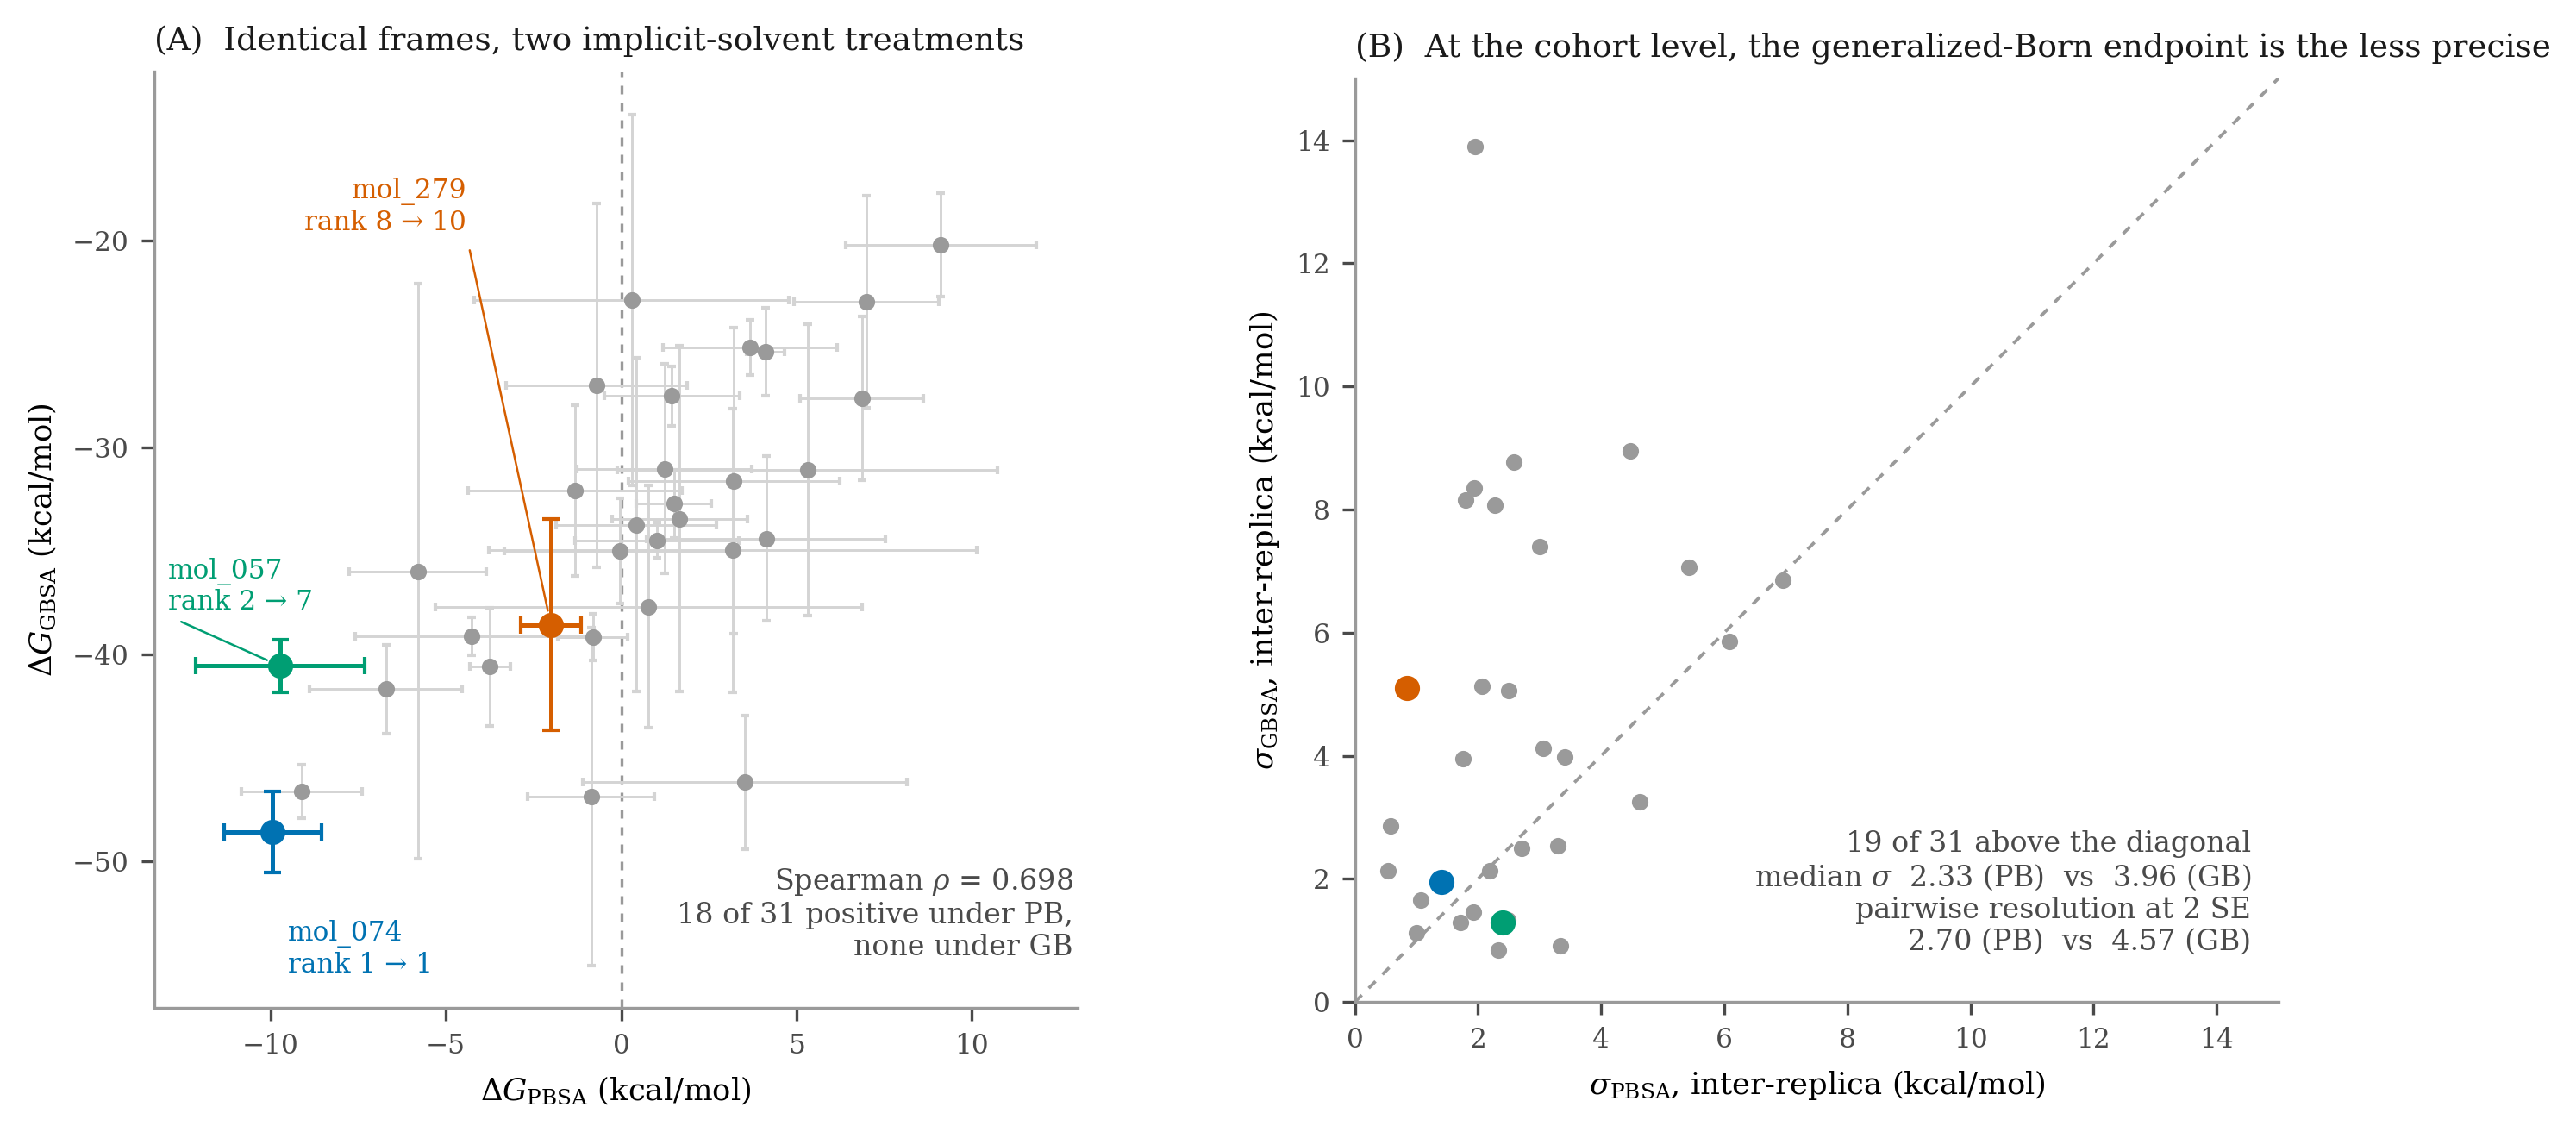

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S6.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S6.pdf`</sub>

In [23]:
# 并入自 cell_figureS6.py（2026-11-20）
# ==========================================================
# Figure S6 · （由 mock_pbgb.py 转录；路径改为 lang2 口径，取数一律走 resolve）
# ==========================================================
# ⚠ 整幅包在函数里，其局部一个也不外泄。

def _figure_pbgb():
    import csv, io, math        # 笔记本单元 1 未 import 这三个
    # 以下三行是原脚本头部所有、被转录时一并砍去者，补回函数内（不外泄）：
    import statistics as st
    import matplotlib.transforms as mtr
    import matplotlib.text as mtext
    _P_GB = resolve("GB 交叉核对", ["results/step8c_gbsa_crossval_SOLV_V3.csv"])
    INK,INK2,MUTED="#1a1a1a","#4a4a4a","#9a9a9a"; PAL=["#0072B2","#D55E00","#009E73"]
    R=[r for r in csv.DictReader(io.open(_P_GB,encoding='utf-8')) if r['mol_dir'].endswith('__primary')]
    D=[(r['mol_dir'].split('__')[0].replace('pool_mol_','mol_'),
        float(r['dG_PBSA_mean']),float(r['sigma_PBSA']),
        float(r['dG_GBSA_mean']),float(r['sigma_GBSA'])) for r in R]
    rp={n:i+1 for i,(n,*_) in enumerate(sorted(D,key=lambda z:z[1]))}
    rg={n:i+1 for i,(n,*_) in enumerate(sorted(D,key=lambda z:z[3]))}
    T1=["mol_074","mol_279","mol_057"]

    def spearman(a,b):
        def rk(v):
            o=sorted(range(len(v)),key=lambda i:v[i]); r=[0.0]*len(v); i=0
            while i<len(o):
                j=i
                while j+1<len(o) and v[o[j+1]]==v[o[i]]: j+=1
                for k in range(i,j+1): r[o[k]]=(i+j)/2.0+1
                i=j+1
            return r
        ra,rb=rk(a),rk(b); n=len(a)
        ma,mb=sum(ra)/n,sum(rb)/n
        num=sum((x-ma)*(y-mb) for x,y in zip(ra,rb))
        return num/math.sqrt(sum((x-ma)**2 for x in ra)*sum((y-mb)**2 for y in rb))

    PB=[x[1] for x in D]; GB=[x[3] for x in D]; sp=[x[2] for x in D]; sg=[x[4] for x in D]
    RHO=spearman(PB,GB); NPOS_PB=sum(1 for v in PB if v>0); NPOS_GB=sum(1 for v in GB if v>0)
    MEDP,MEDG=st.median(sp),st.median(sg)
    RESP,RESG=2*MEDP/math.sqrt(3),2*MEDG/math.sqrt(3)
    NABOVE=sum(1 for a,b in zip(sp,sg) if b>a)

    fig,(a1,a2)=plt.subplots(1,2,figsize=(10.6,4.7),gridspec_kw={"wspace":0.30})
    for n,p,s1,g,s2 in D:
        c=PAL[T1.index(n)] if n in T1 else MUTED
        a1.errorbar([p],[g],xerr=[s1],yerr=[s2],fmt="o",ms=6 if n in T1 else 3.6,color=c,
                    ecolor=c if n in T1 else "#d4d4d4",elinewidth=1.2 if n in T1 else 0.7,
                    capsize=2.4 if n in T1 else 1.3,zorder=6 if n in T1 else 3)
    a1.axvline(0,color=MUTED,lw=0.8,ls=(0,(3,3)),zorder=1)
    a1.set_xlabel("$\\Delta G_{\\mathrm{PBSA}}$ (kcal/mol)",fontsize=8.5)
    a1.set_ylabel("$\\Delta G_{\\mathrm{GBSA}}$ (kcal/mol)",fontsize=8.5)
    a1.set_title("(A)  Identical frames, two implicit-solvent treatments",loc="left",color=INK,fontsize=9)
    corner=a1.annotate("Spearman $\\rho$ = %.3f\n%d of 31 positive under PB,\n%s under GB"
                       %(RHO,NPOS_PB,"none" if NPOS_GB==0 else str(NPOS_GB)),
                       (0.995,0.05),xycoords="axes fraction",ha="right",va="bottom",fontsize=8,color=INK2)
    fig.canvas.draw(); rr=fig.canvas.get_renderer()

    # ── (A) 三个直标：以真实几何搜位，不凭眼估
    def bbx(a): return a.get_window_extent(renderer=rr)
    def rect(ax,x0,y0,x1,y1):
        q=ax.transData.transform([[x0,y0],[x1,y1]]); return mtr.Bbox([[q[0][0],q[0][1]],[q[1][0],q[1][1]]])
    def clash(b,obs,pad=2.0):
        return any(not (b.x1+pad<o.x0 or o.x1+pad<b.x0 or b.y1+pad<o.y0 or o.y1+pad<b.y0) for o in obs)
    OBS=[rect(a1,p-s1,g-s2,p+s1,g+s2) for _,p,s1,g,s2 in D]
    AXB=bbx(a1)

    XL,YL=a1.get_xlim(),a1.get_ylim()
    GX=np.linspace(XL[0]+0.4,XL[1]-0.4,16); GY=np.linspace(YL[0]+0.6,YL[1]-0.6,13)
    placed=[bbx(corner)]
    for n in T1:
        p,g=[(x[1],x[3]) for x in D if x[0]==n][0]
        txt="%s\nrank %d \u2192 %d"%(n,rp[n],rg[n]); col=PAL[T1.index(n)]
        cand=sorted(((gx,gy) for gx in GX for gy in GY),
                    key=lambda q:math.hypot(q[0]-p,(q[1]-g)*0.55))
        best=None
        for gx,gy in cand:
            for ha,va in (("left","bottom"),("right","bottom"),("left","top"),("right","top")):
                t=a1.annotate(txt,(gx,gy),fontsize=7.5,color=col,ha=ha,va=va)
                fig.canvas.draw(); bx=bbx(t)                 # 量真实渲染框，不作解析平移
                ok=(bx.x0>=AXB.x0 and bx.x1<=AXB.x1 and bx.y0>=AXB.y0 and bx.y1<=AXB.y1
                    and not clash(bx,OBS+placed,pad=2.0))
                if ok: best=(t,bx,gx,gy); break
                t.remove()
            if best: break
        if best is None:
            print("  ! %s \u5168\u5e45\u65e0\u7a7a\u4f4d" % n); continue
        t,bx,gx,gy=best; placed.append(bx)
        if math.hypot(gx-p,(gy-g)*0.55)>2.5:
            a1.annotate("",xy=(p,g),xytext=(gx,gy),
                        arrowprops=dict(arrowstyle="-",color=col,lw=0.6,shrinkA=4,shrinkB=4))

    # ── (B) 离散度；文字块移右下，保留 1:1
    hi=max(max(sp),max(sg))*1.08
    a2.plot([0,hi],[0,hi],color=MUTED,lw=0.9,ls=(0,(3,3)),zorder=1)
    for n,p,s1,g,s2 in D:
        c=PAL[T1.index(n)] if n in T1 else MUTED
        a2.plot([s1],[s2],"o",ms=6 if n in T1 else 3.6,color=c,zorder=6 if n in T1 else 3)
    a2.set_xlim(0,hi); a2.set_ylim(0,hi); a2.set_aspect("equal",adjustable="box")
    a2.set_xlabel("$\\sigma_{\\mathrm{PBSA}}$, inter-replica (kcal/mol)",fontsize=8.5)
    a2.set_ylabel("$\\sigma_{\\mathrm{GBSA}}$, inter-replica (kcal/mol)",fontsize=8.5)
    a2.set_title("(B)  At the cohort level, the generalized-Born endpoint is the less precise",loc="left",color=INK,fontsize=9)
    a2.annotate("%d of 31 above the diagonal\nmedian $\\sigma$  %.2f (PB)  vs  %.2f (GB)\n"
                "pairwise resolution at 2 SE\n%.2f (PB)  vs  %.2f (GB)"%(NABOVE,MEDP,MEDG,RESP,RESG),
                (0.97,0.05),xycoords="axes fraction",ha="right",va="bottom",fontsize=8,color=INK2)
    for ax in (a1,a2):
        for s in ("top","right"): ax.spines[s].set_visible(False)
        ax.spines["left"].set_color(MUTED); ax.spines["bottom"].set_color(MUTED)
        ax.tick_params(colors=INK2,labelsize=7.5)
    return fig

_fS6 = _figure_pbgb()
save_fig(_fS6, 'S6', "PB versus GB at the cohort level",
         caption=(
             "Poisson\u2013Boltzmann and generalized-Born endpoints for all 31 primary candidates, "
             "computed on identical frames of identical trajectories (\u00a72.5). (A) The two treatments "
             "against each other, at a rank correlation of \u03c1 = 0.698. Eighteen of the 31 candidates "
             "return a positive mean under Poisson\u2013Boltzmann and none does under generalized-Born, "
             "and the two distributions differ by about 35 kcal/mol in location, so the positive cohort "
             "median is specific to that solvation treatment rather than general to mechanics-based "
             "endpoints (\u00a73.4.9). (B) Replicate dispersion of the two endpoints, with 19 of the 31 "
             "candidates above the diagonal: the median \u03c3 is 2.33 kcal/mol under Poisson\u2013Boltzmann "
             "and 3.96 under generalized-Born, so at the cohort level the generalized-Born endpoint is "
             "the less precise of the two, and the pairwise resolution implied by three replicas is "
             "correspondingly 2.70 and 4.57 kcal/mol (\u00a74.3). The comparison is descriptive: no pass "
             "criterion was registered for it, and the generalized-Born values do not enter F(\u0393)."))


In [24]:
# ============================================================
# 结构图之共用：SMILES 的解析与二维作图           （Figure 4 · Figure S4）
# ============================================================
# **规则 23：取不到就报出所试之名与实有之列，不猜、不造。**
# RDKit 若不在该环境中，本 cell 与其后两个结构 cell 一并跳过，
# 并印出安装之法；其余产物不受影响。
HAVE_RDKIT = True
try:
    from rdkit import Chem, RDLogger
    from rdkit.Chem.Draw import rdMolDraw2D
    RDLogger.DisableLog("rdApp.*")
except Exception as e:
    HAVE_RDKIT = False
    print("  RDKit 不在本环境中（%s）。两幅结构图将跳过，其余产物不受影响。" % e)
    print("  欲补之，在该 conda 环境中执行： conda install -c conda-forge rdkit")
    print("  或：  python3 -m pip install rdkit")

SMI = None
if HAVE_RDKIT:
    psc = resolve("scope 表（SMILES 之源）", ["results/00_scope/all_candidates_v3_start.csv"])
    SC2 = pd.read_csv(psc)
    # 按**优先序**取，不按「只准命中一个」取：一张表同时有 smiles 与 canonical_smiles
    # 是常事，此时取前者并把两者都印出来，使所取为何一目了然。名字一律小写比对。
    _tried = ["smiles", "canonical_smiles", "smiles_canonical", "can_smiles",
              "isomeric_smiles", "mol_smiles", "smi"]
    _low = {str(c).strip().lower(): c for c in SC2.columns}
    _hit = [_low[t] for t in _tried if t in _low]
    if not _hit:
        print("  scope 表实有列：%s" % list(SC2.columns))
        raise KeyError("SMILES 列一个也无。所试之名（规则 23）：%s。"
                       "请把真实列名告我。" % _tried)
    if len(_hit) > 1:
        print("  SMILES 候选列命中 %d 个：%s —— 按优先序取第一个。" % (len(_hit), _hit))
    scol = _hit[0]
    ncol = pick(SC2, "身份", ["name", "mol_id", "id"])
    SMI = dict(zip(SC2[ncol].astype(str), SC2[scol].astype(str)))
    print("  SMILES 列 = %r；scope 表 %d 行" % (scol, len(SC2)))

def _svg_to_pdf(svg_text, outpdf):
    """SVG → PDF。依次试三条路；一条都不成则报错停机，不默默只留 PNG。"""
    errs = []
    try:
        import cairosvg
        cairosvg.svg2pdf(bytestring=svg_text.encode("utf-8"), write_to=outpdf)
        return "cairosvg"
    except Exception as e:
        errs.append("cairosvg: %s" % e)
    import shutil as _sh, subprocess, tempfile as _tf
    if _sh.which("rsvg-convert"):
        _fd, _tmp = _tf.mkstemp(suffix=".svg"); os.close(_fd)
        try:
            with open(_tmp, "w", encoding="utf-8") as _f:
                _f.write(svg_text)
            subprocess.run(["rsvg-convert", "-f", "pdf", "-o", outpdf, _tmp], check=True)
            return "rsvg-convert"
        except Exception as e:
            errs.append("rsvg-convert: %s" % e)
        finally:
            if os.path.exists(_tmp): os.unlink(_tmp)
    else:
        errs.append("rsvg-convert: 不在 PATH 中")
    try:
        import io as _io
        from svglib.svglib import svg2rlg
        from reportlab.graphics import renderPDF
        renderPDF.drawToFile(svg2rlg(_io.StringIO(svg_text)), outpdf)
        return "svglib+reportlab"
    except Exception as e:
        errs.append("svglib+reportlab: %s" % e)
    raise RuntimeError(
        "结构图的矢量 PDF 生成不了 —— 三条转换路径皆不可用：\n  "
        + "\n  ".join(errs)
        + "\n请装其一：pip install cairosvg ；或 conda install -c conda-forge librsvg"
          "（提供 rsvg-convert）；或 pip install svglib reportlab。\n"
          "此处刻意不跳过：十张图件格式须齐一，缺一张矢量版即为稿件缺陷。")


def draw_grid(ids, labels, ncol, outpath, cell=(340, 290), legend_fs=15):
    """以 RDKit 的 Cairo 后端直接出 PNG。**不经 matplotlib**，故线宽与字号不被二次缩放。"""
    ms, lab = [], []
    bad = []
    for i, l in zip(ids, labels):
        smi = SMI.get(i)
        if smi is None: bad.append((i, "scope 表中无此身份")); continue
        m = Chem.MolFromSmiles(smi)
        if m is None: bad.append((i, "SMILES 解析失败: %s" % smi[:40])); continue
        ms.append(m); lab.append(l)
    if bad:
        for i, why in bad: warn("结构图：%s —— %s" % (i, why))
    nrow = int(np.ceil(len(ms) / float(ncol)))
    W, H = cell[0] * ncol, cell[1] * nrow
    def _apply_opts(_d):
        o = _d.drawOptions()
        o.legendFontSize = legend_fs
        try: o.legendFraction = 0.16      # 旧版 RDKit 无此项
        except Exception: pass
        o.bondLineWidth = 2

    # ── 栅格 PNG：Cairo 后端。**此路一字未改**，其字节须与稿件现用者相同。
    d = rdMolDraw2D.MolDraw2DCairo(W, H, cell[0], cell[1])
    _apply_opts(d)
    d.DrawMolecules(ms, legends=lab)
    d.FinishDrawing()
    with open(outpath, "wb") as f:
        f.write(d.GetDrawingText())

    # ── 矢量 PDF：2026-11-03 新增矢量 PDF。SVG 后端同几何同选项另渲一次，再转 PDF。
    ds = rdMolDraw2D.MolDraw2DSVG(W, H, cell[0], cell[1])
    _apply_opts(ds)
    ds.DrawMolecules(ms, legends=lab)
    ds.FinishDrawing()
    _pdf = os.path.splitext(outpath)[0] + ".pdf"
    _via = _svg_to_pdf(ds.GetDrawingText(), _pdf)
    print("    矢量 PDF 已出（经 %s）：%s" % (_via, os.path.basename(_pdf)))
    return len(ms), nrow

  [scope 表（SMILES 之源）] results/00_scope/all_candidates_v3_start.csv
  SMILES 列 = 'canonical_smiles'；scope 表 1606 行


  Tier 1: pool_mol_057, pool_mol_279, pool_mol_074
    矢量 PDF 已出（经 cairosvg）：Figure_8.pdf
  画成 3 个结构，1 行
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_8.png   （300 dpi 以上，RDKit Cairo 直出）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_8.pdf   （矢量，自 RDKit SVG 后端转出；投稿以此为佳）


**Figure 8.** Two-dimensional structures of the three Tier-1 candidates, in composite rank order, with the rank and the score F(Γ) carried by Table 3. The structures are drawn from the SMILES recorded for each candidate in the generation scope table, so what is shown is the identity that entered simulation and scoring, not a redrawn or standardized form of it. No experimental activity is reported for any of the three; they are computational candidates (§4.5).

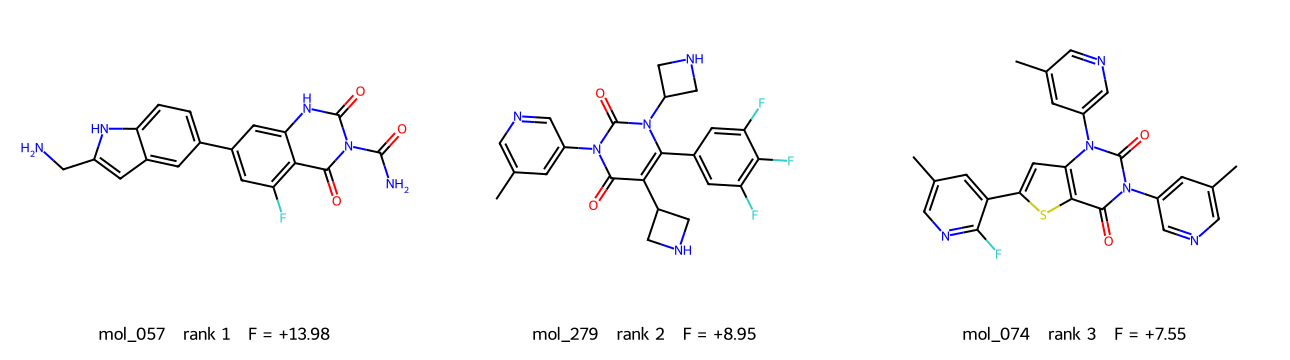

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_8.png`</sub>

In [25]:
# ============================================================
# Figure 8 · Tier 1 三者的二维结构                      （§3.5.1）
# ============================================================
# 一篇推荐化合物的文章，通篇没有一幅结构图，是说不过去的。
# **身份、名次、分数皆取自 Table 3，不另写死。**
if not HAVE_RDKIT:
    print("  跳过（RDKit 不在本环境中）。")
else:
    T1IDS = [str(x) for x in K.loc[K["tier"].astype(str).str.replace(" ", "") == "Tier1", kid]]
    T1IDS = sorted(T1IDS, key=lambda m: RANKOF[m])
    FSCORE = dict(zip(K[kid].astype(str), pd.to_numeric(K[kf], errors="raise")))
    print("  Tier 1: %s" % ", ".join(T1IDS))
    labs = ["%s   rank %d   F = %+.2f" % (m.replace("pool_mol_", "mol_"), RANKOF[m],
                                         FSCORE[m]) for m in T1IDS]
    outp = os.path.join(OUTDIR, "Figure_8.png")
    n, nr = draw_grid(T1IDS, labs, ncol=len(T1IDS), outpath=outp,
                      cell=(430, 360), legend_fs=17)
    print("  画成 %d 个结构，%d 行" % (n, nr))
    CAPTIONS.append(("Figure", "8",
        "Two-dimensional structures of the three Tier-1 candidates, in composite rank order, "
        "with the rank and the score F(Γ) carried by Table 3. The structures are drawn "
        "from the SMILES recorded for each candidate in the generation scope table, so what is "
        "shown is the identity that entered simulation and scoring, not a redrawn or "
        "standardized form of it. No experimental activity is reported for any of the three; "
        "they are computational candidates (§4.5)."))
    apng = saved(outp, "300 dpi 以上，RDKit Cairo 直出")
    apdf = saved(os.path.splitext(outp)[0] + ".pdf",
                 "矢量，自 RDKit SVG 后端转出；投稿以此为佳")
    _show_md("**Figure 8.** %s" % CAPTIONS[-1][2])
    _show_png(apng, 760)
    _show_md("<sub>已存 · `%s`</sub>" % apng)

In [26]:
# 并入自 cell_toc.py（2026-11-20）
# ============================================================
# TOC 图文摘要 · 三联审计记分卡                      （§3.2 · §3.4 · §3.6）
# ============================================================
# 2026-11-21：新标题许诺三层审计，旧 TOC 只画第一层，故重制为三联。
# 本单元一个数值也不键入：
#   面板 1  results/aud_main_site_occupancy.csv            （99 行逐副本，自带 rmsd_lig 一列）
#   面板 2  Scoring/solv_alt_2026-11-16/ 三份逐副本档       （与 Figure 7B 同源）
#   面板 3  results/aud_cross_site_occupancy_series/*.npz ＋ F(Γ) 排序档
#
# ⚠ 不走 save_fig：它用 bbox_inches="tight" 且 dpi=300，会裁掉画布，
#    而 ACS 的 8.25 × 4.45 cm 必须逐毫米交付。故本单元自行落盘。
# ⚠ 整幅包在函数里，其局部一个也不外泄。

def _toc_graphic():
    import csv, io, os, itertools          # 笔记本单元 1 未 import
    import statistics as _st
    import matplotlib as _mpl
    import matplotlib.text as mtext
    from matplotlib.lines import Line2D

    TEAL, VERM, GREY, INK = "#0072B2", "#D55E00", "#BBBBBB", "#1a1a1a"
    PT_D, PT_H, PT_T, PT_F = 6.0, 7.0, 7.2, 6.0
    PT_FLOOR = 6.0                          # ACS 下限 4.5；此处自设更严
    W_CM, H_CM = 8.25, 4.45                 # ACS TOC 画布
    AVI, ENS = "ref_AVI_1084__6W63__primary", "ref_ensitrelvir__6W63__primary"

    # ── 面板 1：主臂 99 条逐副本 ────────────────────────────────────
    _p1 = resolve("主臂占有率", ["results/aud_main_site_occupancy.csv"])
    P1 = [(float(r["rmsd_lig_mean_from_phase4"]), float(r["site_occupancy"]))
          for r in csv.DictReader(io.open(_p1, encoding="utf-8"))]
    if len(P1) != 99:
        raise AssertionError("主臂占有率须 99 行，实得 %d" % len(P1))
    N_HELD = sum(1 for a, b in P1 if a > 5.0 and b >= 0.50)   # 现算（稿载 41）

    # ── 面板 2：三个配置的 ΔΔG，与 Figure 7B 同源、同法 ─────────────
    def _pair_delta(path, col):
        g = {}
        for r in csv.DictReader(io.open(path, encoding="utf-8")):
            g.setdefault(r["system"], []).append(float(r[col]))
        for k, v in g.items():
            if len(v) != 3:
                raise AssertionError("%s 的 %s 不是 3 个副本，实得 %d" % (path, k, len(v)))
        return _st.mean(g[ENS]) - _st.mean(g[AVI])            # 强者减弱者

    _pb  = resolve("参考臂 PB 逐副本 TOTAL",
                   ["Scoring/solv_alt_2026-11-16/ref_panel_PB_per_replica_TOTAL.csv"])
    _in1 = resolve("参考臂 PB inp=1 逐副本",
                   ["Scoring/solv_alt_2026-11-16/B_inp1_per_replica_TOTAL.csv"])
    _gb  = resolve("参考臂 GB igb=5 逐副本",
                   ["Scoring/solv_alt_2026-11-16/A_gb_per_replica_TOTAL.csv"])
    BARS = [("PB inp=2", _pair_delta(_pb,  "TOTAL"),      VERM),
            ("PB inp=1", _pair_delta(_in1, "inp1_TOTAL"), TEAL),
            ("GB igb=5", _pair_delta(_gb,  "GB_TOTAL"),   TEAL)]
    # 颜色即判读：向左（负）为恢复实验次序，向右（正）为反序。须与实际符号相符。
    for _lab, _v, _c in BARS:
        if (_v > 0) != (_c == VERM):
            raise AssertionError("%s 的符号 %+0.2f 与配色不符" % (_lab, _v))

    # ── 面板 3：跨正构酶臂（与 cell_figdata 的 held() 同源、同法）────
    #   出处是逐帧二联体距离档本身，不是某张汇总 CSV：
    #   占有率 = (d_dyad <= DCUT).mean()，低于 GATE 即判失位。
    #   档名之式见 Figure 3：pool_mol_034__6W63__primary__r2.npz
    DCUT, GATE = 5.0, 0.50                      # 与 cell_figdata · Figure 3 同值
    _ser = resolve_many("跨臂逐帧二联体距离",
                        "results/aud_cross_site_occupancy_series/*.npz", expect=36)
    _pr = resolve("F(\u0393) 排序", ["results/step8d_compass_ranking_SOLV_V3.csv"])
    _rk_rows = list(csv.DictReader(io.open(_pr, encoding="utf-8")))
    _rk_col = next((c for c in ("rank_COMPASS", "rank", "COMPASS_rank")
                    if c in _rk_rows[0]), None)
    if _rk_col is None:
        raise AssertionError("排序档无名次列，实有：%s" % list(_rk_rows[0]))
    RANK = {r["mol_id"]: int(float(r[_rk_col])) for r in _rk_rows}
    TG = ["3V3M", "4YLU"]
    lost = {}
    for _p in _ser:
        _b = os.path.basename(_p)
        _parts = _b.split("__")
        if len(_parts) < 2:
            raise AssertionError("跨臂档名不合 <mol>__<target>__… 之式：%s" % _b)
        _mid, _tgt = _parts[0], _parts[1]
        if _tgt not in TG:
            raise AssertionError("跨臂档名第二段非 3V3M/4YLU：%s" % _b)
        if _mid not in RANK:
            raise AssertionError("跨臂化合物 %s 不在 F(\u0393) 排序档中" % _mid)
        _z = np.load(_p, allow_pickle=True)
        _arr = np.asarray(_z["d_dyad"] if "d_dyad" in _z.files else _z[_z.files[0]])
        _occ = float((_arr <= DCUT).mean())
        _key = (RANK[_mid], _tgt)
        lost[_key] = lost.get(_key, 0) + (0 if _occ >= GATE else 1)
    if len(lost) != 12:
        raise AssertionError("跨正构酶臂须 12 个配对，实得 %d" % len(lost))
    N_LOST = sum(lost.values())                 # 现算（稿载 5）
    RANKS = sorted({k[0] for k in lost})
    if len(RANKS) != 6:
        raise AssertionError("跨臂须 6 个化合物，实得 %d" % len(RANKS))

    # ── 作图 ────────────────────────────────────────────────────────
    _rc = {"font.family": "Arial", "font.size": PT_D, "axes.linewidth": 0.5,
           "xtick.major.width": 0.5, "ytick.major.width": 0.5,
           "xtick.major.size": 1.4, "ytick.major.size": 1.4,
           "xtick.major.pad": 1.0, "ytick.major.pad": 1.0,
           "pdf.fonttype": 42, "ps.fonttype": 42}
    _avail = {f.name for f in _mpl.font_manager.fontManager.ttflist}
    for _cand in ("Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"):
        if _cand in _avail:
            _rc["font.family"] = _cand; break
    with _mpl.rc_context(_rc):
        CM = 1 / 2.54
        fig = plt.figure(figsize=(W_CM*CM, H_CM*CM), dpi=600)
        fig.patch.set_facecolor("white")
        fig.text(0.5, 0.955, "A three-level audit of post-docking MD rescoring",
                 ha="center", va="center", fontsize=PT_T, fontweight="bold", color=INK)
        fig.text(0.5, 0.040,
                 "Prescription:  an occupancy gate outside the score + a pre-registered external anchor",
                 ha="center", va="center", fontsize=PT_F, color=INK)
        L, R, B, T, GAP = 0.085, 0.990, 0.300, 0.720, 0.062
        W = (R - L - 2*GAP) / 3.0
        ax1, ax2, ax3 = [fig.add_axes([L + i*(W+GAP), B, W, T-B]) for i in range(3)]
        for i in (1, 2):
            _x = L + i*(W+GAP) - GAP/2
            fig.add_artist(Line2D([_x, _x], [0.105, 0.895], lw=0.5, color=GREY))
        def _head(ax, a, b):
            ax.set_title("%s\n%s" % (a, b), fontsize=PT_H, fontweight="bold",
                         pad=4.0, color=INK, linespacing=1.1)

        # 面板 1
        _head(ax1, "1  Descriptor", "validity")
        XMAX = 12.6
        k  = [(a, b) for a, b in P1 if b >= 0.50]
        lo = [(a, b) for a, b in P1 if b < 0.50]
        far = [(a, b) for a, b in lo if a > XMAX]; near = [(a, b) for a, b in lo if a <= XMAX]
        if len(far) != 1:
            raise AssertionError("面板 1 预期恰 1 个离群点越出 %.1f Å，实得 %d" % (XMAX, len(far)))
        ax1.scatter([a for a, _ in k], [b for _, b in k], s=1.6, c=TEAL, lw=0, alpha=.85, zorder=3)
        ax1.scatter([a for a, _ in near], [b for _, b in near], s=5.5, c=VERM, lw=0, marker="X", zorder=4)
        ax1.scatter([XMAX-0.45], [far[0][1]], s=5.5, c=VERM, lw=0, marker="X", zorder=4, clip_on=False)
        ax1.annotate("", xy=(XMAX+0.05, far[0][1]), xytext=(XMAX-0.95, far[0][1]),
                     arrowprops=dict(arrowstyle="-|>,head_width=0.07,head_length=0.16",
                                     lw=0.5, color=VERM, shrinkA=0, shrinkB=0),
                     zorder=4, annotation_clip=False)
        ax1.text(XMAX-1.05, far[0][1]+0.085, "%.1f" % far[0][0], ha="right", va="bottom",
                 fontsize=PT_D, color=VERM)
        ax1.axvline(5.0, ls=(0, (2, 1.5)), lw=.6, color="#555555", zorder=2)
        ax1.set_xlim(0.0, XMAX); ax1.set_ylim(-0.10, 1.30)
        ax1.set_xticks([0, 5, 10]); ax1.set_xticklabels(["0", "5", "10"], fontsize=PT_D)
        ax1.set_yticks([0, 1]); ax1.set_yticklabels(["0", "1"], fontsize=PT_D)
        ax1.text(0.05, 0.60, "%d of 99 past 5 Å\nstill held" % N_HELD,
                 transform=ax1.transAxes, ha="left", va="center", fontsize=PT_D,
                 color=TEAL, linespacing=1.1,
                 bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=0.4))
        ax1.set_xlabel("ligand RMSD (Å)", fontsize=PT_D, labelpad=0.6)
        ax1.set_ylabel("occupancy", fontsize=PT_D, labelpad=0.6)
        for s in ("top", "right"): ax1.spines[s].set_visible(False)

        # 面板 2
        _head(ax2, "2  Potency", "calibration")
        for y, (lab, val, col) in zip([2, 1, 0], BARS):
            ax2.barh(y, val, height=0.40, color=col, lw=0)
            ax2.text(val + (0.6 if val > 0 else -0.6), y, "%+.2f" % val, va="center",
                     ha="left" if val > 0 else "right", fontsize=PT_D, color=col, fontweight="bold")
            ax2.text(-0.5 if val > 0 else 0.5, y, lab, va="center",
                     ha="right" if val > 0 else "left", fontsize=PT_D, color="#333333")
        ax2.axvline(0, ymin=0.0, ymax=0.86, lw=.6, color="#555555")
        ax2.set_yticks([]); ax2.set_xticks([])
        ax2.set_xlim(-12.0, 15.0); ax2.set_ylim(-1.15, 2.95)
        ax2.text(0.5, 0.995, "same frames, one pair", transform=ax2.transAxes,
                 ha="center", va="top", fontsize=PT_D, color="#444444")
        ax2.text(0.0, 0.015, "← ok", transform=ax2.transAxes, ha="left",
                 va="bottom", fontsize=PT_D, color=TEAL)
        ax2.text(1.0, 0.015, "inverted →", transform=ax2.transAxes, ha="right",
                 va="bottom", fontsize=PT_D, color=VERM)
        ax2.set_xlabel("ΔΔG (kcal/mol)", fontsize=PT_D, labelpad=0.6)
        for s in ("top", "right", "left", "bottom"): ax2.spines[s].set_visible(False)
        ax2.tick_params(axis="y", length=0)

        # 面板 3
        _head(ax3, "3  Cross-ortholog", "transfer")
        for j, tg in enumerate(TG):
            for i, rk in enumerate(RANKS):
                if lost[(rk, tg)] == 0: ax3.plot(j, i, "o", ms=3.0, mfc=TEAL, mec=TEAL, mew=0)
                else:                   ax3.plot(j, i, "X", ms=4.2, mfc=VERM, mec=VERM, mew=0)
        ax3.set_xlim(-0.75, 1.75); ax3.set_ylim(-1.35, len(RANKS)-0.3)
        ax3.set_xticks([0, 1]); ax3.set_xticklabels(TG, fontsize=PT_D)
        ax3.set_yticks(range(len(RANKS)))
        ax3.set_yticklabels([str(r) for r in RANKS], fontsize=PT_D)
        ax3.invert_yaxis()
        ax3.text(0.5, 0.995, "%d of 36 replicas lost" % N_LOST, transform=ax3.transAxes,
                 ha="center", va="top", fontsize=PT_D, color=VERM)
        ax3.set_xlabel("ortholog", fontsize=PT_D, labelpad=0.6)
        ax3.set_ylabel("rank", fontsize=PT_D, labelpad=0.6)
        for s in ("top", "right", "left", "bottom"): ax3.spines[s].set_visible(False)
        ax3.tick_params(axis="both", length=0)

        # ── 三道断言：字号下限 · 文字相叠 · 越栏 ──────────────────
        fig.canvas.draw(); _r = fig.canvas.get_renderer()
        texts = []
        def _walk(o):
            if isinstance(o, mtext.Text) and (o.get_text() or "").strip(): texts.append(o)
            for c in getattr(o, "get_children", lambda: [])(): _walk(c)
        _walk(fig)
        _worst = min(t.get_fontsize() for t in texts)
        if _worst < PT_FLOOR - 1e-9:
            raise AssertionError("TOC 最小字号 %.2f pt，低于下限 %.2f" % (_worst, PT_FLOOR))
        _bx = [(t, t.get_window_extent(renderer=_r)) for t in texts]
        _pad = 0.6 * fig.dpi / 72.0
        for (t1, b1), (t2, b2) in itertools.combinations(_bx, 2):
            if (b1.x1-_pad > b2.x0 and b2.x1-_pad > b1.x0 and
                b1.y1-_pad > b2.y0 and b2.y1-_pad > b1.y0):
                raise AssertionError("TOC 文字相叠：%r 与 %r"
                                     % (t1.get_text()[:24], t2.get_text()[:24]))
        for ax, i in ((ax1, 0), (ax2, 1), (ax3, 2)):
            _x0 = (L + i*(W+GAP)) * fig.bbox.x1; _x1 = (L + i*(W+GAP) + W) * fig.bbox.x1
            for t in [tt for tt in texts if tt.axes is ax]:
                b = t.get_window_extent(renderer=_r)
                if b.x0 < _x0 - 1.0 or b.x1 > _x1 + 1.0:
                    raise AssertionError("TOC 标注 %r 越出第 %d 栏" % (t.get_text()[:24], i+1))
        _w, _h = fig.get_size_inches()
        if abs(_w*2.54 - W_CM) > 1e-6 or abs(_h*2.54 - H_CM) > 1e-6:
            raise AssertionError("TOC 画布 %.3f × %.3f cm，须 %.2f × %.2f"
                                 % (_w*2.54, _h*2.54, W_CM, H_CM))

        # ── 落盘：绝不经 save_fig（其 bbox_inches="tight" 会裁掉画布）──
        _png = os.path.join(OUTDIR, "TOC_graphic.png")
        _pdf = os.path.join(OUTDIR, "TOC_graphic.pdf")
        fig.savefig(_png, dpi=600, facecolor="white")
        fig.savefig(_pdf, facecolor="white")
        print("  TOC → %s  （%.2f × %.2f cm · 最小字号 %.2f pt · %d 条轨迹保持 · %d 条失位）"
              % (os.path.basename(_png), _w*2.54, _h*2.54, _worst, N_HELD, N_LOST))
        return fig

_toc = _toc_graphic()


  [主臂占有率] results/aud_main_site_occupancy.csv
  [参考臂 PB 逐副本 TOTAL] Scoring/solv_alt_2026-11-16/ref_panel_PB_per_replica_TOTAL.csv
  [参考臂 PB inp=1 逐副本] Scoring/solv_alt_2026-11-16/B_inp1_per_replica_TOTAL.csv
  [参考臂 GB igb=5 逐副本] Scoring/solv_alt_2026-11-16/A_gb_per_replica_TOTAL.csv
  [跨臂逐帧二联体距离] results/aud_cross_site_occupancy_series/*.npz → 36 个
  [F(Γ) 排序] results/step8d_compass_ranking_SOLV_V3.csv
  TOC → TOC_graphic.png  （8.25 × 4.45 cm · 最小字号 6.00 pt · 41 条轨迹保持 · 5 条失位）


In [27]:
# ============================================================
# Table S14 · 与 PRISM-Gen 36 个终选候选的重合度比对          （§2.1 · §6）
# ============================================================
# 两文既可并读，读者必问「这 31 个是不是那 36 个」。分子编号定不了此事
# （`mol_0`–`mol_35` 对 `pool_mol_*` 是命名之别，不是化学之别），
# 故此处以**规范 SMILES 与 InChIKey 两把钥匙**比对，两者须给出同一答案。
# GEN36 的来源：PRISM-Gen 的 `prismgen_step5b_final_candidates.csv`（36 行），
# 其 `smiles` 列已在此处以 RDKit 规范化并连同 InChIKey 一并写死，
# 使本 cell 不依赖该文件是否在本机。
if not HAVE_RDKIT:
    print("  跳过（RDKit 不在本环境中）—— 本比对须 RDKit。")
else:
    from rdkit.Chem.inchi import MolToInchiKey
GEN36 = [
    ("mol_16", "NC(=O)Cc1ccc(-c2ccc(N3C(=O)CC4(CCCCC4)C3=O)cc2)cc1", "LUVOSTFVVKLDTD-UHFFFAOYSA-N"),
    ("mol_3", "NC(=O)Cc1ccc(-c2ccc(Cc3cc(CC(N)=O)ccn3)cc2)cc1", "ZWLYHLIZGMYWTF-UHFFFAOYSA-N"),
    ("mol_13", "CC(C)(C)c1ccc(-c2cc(Cc3cc(CC(N)=O)ccn3)ccn2)cc1", "WFMIJBXOKWTOKF-UHFFFAOYSA-N"),
    ("mol_22", "Cc1ccc(/C=C\\c2ccc(/C=C\\c3c[nH]c(=O)[nH]c3=O)cc2)cc1F", "LHSIJQYVTIKUMC-XESWYYRISA-N"),
    ("mol_18", "C#CCc1ccnc(-c2ccnc(-c3ccnc(CC(N)=O)c3)c2)c1", "SNYZUDRAHOQDCS-UHFFFAOYSA-N"),
    ("mol_1", "NC(=O)Cc1ccc(Cc2ccc(-c3ccc(CC(N)=O)cc3)cc2)cc1", "LEWDTEZSAIINFN-UHFFFAOYSA-N"),
    ("mol_28", "NC(=O)Cc1ccnc(-c2ccc(Cc3ccccn3)c(C=O)c2)c1", "DMPLWBIXORPDTI-UHFFFAOYSA-N"),
    ("mol_8", "NC(=O)CCc1ccc(Cc2ccc(Cc3ccc(CC(N)=O)cc3)cc2)cc1", "JIGVCLDUEBIZQV-UHFFFAOYSA-N"),
    ("mol_2", "NC(=O)CCc1ccc(CCc2ccc(Cc3ccc(CC(N)=O)cc3)cc2)cc1", "ISSCMWRFTNYGKX-UHFFFAOYSA-N"),
    ("mol_9", "NC(=O)Cc1ccc(Cc2ccc(-c3cc(CC(N)=O)ccn3)cc2)cc1", "REWMRVVYFPUURO-UHFFFAOYSA-N"),
    ("mol_26", "O=C(c1ccc([C@@H]2CCS(=O)(=O)C2)cc1)c1ccc(F)c(F)c1", "BRRJXQVWOAEDEQ-CQSZACIVSA-N"),
    ("mol_0", "NC(=O)Cc1ccc(-c2ccc(-c3ccc(CC(N)=O)cc3)cc2)cc1", "RXTXIBIXHCJCSD-UHFFFAOYSA-N"),
    ("mol_33", "NC(=O)CCc1ccc(Cc2ccc(CCc3ccc(CC(N)=O)cc3)cc2)cc1", "WIZYQJIFPWILKL-UHFFFAOYSA-N"),
    ("mol_5", "NC(=O)CCc1ccc(-c2ccc(CC(N)=O)cc2)cc1CC(N)=O", "RYZLVSGMRFILNM-UHFFFAOYSA-N"),
    ("mol_10", "NC(=O)Cc1ccc(-c2ccc(Cc3nc(CC(N)=O)cs3)cc2)cc1", "RKODYMBLHVLVSA-UHFFFAOYSA-N"),
    ("mol_14", "NC(=O)Cc1ccc(-c2ccc(-c3nc(CC(N)=O)cs3)cc2)cc1", "PODLSPDEWCLQHK-UHFFFAOYSA-N"),
    ("mol_25", "Cc1nonc1S(=O)(=O)c1ccc(C(=O)N2CCCCCCC2)cc1", "KHOHLFWQDRXFDI-UHFFFAOYSA-N"),
    ("mol_29", "NC(=O)Cc1cc(Cc2cc(C=O)ccn2)ccc1-c1ccccn1", "AJELXNBMQRNKHU-UHFFFAOYSA-N"),
    ("mol_19", "NC(=O)Cc1ccc(/C=C\\C=C/c2cc(CC(N)=O)ccn2)cc1", "ZBYHKYTUIHXULL-CCAGOZQPSA-N"),
    ("mol_35", "CCCc1ccc(-c2ccc(CC(N)=O)cc2CC(N)=O)cc1", "KIRSNWDHSLHKOD-UHFFFAOYSA-N"),
    ("mol_24", "COCc1ccc(-c2cc(CCc3ccc(CC(N)=O)o3)ccn2)cc1", "UPWYIEFTYXNKGJ-UHFFFAOYSA-N"),
    ("mol_4", "NC(=O)Cc1ccc(CCCc2ccc(Cc3ccc(CC(N)=O)cc3)cc2)cc1", "PTPCUXMXHNQTPX-UHFFFAOYSA-N"),
    ("mol_31", "NC(=O)CCc1ccc(Cc2ccc(CCC(N)=O)cc2)cc1", "SPUCMRBJAKHUEH-UHFFFAOYSA-N"),
    ("mol_7", "NC(=O)CCc1ccc(CCc2nc(CC(N)=O)cs2)cc1", "MDDRSLLYVZRVKE-UHFFFAOYSA-N"),
    ("mol_12", "CC(C)(C)c1ccc(CCc2nc(CCC(N)=O)cs2)cc1", "NOVHRAZRDUZUAX-UHFFFAOYSA-N"),
    ("mol_11", "CCc1ccc(Cc2cc(OC(=O)COCC(N)=O)ccn2)cc1", "YIUPAWMJELUXFK-UHFFFAOYSA-N"),
    ("mol_6", "Cc1nnc(S(=O)(=O)c2ccc(NC(=O)C(C)C)cc2)s1", "GRNDMSLCLPNNMA-UHFFFAOYSA-N"),
    ("mol_15", "COCc1ccc(Cc2ccc(CCC(=O)C(C)(C)OC)cc2)cc1", "LBESEHNPKSJKQJ-UHFFFAOYSA-N"),
    ("mol_21", "COc1cc(C(=O)N(CC(N)=O)c2ccc(F)c(F)c2)ccn1", "FOZNJQHPQOSJHS-UHFFFAOYSA-N"),
    ("mol_23", "NC(=O)CCCc1ccc(CCCc2ccc(C=O)cc2)cc1", "HIXCCNMPCPMBBL-UHFFFAOYSA-N"),
    ("mol_17", "CS(=O)(=O)CCc1csc(-c2ccc(CCC(N)=O)cc2)n1", "LTTJRYIPPVPRHA-UHFFFAOYSA-N"),
    ("mol_32", "Cc1ccc(/C=C\\c2nccnc2CS(=O)(=O)C(C)C)cc1C", "CJDPVYJFDSGLNM-FPLPWBNLSA-N"),
    ("mol_20", "CC(=O)C1(NCN2CCN(C(=O)OC(C)C)CC2)CCCCC1", "XJTDZKBNMRRHQF-UHFFFAOYSA-N"),
    ("mol_34", "NC(=O)Cc1ccc(CCCCc2ccc(CC(N)=O)cc2)cc1", "SEJMFTKQWGUVFD-UHFFFAOYSA-N"),
    ("mol_27", "CC(C)(C)CCc1cc([C@@H](N)Cc2cccnc2Cl)ccn1", "ANCUDZSUZMBQDS-INIZCTEOSA-N"),
    ("mol_30", "COc1ccc(C(=O)SCC(=O)Nc2csc(C)n2)cc1", "RBXZVGOHVURKRF-UHFFFAOYSA-N"),
]

if HAVE_RDKIT:
    if len(GEN36) != 36: raise AssertionError("GEN36 应为 36 条，实为 %d" % len(GEN36))
    gen_cs = {c: n for n, c, k in GEN36}
    gen_ik = {k: n for n, c, k in GEN36}
    if len(gen_cs) != 36 or len(gen_ik) != 36:
        warn("Table S14：PRISM-Gen 的 36 条在规范化之后不再两两相异（SMILES %d · InChIKey %d）。"
             % (len(gen_cs), len(gen_ik)))

    ids31 = list(K.sort_values(kr)[kid].astype(str))
    rows14, nbad = [], 0
    for m in ids31:
        smi = SMI.get(m)
        if smi is None:
            warn("Table S14：%s 在 scope 表中无 SMILES。" % m); nbad += 1; continue
        mo = Chem.MolFromSmiles(smi)
        if mo is None:
            warn("Table S14：%s 的 SMILES 解析失败。" % m); nbad += 1; continue
        cs, ik = Chem.MolToSmiles(mo), MolToInchiKey(mo)
        rows14.append({"mol_id": m, "COMPASS_rank": RANKOF[m],
                       "canonical_smiles": cs, "inchikey": ik,
                       "match_by_smiles": gen_cs.get(cs, ""),
                       "match_by_inchikey": gen_ik.get(ik, "")})
    M14 = pd.DataFrame(rows14)
    expect_rows(M14, 31 - nbad, "31 个打分候选（解析失败者除外）")

    hit_s = M14.match_by_smiles.astype(bool)
    hit_i = M14.match_by_inchikey.astype(bool)
    if not (hit_s == hit_i).all():
        warn("Table S14：规范 SMILES 与 InChIKey 两把钥匙给出的答案不一致，"
             "不一致者 %d 个 —— 须逐条查清，勿据任一单独下结论。"
             % int((hit_s != hit_i).sum()))
    n_hit = int(hit_i.sum())
    print("  31 个打分候选中，与 PRISM-Gen 的 36 个终选重合者：**%d 个**" % n_hit)
    print("  （两把钥匙：规范 SMILES 命中 %d · InChIKey 命中 %d）"
          % (int(hit_s.sum()), int(hit_i.sum())))
    if n_hit:
        for _, r in M14[hit_i].iterrows():
            print("     %-14s (rank %2d)  ←→  %s" % (r.mol_id, r.COMPASS_rank,
                                                     r.match_by_inchikey))
    print("\n  ===== 可直接入稿的一句（以实测为准）=====")
    if n_hit == 0:
        print('     "No molecule in the 31-candidate cohort simulated here is among the 36 '
              'final broad-spectrum candidates reported by the generative campaign '
              '(Wang et al., 2026): the two sets are disjoint on canonical SMILES and on '
              'InChIKey. The 31 were drawn from the same pool by the stratified rule of '
              '§2.3.1, not from that campaign\'s final selection."')
    else:
        print('     "Of the 31 candidates simulated here, %d are among the 36 final '
              'broad-spectrum candidates reported by the generative campaign '
              '(Wang et al., 2026); the remaining %d are not. Overlap was determined on '
              'canonical SMILES and confirmed on InChIKey." — 并列出重合者之名'
              % (n_hit, len(M14) - n_hit))

    save_table(M14, "S14",
               "Chemical-identity comparison between the 31 candidates simulated in this work "
               "and the 36 final broad-spectrum candidates reported by the generative campaign "
               "(Wang et al., 2026). Identity is established on canonical SMILES and "
               "independently on InChIKey; the two keys are reported side by side because "
               "molecule numbering cannot settle the question — the two works use "
               "unrelated naming schemes, so non-overlapping identifiers do not establish "
               "non-overlapping chemistry. An empty match column means the candidate is not "
               "among the 36.")

  条数 31 ✓  (31 个打分候选（解析失败者除外）)
  31 个打分候选中，与 PRISM-Gen 的 36 个终选重合者：**0 个**
  （两把钥匙：规范 SMILES 命中 0 · InChIKey 命中 0）

  ===== 可直接入稿的一句（以实测为准）=====
     "No molecule in the 31-candidate cohort simulated here is among the 36 final broad-spectrum candidates reported by the generative campaign (Wang et al., 2026): the two sets are disjoint on canonical SMILES and on InChIKey. The 31 were drawn from the same pool by the stratified rule of §2.3.1, not from that campaign's final selection."
  → Table_S14  (.csv + .md)   31 行 × 6 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S14.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S14.md


**Table S14.** Chemical-identity comparison between the 31 candidates simulated in this work and the 36 final broad-spectrum candidates reported by the generative campaign (Wang et al., 2026).

| mol_id       | COMPASS_rank | canonical_smiles                                                                        | inchikey                    | match_by_smiles | match_by_inchikey |
|:-------------|-------------:|:----------------------------------------------------------------------------------------|:----------------------------|:----------------|:------------------|
| pool_mol_057 |            1 | NCc1cc2cc(-c3cc(F)c4c(=O)n(C(N)=O)c(=O)[nH]c4c3)ccc2[nH]1                               | VCVILMQXFUZXKY-UHFFFAOYSA-N |                 |                   |
| pool_mol_279 |            2 | Cc1cncc(-n2c(=O)c(C3CNC3)c(-c3cc(F)c(F)c(F)c3)n(C3CNC3)c2=O)c1                          | HOONQDKBXNCPRQ-UHFFFAOYSA-N |                 |                   |
| pool_mol_074 |            3 | Cc1cncc(-n2c(=O)c3sc(-c4cc(C)cnc4F)cc3n(-c3cncc(C)c3)c2=O)c1                            | NHFWDUHMSYCTJM-UHFFFAOYSA-N |                 |                   |
| pool_mol_012 |            4 | Cc1cncc(-n2c(=O)n(-c3cc(C)cnc3F)c(=O)c3sc(-c4cc(C)cnc4F)cc32)c1                         | JFQSWPXWBRLQDR-UHFFFAOYSA-N |                 |                   |
| pool_mol_004 |            5 | O=c1[nH]c(Cc2cccc(-c3nc4cc(O)c(O)c(O)c4c(=O)[nH]3)c2)nc2cc(O)c(O)c(O)c12                | RHQNZVRWEOAATM-UHFFFAOYSA-N |                 |                   |
| pool_mol_016 |            6 | Cc1nc(-c2c(C)cccc2C(=O)Nc2cccc(C)c2-c2nc3cc(O)c(O)c(O)c3c(=O)[nH]2)n[nH]1               | VGYIDDDIFWLDKG-UHFFFAOYSA-N |                 |                   |
| pool_mol_009 |            7 | NC(=O)Cc1ccnc(-c2cc(-c3cc(CC(N)=O)ccn3)c(O)c(-c3cc(CC(N)=O)ccn3)c2)c1                   | IHUJSJCRNMMHJO-UHFFFAOYSA-N |                 |                   |
| pool_mol_017 |            8 | C[C@@H]1CN(c2cncc(-c3cncc(-c4cncc(N5C[C@@H](C)N[C@@H](C)C5)c4)c3)c2)C[C@H](C)N1         | ZVZCHSSMNIXMNG-FXELSEDVSA-N |                 |                   |
| pool_mol_029 |            9 | Cc1cncc(-n2c(=O)c3sc(-c4cncc(F)c4)cc3n(-c3cncc(F)c3)c2=O)n1                             | ZJYRGUIIHJCCMC-UHFFFAOYSA-N |                 |                   |
| pool_mol_024 |           10 | O=C(Cc1cncc(F)c1)n1c(=O)n(-c2cncc(F)c2)c(=O)c2sc(-c3cncc(F)c3)cc21                      | VWSQRSVIMPHXPG-UHFFFAOYSA-N |                 |                   |
| pool_mol_019 |           11 | Cc1ccc(C(=O)c2cc(-c3ccc(C)c(C(N)=O)c3)ccc2C)cc1C(N)=O                                   | WSDIHGBZKBGAFK-UHFFFAOYSA-N |                 |                   |
| pool_mol_003 |           12 | NC(=O)Cc1ccnc(-c2nc(-c3ccnc(CC(N)=O)c3)sc2-c2cc(F)c([O-])c(F)c2)c1                      | YLYUPTLEPBJQQS-UHFFFAOYSA-M |                 |                   |
| pool_mol_005 |           13 | O=c1[nH]c(-c2cccc(-c3cccc(-c4cccnc4)c3)c2)nc2cc(O)c(O)c(O)c12                           | YCIICLDLWDIROB-UHFFFAOYSA-N |                 |                   |
| pool_mol_013 |           14 | O=C(c1cccc(F)c1)c1cccc(-c2nc3cc(O)c(O)c(O)c3c(=O)[nH]2)c1                               | DWJCSQXVTQBSOD-UHFFFAOYSA-N |                 |                   |
| pool_mol_031 |           15 | NCc1ncc(-c2cccc(-c3ccc(-c4cccc(C(=O)c5ccc[nH]c5=O)c4)[nH]3)c2)cn1                       | KFMWDWACSLAGLZ-UHFFFAOYSA-N |                 |                   |
| pool_mol_020 |           16 | O=C1NC(=O)[C@@H]2C=C(c3cncc(-c4cncc(C5=C[C@H]6C(=O)NC(=O)[C@H]56)c4)c3)[C@@H]12         | NGWZFUOJLUTQMR-BRSBDYLESA-N |                 |                   |
| pool_mol_030 |           17 | C[C@H](C(=O)NC1CNC1)c1cncc(C(=O)c2cncc(-c3cncc(N4C[C@H](C)N(C5CNC5)[C@@H](C)C4)c3)c2)c1 | ZOCGDIJXDIWTBP-ACRUOGEOSA-N |                 |                   |
| pool_mol_034 |           18 | NC(=O)Cc1ccnc(-c2cc(-c3cc(CC(N)=O)ccn3)c(O)c(-c3ccc(CC(N)=O)cc3F)c2)c1                  | BAJWCVLAOQBZAN-UHFFFAOYSA-N |                 |                   |
| pool_mol_243 |           19 | O=C(NC(=O)c1ccc(F)c(-c2ccc(F)c(C(=O)O)c2)c1)c1cncnc1                                    | BZQIBLNNJKMXBL-UHFFFAOYSA-N |                 |                   |
| pool_mol_006 |           20 | NC(=O)Cc1ccnc(-c2cc(CC(N)=O)c(O)c(-c3ccnc(-c4cc(CC(N)=O)ccn4)c3)c2)c1                   | JGMFQDHSRVLCKX-UHFFFAOYSA-N |                 |                   |
| pool_mol_021 |           21 | O=c1[nH]c2cc(S(=O)(=O)c3ccc4[nH]ccc4c3)cc(F)c2c(=O)n1-c1cncc(-c2cnoc2)c1                | RHLWRKGBMMPEKV-UHFFFAOYSA-N |                 |                   |
| pool_mol_001 |           22 | CNC(=O)c1cc(C(=O)NC(=O)c2cccc3cccnc23)cc(-c2cccc3cccnc23)c1                             | QTFOAMWRWCDBGV-UHFFFAOYSA-N |                 |                   |
| pool_mol_007 |           23 | NC(=O)Cc1ccnc(-c2ccnc(-c3cc(-c4ccc(CC(N)=O)cc4F)cc(CC(N)=O)c3O)c2)c1                    | XRZZKUHSAVIDJN-UHFFFAOYSA-N |                 |                   |
| pool_mol_073 |           24 | NC(=O)C(=O)c1cccc(CC(=O)NS(=O)(=O)c2cccc(-c3ccc4ccccc4c3)c2)c1                          | GCFOZNOGVBYUKM-UHFFFAOYSA-N |                 |                   |
| pool_mol_011 |           25 | NC(=O)Cc1ccnc(-c2ccnc(-c3ccnc(-c4cc(-c5cc(CC(N)=O)ccn5)ccn4)c3)c2)c1                    | PGNFKYMHABCFHK-UHFFFAOYSA-N |                 |                   |
| pool_mol_061 |           26 | NC(=O)c1cc(-c2cccc(-c3ccc4c(C(=O)O)cncc4c3)c2)ccc1O                                     | ZLOKKWRWGSNBDU-UHFFFAOYSA-N |                 |                   |
| pool_mol_010 |           27 | NC(=O)Cc1ccnc(-c2ccnc(-c3ccnc(-c4ccnc(-c5ccnc(CC(N)=O)c5)c4)c3)c2)c1                    | QBMIAHDJHASGLF-UHFFFAOYSA-N |                 |                   |
| pool_mol_146 |           28 | Cc1cc(-n2c(=O)c3sc(-c4cncc(C5CCC5)c4)cc3n(-c3cnnc(C)c3)c2=O)cnn1                        | GRKOYSCSIYSCRD-UHFFFAOYSA-N |                 |                   |
| pool_mol_014 |           29 | NC(=O)Cc1cc(Cc2cncc3cccnc23)cc(-c2cncc3cccnc23)c1                                       | QTAYPAIOQNZPKS-UHFFFAOYSA-N |                 |                   |
| pool_mol_120 |           30 | C#Cc1ccnc(-c2ccnc(-c3ccnc(-c4ccnc(C#C)c4)c3)c2)c1                                       | RKBXERZPOCFSJM-UHFFFAOYSA-N |                 |                   |
| pool_mol_022 |           31 | C[C@@H]1CN(c2cncc(-c3cncc(-c4cncc([C@H]5CNC[C@H](C)O5)c4)c3)c2)C[C@H](C)N1              | MLBJPJWGBNVSBL-LNGSLBNHSA-N |                 |                   |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S14.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S14.md`</sub>

In [28]:
# ============================================================
# Table S15 · 与 PRISM-Gen 36 个终选的结构邻近度                （§2.1）
# ============================================================
# Table S14 测的是**分子身份**。身份不交，不等于骨架不交，更不等于化学系列不交。
# 一段拟入稿的文字曾据零重合推出「生成器弃其旧骨架、探入全然不交之结构空间」，
# 并以此为「闭环 BBS 引导按其机理本意奏效」之确证。该推论须以实测裁，故有此 cell。
# 本 cell 测四样，皆不依赖任何外部文件（输入为 GEN36 与 Table S14 所出之 M14）：
#   ① Bemis–Murcko 骨架与通用化骨架，在 31 与 36 之间的重合；
#   ② 跨组 Morgan/Tanimoto：31 个各自对 36 的**最大**相似度；
#   ③ 31 组**内部**之通用骨架冗余——「逃出局部极小」若为真，31 自身不应高度同骨架；
#   ④ 零重合在「什么都没发生」零假设下的概率。
# 第 ④ 项是本 cell 最要紧者：若该概率近 1/2，则零重合几无证据力，
# 任何机理叙事都不能替它添上。
if not HAVE_RDKIT:
    print("  跳过（RDKit 不在本环境中）—— 本比对须 RDKit。")
elif "M14" not in dir():
    print("  跳过：Table S14 未出（M14 不在命名空间内）。本 cell 须置于 Table S14 之后。")
else:
    from rdkit.Chem.Scaffolds import MurckoScaffold
    from rdkit.Chem import rdFingerprintGenerator
    from rdkit import DataStructs
    from math import comb

    # 不借上游任何会被后续 cell 改绑的名字（如 cols）；本 cell 所用者皆在此处取定。
    _MG = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

    def _scaf(mo, generic=False):
        try:
            s = MurckoScaffold.GetScaffoldForMol(mo)
            if generic:
                s = MurckoScaffold.MakeScaffoldGeneric(s)
            k = Chem.MolToSmiles(s)
            return k if k else None
        except Exception:
            return None

    _A, _B = [], []
    for _, r in M14.iterrows():
        mo = Chem.MolFromSmiles(r.canonical_smiles)
        if mo is not None:
            _A.append((str(r.mol_id), int(r.COMPASS_rank), mo))
    for n, c, _k in GEN36:
        mo = Chem.MolFromSmiles(c)
        if mo is not None:
            _B.append((n, mo))
    if len(_A) != len(M14):
        warn("Table S15：本文 %d 个中有 %d 个的规范 SMILES 不能复解析。"
             % (len(M14), len(M14) - len(_A)))
    if len(_B) != len(GEN36):
        warn("Table S15：PRISM-Gen 的 %d 条中有 %d 条不能解析。"
             % (len(GEN36), len(GEN36) - len(_B)))
    print("  解析成功：本文 %d 个 · PRISM-Gen %d 个" % (len(_A), len(_B)))

    # ── ① 骨架重合 ───────────────────────────────────────────────────
    _sc = {}
    for _gen, _lab in ((False, "Bemis-Murcko"), (True, "generic")):
        _sa, _sb = {}, {}
        for n, rk, mo in _A:
            _sa.setdefault(_scaf(mo, _gen), []).append(n)
        for n, mo in _B:
            _sb.setdefault(_scaf(mo, _gen), []).append(n)
        _sa.pop(None, None); _sb.pop(None, None)
        _common = sorted(set(_sa) & set(_sb))
        _sc[_lab] = (len(_sa), len(_sb), len(_common), _common)
        print("  ① %-14s 本文 %2d 个互异骨架 · Gen %2d 个 · **共有 %d 个**"
              % (_lab, len(_sa), len(_sb), len(_common)))
        for k in _common[:6]:
            print("       %-44s 本文 %s ↔ Gen %s"
                  % (k[:44], ",".join(_sa[k]), ",".join(_sb[k])))

    # ── ② 跨组 Tanimoto ──────────────────────────────────────────────
    _fb = [(n, _MG.GetFingerprint(mo)) for n, mo in _B]
    _rows = []
    for n, rk, mo in _A:
        f = _MG.GetFingerprint(mo)
        best, who = max((DataStructs.TanimotoSimilarity(f, g), bn) for bn, g in _fb)
        _rows.append({"mol_id": n, "COMPASS_rank": rk,
                      "nearest_in_gen36": who, "max_tanimoto": round(best, 3)})
    S15 = pd.DataFrame(_rows).sort_values("max_tanimoto", ascending=False).reset_index(drop=True)
    _v = S15.max_tanimoto.values
    _med, _mn, _mx = float(np.median(_v)), float(_v.min()), float(_v.max())
    print("  ② 跨组最大 Tanimoto：中位 %.3f · 最小 %.3f · **最大 %.3f**" % (_med, _mn, _mx))
    for _t in (0.40, 0.50, 0.60, 0.70):
        print("       ≥ %.2f 者 %2d 个" % (_t, int((_v >= _t).sum())))
    # 一个 Gen 分子若为多个候选之最近邻，须点出——此事比中位数更能说明两组之关系
    _cnt = S15.nearest_in_gen36.value_counts()
    _top = _cnt.index[0]; _topn = int(_cnt.iloc[0])
    print("       最近邻最集中者：%s 为本文 %d 个候选之最近邻" % (_top, _topn))
    print(S15.head(8).to_string(index=False))

    # ── ③ 31 组内部骨架冗余 ─────────────────────────────────────────
    _gi = {}
    for n, rk, mo in _A:
        _gi.setdefault(_scaf(mo, True), []).append(n)
    _gi.pop(None, None)
    _ndist = len(_gi)
    _big = sorted(_gi.items(), key=lambda kv: -len(kv[1]))
    print("  ③ 本文 %d 个分子 → **%d 个互异通用骨架**（组内冗余）" % (len(_A), _ndist))
    for k, v in _big[:4]:
        if len(v) > 1:
            print("       ×%-2d  %s" % (len(v), k[:58]))

    # ── ④ 零重合在零假设下的概率 ────────────────────────────────────
    # 口径须写明：此算式假设那 36 个**确在** 1,606 身份池之内，且两次取样
    # 独立均匀。该假设是对「机理说」最有利的一种；若 36 个不在池内
    # （此事本稿 §2.1 已明标为未测），则 P(零重合) = 1，由构造必然。
    # 故 0.49 是 P(零重合|零假设) 的**下界**，观测之证据力有其上限。
    _N, _k1, _k2 = 1606, len(_A), len(_B)
    _exp = _k1 * _k2 / _N
    _p0 = comb(_N - _k2, _k1) / comb(_N, _k1)
    print("  ④ 零假设（同池、独立、均匀）下：")
    print("       期望重合数 = %d×%d/%d = %.2f 个" % (_k1, _k2, _N, _exp))
    print("       P(恰好零重合) = %.3f —— **约 %.0f%% 的情形下本会如此**" % (_p0, _p0 * 100))
    print("       若 36 个不在该池内（§2.1 标为未测）则 P = 1.000，由构造必然。")
    print("       故 %.3f 是该概率之**下界**：零重合之证据力有其上限。" % _p0)
    if _p0 > 0.05:
        warn("Table S15：零重合在零假设下的概率为 %.3f（> 0.05）。"
             "**不得以零重合作为任何生成机理奏效之证据**——该观测在"
             "「什么都没发生」之下亦属常见。" % _p0)

    # ── 可直接入稿的一句（以实测为准）───────────────────────────────
    print("")
    print("  ===== 可直接入稿的一句（§2.1，以实测为准）=====")
    if _sc["Bemis-Murcko"][2] == 0 and _mx >= 0.50:
        print('     "Although no molecule and no Bemis-Murcko scaffold is shared, the two '
              'sets are not chemically unrelated: the nearest neighbour in the 36 of a '
              'candidate simulated here reaches a Morgan Tanimoto of %.2f, %d of the 31 '
              'exceed 0.50, and one molecule of the 36 is the nearest neighbour of %d '
              'candidates in this cohort (Table S15). The findings reported here therefore '
              'bear on molecules of the kind that campaign selected, without constituting '
              'a test of its selection."' % (_mx, int((_v >= .5).sum()), _topn))
    else:
        print("     （实测不合上述形状，须另行措辞——勿照抄模板。"
              "共有骨架 %d 个 · 最大 Tanimoto %.3f）" % (_sc["Bemis-Murcko"][2], _mx))

    save_table(S15, "S15",
               "Structural proximity between the 31 candidates simulated in this work and the "
               "36 final broad-spectrum candidates reported by the generative campaign "
               "(Wang et al., 2026). For each candidate, the nearest of the 36 by Morgan "
               "fingerprint (radius 2, 2048 bits) and the corresponding Tanimoto coefficient "
               "are given. This table is reported alongside Table S14 because identity "
               "disjointness does not establish structural disjointness: the two sets share "
               "no molecule and no Bemis-Murcko scaffold, yet the closest cross-set pair "
               "reaches a Tanimoto of %.2f and a single molecule of the 36 is the nearest "
               "neighbour of %d candidates here. Under the null hypothesis that both "
               "selections drew independently and uniformly from a common pool of 1,606 "
               "identities, the probability of observing no shared molecule is %.2f, so the "
               "absence of overlap is not by itself evidence of any mechanism."
               % (_mx, _topn, _p0),
               floatfmt="%.3f")

  解析成功：本文 31 个 · PRISM-Gen 36 个
  ① Bemis-Murcko   本文 30 个互异骨架 · Gen 31 个 · **共有 0 个**
  ① generic        本文 23 个互异骨架 · Gen 24 个 · **共有 0 个**
  ② 跨组最大 Tanimoto：中位 0.200 · 最小 0.093 · **最大 0.762**
       ≥ 0.40 者  7 个
       ≥ 0.50 者  5 个
       ≥ 0.60 者  3 个
       ≥ 0.70 者  2 个
       最近邻最集中者：mol_9 为本文 7 个候选之最近邻
      mol_id  COMPASS_rank nearest_in_gen36  max_tanimoto
pool_mol_010            27           mol_18         0.762
pool_mol_011            25            mol_9         0.703
pool_mol_009             7            mol_9         0.634
pool_mol_034            18            mol_9         0.551
pool_mol_006            20            mol_9         0.542
pool_mol_007            23            mol_9         0.491
pool_mol_003            12           mol_18         0.453
pool_mol_120            30           mol_18         0.353
  ③ 本文 31 个分子 → **23 个互异通用骨架**（组内冗余）
       ×4   C1CCC(C2CCCC(C3CCCC(C4CCCC(C5CCCCC5)C4)C3)C2)CC1
       ×3   CC1C2CC(C3CCCCC3)CC2C(C2CCCCC2)C(C)C1C1CCCCC1
       ×

**Table S15.** Structural proximity between the 31 candidates simulated in this work and the 36 final broad-spectrum candidates reported by the generative campaign (Wang et al., 2026).

| mol_id       | COMPASS_rank | nearest_in_gen36 | max_tanimoto |
|:-------------|-------------:|:-----------------|-------------:|
| pool_mol_010 |           27 | mol_18           |        0.762 |
| pool_mol_011 |           25 | mol_9            |        0.703 |
| pool_mol_009 |            7 | mol_9            |        0.634 |
| pool_mol_034 |           18 | mol_9            |        0.551 |
| pool_mol_006 |           20 | mol_9            |        0.542 |
| pool_mol_007 |           23 | mol_9            |        0.491 |
| pool_mol_003 |           12 | mol_18           |        0.453 |
| pool_mol_120 |           30 | mol_18           |        0.353 |
| pool_mol_014 |           29 | mol_3            |        0.345 |
| pool_mol_019 |           11 | mol_1            |        0.275 |
| pool_mol_073 |           24 | mol_9            |        0.242 |
| pool_mol_031 |           15 | mol_9            |        0.206 |
| pool_mol_013 |           14 | mol_26           |        0.203 |
| pool_mol_061 |           26 | mol_0            |        0.200 |
| pool_mol_243 |           19 | mol_26           |        0.200 |
| pool_mol_001 |           22 | mol_28           |        0.200 |
| pool_mol_057 |            1 | mol_0            |        0.193 |
| pool_mol_004 |            5 | mol_3            |        0.190 |
| pool_mol_005 |           13 | mol_3            |        0.175 |
| pool_mol_016 |            6 | mol_22           |        0.171 |
| pool_mol_279 |            2 | mol_22           |        0.156 |
| pool_mol_024 |           10 | mol_3            |        0.151 |
| pool_mol_021 |           21 | mol_22           |        0.148 |
| pool_mol_030 |           17 | mol_26           |        0.143 |
| pool_mol_029 |            9 | mol_22           |        0.132 |
| pool_mol_074 |            3 | mol_21           |        0.123 |
| pool_mol_020 |           16 | mol_22           |        0.119 |
| pool_mol_012 |            4 | mol_21           |        0.118 |
| pool_mol_017 |            8 | mol_16           |        0.113 |
| pool_mol_146 |           28 | mol_26           |        0.110 |
| pool_mol_022 |           31 | mol_26           |        0.093 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S15.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S15.md`</sub>

In [29]:
# ============================================================
# Table S9 · 31 个候选的代次溯源全表               （§3.1.1）
# ============================================================
# 盘点所得：cohort31_provenance 的 CSV 未落盘。但溯源所需各列本就在 scope 表之中
# （source_runs · run_types · is_bbs_guided · primary_source），故自它按 31 个 mol_id 取出，
# 无须另跑脚本。**行数以 31 断言**，取不齐即停。
p = resolve("scope 表（1606 身份）", ["results/00_scope/all_candidates_v3_start.csv"])
SC = pd.read_csv(p)
print("  scope 表 %d 行 · 列 %d" % (len(SC), SC.shape[1]))
keep = [c for c in ["name", "primary_source", "source_runs", "source_count",
                    "run_types", "is_bbs_guided", "pIC50"] if c in SC.columns]
ids = K[kid].astype(str).tolist()
Pv = SC[SC["name"].astype(str).isin(ids)][keep].copy()
expect_rows(Pv, 31, "31 个候选须在 scope 表中全部取到")
# 2026-11-03：source_runs 与 run_types 为多值字段，scope 表以**竖线**分隔其各项。
# 竖线在 markdown 中即列分隔符，故 Table S9 曾被整表撑宽至 15 列，31 行中有 7 行
# 之值右移、落于错误表头之下（名次第一的 pool_mol_057 之 is_bbs_guided 被读成一个
# 运行名，其真 pIC50 / rank / tier 落到无表头之列外）。此处改以分号相连。
# 若 scope 表所用之分隔符他日有变，下游 to_md() 的「单元内不得含竖线」之断言兜底。
for _c in ("source_runs", "run_types"):
    if _c in Pv.columns:
        Pv[_c] = (Pv[_c].astype(str)
                        .apply(lambda s: "; ".join(
                            x.strip() for x in s.split("|") if x.strip())))
Pv = (Pv.rename(columns={"name": "mol_id"})
        .merge(K[[kid, kr, kf, "tier"]].rename(columns={kid: "mol_id"}), on="mol_id")
        .sort_values(kr).reset_index(drop=True))
n_bbs = int(pd.to_numeric(Pv.is_bbs_guided, errors="coerce").fillna(0).sum())
print("  is_bbs_guided: %d 个为 1，%d 个为 0   （§3.1.1 载 18 / 13）" % (n_bbs, 31 - n_bbs))
if (n_bbs, 31 - n_bbs) != (18, 13):
    warn("Table S6 的 is_bbs_guided 实算 %d / %d，§3.1.1 载 18 / 13 —— 先查清，勿改稿。"
         % (n_bbs, 31 - n_bbs))

save_table(Pv, "S9",
           "Generative provenance of the 31 simulated candidates: originating run, run type and "
           "guidance regime, taken from the scope record and joined to the composite rank. "
           "Reported as provenance only — no inference is drawn about the relative merit of the "
           "two guidance regimes, for the reason given in §2.1.2.")

  [scope 表（1606 身份）] results/00_scope/all_candidates_v3_start.csv
  scope 表 1606 行 · 列 32
  条数 31 ✓  (31 个候选须在 scope 表中全部取到)
  is_bbs_guided: 18 个为 1，13 个为 0   （§3.1.1 载 18 / 13）
  → Table_S9  (.csv + .md)   31 行 × 10 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S9.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S9.md


**Table S9.** Generative provenance of the 31 simulated candidates: originating run, run type and guidance regime, taken from the scope record and joined to the composite rank.

| mol_id       | primary_source     | source_runs                                                                                       | source_count | run_types          | is_bbs_guided |  pIC50 | rank_COMPASS | COMPASS_v3 | tier  |
|:-------------|:-------------------|:--------------------------------------------------------------------------------------------------|-------------:|:-------------------|--------------:|-------:|-------------:|-----------:|:------|
| pool_mol_057 | 02VAE.1重训后3*50*30  | 02VAE.1重训后3*50*30; 03VAE_2+U-3_100_30; 07VAE_2+U-3_200_50; 08VAE_2+U-3_100_30; 09VAE_2+U-3_100_30 |            5 | pIC50_v1; pIC50_v2 |             0 | 7.0031 |            1 |    13.9844 | Tier1 |
| pool_mol_279 | 01VAE.0后的3*50*30   | 01VAE.0后的3*50*30                                                                                  |            1 | pIC50_v1           |             0 | 7.5605 |            2 |     8.9496 | Tier1 |
| pool_mol_074 | 14VAE_BBS_cycle4   | 14VAE_BBS_cycle4                                                                                  |            1 | BBS_cycle4         |             1 | 7.8226 |            3 |     7.5515 | Tier1 |
| pool_mol_012 | 14VAE_BBS_cycle4   | 14VAE_BBS_cycle4                                                                                  |            1 | BBS_cycle4         |             1 | 7.8081 |            4 |     6.7291 | Tier2 |
| pool_mol_004 | 12VAE_BBS_cycle2   | 12VAE_BBS_cycle2                                                                                  |            1 | BBS_cycle2         |             1 | 8.0198 |            5 |     6.3607 | Tier2 |
| pool_mol_016 | 13VAE_BBS_cycle3   | 13VAE_BBS_cycle3                                                                                  |            1 | BBS_cycle3         |             1 | 7.8113 |            6 |     5.0120 | Tier2 |
| pool_mol_009 | 01.1更新第一层后的3*50*30 | 01.1更新第一层后的3*50*30; 01.5good-3*50*30                                                              |            2 | pIC50_early        |             0 | 7.7248 |            7 |     4.4271 | Tier2 |
| pool_mol_017 | 01VAE.0后的3*50*30   | 01VAE.0后的3*50*30                                                                                  |            1 | pIC50_v1           |             0 | 7.0578 |            8 |     3.9902 | other |
| pool_mol_029 | 14VAE_BBS_cycle4   | 14VAE_BBS_cycle4                                                                                  |            1 | BBS_cycle4         |             1 | 8.0036 |            9 |     3.8251 | other |
| pool_mol_024 | 14VAE_BBS_cycle4   | 14VAE_BBS_cycle4                                                                                  |            1 | BBS_cycle4         |             1 | 7.9252 |           10 |     3.2237 | other |
| pool_mol_019 | 14VAE_BBS_cycle4   | 14VAE_BBS_cycle4                                                                                  |            1 | BBS_cycle4         |             1 | 7.6095 |           11 |     1.3521 | other |
| pool_mol_003 | 01.6good200-30     | 01.6good200-30                                                                                    |            1 | pIC50_early        |             0 | 7.5828 |           12 |     0.7626 | other |
| pool_mol_005 | 11VAE_BBS_cycle1   | 11VAE_BBS_cycle1                                                                                  |            1 | BBS_cycle1         |             1 | 7.3017 |           13 |    -0.0999 | other |
| pool_mol_013 | 12VAE_BBS_cycle2   | 12VAE_BBS_cycle2                                                                                  |            1 | BBS_cycle2         |             1 | 8.0188 |           14 |    -0.2787 | other |
| pool_mol_031 | 14VAE_BBS_cycle4   | 14VAE_BBS_cycle4                                                                                  |            1 | BBS_cycle4         |             1 | 7.6734 |           15 |    -0.7227 | other |
| pool_mol_020 | 13VAE_BBS_cycle3   | 13VAE_BBS_cycle3                                                                                  |            1 | BBS_cycle3         |             1 | 7.4038 |           16 |    -1.0033 | other |
| pool_mol_030 | 03VAE_2+U-3_100_30 | 03VAE_2+U-3_100_30                                                                                |            1 | pIC50_v2           |             0 | 7.0638 |           17 |    -1.4460 | other |
| pool_mol_034 | 01.1更新第一层后的3*50*30 | 01.1更新第一层后的3*50*30; 01.5good-3*50*30                                                              |            2 | pIC50_early        |             0 | 7.3251 |           18 |    -2.0672 | other |
| pool_mol_243 | 11VAE_BBS_cycle1   | 11VAE_BBS_cycle1                                                                                  |            1 | BBS_cycle1         |             1 | 7.0727 |           19 |    -4.1364 | other |
| pool_mol_006 | 01.1更新第一层后的3*50*30 | 01.1更新第一层后的3*50*30; 01.5good-3*50*30                                                              |            2 | pIC50_early        |             0 | 7.3610 |           20 |    -4.4970 | other |
| pool_mol_021 | 13VAE_BBS_cycle3   | 13VAE_BBS_cycle3                                                                                  |            1 | BBS_cycle3         |             1 | 7.6714 |           21 |    -4.5574 | other |
| pool_mol_001 | 11VAE_BBS_cycle1   | 11VAE_BBS_cycle1                                                                                  |            1 | BBS_cycle1         |             1 | 7.1353 |           22 |    -4.5684 | other |
| pool_mol_007 | 01.1更新第一层后的3*50*30 | 01.1更新第一层后的3*50*30; 01.5good-3*50*30                                                              |            2 | pIC50_early        |             0 | 7.3036 |           23 |    -5.2542 | other |
| pool_mol_073 | 14VAE_BBS_cycle4   | 14VAE_BBS_cycle4                                                                                  |            1 | BBS_cycle4         |             1 | 7.6312 |           24 |    -6.5973 | other |
| pool_mol_011 | 01.1更新第一层后的3*50*30 | 01.1更新第一层后的3*50*30; 01.5good-3*50*30; 01.6good200-30                                              |            3 | pIC50_early        |             0 | 7.0126 |           25 |    -6.6359 | other |
| pool_mol_061 | 12VAE_BBS_cycle2   | 12VAE_BBS_cycle2                                                                                  |            1 | BBS_cycle2         |             1 | 7.4262 |           26 |    -7.9513 | other |
| pool_mol_010 | 01.1更新第一层后的3*50*30 | 01.1更新第一层后的3*50*30; 01.5good-3*50*30                                                              |            2 | pIC50_early        |             0 | 7.0044 |           27 |    -7.9570 | other |
| pool_mol_146 | 14VAE_BBS_cycle4   | 14VAE_BBS_cycle4                                                                                  |            1 | BBS_cycle4         |             1 | 7.7185 |           28 |    -9.4224 | other |
| pool_mol_014 | 13VAE_BBS_cycle3   | 13VAE_BBS_cycle3                                                                                  |            1 | BBS_cycle3         |             1 | 7.6878 |           29 |   -11.0364 | other |
| pool_mol_120 | 01.6good200-30     | 01.6good200-30                                                                                    |            1 | pIC50_early        |             0 | 7.5621 |           30 |   -14.6322 | other |
| pool_mol_022 | 01VAE.0后的3*50*30   | 01VAE.0后的3*50*30                                                                                  |            1 | pIC50_v1           |             0 | 6.9748 |           31 |   -21.4425 | other |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S9.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S9.md`</sub>

,mol_id,primary_source,source_runs,source_count,run_types,is_bbs_guided,pIC50,rank_COMPASS,COMPASS_v3,tier
0,pool_mol_057,02VAE.1重训后3*50*30,02VAE.1重训后3*50*30; 03VAE_2+U-3_100_30; 07VAE_2...,5,pIC50_v1; pIC50_v2,0,7.003124,1,13.984352,Tier1
1,pool_mol_279,01VAE.0后的3*50*30,01VAE.0后的3*50*30,1,pIC50_v1,0,7.560475,2,8.949586,Tier1
2,pool_mol_074,14VAE_BBS_cycle4,14VAE_BBS_cycle4,1,BBS_cycle4,1,7.822641,3,7.551511,Tier1
3,pool_mol_012,14VAE_BBS_cycle4,14VAE_BBS_cycle4,1,BBS_cycle4,1,7.808142,4,6.729143,Tier2
4,pool_mol_004,12VAE_BBS_cycle2,12VAE_BBS_cycle2,1,BBS_cycle2,1,8.019825,5,6.360668,Tier2
5,pool_mol_016,13VAE_BBS_cycle3,13VAE_BBS_cycle3,1,BBS_cycle3,1,7.811318,6,5.011961,Tier2
6,pool_mol_009,01.1更新第一层后的3*50*30,01.1更新第一层后的3*50*30; 01.5good-3*50*30,2,pIC50_early,0,7.724771,7,4.427075,Tier2
7,pool_mol_017,01VAE.0后的3*50*30,01VAE.0后的3*50*30,1,pIC50_v1,0,7.057838,8,3.990185,other
8,pool_mol_029,14VAE_BBS_cycle4,14VAE_BBS_cycle4,1,BBS_cycle4,1,8.003591,9,3.825091,other
9,pool_mol_024,14VAE_BBS_cycle4,14VAE_BBS_cycle4,1,BBS_cycle4,1,7.925150,10,3.223735,other


In [30]:
# ============================================================
# Table S2 · 三臂最小化普查  →  产出 §2.4.2 的 [须重测 A-D]
# ============================================================
# 路径已由盘点钉死：<arm>/*/r*/03_min/em_strong.log，三臂各 99 / 12 / 36 份，**合计 147**。
# 原稿为 136（= 99 + 12 + **25** 跨臂），跨臂现为 36，故四个数字皆须重测。
# **注意不要误取 em.log**：那是第一道最小化，与第二道同目录。
RX_STEP = re.compile(r"in\s+(\d+)\s+steps", re.I)
RX_FMAX = re.compile(r"Maximum force\s*=\s*([-\deE.+]+)")
RX_FNRM = re.compile(r"Norm of force\s*=\s*([-\deE.+]+)")
RX_MACH = re.compile(r"machine precision", re.I)

EXPECT_N = {"main (6W63)": 99, "reference (6W63)": 12, "cross-ortholog": 36}
rows = []
for label, armdir, _p4, _ns, _nt in ARMS:
    logs = resolve_many("em_strong·%s" % label, "%s/*/r*/03_min/em_strong.log" % armdir,
                        expect=EXPECT_N[label])
    for f in logs:
        s_ = open(f, errors="replace").read()
        fm, fn, st = RX_FMAX.findall(s_), RX_FNRM.findall(s_), RX_STEP.findall(s_)
        if not fm:
            raise AssertionError("%s 中无 'Maximum force' 行 —— 格式与预期不符" % f)
        rows.append({"arm": label, "path": os.path.relpath(f, ROOT),
                     "steps": int(st[-1]) if st else np.nan,
                     "max_force": float(fm[-1]),
                     "norm_force": float(fn[-1]) if fn else np.nan,
                     "machine_precision": bool(RX_MACH.search(s_))})
E = pd.DataFrame(rows)

tot = len(E); b100 = int((E.max_force < 100).sum())
a500 = int((E.max_force > 500).sum()); mid_ = tot - b100 - a500
print("\n  ===== §2.4.2 所需的数字（实测，取代原文的 136 / 40 / 93 / 8-of-25）=====")
print("  [A] 全部轨迹条数           : %d   （原文 136 = 99 + 12 + 25）" % tot)
print("  [B] 最终最大力 < 100 者     : %d   （原文 40）" % b100)
print("  [C] 最终最大力 > 500 者     : %d   （原文 93）" % a500)
print("      介于 100 与 500 之间者   : %d   <- 原文「the remaining 93」漏掉的正是这一段" % mid_)
print("  [D] 逐臂达到 100 者         : "
      + " · ".join("%s %d of %d" % (a, int((E[E.arm == a].max_force < 100).sum()),
                                    int((E.arm == a).sum())) for a in E.arm.unique()))
print("      终于机器精度者          : %d of %d" % (int(E.machine_precision.sum()), tot))
print("      收敛步数 中位 %.0f · 最大 %d   （原文「约 2,455 步」）"
      % (E.steps.median(), int(E.steps.max())))
print("      最大力 中位 %.1f · 最大 %.1f   （原文 中位约 1,180 · 最大 3,400）"
      % (E.max_force.median(), E.max_force.max()))
print("      力范数 中位 %.1f kJ/mol/nm      （原文「约 10」）" % E.norm_force.median())
print("\n  正确措辞应为：「%d of the %d lie above 500」，而非「the remaining %d」。" % (a500, tot, a500))

Sm = (E.groupby("arm").agg(trajectories=("max_force", "size"),
                           reaching_100=("max_force", lambda v: int((v < 100).sum())),
                           above_500=("max_force", lambda v: int((v > 500).sum())),
                           median_max_force=("max_force", "median"),
                           max_max_force=("max_force", "max"),
                           median_steps=("steps", "median"),
                           median_norm_force=("norm_force", "median")).reset_index())
Sm.loc[len(Sm)] = ["ALL ARMS", tot, b100, a500, E.max_force.median(), E.max_force.max(),
                   E.steps.median(), E.norm_force.median()]
save_table(Sm, "S2",
           "Minimization outcome measured from the second-stage logs of every trajectory in this "
           "work. Neither stage's stated tolerance describes what was achieved: the second stage "
           "terminates at machine precision, and the final maximum force is bimodal across "
           "trajectories. The root-mean-square force has a median of 7.8 kJ mol-1 nm-1, "
           "so the systems are well minimized overall and the large values are "
           "carried by a single atom. **These are the figures §2.4.2 requires.**", floatfmt="%.1f")
E.to_csv(os.path.join(OUTDIR, "Table_S2_per_trajectory.csv"), index=False)
print("  -> Table_S2_per_trajectory.csv （逐轨迹明细，供核）")

  [em_strong·main (6W63)] md_solv_v3/*/r*/03_min/em_strong.log → 99 个
  [em_strong·reference (6W63)] md_solv_v3_ref/*/r*/03_min/em_strong.log → 12 个
  [em_strong·cross-ortholog] cross_solv_v3/*/r*/03_min/em_strong.log → 36 个

  ===== §2.4.2 所需的数字（实测，取代原文的 136 / 40 / 93 / 8-of-25）=====
  [A] 全部轨迹条数           : 147   （原文 136 = 99 + 12 + 25）
  [B] 最终最大力 < 100 者     : 41   （原文 40）
  [C] 最终最大力 > 500 者     : 102   （原文 93）
      介于 100 与 500 之间者   : 4   <- 原文「the remaining 93」漏掉的正是这一段
  [D] 逐臂达到 100 者         : main (6W63) 29 of 99 · reference (6W63) 3 of 12 · cross-ortholog 9 of 36
      终于机器精度者          : 106 of 147
      收敛步数 中位 1883 · 最大 3977   （原文「约 2,455 步」）
      最大力 中位 1194.0 · 最大 3400.1   （原文 中位约 1,180 · 最大 3,400）
      力范数 中位 7.8 kJ/mol/nm      （原文「约 10」）

  正确措辞应为：「102 of the 147 lie above 500」，而非「the remaining 102」。
  → Table_S2  (.csv + .md)   4 行 × 8 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S2.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablef

**Table S2.** Minimization outcome measured from the second-stage logs of every trajectory in this work.

| arm              | trajectories | reaching_100 | above_500 | median_max_force | max_max_force | median_steps | median_norm_force |
|:-----------------|-------------:|-------------:|----------:|-----------------:|--------------:|-------------:|------------------:|
| cross-ortholog   |           36 |            9 |        26 |           1194.8 |        2763.5 |       2230.5 |               7.7 |
| main (6W63)      |           99 |           29 |        67 |           1178.6 |        3400.1 |       1813.0 |               7.8 |
| reference (6W63) |           12 |            3 |         9 |           1200.2 |        2500.0 |       2022.0 |               7.9 |
| ALL ARMS         |          147 |           41 |       102 |           1194.0 |        3400.1 |       1883.0 |               7.8 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S2.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S2.md`</sub>

  -> Table_S2_per_trajectory.csv （逐轨迹明细，供核）


In [31]:
# ============================================================
# Table S3 · 逐臂 grompp 未匹配宏警告  ->  §2.4.3 的 [须重测 E]
# ============================================================
# 路径已由盘点钉死：<arm>/*/r*/*/grompp_{nvt50,nvt300,npt}.log，即三个平衡阶段各一份。
# 盘点所见：主臂 0 · 参照臂 36 · 跨臂 **108**（= 36 复本 × 3 阶段）。
# 原文跨臂作 93，其括注「31 复本 × 3」与该臂当时的 30 条本就不等；现以实测取代。
STAGES = ("grompp_nvt50.log", "grompp_nvt300.log", "grompp_npt.log")
RX_LIG = re.compile(r".*POSRESLIG.*")
CTX = 3          # 命中行前后各取几行：GROMACS 的 WARNING 头在前，解释在后

rows, samples = [], []
for label, armdir, _a, _b, _c in ARMS:
    nfile = nhit = 0
    per_stage = {}
    for st in STAGES:
        fs = [h for h in glob.glob(os.path.join(ROOT, armdir, "*", "r*", "*", st))
              if os.path.isfile(h)]
        fs += [h for h in glob.glob(os.path.join(ROOT, armdir, "*", "r*", st))
               if os.path.isfile(h)]
        hit = 0
        for f in fs:
            nfile += 1
            txt = open(f, errors="replace").read()
            m = RX_LIG.findall(txt)
            if m:
                hit += 1
                if len(samples) < 2:
                    L = txt.splitlines()
                    j = next(i for i, ln in enumerate(L) if "POSRESLIG" in ln)
                    blk = "\n".join("      | " + x.rstrip()
                                    for x in L[max(0, j - CTX): j + CTX + 1])
                    samples.append((os.path.relpath(f, ROOT), blk))
        per_stage[st.replace("grompp_", "").replace(".log", "")] = "%d/%d" % (hit, len(fs))
        nhit += hit
    rows.append({"arm": label, "grompp_logs_scanned": nfile,
                 "invocations_with_unmatched_ligand_macro": nhit, **per_stage})
    print("  %-20s 扫 %3d 份 · 命中 %3d 次   %s" % (label, nfile, nhit, per_stage))

W = pd.DataFrame(rows)
if int(W.grompp_logs_scanned.sum()) == 0:
    raise FileNotFoundError("一份 grompp 日志都没扫到 —— 路径与盘点所见不符，先查清")
print("\n  ===== §2.4.3 所需的数字（实测）=====")
for _, r in W.iterrows():
    print("  %-20s %d 次" % (r["arm"], r["invocations_with_unmatched_ligand_macro"]))
print("  原文为「36 与 93」；跨臂现应为 %d。"
      % int(W.loc[W.arm.str.startswith("cross"), "invocations_with_unmatched_ligand_macro"].iloc[0]))
print("\n  警告原文（连上下文各 %d 行；§2.4.3 当以其措辞为准，不以转述为准）：" % CTX)
for f, blk in samples: print("    %s\n%s" % (f, blk))

save_table(W, "S3",
           "Unmatched ligand-restraint macro at the topology generator, per arm and per "
           "equilibration stage. The main arm's topology carries the conditional block, so no "
           "warning is issued in any of its 99 replicas; the derived arms' topologies do not, so "
           "the macro matched nothing and the ligand was unrestrained during both equilibration "
           "stages (§2.4.3). **These are the figures §2.4.3 requires.**", floatfmt="%.0f")

  main (6W63)          扫 297 份 · 命中   0 次   {'nvt50': '0/99', 'nvt300': '0/99', 'npt': '0/99'}
  reference (6W63)     扫  36 份 · 命中  36 次   {'nvt50': '12/12', 'nvt300': '12/12', 'npt': '12/12'}
  cross-ortholog       扫 108 份 · 命中 108 次   {'nvt50': '36/36', 'nvt300': '36/36', 'npt': '36/36'}

  ===== §2.4.3 所需的数字（实测）=====
  main (6W63)          0 次
  reference (6W63)     36 次
  cross-ortholog       108 次
  原文为「36 与 93」；跨臂现应为 108。

  警告原文（连上下文各 3 行；§2.4.3 当以其措辞为准，不以转述为准）：
    md_solv_v3_ref/ref_X77__6W63__primary/r3/04_nvt/grompp_nvt50.log
      | WARNING 1 [file topol.top, line 44404]:
      |   The following macros were defined in the 'define' mdp field with the -D
      |   prefix, but were not used in the topology:
      |       POSRESLIG
      |   If you haven't made a spelling error, either use the macro you defined,
      |   or don't define the macro
      | 
    md_solv_v3_ref/ref_X77__6W63__primary/r2/04_nvt/grompp_nvt50.log
      | WARNING 1 [file topol.top, line 44404]:
      

**Table S3.** Unmatched ligand-restraint macro at the topology generator, per arm and per equilibration stage.

| arm              | grompp_logs_scanned | invocations_with_unmatched_ligand_macro | nvt50 | nvt300 | npt   |
|:-----------------|--------------------:|----------------------------------------:|:------|:-------|:------|
| main (6W63)      |                 297 |                                       0 | 0/99  | 0/99   | 0/99  |
| reference (6W63) |                  36 |                                      36 | 12/12 | 12/12  | 12/12 |
| cross-ortholog   |                 108 |                                     108 | 36/36 | 36/36  | 36/36 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S3.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S3.md`</sub>

,arm,grompp_logs_scanned,invocations_with_unmatched_ligand_macro,nvt50,nvt300,npt
0,main (6W63),297,0,0/99,0/99,0/99
1,reference (6W63),36,36,12/12,12/12,12/12
2,cross-ortholog,108,108,36/36,36/36,36/36


In [32]:
# ============================================================
# Table S1 · 六份 MDP deck：声明值，及其在三臂中是否一致      （§2.4）
# ============================================================
# §2.4 引的是一张「声明值对实测值」的表。此处分两件事办，不混为一谈：
#   · **声明值**：自 deck 文件逐项读出，不转述；
#   · **一致性**：把同名 deck 在全部 147 条轨迹下的副本逐一取 sha256，
#     据此断言「三臂用的是同一份 deck」——这是可测的，且比转述有用。
#   · 平衡与生产三 deck 的「实测步数」须读 .edr/.log，本 notebook 未做，
#     故该列明书「未测」并注明其故，不以声明值冒充实测值（规则 6）。
DECKS = [("em",       ["*/r*/03_min/em.mdp"]),
         ("em_strong", ["*/r*/03_min/em_strong.mdp"]),
         ("nvt50",    ["*/r*/04_nvt/nvt50.mdp"]),
         ("nvt300",   ["*/r*/04_nvt/nvt300.mdp"]),
         ("npt",      ["*/r*/05_npt/npt.mdp"]),
         ("md",       ["*/r*/06_md/md.mdp"])]
KEYS = ["integrator", "nsteps", "dt", "emtol", "emstep", "tcoupl", "ref_t", "tau_t",
        "pcoupl", "ref_p", "constraints", "constraint_algorithm", "cutoff-scheme",
        "rvdw", "rcoulomb", "coulombtype", "fourierspacing", "pbc", "gen_vel",
        "gen_temp", "gen_seed", "define", "nstxout-compressed", "nstenergy"]

def _mdp(path):
    d = {}
    for ln in open(path, errors="replace"):
        ln = ln.split(";")[0].strip()
        if "=" not in ln: continue
        k, v = ln.split("=", 1)
        d[k.strip().lower().replace("_", "-")] = " ".join(v.split())
    return d

rows, notes = [], []
for name, pats in DECKS:
    hits = []
    for arm in ("md_solv_v3", "md_solv_v3_ref", "cross_solv_v3"):
        for pat in pats:
            hits += [h for h in glob.glob(os.path.join(ROOT, arm, pat)) if os.path.isfile(h)]
    if not hits:
        warn("Table S1：deck %s 一份也没找到。所试之名（规则 23）：%s"
             % (name, [os.path.join("<arm>", p) for p in pats]))
        continue
    hs = {}
    for h in hits:
        k = hashlib.sha256(open(h, "rb").read()).hexdigest()
        hs.setdefault(k, []).append(h)
    d = _mdp(hits[0])
    r = {"deck": name, "copies_found": len(hits), "distinct_versions": len(hs)}
    rows.append(r) if False else None
    for k in KEYS:
        kk = k.lower().replace("_", "-")
        if kk in d: r[k] = d[kk]
    print("  %-10s 副本 %3d 份 · 互异版本 %d %s"
          % (name, len(hits), len(hs), "" if len(hs) == 1 else "  ← 版本不止一个，判词见下"))
    if len(hs) > 1:
        # 文件内容不同，未必是流程不一致：逐复本的速度种子本就该不同（§2.4.3）。
        # 故此处把互异的版本逐键比对，报出**究竟哪几个键在变**，再据此判。
        ds = [_mdp(v[0]) for v in hs.values()]
        allk = sorted(set().union(*[set(d) for d in ds]))
        diffk = [k for k in allk if len({d.get(k) for d in ds}) > 1]
        r["keys_that_differ"] = ", ".join(diffk) if diffk else "(none)"
        SEEDK = {"gen-seed", "ld-seed"}
        print("       互异之键: %s" % (", ".join(diffk) if diffk else "(无)"))
        for k in diffk:
            print("         %-12s = %s" % (k, " / ".join(sorted(str(d.get(k)) for d in ds))))
        if diffk and set(diffk) <= SEEDK:
            print("       → 只差随机种子，与 §2.4.3 所述的逐复本种子相合；非不一致。")
        else:
            warn("Table S1：deck %s 有 %d 个互异版本，且所差之键不止随机种子（%s）"
                 " —— §2.4 若称其一致，须按实改。" % (name, len(hs), ", ".join(diffk)))
        for k, v in list(hs.items())[:3]:
            print("       %s  %d 份  例: %s" % (k[:12], len(v), os.path.relpath(v[0], ROOT)))
    else:
        r["keys_that_differ"] = "(single version)"
    rows.append(r)

if not rows:
    raise FileNotFoundError("六份 deck 一份也未命中；请在 HPC 上确认其落点，例如：\n"
                            "   find md_solv_v3 -name '*.mdp' | sed 's#.*/##' | sort -u")
MD = pd.DataFrame(rows)
keep = ["deck", "copies_found", "distinct_versions", "keys_that_differ"] + \
       [k for k in KEYS if k in MD.columns]
MD = MD[keep]

# ---- 可测者：两份最小化 deck 的「声明步数上限」对「实际步数」-------------
if "Table_S2_per_trajectory.csv" in os.listdir(OUTDIR):
    PT = pd.read_csv(os.path.join(OUTDIR, "Table_S2_per_trajectory.csv"))
    col = pick(PT, "步数", ["steps", "n_steps", "nsteps", "converged_steps"])
    med, mx = float(PT[col].median()), float(PT[col].max())
    MD["measured_steps_median"] = np.where(MD.deck == "em_strong", "%.0f" % med, "")
    MD["measured_steps_max"]    = np.where(MD.deck == "em_strong", "%.0f" % mx, "")
    print("  em_strong 实际步数：中位 %.0f · 最大 %.0f（自 Table S2 的逐轨迹明细）" % (med, mx))
else:
    MD["measured_steps_median"] = ""
    MD["measured_steps_max"] = ""
    print("  注：Table S2 的逐轨迹明细尚未落盘，实测步数一列留空；")
    print("      把本 cell 置于 Table S2 之后再跑，该列即自动填上。")
MD["measured_note"] = np.where(
    MD.deck.isin(["em", "em_strong"]), "steps read from the minimization logs",
    "not measured here — would require reading the .edr/.log of every replica")

print(MD[["deck", "copies_found", "distinct_versions", "integrator", "nsteps", "dt"]]
      .to_string(index=False))

save_table(MD, "S1",
           "Parameters of the six MDP decks, read from the deck files themselves rather than "
           "transcribed. `copies_found` is the number of copies of that deck across the 147 "
           "trajectories of the three arms and `distinct_versions` the number of distinct "
           "file contents among them, so a value of one establishes that every trajectory was "
           "run from the same deck. Measured counterparts are given only where this analysis "
           "measures them: the minimization decks carry the step counts read from their logs, "
           "while the equilibration and production decks carry declared values only, since a "
           "measured step count for those would require reading the energy and log files of "
           "every replica. Declared and measured are kept in separate columns throughout; a "
           "declared value is never reported as an achieved one (§2.4).",
           floatfmt="%.0f")

  em         副本 147 份 · 互异版本 1 
  em_strong  副本 147 份 · 互异版本 1 
  nvt50      副本 147 份 · 互异版本 3   ← 版本不止一个，判词见下
       互异之键: gen-seed
         gen-seed     = 42 / 43 / 44
       → 只差随机种子，与 §2.4.3 所述的逐复本种子相合；非不一致。
       8e9e6f507f58  49 份  例: md_solv_v3/pool_mol_029__6W63__primary/r3/04_nvt/nvt50.mdp
       6a778b988f92  49 份  例: md_solv_v3/pool_mol_029__6W63__primary/r2/04_nvt/nvt50.mdp
       f8f5ebd79a12  49 份  例: md_solv_v3/pool_mol_029__6W63__primary/r1/04_nvt/nvt50.mdp
  nvt300     副本 147 份 · 互异版本 1 
  npt        副本 147 份 · 互异版本 1 
  md         副本 147 份 · 互异版本 1 
  em_strong 实际步数：中位 1883 · 最大 3977（自 Table S2 的逐轨迹明细）
     deck  copies_found  distinct_versions integrator   nsteps    dt
       em           147                  1      steep    50000   NaN
em_strong           147                  1      steep   200000   NaN
    nvt50           147                  3         md    10000 0.002
   nvt300           147                  1         md    40000 0.002
      npt           147   

**Table S1.** Parameters of the six MDP decks, read from the deck files themselves rather than transcribed.

| deck      | copies_found | distinct_versions | keys_that_differ | integrator | nsteps   | dt    | emtol | emstep | tcoupl    | ref_t   | tau_t   | pcoupl            | ref_p | constraints | constraint_algorithm | cutoff-scheme | rvdw | rcoulomb | coulombtype | pbc | gen_vel | gen_temp | gen_seed | define               | nstxout-compressed | nstenergy | measured_steps_median | measured_steps_max | measured_note                                                            |
|:----------|-------------:|------------------:|:-----------------|:-----------|:---------|:------|:------|:-------|:----------|:--------|:--------|:------------------|:------|:------------|:---------------------|:--------------|:-----|:---------|:------------|:----|:--------|:---------|:---------|:---------------------|:-------------------|:----------|:----------------------|:-------------------|:-------------------------------------------------------------------------|
| em        |          147 |                 1 | (single version) | steep      | 50000    |       | 500.0 | 0.01   |           |         |         |                   |       |             |                      | Verlet        | 1.0  | 1.0      | PME         | xyz |         |          |          |                      |                    |           |                       |                    | steps read from the minimization logs                                    |
| em_strong |          147 |                 1 | (single version) | steep      | 200000   |       | 100.0 | 0.01   |           |         |         |                   |       |             |                      | Verlet        | 1.0  | 1.0      | PME         | xyz |         |          |          |                      |                    |           | 1883                  | 3977               | steps read from the minimization logs                                    |
| nvt50     |          147 |                 3 | gen-seed         | md         | 10000    | 0.002 |       |        | V-rescale | 50 50   | 0.2 0.2 | no                |       | h-bonds     | lincs                | Verlet        | 1.0  | 1.0      | PME         | xyz | yes     | 50       | 44       | -DPOSRES -DPOSRESLIG |                    | 500       |                       |                    | not measured here — would require reading the .edr/.log of every replica |
| nvt300    |          147 |                 1 | (single version) | md         | 40000    | 0.002 |       |        | V-rescale | 300 300 | 0.2 0.2 | no                |       | h-bonds     | lincs                | Verlet        | 1.0  | 1.0      | PME         | xyz | no      |          |          | -DPOSRES -DPOSRESLIG |                    | 500       |                       |                    | not measured here — would require reading the .edr/.log of every replica |
| npt       |          147 |                 1 | (single version) | md         | 50000    | 0.002 |       |        | V-rescale | 300 300 | 0.2 0.2 | C-rescale         | 1.0   | h-bonds     | lincs                | Verlet        | 1.0  | 1.0      | PME         | xyz | no      |          |          | -DPOSRES -DPOSRESLIG |                    | 500       |                       |                    | not measured here — would require reading the .edr/.log of every replica |
| md        |          147 |                 1 | (single version) | md         | 50000000 | 0.002 |       |        | V-rescale | 300 300 | 0.5 0.5 | Parrinello-Rahman | 1.0   | h-bonds     | lincs                | Verlet        | 1.0  | 1.0      | PME         | xyz |         |          |          |                      | 5000               | 1000      |                       |                    | not measured here — would require reading the .edr/.log of every replica |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S1.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S1.md`</sub>

,deck,copies_found,distinct_versions,keys_that_differ,integrator,nsteps,dt,emtol,emstep,tcoupl,...,pbc,gen_vel,gen_temp,gen_seed,define,nstxout-compressed,nstenergy,measured_steps_median,measured_steps_max,measured_note
0,em,147,1,(single version),steep,50000,NaN,500.0,0.01,NaN,...,xyz,NaN,NaN,NaN,NaN,NaN,NaN,,,steps read from the minimization logs
1,em_strong,147,1,(single version),steep,200000,NaN,100.0,0.01,NaN,...,xyz,NaN,NaN,NaN,NaN,NaN,NaN,1883,3977,steps read from the minimization logs
2,nvt50,147,3,gen-seed,md,10000,0.002,NaN,NaN,V-rescale,...,xyz,yes,50,44,-DPOSRES -DPOSRESLIG,NaN,500,,,not measured here — would require reading the ...
3,nvt300,147,1,(single version),md,40000,0.002,NaN,NaN,V-rescale,...,xyz,no,NaN,NaN,-DPOSRES -DPOSRESLIG,NaN,500,,,not measured here — would require reading the ...
4,npt,147,1,(single version),md,50000,0.002,NaN,NaN,V-rescale,...,xyz,no,NaN,NaN,-DPOSRES -DPOSRESLIG,NaN,500,,,not measured here — would require reading the ...
5,md,147,1,(single version),md,50000000,0.002,NaN,NaN,V-rescale,...,xyz,NaN,NaN,NaN,NaN,5000,1000,,,not measured here — would require reading the ...


In [33]:
# ============================================================
# Table S5 · 权重扰动 Monte Carlo                  （§2.6.5）
# ============================================================
# 自冻结 z 与所施权重**重跑**该检验（seed 20261029，1000 次，±30%，保号）。
# 不读既有产物：重跑是确定性的，且可与稿载逐项对照。
rng = np.random.default_rng(20261029)
NDRAW = 1000
# **用排序表自带的冻结 Z**（Table 4 已核其与自原值重算者一致）
Zm   = Zs.loc[WZ.index, AXES6].to_numpy(float)
w0   = np.array([W_APPLIED[a] for a in AXES6])
F0   = Zm @ w0
order0 = np.argsort(-F0)
names  = list(WZ.index)
top1 = names[order0[0]]
tier1 = set(np.array(names)[order0[:3]])

from scipy.stats import spearmanr as _sp
# top5cnt 为 Figure S2(C) 所需：逐候选进入前五的次数。**同一次蒙卡、同一个种子**，
# 故图与 Table S4 的数出自同一轮，不会各说各话。
rhos, keep1, keep3, third = [], 0, 0, {}
top5cnt = {n: 0 for n in names}
rank_trace = {n: [] for n in names}
for _ in range(NDRAW):
    f = rng.uniform(0.70, 1.30, size=6)
    Fp = Zm @ (w0 * f)
    rhos.append(_sp(F0, Fp).statistic)
    op = np.argsort(-Fp)
    if names[op[0]] == top1: keep1 += 1
    if set(np.array(names)[op[:3]]) == tier1: keep3 += 1
    t = names[op[2]]; third[t] = third.get(t, 0) + 1
    for k in op[:5]: top5cnt[names[k]] += 1
    for pos, k in enumerate(op): rank_trace[names[k]].append(pos + 1)
rhos = np.array(rhos)

res = pd.DataFrame([
    {"quantity": "Spearman ρ vs unperturbed, mean", "value": rhos.mean(), "paper": 0.9945},
    {"quantity": "Spearman ρ, s.d.",                "value": rhos.std(ddof=1), "paper": 0.0031},
    {"quantity": "Spearman ρ, minimum",             "value": rhos.min(), "paper": 0.9815},
    {"quantity": "Spearman ρ, 5th percentile",      "value": np.percentile(rhos, 5), "paper": 0.9883},
    {"quantity": "rank-1 retained (%)",             "value": 100 * keep1 / NDRAW, "paper": 100.0},
    {"quantity": "Tier-1 triple reproduced (%)",    "value": 100 * keep3 / NDRAW, "paper": 88.8},
])
res["delta"] = res.value - res.paper
print(res.to_string(index=False))
# **此处不报警。** 蒙卡以本 notebook 自己的种子重跑，与 §2.6.5 那一轮不同种，
# 故其数本不应逐位相等；差在千分之几即属抽样之别。二者须择一为准（见下）。
print("\n  注：以上为**本 notebook 以 seed %d 重跑**之果，非 §2.6.5 那一轮的复现。"
      " 最大差 %.4f。" % (20261029, res.delta.abs().max()))
print("      欲逐位复现 §2.6.5，须改用当初那个脚本的种子；否则当以本表为准而改稿。")

thirds = sorted(third.items(), key=lambda kv: -kv[1])
print("\n  第三位的占据者:",
      ", ".join("%s %.1f%%" % (k.replace("pool_mol_", ""), 100 * v / NDRAW)
                for k, v in thirds[:5]))
print("  （§2.6.5 只载两位：pool_mol_004 占 8.3%、pool_mol_012 占 2.9%）")
# 种子之别不改变「谁曾占过第三位」这件事，故此处当核：稿中若漏列了占比更高者，是稿漏。
# 稿件 §2.6.5 已于 2026-11-01 把 279 补入第三位占据者之列
listed = {"pool_mol_074", "pool_mol_004", "pool_mol_012", "pool_mol_279"}
omitted = [(k, 100 * v / NDRAW) for k, v in thirds
           if k not in listed and 100 * v / NDRAW >= 1.0]
if omitted:
    warn("§2.6.5 列举第三位占据者时漏了 %s —— 其占比高于稿中已列的 pool_mol_012，"
         "非种子之别所能解释。"
         % ", ".join("%s %.1f%%" % (k.replace("pool_mol_", ""), v) for k, v in omitted))
save_table(res, "S5",
           "Monte Carlo weight sensitivity, recomputed here from the frozen robust-*z* matrix "
           "and the applied weights (1,000 draws, uniform ±30% per weight, signs preserved, "
           "seed 20261029; the scale held frozen throughout). The `paper` column is the value "
           "reported in §2.6.5, for comparison. The aggregate coefficient is a weak diagnostic — "
           "a value above 0.99 is readily obtained whenever one candidate dominates the score "
           "distribution — so the per-candidate membership frequencies carry the relevant "
           "information.", floatfmt="%.4f")

                       quantity      value    paper     delta
Spearman ρ vs unperturbed, mean   0.994504   0.9945  0.000004
               Spearman ρ, s.d.   0.003089   0.0031 -0.000011
            Spearman ρ, minimum   0.982258   0.9815  0.000758
     Spearman ρ, 5th percentile   0.988306   0.9883  0.000006
            rank-1 retained (%) 100.000000 100.0000  0.000000
   Tier-1 triple reproduced (%)  88.700000  88.8000 -0.100000

  注：以上为**本 notebook 以 seed 20261029 重跑**之果，非 §2.6.5 那一轮的复现。 最大差 0.1000。
      欲逐位复现 §2.6.5，须改用当初那个脚本的种子；否则当以本表为准而改稿。

  第三位的占据者: 074 83.7%, 004 8.5%, 279 5.0%, 012 2.8%
  （§2.6.5 只载两位：pool_mol_004 占 8.3%、pool_mol_012 占 2.9%）
  → Table_S5  (.csv + .md)   6 行 × 4 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S5.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S5.md


**Table S5.** Monte Carlo weight sensitivity, recomputed here from the frozen robust-*z* matrix and the applied weights (1,000 draws, uniform ±30% per weight, signs preserved, seed 20261029; the scale held frozen throughout).

| quantity                        |    value |    paper |   delta |
|:--------------------------------|---------:|---------:|--------:|
| Spearman ρ vs unperturbed, mean |   0.9945 |   0.9945 |  0.0000 |
| Spearman ρ, s.d.                |   0.0031 |   0.0031 | -0.0000 |
| Spearman ρ, minimum             |   0.9823 |   0.9815 |  0.0008 |
| Spearman ρ, 5th percentile      |   0.9883 |   0.9883 |  0.0000 |
| rank-1 retained (%)             | 100.0000 | 100.0000 |  0.0000 |
| Tier-1 triple reproduced (%)    |  88.7000 |  88.8000 | -0.1000 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S5.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S5.md`</sub>

,quantity,value,paper,delta
0,"Spearman ρ vs unperturbed, mean",0.994504,0.9945,0.000004
1,"Spearman ρ, s.d.",0.003089,0.0031,-0.000011
2,"Spearman ρ, minimum",0.982258,0.9815,0.000758
3,"Spearman ρ, 5th percentile",0.988306,0.9883,0.000006
4,rank-1 retained (%),100.000000,100.0000,0.000000
5,Tier-1 triple reproduced (%),88.700000,88.8000,-0.100000


  进入前五的候选共 7 个（频率 > 0）；其中 100% 者 3 个。
  §2.6.5 未提及而进入前五达 5% 以上者: mol_016 9.4%
  → Figure_S2  (.png 300 dpi + .pdf)  Monte Carlo weight sensitivity: rho distribution and top-five membership
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S2.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S2.pdf   （矢量，ACS 投稿以此为佳）


**Figure S2.** Monte Carlo weight sensitivity of the composite ranking, from the same 1000 draws reported in Table S5 (each weight perturbed independently by a uniform factor within ±30%, signs preserved, the scale held frozen). (A) Distribution of the Spearman rank correlation between each perturbed ranking and the unperturbed one, with the mean, the 5th percentile and the minimum marked. (B) Frequency with which each candidate appears in the top five across the draws. The aggregate coefficient in (A) is a weak diagnostic on its own, since a value above 0.99 is readily obtained whenever one candidate dominates the score distribution; the per-candidate frequencies in (B) carry the information that bears on membership, and are what the enumeration in §2.6.3 should be read against.

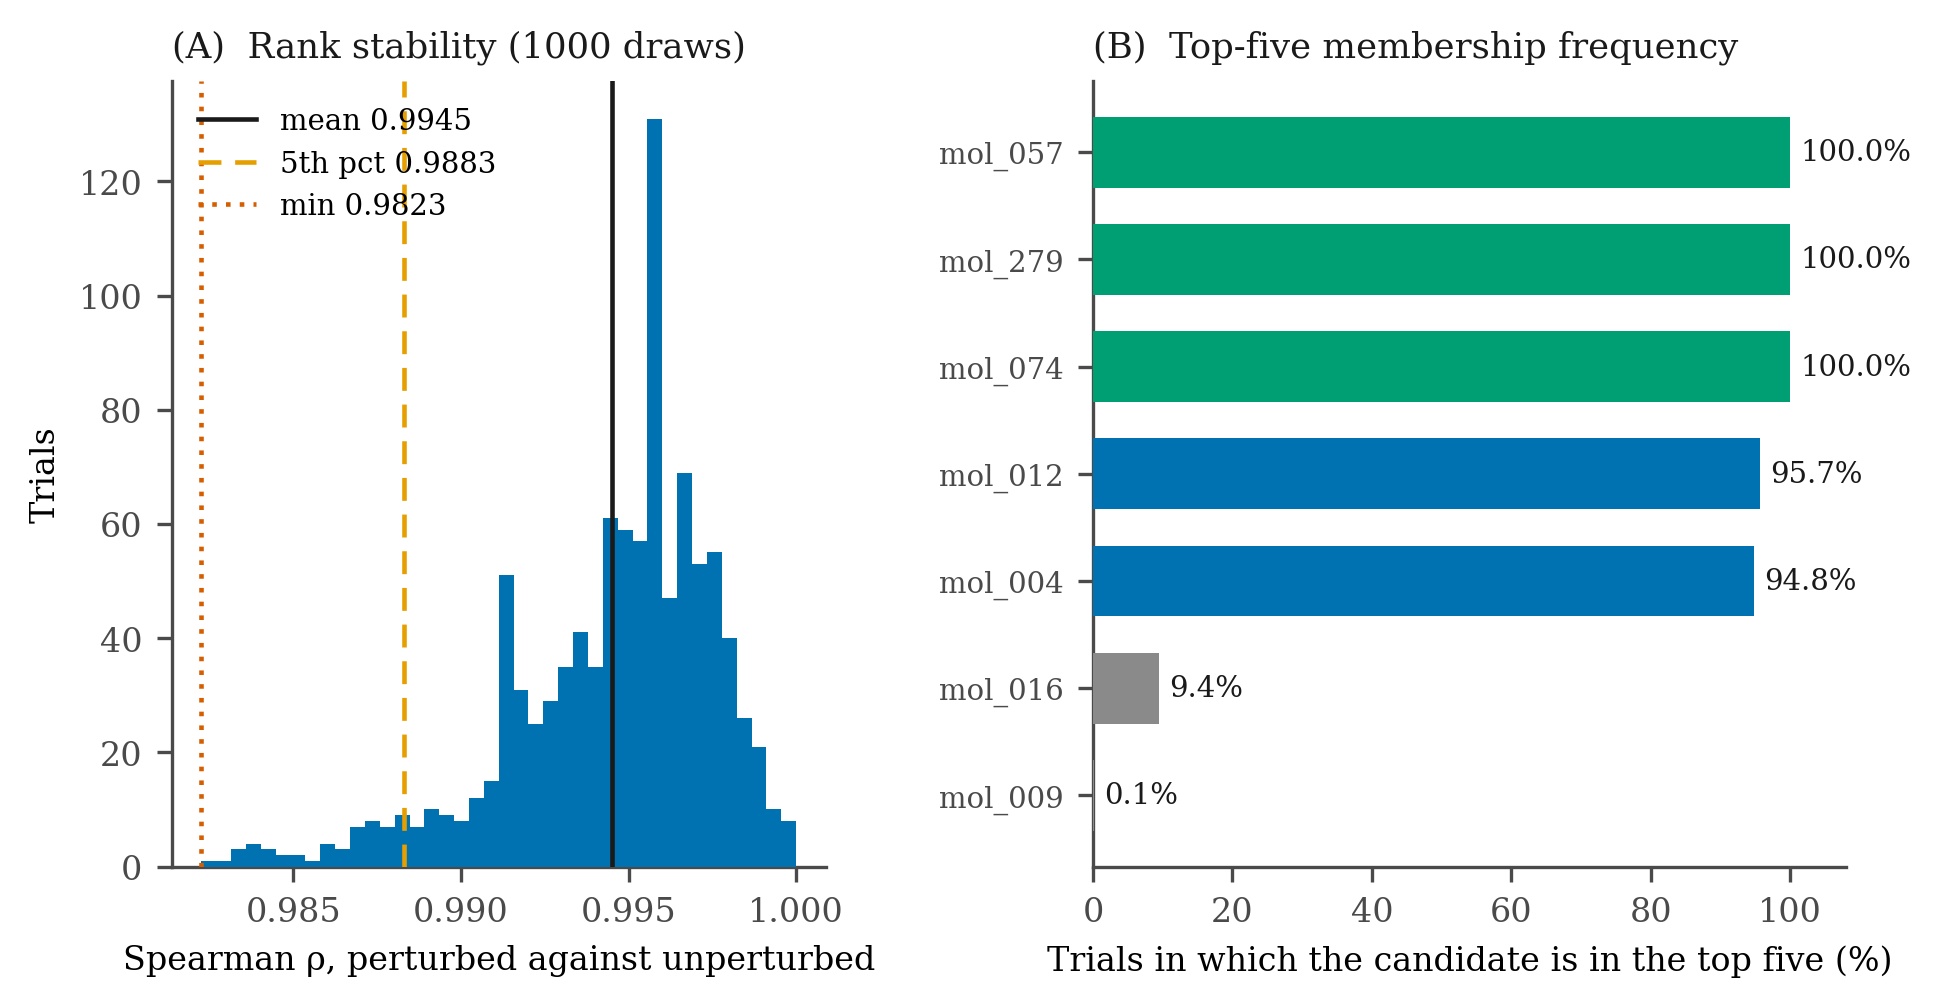

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S2.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S2.pdf`</sub>

In [34]:
# ============================================================
# Figure S2 · 权重扰动蒙卡：ρ 分布与逐候选进入前五的频率   （§2.6.5）
# ============================================================
# 与 Table S4 同一轮、同一个种子（上一个 cell 的 NDRAW 次抽样），故二者不会各说各话。
# 只取两幅：(A) 总体 ρ 的分布，(C) 逐候选进入前五的频率。
# 旧稿另有单轴 ±50% 扫描两幅，V3 未曾跑过，故不造。
fig, (q1, q2) = plt.subplots(1, 2, figsize=(7.2, 3.4),
                             gridspec_kw={"width_ratios": [1.0, 1.15], "wspace": 0.38})

q1.hist(rhos, bins=40, color=PAL6[0], zorder=3)
for v, c, ls, lab in ((rhos.mean(), INK, "-", "mean %.4f" % rhos.mean()),
                      (np.percentile(rhos, 5), PAL6[3], (0, (5, 3)),
                       "5th pct %.4f" % np.percentile(rhos, 5)),
                      (rhos.min(), C_LOST, (0, (1, 2)), "min %.4f" % rhos.min())):
    q1.axvline(v, color=c, ls=ls, lw=1.1, zorder=4, label=lab)
q1.set_xlabel("Spearman ρ, perturbed against unperturbed", fontsize=8)
q1.set_ylabel("Trials", fontsize=8)
q1.legend(fontsize=7, loc="upper left")
q1.set_title("(A)  Rank stability (%d draws)" % NDRAW, loc="left", fontsize=8.5, color=INK)

ser = pd.Series(top5cnt).sort_values(ascending=False)
ser = ser[ser > 0]
if len(ser) > 12: ser = ser.head(12)
pct = 100.0 * ser / NDRAW
yy = np.arange(len(pct))[::-1]
cols = [PAL6[2] if m in tier1_ids else (PAL6[0] if v >= 50 else MUTED)
        for m, v in zip(pct.index, pct.values)]
q2.barh(yy, pct.values, color=cols, height=0.66, zorder=3)
q2.set_yticks(yy)
q2.set_yticklabels([m.replace("pool_", "") for m in pct.index], fontsize=7)
q2.set_xlim(0, 108); q2.set_xlabel("Trials in which the candidate is in the top five (%)",
                                   fontsize=8)
for y, v in zip(yy, pct.values):
    q2.text(v + 1.5, y, "%.1f%%" % v, fontsize=7, va="center", color=INK)
q2.set_title("(B)  Top-five membership frequency", loc="left", fontsize=8.5, color=INK)

print("  进入前五的候选共 %d 个（频率 > 0）；其中 100%% 者 %d 个。"
      % (int((pd.Series(top5cnt) > 0).sum()),
         int((pd.Series(top5cnt) == NDRAW).sum())))
# 稿件 §2.6.5 已于 2026-11-01 把 279 补入第三位占据者之列
listed255 = {"pool_mol_074", "pool_mol_004", "pool_mol_012", "pool_mol_279"}
extra = [(m, 100.0 * v / NDRAW) for m, v in sorted(top5cnt.items(), key=lambda kv: -kv[1])
         if v > 0 and m not in listed255 and m not in tier1_ids and 100.0 * v / NDRAW >= 5.0]
if extra:
    print("  §2.6.5 未提及而进入前五达 5%% 以上者: %s"
          % ", ".join("%s %.1f%%" % (m.replace("pool_", ""), v) for m, v in extra))

save_fig(fig, "S2", "Monte Carlo weight sensitivity: rho distribution and top-five membership",
         caption="Monte Carlo weight sensitivity of the composite ranking, from the same "
                 "%d draws reported in Table S5 (each weight perturbed independently by a "
                 "uniform factor within ±30%%, signs preserved, the scale held frozen). "
                 "(A) Distribution of the Spearman rank correlation between each perturbed "
                 "ranking and the unperturbed one, with the mean, the 5th percentile and the "
                 "minimum marked. (B) Frequency with which each candidate appears in the top "
                 "five across the draws. The aggregate coefficient in (A) is a weak diagnostic "
                 "on its own, since a value above 0.99 is readily obtained whenever one "
                 "candidate dominates the score distribution; the per-candidate frequencies in "
                 "(B) carry the information that bears on membership, and are what the "
                 "enumeration in §2.6.3 should be read against." % NDRAW)

In [35]:
# ============================================================
# Table S7 · 候选重采样（§-BOOT）：Tier 1 在队列变动下的去留    （§2.6.6）
# ============================================================
# 这是 §2.6.5 点名的三验之第三验，此前从未跑过，而 §4.5 第 3 条已引其结果。
# **要紧的是它变的是什么。** 权重与标尺若皆冻结，则每个候选的 F 是常数，
# 重采样队列不会改变任何相对次序 —— 那样的「检验」恒为 100%，一无所言。
# 故此验所变者为**标尺**：稳健 z 的 median 与 1.4826×MAD 是队列统计量，
# 每一次重采样都自所抽之队列重算，再以该标尺标准化全部 31 个候选，权重不动。
rngB = np.random.default_rng(20261101)
NBOOT = 2000
# 列名在此就地重取，不借用上游的 `cols` —— 那个名字在后来的 cell 中已被改写，
# 借它会在换序之后静默取错列。
COLB = {"d_min": "mindist_mean", "H_occ": "hbond_occupancy", "RMSD_prot": "rmsd_prot_mean",
        "dG_PBSA": "dG_PBSA_mean", "sigma_PBSA": "sigma_PBSA", "RMSD_lig": "rmsd_lig_mean"}
_miss = [c for c in COLB.values() if c not in X.columns]
if _miss: raise KeyError("六轴输入矩阵缺列 %s；实有 %s" % (_miss, list(X.columns)))
Xv = np.column_stack([pd.to_numeric(X[COLB[a]], errors="raise").to_numpy(float)
                      for a in AXES6])            # 31 × 6 原值
wv  = np.array([W_APPLIED[a] for a in AXES6])
ids_b = X[mid].astype(str).to_numpy()
F_nom = np.array([float(F_pub.loc[m]) for m in ids_b])
ord_nom = np.argsort(-F_nom)
tier1_nom = set(ids_b[ord_nom[:3]])
top1_nom = ids_b[ord_nom[0]]
print("  名义前三: %s" % ", ".join(sorted(tier1_nom)))

from scipy.stats import spearmanr as _spB
rb, keep1b, keep3b, degen = [], 0, 0, 0
top3cnt = {m: 0 for m in ids_b}
for _ in range(NBOOT):
    idx = rngB.integers(0, len(ids_b), len(ids_b))
    sub = Xv[idx]
    med = np.median(sub, axis=0)
    mad = np.median(np.abs(sub - med), axis=0) * 1.4826
    if np.any(mad <= 0):                 # 某轴在该次抽样中全同 —— 标尺无定义
        degen += 1; continue
    Zb = (Xv - med) / mad
    Fb = Zb @ wv
    rb.append(_spB(F_nom, Fb).statistic)
    ob = np.argsort(-Fb)
    if ids_b[ob[0]] == top1_nom: keep1b += 1
    s3 = set(ids_b[ob[:3]])
    if s3 == tier1_nom: keep3b += 1
    for m in s3: top3cnt[m] += 1
rb = np.array(rb); nb = len(rb)
if nb == 0:
    raise RuntimeError("全部 %d 次重采样皆因某轴 MAD = 0 而无定义；标尺不可重算。" % NBOOT)
if degen:
    print("  注：%d / %d 次抽样中有某轴的 MAD = 0（标尺无定义），已剔除；"
          "有效次数 %d。" % (degen, NBOOT, nb))

BT = pd.DataFrame([
    {"quantity": "resamples with a well-defined scale", "value": float(nb)},
    {"quantity": "Spearman rho vs nominal, mean",  "value": float(rb.mean())},
    {"quantity": "Spearman rho, s.d.",             "value": float(rb.std(ddof=1))},
    {"quantity": "Spearman rho, 5th percentile",   "value": float(np.percentile(rb, 5))},
    {"quantity": "Spearman rho, minimum",          "value": float(rb.min())},
    {"quantity": "rank-1 retained (%)",            "value": 100.0 * keep1b / nb},
    {"quantity": "Tier-1 triple reproduced (%)",   "value": 100.0 * keep3b / nb},
])
print(BT.to_string(index=False))
t3 = sorted(((m, 100.0 * c / nb) for m, c in top3cnt.items() if c), key=lambda kv: -kv[1])
print("\n  进入前三者: " + ", ".join("%s %.1f%%" % (m.replace("pool_mol_", ""), v)
                                   for m, v in t3[:6]))
BT2 = pd.DataFrame([{"mol_id": m, "top3_frequency_pct": v} for m, v in t3])

pct3 = 100.0 * keep3b / nb
print("\n  ===== §2.6.6 与 §4.5 第 3 条所需的数（实测）=====")
print("  Tier-1 三元组在 %.1f%% 的重采样中复现（%d / %d）。" % (pct3, keep3b, nb))
print("  稿件原引的 77.2%% 已于 2026-11-01 撤下（该数只被引用、未被产出）；"
      "差 %+.1f 个百分点。" % (pct3 - 77.2))
print("  可直接入稿的一句：")
print("     \"The Tier-1 triple is reproduced in %.1f%% of %d candidate resamples, against "
      "%.1f%% of weight perturbations.\"" % (pct3, nb, 100.0 * keep3 / NDRAW))
# 稿件 §2.6.6 与 §4.5 第 3 条现载 64.5%（2026-11-01 实测）。重跑若有出入即报。
if abs(pct3 - 64.5) > 0.1:
    warn("§2.6.6 载 64.5%%，本次实测 %.1f%% —— 种子未变而数有异，先查清。" % pct3)

save_table(BT, "S7",
           "Candidate-resampling sensitivity of the composite ranking. The 31 candidates are "
           "resampled with replacement; for each resample the robust-*z* scale — the "
           "per-axis median and 1.4826 × MAD — is recomputed from the resampled "
           "cohort, all 31 candidates are standardized on that scale, and the ranking is "
           "recomputed with the applied weights unchanged. It is the scale, not the weight "
           "vector, that this test varies: with both the scale and the weights held fixed each "
           "candidate's F(Γ) is a constant and resampling the cohort could not change any "
           "relative order, so such a test would return complete stability without having "
           "examined anything. Resamples in which an axis returns a zero MAD leave the scale "
           "undefined and are excluded; their number is reported in the table. This is the "
           "third of the three sensitivity tests of §2.6.5–§2.6.6, and the only "
           "one that varies the cohort (§2.6.6).", floatfmt="%.4f")
BT2.to_csv(os.path.join(OUTDIR, "Table_S7_top3_frequency.csv"), index=False)
saved(os.path.join(OUTDIR, "Table_S7_top3_frequency.csv"), "逐候选进入前三的频率")

  名义前三: pool_mol_057, pool_mol_074, pool_mol_279
                           quantity       value
resamples with a well-defined scale 2000.000000
      Spearman rho vs nominal, mean    0.988973
                 Spearman rho, s.d.    0.008311
       Spearman rho, 5th percentile    0.972984
              Spearman rho, minimum    0.931048
                rank-1 retained (%)  100.000000
       Tier-1 triple reproduced (%)   64.500000

  进入前三者: 057 100.0%, 279 93.8%, 074 70.7%, 004 21.0%, 012 12.3%, 016 2.1%

  ===== §2.6.6 与 §4.5 第 3 条所需的数（实测）=====
  Tier-1 三元组在 64.5% 的重采样中复现（1290 / 2000）。
  稿件原引的 77.2% 已于 2026-11-01 撤下（该数只被引用、未被产出）；差 -12.7 个百分点。
  可直接入稿的一句：
     "The Tier-1 triple is reproduced in 64.5% of 2000 candidate resamples, against 88.7% of weight perturbations."
  → Table_S7  (.csv + .md)   7 行 × 2 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S7.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S7.md


**Table S7.** Candidate-resampling sensitivity of the composite ranking.

| quantity                            |     value |
|:------------------------------------|----------:|
| resamples with a well-defined scale | 2000.0000 |
| Spearman rho vs nominal, mean       |    0.9890 |
| Spearman rho, s.d.                  |    0.0083 |
| Spearman rho, 5th percentile        |    0.9730 |
| Spearman rho, minimum               |    0.9310 |
| rank-1 retained (%)                 |  100.0000 |
| Tier-1 triple reproduced (%)        |   64.5000 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S7.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S7.md`</sub>

     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S7_top3_frequency.csv   （逐候选进入前三的频率）


'/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S7_top3_frequency.csv'

  F(Γ) 的前三: pool_mol_057, pool_mol_074, pool_mol_279
  Equal weight   前三与之重合 3/3  
  Borda count    前三与之重合 3/3  
  ΔG_PBSA only   前三与之重合 2/3  （pool_mol_012 取代 pool_mol_279）
  → Table_S6  (.csv + .md)   4 行 × 5 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S6.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S6.md


**Table S6.** Pairwise Spearman rank correlation between the rankings produced by the four aggregation schemes of Figure S1, over the 31 primary candidates.

| scheme       |   F(Γ) | Equal weight | Borda count | ΔG_PBSA only |
|:-------------|-------:|-------------:|------------:|-------------:|
| F(Γ)         | 1.0000 |       0.9887 |      0.9436 |       0.6202 |
| Equal weight | 0.9887 |       1.0000 |      0.9243 |       0.5883 |
| Borda count  | 0.9436 |       0.9243 |      1.0000 |       0.6950 |
| ΔG_PBSA only | 0.6202 |       0.5883 |      0.6950 |       1.0000 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S6.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S6.md`</sub>

  → Figure_S1  (.png 300 dpi + .pdf)  Tier-1 membership under four aggregation schemes
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S1.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S1.pdf   （矢量，ACS 投稿以此为佳）


**Figure S1.** Sensitivity of the leading group to the choice of aggregation, tested by recomputing the ranking of the 31 primary candidates under four schemes on the same frozen robust-*z* matrix: the data-driven weights of §2.6.2; an equal-weight combination with all |w| = 1 and the directional signs retained; a Borda count over the six per-axis orderings, which uses only ordinal information and discards the weights entirely; and the ΔG_PBSA axis alone. (A) Each line is one candidate; the Tier-1 band is shaded. (B) Pairwise rank correlation between the four. The question the figure settles is whether Tier-1 membership is a property of the simulated ensemble or of the weight parameterization; the aggregate coefficient reported in §2.6.3 cannot distinguish the two (Table S5).

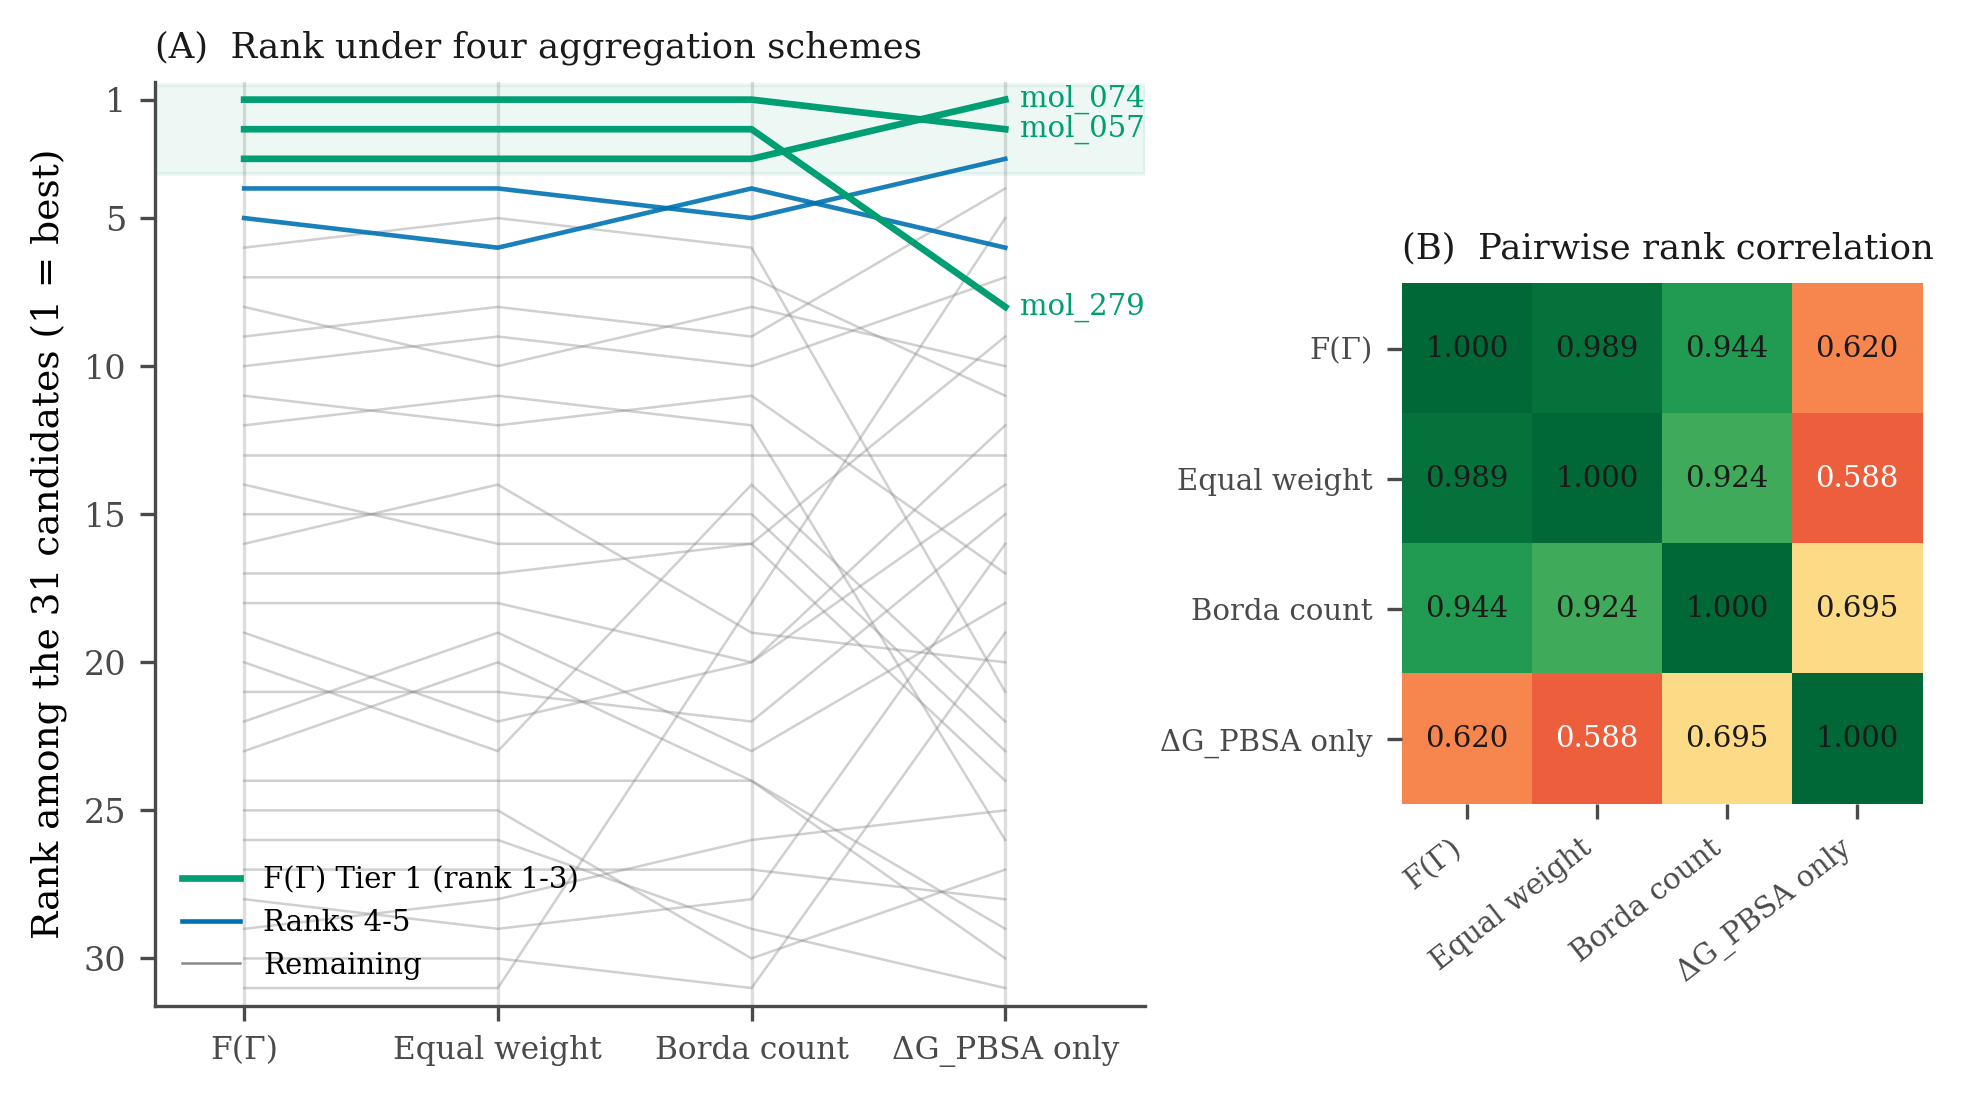

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S1.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S1.pdf`</sub>

In [36]:
# ============================================================
# Figure S1 · Tier 1 在四种加权法下的去留                （§2.6.5）
# ============================================================
# 所答者，是 Table S4 的题注已经承认的那个弱处：总体 Spearman 系数是弱诊断。
# 此处改换聚合法重算名次 —— 检验 Tier 1 究竟是 MD 系综的性质，还是权重参数化的性质。
# **不预设旧稿之果**：等权是否复现前三、Borda 是否复现其二，皆以本队列实测为准。
from scipy.stats import spearmanr as _spS

Zf = Zs.loc[K[kid].astype(str), AXES6]            # 冻结 Z，31 × 6
w_v = np.array([W_APPLIED[a] for a in AXES6])
sgn = np.sign(w_v)

F_compass = Zf.to_numpy(float) @ w_v
F_equal   = Zf.to_numpy(float) @ sgn               # 等权：|w| = 1，符号保留
# Borda：逐轴按有利程度排名，得分 = n − 名次，再按总分排
n_c = len(Zf)
bor = np.zeros(n_c)
for j, a in enumerate(AXES6):
    fav = Zf[a].to_numpy(float) * w_v[j]           # 越大越有利
    bor += (pd.Series(-fav).rank(method="min").to_numpy(float) * -1 + n_c)
F_pbsa = Zf["dG_PBSA"].to_numpy(float) * np.sign(W_APPLIED["dG_PBSA"])

SCH = pd.DataFrame({"F(Γ)": F_compass, "Equal weight": F_equal,
                    "Borda count": bor, "ΔG_PBSA only": F_pbsa},
                   index=Zf.index)
RS = SCH.apply(lambda c: (-c).rank(method="min").astype(int))
SCOLS = list(SCH.columns)

top3 = {c: set(RS.index[RS[c] <= 3]) for c in SCOLS}
base3 = top3["F(Γ)"]
print("  F(Γ) 的前三: %s" % ", ".join(sorted(base3)))
for c in SCOLS[1:]:
    ov = len(base3 & top3[c])
    print("  %-14s 前三与之重合 %d/3  %s" % (c, ov, "" if ov == 3 else "（%s 取代 %s）"
          % (", ".join(sorted(top3[c] - base3)), ", ".join(sorted(base3 - top3[c])))))

fig, (r1, r2) = plt.subplots(1, 2, figsize=(7.6, 4.0),
                             gridspec_kw={"width_ratios": [1.9, 1.0], "wspace": 0.34})
xs = np.arange(len(SCOLS))
for m in RS.index:
    y = RS.loc[m, SCOLS].to_numpy(float)
    if m in base3:
        r1.plot(xs, y, color=PAL6[2], lw=1.6, zorder=4)
    elif m in set(K.sort_values(kr)[kid].astype(str)[:5]):
        r1.plot(xs, y, color=PAL6[0], lw=1.1, zorder=3, alpha=0.9)
    else:
        r1.plot(xs, y, color=MUTED, lw=0.6, zorder=1, alpha=0.40)
for x in xs: r1.axvline(x, color="#dddddd", lw=0.8, zorder=0)
r1.axhspan(0.5, 3.5, color=PAL6[2], alpha=0.07, zorder=0)
r1.set_ylim(len(RS) + 0.6, 0.4)
r1.set_yticks([1] + list(range(5, len(RS) + 1, 5)))
r1.set_xticks(xs); r1.set_xticklabels(SCOLS, fontsize=7.5)
r1.set_ylabel("Rank among the 31 candidates (1 = best)")
r1.set_xlim(-0.35, len(SCOLS) - 0.45)
for m in sorted(base3, key=lambda z: RS.loc[z, "F(Γ)"]):
    r1.annotate(m.replace("pool_", ""), (xs[-1] + 0.06, RS.loc[m, SCOLS[-1]]),
                fontsize=7, color=PAL6[2], va="center", ha="left")
r1.set_title("(A)  Rank under four aggregation schemes", loc="left",
             fontsize=8.5, color=INK)
r1.legend(handles=[Line2D([], [], color=PAL6[2], lw=1.6, label="F(Γ) Tier 1 (rank 1-3)"),
                   Line2D([], [], color=PAL6[0], lw=1.1, label="Ranks 4-5"),
                   Line2D([], [], color=MUTED, lw=0.6, label="Remaining")],
          loc="lower left", fontsize=7, handlelength=2.0)

M4 = pd.DataFrame(index=SCOLS, columns=SCOLS, dtype=float)
for a in SCOLS:
    for b in SCOLS:
        M4.loc[a, b] = _spS(RS[a], RS[b]).statistic
vlo = float(np.floor(M4.to_numpy(float).min() * 10) / 10)   # 下界自数据定，免得满屏皆绿
im = r2.imshow(M4.to_numpy(float), vmin=vlo, vmax=1.0, cmap="RdYlGn")
r2.set_xticks(range(len(SCOLS))); r2.set_yticks(range(len(SCOLS)))
r2.set_xticklabels(SCOLS, fontsize=7, rotation=38, ha="right")
r2.set_yticklabels(SCOLS, fontsize=7)
for i in range(len(SCOLS)):
    for j in range(len(SCOLS)):
        v = M4.iloc[i, j]
        r2.text(j, i, "%.3f" % v, ha="center", va="center", fontsize=7,
                color="white" if v < vlo + 0.12 else INK)
r2.set_title("(B)  Pairwise rank correlation", loc="left", fontsize=8.5, color=INK)
for sp in r2.spines.values(): sp.set_visible(False)

save_table(M4.reset_index().rename(columns={"index": "scheme"}), "S6",
           "Pairwise Spearman rank correlation between the rankings produced by the four "
           "aggregation schemes of Figure S1, over the 31 primary candidates.", floatfmt="%.4f")

save_fig(fig, "S1", "Tier-1 membership under four aggregation schemes",
         caption="Sensitivity of the leading group to the choice of aggregation, tested by "
                 "recomputing the ranking of the 31 primary candidates under four schemes on "
                 "the same frozen robust-*z* matrix: the data-driven weights of §2.6.2; an "
                 "equal-weight combination with all |w| = 1 and the directional signs retained; "
                 "a Borda count over the six per-axis orderings, which uses only ordinal "
                 "information and discards the weights entirely; and the ΔG_PBSA axis alone. "
                 "(A) Each line is one candidate; the Tier-1 band is shaded. (B) "
                 "Pairwise rank correlation between the four. The question the figure settles "
                 "is whether Tier-1 membership is a property of the simulated ensemble or of "
                 "the weight parameterization; the aggregate coefficient reported in "
                 "§2.6.3 cannot distinguish the two (Table S5).")

    矢量 PDF 已出（经 cairosvg）：Figure_S4.pdf
  画成 31 个结构，6 行（应为 31 个）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S4.png   （300 dpi 以上，RDKit Cairo 直出）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S4.pdf   （矢量，自 RDKit SVG 后端转出；投稿以此为佳）


**Figure S4.** Two-dimensional structures of all 31 primary-pose candidates that entered scoring, in composite rank order. Structures are drawn from the SMILES recorded in the generation scope table. The cohort is chemically heterogeneous and was not filtered for a common scaffold at any stage, which is why the ranking cannot be read as a within-series structure-activity comparison (§3.5.1, §4.5).

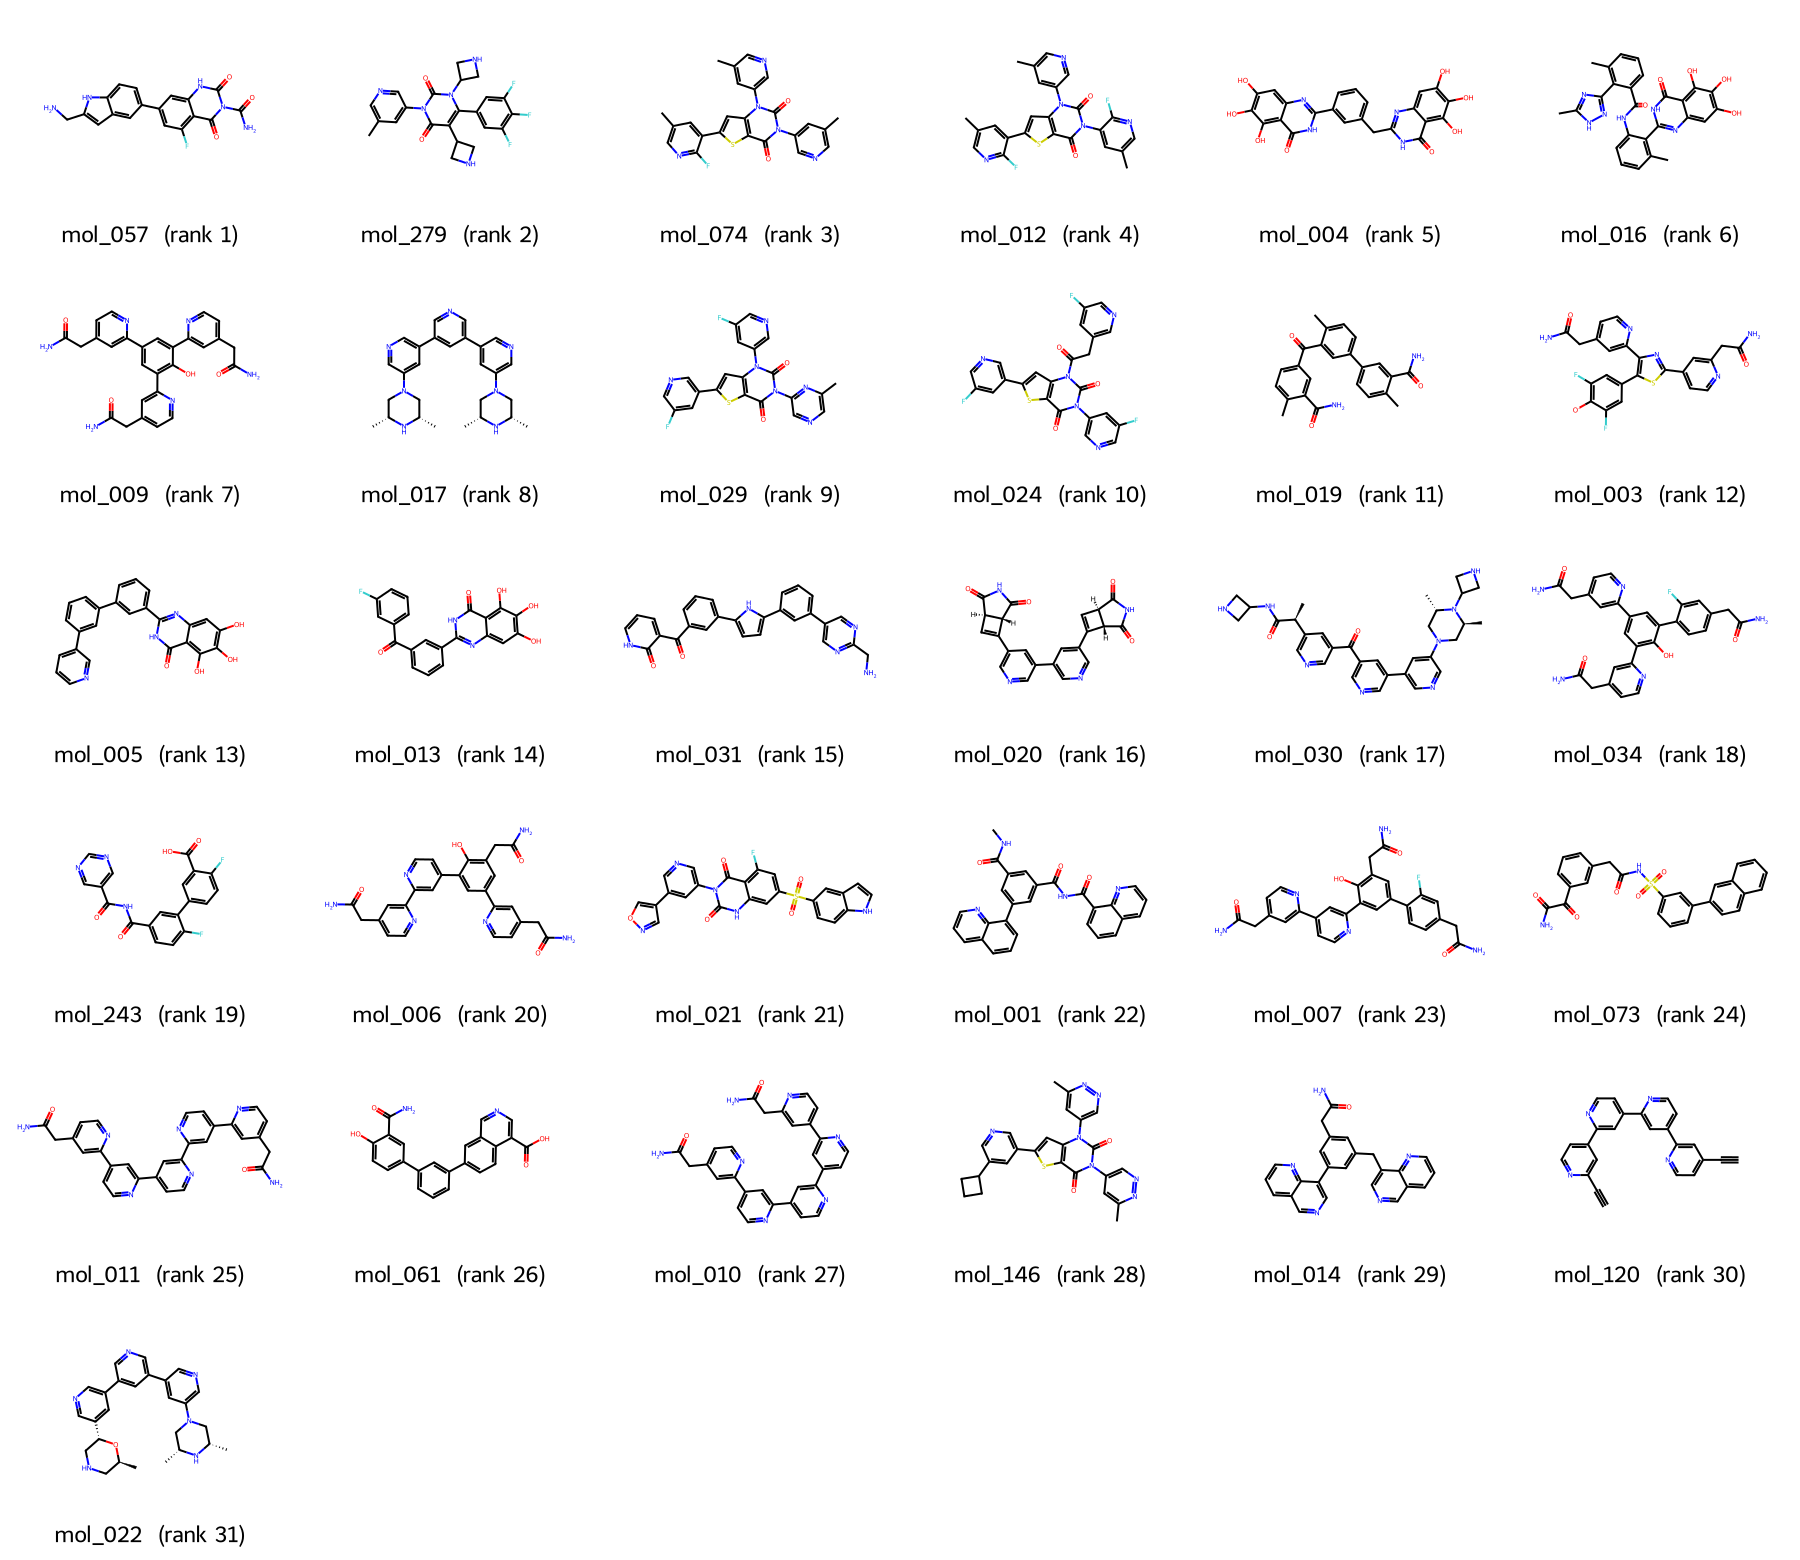

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S4.png`</sub>

In [37]:
# ============================================================
# Figure S4 · 31 个打分候选的二维结构全图               （§3.1.1）
# ============================================================
if not HAVE_RDKIT:
    print("  跳过（RDKit 不在本环境中）。")
else:
    ALLIDS = list(K.sort_values(kr)[kid].astype(str))
    labs = ["%s  (rank %d)" % (m.replace("pool_mol_", "mol_"), RANKOF[m]) for m in ALLIDS]
    outp = os.path.join(OUTDIR, "Figure_S4.png")
    n, nr = draw_grid(ALLIDS, labs, ncol=6, outpath=outp, cell=(300, 260), legend_fs=22)
    print("  画成 %d 个结构，%d 行（应为 31 个）" % (n, nr))
    if n != len(ALLIDS):
        warn("Figure S4：31 个候选中只画成 %d 个。" % n)
    CAPTIONS.append(("Figure", "S4",
        "Two-dimensional structures of all 31 primary-pose candidates that entered scoring, "
        "in composite rank order. Structures are drawn from the SMILES recorded in the "
        "generation scope table. The cohort is chemically heterogeneous and was not filtered "
        "for a common scaffold at any stage, which is why the ranking cannot be read as a "
        "within-series structure-activity comparison (§3.5.1, §4.5)."))
    apng = saved(outp, "300 dpi 以上，RDKit Cairo 直出")
    apdf = saved(os.path.splitext(outp)[0] + ".pdf",
                 "矢量，自 RDKit SVG 后端转出；投稿以此为佳")
    _show_md("**Figure S4.** %s" % CAPTIONS[-1][2])
    _show_png(apng, 820)
    _show_md("<sub>已存 · `%s`</sub>" % apng)

In [38]:
# ============================================================
# Table S10 · 99 条主臂复本的逐复本占有率全表        （§3.2.1）
# ============================================================
S4 = A[["system", "rep", "target", "mol_id", "dyad", "n_frames",
        "site_occupancy", "d_dyad_mean", "d_dyad_first", "d_dyad_last", "d_dyad_max",
        "rmsd_lig_mean_from_phase4", "rmsd_prot_mean_from_phase4",
        "mindist_mean_from_phase4", "hbond_occupancy_from_phase4"]].copy()
S4 = S4.sort_values("site_occupancy").reset_index(drop=True)
expect_rows(S4, 99, "99 条主臂复本")
print("  n_frames 唯一值:", sorted(S4.n_frames.unique()), " （应全为 501）")
print("  dyad 唯一值:", sorted(S4.dyad.astype(str).unique()))

# 2026-11-12：主臂逐帧最大值的分离余隙，连同最高之保持者，由本表自身算出。
# 立意：§3.2 与 §5.2 要引这两个数，而它们此前无出处 —— 凡正文所引，须在数据册中有迹可循。
_ret = S4[S4.site_occupancy >= 0.50]; _non = S4[S4.site_occupancy < 0.50]
if len(_non) != 2:
    raise AssertionError("失位复本 %d 条，§3.2.1 载 2 条" % len(_non))
_hi = float(_ret.d_dyad_max.max()); _lo = float(_non.d_dyad_max.min())
_mg = _lo - _hi
_t  = _ret.loc[_ret.d_dyad_max.idxmax()]
if _mg <= 0:
    warn("主臂逐帧最大值已重叠（余隙 %+.2f A）—— §3.2 与 §5.2 之措辞须随之改。" % _mg)
print("  主臂逐帧最大值：保持者 %.2f-%.2f A（中位 %.2f）· 未保持者 %.2f 与 %.2f A"
      % (_ret.d_dyad_max.min(), _hi, _ret.d_dyad_max.median(),
         *sorted(_non.d_dyad_max.tolist())))
print("  余隙 %+.2f A · 最高之保持者 %s/%s（占有率 %.4f · %.3f A）"
      % (_mg, _t["system"], _t["rep"], _t.site_occupancy, _t.d_dyad_max))
save_table(S4, "S10",
           ("Per-replica active-site occupancy for all 99 main-arm replicas, sorted ascending. "
           "Occupancy is the fraction of 501 analyzed frames in which the minimum ligand-dyad "
           "heavy-atom distance fell below 5.0 A. Two thresholds enter the definition and their "
           "provenance differs: the 5.0 A per-frame cut was selected after the trajectories were "
           "available, while the 0.50 per-replica retention threshold was inherited unmodified "
           "(§3.2.1). Read as a per-frame maximum, `d_dyad_max` separates the %d retained "
           "replicas (%.2f to %.2f A, median %.2f) from the %d that did not retain (%.2f and "
           "%.2f A) by a margin of %.2f A. The highest retained value belongs to %s/%s at "
           "occupancy %.3f, so a large per-frame excursion is compatible with retention "
           "(§3.2, §5.2)."
            % (len(_ret), _ret.d_dyad_max.min(), _hi, _ret.d_dyad_max.median(),
               len(_non), *sorted(_non.d_dyad_max.tolist()),
               _mg, _t["system"], _t["rep"], _t.site_occupancy)))

  条数 99 ✓  (99 条主臂复本)
  n_frames 唯一值: [np.int64(501)]  （应全为 501）
  dyad 唯一值: ['His41+Cys145']
  主臂逐帧最大值：保持者 2.57-13.63 A（中位 3.42）· 未保持者 14.27 与 59.93 A
  余隙 +0.64 A · 最高之保持者 pool_mol_034__6W63__primary/r2（占有率 0.6307 · 13.632 A）
  → Table_S10  (.csv + .md)   99 行 × 15 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S10.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S10.md


**Table S10.** Per-replica active-site occupancy for all 99 main-arm replicas, sorted ascending.

| system                        | rep | target | mol_id       | dyad         | n_frames | site_occupancy | d_dyad_mean | d_dyad_first | d_dyad_last | d_dyad_max | rmsd_lig_mean_from_phase4 | rmsd_prot_mean_from_phase4 | mindist_mean_from_phase4 | hbond_occupancy_from_phase4 |
|:------------------------------|:----|:-------|:-------------|:-------------|---------:|---------------:|------------:|-------------:|------------:|-----------:|--------------------------:|---------------------------:|-------------------------:|----------------------------:|
| pool_mol_022__6W63__primary   | r3  | 6W63   | pool_mol_022 | His41+Cys145 |      501 |         0.0000 |     23.7430 |      13.0330 |     20.8130 |    59.9340 |                   36.7853 |                     2.1252 |                   0.4712 |                      0.7645 |
| pool_mol_243__6W63__primary   | r2  | 6W63   | pool_mol_243 | His41+Cys145 |      501 |         0.4311 |      5.5250 |       2.3990 |      6.9120 |    14.2690 |                   11.0972 |                     1.8928 |                   0.2138 |                      0.4531 |
| pool_mol_034__6W63__primary   | r2  | 6W63   | pool_mol_034 | His41+Cys145 |      501 |         0.6307 |      5.3610 |       3.9390 |      8.7090 |    13.6320 |                   11.3025 |                     1.9641 |                   0.1996 |                      0.9082 |
| pool_mol_061__6W63__primary   | r3  | 6W63   | pool_mol_061 | His41+Cys145 |      501 |         0.9601 |      2.7450 |       1.8020 |      2.9650 |     7.4790 |                    8.6932 |                     2.5701 |                   0.2016 |                      0.8583 |
| pool_mol_021__6W63__primary   | r3  | 6W63   | pool_mol_021 | His41+Cys145 |      501 |         0.9701 |      2.8460 |       3.7920 |      3.7670 |     7.2390 |                    8.6219 |                     2.1719 |                   0.1950 |                      0.3273 |
| pool_mol_020__6W63__secondary | r1  | 6W63   | pool_mol_020 | His41+Cys145 |      501 |         0.9701 |      2.7690 |       2.1770 |      2.1850 |     5.6020 |                    8.1083 |                     2.0053 |                   0.1992 |                      0.7984 |
| pool_mol_001__6W63__primary   | r2  | 6W63   | pool_mol_001 | His41+Cys145 |      501 |         0.9820 |      2.7680 |       3.1040 |      2.5310 |     6.7630 |                    6.5338 |                     2.1198 |                   0.2042 |                      0.7904 |
| pool_mol_007__6W63__primary   | r2  | 6W63   | pool_mol_007 | His41+Cys145 |      501 |         0.9920 |      2.9000 |       2.0700 |      3.1840 |     5.4000 |                    5.9605 |                     2.4460 |                   0.2021 |                      0.8942 |
| pool_mol_120__6W63__primary   | r1  | 6W63   | pool_mol_120 | His41+Cys145 |      501 |         0.9920 |      2.7830 |       7.0130 |      2.8430 |     7.0130 |                    7.2696 |                     3.9456 |                   0.2161 |                      0.3293 |
| pool_mol_016__6W63__primary   | r1  | 6W63   | pool_mol_016 | His41+Cys145 |      501 |         0.9960 |      3.3220 |       3.1010 |      3.1740 |     5.3240 |                    5.6836 |                     1.8234 |                   0.1930 |                      0.9940 |
| pool_mol_120__6W63__primary   | r3  | 6W63   | pool_mol_120 | His41+Cys145 |      501 |         0.9960 |      3.2900 |       2.9120 |      3.3810 |     5.2960 |                    5.0142 |                     2.2174 |                   0.2111 |                      0.4331 |
| pool_mol_034__6W63__primary   | r3  | 6W63   | pool_mol_034 | His41+Cys145 |      501 |         0.9980 |      2.4610 |       2.1160 |      2.6890 |     5.2550 |                    8.7198 |                     2.4592 |                   0.2008 |                      0.9920 |
| pool_mol_014__6W63__primary   | r2  | 6W63   | pool_mol_014 | His41+Cys145 |      501 |         0.9980 |      2.6490 |       2.2650 |      2.6470 |     5.1200 |                    6.1465 |                     2.4325 |                   0.2154 |                      0.4172 |
| pool_mol_120__6W63__primary   | r2  | 6W63   | pool_mol_120 | His41+Cys145 |      501 |         0.9980 |      2.7070 |       3.6180 |      2.5340 |     5.0420 |                    7.5966 |                     1.8264 |                   0.2093 |                      0.4850 |
| pool_mol_007__6W63__primary   | r3  | 6W63   | pool_mol_007 | His41+Cys145 |      501 |         0.9980 |      2.3860 |       2.0410 |      2.1470 |     5.2750 |                    7.6461 |                     2.1408 |                   0.1890 |                      0.9800 |
| pool_mol_004__6W63__primary   | r3  | 6W63   | pool_mol_004 | His41+Cys145 |      501 |         0.9980 |      3.0060 |       2.8830 |      2.4260 |     5.0520 |                    1.9562 |                     2.1027 |                   0.1783 |                      0.9960 |
| pool_mol_007__6W63__primary   | r1  | 6W63   | pool_mol_007 | His41+Cys145 |      501 |         1.0000 |      2.4140 |       1.9770 |      2.4450 |     3.2050 |                    5.1779 |                     2.9335 |                   0.2008 |                      0.8104 |
| pool_mol_006__6W63__primary   | r3  | 6W63   | pool_mol_006 | His41+Cys145 |      501 |         1.0000 |      2.3300 |       2.2550 |      2.3220 |     2.9170 |                    2.7818 |                     2.5855 |                   0.1844 |                      1.0000 |
| pool_mol_009__6W63__primary   | r1  | 6W63   | pool_mol_009 | His41+Cys145 |      501 |         1.0000 |      2.2010 |       2.5800 |      2.1880 |     2.7320 |                    4.8574 |                     2.4116 |                   0.1900 |                      0.9880 |
| pool_mol_009__6W63__primary   | r2  | 6W63   | pool_mol_009 | His41+Cys145 |      501 |         1.0000 |      2.2760 |       2.6770 |      2.1710 |     3.4570 |                    2.9997 |                     2.4624 |                   0.1904 |                      1.0000 |
| pool_mol_009__6W63__primary   | r3  | 6W63   | pool_mol_009 | His41+Cys145 |      501 |         1.0000 |      2.1570 |       2.1380 |      2.1920 |     2.5710 |                    4.6856 |                     2.0666 |                   0.1911 |                      0.9980 |
| pool_mol_010__6W63__primary   | r1  | 6W63   | pool_mol_010 | His41+Cys145 |      501 |         1.0000 |      2.3800 |       2.0600 |      2.2930 |     3.1200 |                    6.7362 |                     1.8862 |                   0.1901 |                      0.9481 |
| pool_mol_010__6W63__primary   | r2  | 6W63   | pool_mol_010 | His41+Cys145 |      501 |         1.0000 |      2.4970 |       2.5940 |      2.6440 |     3.4070 |                    8.3689 |                     2.6584 |                   0.2064 |                      0.9261 |
| pool_mol_010__6W63__primary   | r3  | 6W63   | pool_mol_010 | His41+Cys145 |      501 |         1.0000 |      2.1400 |       2.5220 |      2.2290 |     2.9050 |                    5.7052 |                     2.2907 |                   0.1995 |                      0.9940 |
| pool_mol_011__6W63__primary   | r1  | 6W63   | pool_mol_011 | His41+Cys145 |      501 |         1.0000 |      2.5370 |       2.7600 |      2.7400 |     3.4180 |                    9.1079 |                     2.0169 |                   0.2021 |                      0.9082 |
| pool_mol_004__6W63__primary   | r2  | 6W63   | pool_mol_004 | His41+Cys145 |      501 |         1.0000 |      2.7210 |       2.8290 |      2.6480 |     4.5160 |                    1.3853 |                     2.1800 |                   0.1845 |                      0.9980 |
| pool_mol_005__6W63__primary   | r2  | 6W63   | pool_mol_005 | His41+Cys145 |      501 |         1.0000 |      2.6120 |       2.3310 |      2.6680 |     3.3740 |                    3.9220 |                     2.2381 |                   0.1902 |                      0.7784 |
| pool_mol_005__6W63__primary   | r1  | 6W63   | pool_mol_005 | His41+Cys145 |      501 |         1.0000 |      2.3810 |       2.4040 |      2.4970 |     3.2820 |                    2.5004 |                     2.1265 |                   0.1905 |                      0.8184 |
| pool_mol_003__6W63__primary   | r2  | 6W63   | pool_mol_003 | His41+Cys145 |      501 |         1.0000 |      2.6170 |       2.6950 |      2.5770 |     3.5390 |                    6.0874 |                     2.0193 |                   0.1982 |                      0.9940 |
| pool_mol_003__6W63__primary   | r3  | 6W63   | pool_mol_003 | His41+Cys145 |      501 |         1.0000 |      2.5130 |       2.7970 |      2.4710 |     3.6890 |                    5.8680 |                     2.3186 |                   0.1955 |                      0.9940 |
| pool_mol_001__6W63__primary   | r3  | 6W63   | pool_mol_001 | His41+Cys145 |      501 |         1.0000 |      2.4120 |       2.6490 |      2.3770 |     3.0800 |                    5.6849 |                     2.4185 |                   0.2019 |                      0.9900 |
| pool_mol_001__6W63__primary   | r1  | 6W63   | pool_mol_001 | His41+Cys145 |      501 |         1.0000 |      2.3840 |       2.6340 |      2.4380 |     3.2950 |                    6.4993 |                     2.3224 |                   0.2003 |                      0.7385 |
| pool_mol_012__6W63__primary   | r2  | 6W63   | pool_mol_012 | His41+Cys145 |      501 |         1.0000 |      2.4960 |       3.0920 |      2.5060 |     3.4060 |                    2.2878 |                     1.8953 |                   0.1896 |                      0.8643 |
| pool_mol_012__6W63__primary   | r1  | 6W63   | pool_mol_012 | His41+Cys145 |      501 |         1.0000 |      2.5200 |       2.4880 |      2.3700 |     3.3010 |                    2.3752 |                     1.7632 |                   0.1912 |                      0.6008 |
| pool_mol_011__6W63__secondary | r3  | 6W63   | pool_mol_011 | His41+Cys145 |      501 |         1.0000 |      2.6580 |       2.9770 |      2.6390 |     3.6960 |                    9.8883 |                     2.1518 |                   0.1952 |                      0.7086 |
| pool_mol_011__6W63__primary   | r3  | 6W63   | pool_mol_011 | His41+Cys145 |      501 |         1.0000 |      2.6740 |       2.5520 |      2.8950 |     3.3960 |                    5.8936 |                     2.0244 |                   0.1968 |                      0.7904 |
| pool_mol_011__6W63__secondary | r2  | 6W63   | pool_mol_011 | His41+Cys145 |      501 |         1.0000 |      2.5050 |       2.2710 |      2.6270 |     3.3650 |                    9.7576 |                     2.2105 |                   0.1949 |                      0.9820 |
| pool_mol_013__6W63__primary   | r3  | 6W63   | pool_mol_013 | His41+Cys145 |      501 |         1.0000 |      2.3480 |       1.9790 |      2.2780 |     3.3570 |                    1.8216 |                     2.9190 |                   0.1865 |                      0.8523 |
| pool_mol_012__6W63__primary   | r3  | 6W63   | pool_mol_012 | His41+Cys145 |      501 |         1.0000 |      2.4940 |       2.4520 |      2.5230 |     3.2240 |                    2.2248 |                     1.9612 |                   0.1964 |                      0.8802 |
| pool_mol_013__6W63__primary   | r1  | 6W63   | pool_mol_013 | His41+Cys145 |      501 |         1.0000 |      2.6460 |       2.5400 |      2.4340 |     4.2320 |                    6.2768 |                     1.7790 |                   0.1940 |                      0.6826 |
| pool_mol_016__6W63__primary   | r2  | 6W63   | pool_mol_016 | His41+Cys145 |      501 |         1.0000 |      2.3410 |       2.3320 |      2.4070 |     3.1200 |                    3.8947 |                     1.6900 |                   0.1869 |                      1.0000 |
| pool_mol_016__6W63__primary   | r3  | 6W63   | pool_mol_016 | His41+Cys145 |      501 |         1.0000 |      2.2540 |       2.3840 |      2.2530 |     3.1150 |                    2.8255 |                     1.6879 |                   0.1880 |                      0.9880 |
| pool_mol_017__6W63__primary   | r1  | 6W63   | pool_mol_017 | His41+Cys145 |      501 |         1.0000 |      2.4160 |       2.4260 |      2.2320 |     3.0820 |                    3.2935 |                     2.5765 |                   0.1761 |                      0.9760 |
| pool_mol_017__6W63__primary   | r2  | 6W63   | pool_mol_017 | His41+Cys145 |      501 |         1.0000 |      2.4670 |       2.2290 |      2.4220 |     3.2730 |                    4.8710 |                     2.7479 |                   0.1892 |                      0.9421 |
| pool_mol_017__6W63__primary   | r3  | 6W63   | pool_mol_017 | His41+Cys145 |      501 |         1.0000 |      2.5000 |       2.1670 |      2.5370 |     3.4500 |                    2.3387 |                     2.1238 |                   0.1896 |                      0.9820 |
| pool_mol_013__6W63__primary   | r2  | 6W63   | pool_mol_013 | His41+Cys145 |      501 |         1.0000 |      2.3060 |       1.9880 |      2.4070 |     3.2400 |                    4.8155 |                     2.9947 |                   0.1786 |                      1.0000 |
| pool_mol_014__6W63__primary   | r1  | 6W63   | pool_mol_014 | His41+Cys145 |      501 |         1.0000 |      2.7600 |       2.7420 |      2.7790 |     3.9840 |                    3.8417 |                     1.9525 |                   0.2133 |                      0.7445 |
| pool_mol_014__6W63__primary   | r3  | 6W63   | pool_mol_014 | His41+Cys145 |      501 |         1.0000 |      2.4700 |       2.1030 |      2.6380 |     3.1570 |                    2.9779 |                     2.2600 |                   0.2126 |                      0.6327 |
| pool_mol_019__6W63__primary   | r3  | 6W63   | pool_mol_019 | His41+Cys145 |      501 |         1.0000 |      2.4050 |       2.1460 |      2.6050 |     3.5030 |                    2.7102 |                     2.6756 |                   0.1946 |                      1.0000 |
| pool_mol_019__6W63__primary   | r2  | 6W63   | pool_mol_019 | His41+Cys145 |      501 |         1.0000 |      2.2390 |       1.9780 |      2.1770 |     3.8290 |                    2.6940 |                     2.3527 |                   0.1943 |                      1.0000 |
| pool_mol_019__6W63__primary   | r1  | 6W63   | pool_mol_019 | His41+Cys145 |      501 |         1.0000 |      2.4060 |       2.1830 |      2.5630 |     2.9770 |                    2.8803 |                     2.3184 |                   0.1896 |                      0.9940 |
| pool_mol_020__6W63__primary   | r1  | 6W63   | pool_mol_020 | His41+Cys145 |      501 |         1.0000 |      2.7370 |       2.7530 |      2.7730 |     3.5390 |                    4.0187 |                     2.6851 |                   0.1950 |                      0.6008 |
| pool_mol_020__6W63__primary   | r3  | 6W63   | pool_mol_020 | His41+Cys145 |      501 |         1.0000 |      2.6320 |       2.5350 |      2.7660 |     4.1590 |                    4.7441 |                     2.6765 |                   0.1987 |                      0.8443 |
| pool_mol_020__6W63__secondary | r3  | 6W63   | pool_mol_020 | His41+Cys145 |      501 |         1.0000 |      2.4400 |       2.3970 |      2.4820 |     2.9220 |                    3.6829 |                     2.6135 |                   0.1820 |                      0.9920 |
| pool_mol_020__6W63__primary   | r2  | 6W63   | pool_mol_020 | His41+Cys145 |      501 |         1.0000 |      2.7570 |       2.7680 |      2.5720 |     3.8390 |                    3.8623 |                     2.0458 |                   0.1872 |                      0.9800 |
| pool_mol_020__6W63__secondary | r2  | 6W63   | pool_mol_020 | His41+Cys145 |      501 |         1.0000 |      2.4470 |       2.2100 |      2.1260 |     2.9460 |                    4.4928 |                     2.3501 |                   0.1883 |                      0.9920 |
| pool_mol_021__6W63__primary   | r2  | 6W63   | pool_mol_021 | His41+Cys145 |      501 |         1.0000 |      2.3660 |       2.8570 |      2.4710 |     4.6780 |                    5.5647 |                     2.6609 |                   0.1933 |                      0.6727 |
| pool_mol_011__6W63__secondary | r1  | 6W63   | pool_mol_011 | His41+Cys145 |      501 |         1.0000 |      2.6980 |       2.3420 |      3.0110 |     4.0330 |                   11.2539 |                     2.5128 |                   0.2040 |                      0.4990 |
| pool_mol_011__6W63__primary   | r2  | 6W63   | pool_mol_011 | His41+Cys145 |      501 |         1.0000 |      2.2860 |       2.6630 |      2.2050 |     3.5950 |                    8.6915 |                     2.7914 |                   0.2002 |                      0.9421 |
| pool_mol_005__6W63__primary   | r3  | 6W63   | pool_mol_005 | His41+Cys145 |      501 |         1.0000 |      2.6770 |       2.2690 |      2.6550 |     3.5480 |                    5.3218 |                     1.8826 |                   0.1930 |                      0.9321 |
| pool_mol_006__6W63__primary   | r1  | 6W63   | pool_mol_006 | His41+Cys145 |      501 |         1.0000 |      2.2690 |       2.2350 |      2.2460 |     2.9580 |                    2.7529 |                     2.1690 |                   0.1818 |                      0.9940 |
| pool_mol_006__6W63__primary   | r2  | 6W63   | pool_mol_006 | His41+Cys145 |      501 |         1.0000 |      2.5990 |       2.3310 |      2.5150 |     3.4110 |                    8.0850 |                     2.1041 |                   0.1981 |                      0.9880 |
| pool_mol_004__6W63__primary   | r1  | 6W63   | pool_mol_004 | His41+Cys145 |      501 |         1.0000 |      2.6720 |       2.9810 |      2.4200 |     4.4730 |                    1.8572 |                     2.8471 |                   0.1812 |                      0.9960 |
| pool_mol_003__6W63__primary   | r1  | 6W63   | pool_mol_003 | His41+Cys145 |      501 |         1.0000 |      2.3350 |       2.2160 |      2.8150 |     3.4370 |                    7.5359 |                     1.8712 |                   0.1976 |                      0.9521 |
| pool_mol_029__6W63__primary   | r1  | 6W63   | pool_mol_029 | His41+Cys145 |      501 |         1.0000 |      2.4500 |       2.3360 |      2.4050 |     3.1500 |                    1.8260 |                     2.4110 |                   0.1950 |                      0.8683 |
| pool_mol_024__6W63__primary   | r3  | 6W63   | pool_mol_024 | His41+Cys145 |      501 |         1.0000 |      2.5250 |       2.2840 |      2.4090 |     3.3550 |                    3.9818 |                     2.7003 |                   0.2000 |                      0.9222 |
| pool_mol_024__6W63__primary   | r2  | 6W63   | pool_mol_024 | His41+Cys145 |      501 |         1.0000 |      2.7640 |       3.1410 |      2.6710 |     3.5150 |                    2.6645 |                     2.4954 |                   0.1930 |                      0.9261 |
| pool_mol_024__6W63__primary   | r1  | 6W63   | pool_mol_024 | His41+Cys145 |      501 |         1.0000 |      2.4930 |       2.3910 |      2.5360 |     2.8990 |                    1.7524 |                     2.0664 |                   0.1913 |                      0.6886 |
| pool_mol_022__6W63__primary   | r2  | 6W63   | pool_mol_022 | His41+Cys145 |      501 |         1.0000 |      2.5130 |       2.8230 |      2.4990 |     4.3680 |                    4.5354 |                     2.3026 |                   0.1714 |                      0.9721 |
| pool_mol_022__6W63__primary   | r1  | 6W63   | pool_mol_022 | His41+Cys145 |      501 |         1.0000 |      2.5060 |       2.4970 |      2.5080 |     4.3130 |                    5.3303 |                     2.1307 |                   0.1716 |                      0.9920 |
| pool_mol_021__6W63__primary   | r1  | 6W63   | pool_mol_021 | His41+Cys145 |      501 |         1.0000 |      2.3280 |       2.1650 |      2.3330 |     2.8990 |                    4.4527 |                     2.4420 |                   0.1864 |                      0.9521 |
| pool_mol_029__6W63__primary   | r2  | 6W63   | pool_mol_029 | His41+Cys145 |      501 |         1.0000 |      2.6230 |       3.0730 |      2.6580 |     3.3010 |                    2.2078 |                     1.7285 |                   0.1945 |                      0.8124 |
| pool_mol_031__6W63__primary   | r3  | 6W63   | pool_mol_031 | His41+Cys145 |      501 |         1.0000 |      2.4780 |       2.2000 |      2.6800 |     3.1020 |                    2.8627 |                     1.8905 |                   0.1822 |                      0.9960 |
| pool_mol_031__6W63__primary   | r2  | 6W63   | pool_mol_031 | His41+Cys145 |      501 |         1.0000 |      2.5540 |       2.0730 |      2.4750 |     3.2370 |                    6.6714 |                     2.4466 |                   0.1913 |                      0.9222 |
| pool_mol_034__6W63__primary   | r1  | 6W63   | pool_mol_034 | His41+Cys145 |      501 |         1.0000 |      2.7140 |       2.4740 |      2.5400 |     3.7560 |                    4.7747 |                     2.8340 |                   0.1888 |                      0.9860 |
| pool_mol_029__6W63__primary   | r3  | 6W63   | pool_mol_029 | His41+Cys145 |      501 |         1.0000 |      2.4290 |       2.4700 |      2.3420 |     2.9990 |                    1.5745 |                     2.2019 |                   0.1962 |                      0.7565 |
| pool_mol_030__6W63__primary   | r3  | 6W63   | pool_mol_030 | His41+Cys145 |      501 |         1.0000 |      2.4820 |       2.3460 |      2.4880 |     3.4270 |                    5.6147 |                     2.3343 |                   0.1870 |                      0.9601 |
| pool_mol_031__6W63__primary   | r1  | 6W63   | pool_mol_031 | His41+Cys145 |      501 |         1.0000 |      2.5390 |       2.6570 |      2.5180 |     3.9560 |                    4.6754 |                     2.3857 |                   0.1908 |                      0.7844 |
| pool_mol_030__6W63__primary   | r1  | 6W63   | pool_mol_030 | His41+Cys145 |      501 |         1.0000 |      2.3450 |       2.4850 |      2.2560 |     2.9220 |                    7.1993 |                     1.7359 |                   0.1789 |                      0.9341 |
| pool_mol_030__6W63__primary   | r2  | 6W63   | pool_mol_030 | His41+Cys145 |      501 |         1.0000 |      2.5200 |       3.2100 |      2.5520 |     3.6730 |                    8.1161 |                     2.2441 |                   0.1845 |                      0.9601 |
| pool_mol_061__6W63__primary   | r2  | 6W63   | pool_mol_061 | His41+Cys145 |      501 |         1.0000 |      2.5290 |       2.3690 |      2.6850 |     3.9330 |                    2.1124 |                     2.9017 |                   0.2044 |                      0.9681 |
| pool_mol_061__6W63__primary   | r1  | 6W63   | pool_mol_061 | His41+Cys145 |      501 |         1.0000 |      2.6210 |       3.3470 |      2.5510 |     3.6240 |                    3.1327 |                     2.3328 |                   0.2024 |                      0.9980 |
| pool_mol_057__6W63__primary   | r3  | 6W63   | pool_mol_057 | His41+Cys145 |      501 |         1.0000 |      2.6080 |       2.2710 |      2.5540 |     3.1750 |                    1.8262 |                     1.7952 |                   0.1756 |                      0.9980 |
| pool_mol_057__6W63__primary   | r2  | 6W63   | pool_mol_057 | His41+Cys145 |      501 |         1.0000 |      2.4080 |       2.9020 |      2.6510 |     3.4060 |                    2.8338 |                     1.8507 |                   0.1739 |                      1.0000 |
| pool_mol_057__6W63__primary   | r1  | 6W63   | pool_mol_057 | His41+Cys145 |      501 |         1.0000 |      2.7270 |       2.4530 |      2.4980 |     3.7720 |                    4.3610 |                     1.7890 |                   0.1732 |                      1.0000 |
| pool_mol_073__6W63__primary   | r3  | 6W63   | pool_mol_073 | His41+Cys145 |      501 |         1.0000 |      2.2840 |       2.0110 |      2.4660 |     2.9220 |                    5.1966 |                     3.0417 |                   0.1919 |                      0.8782 |
| pool_mol_073__6W63__primary   | r2  | 6W63   | pool_mol_073 | His41+Cys145 |      501 |         1.0000 |      2.3540 |       2.1330 |      2.3550 |     3.2890 |                    3.4345 |                     3.0957 |                   0.1919 |                      0.9741 |
| pool_mol_073__6W63__primary   | r1  | 6W63   | pool_mol_073 | His41+Cys145 |      501 |         1.0000 |      2.5180 |       3.2010 |      2.5870 |     3.6010 |                    8.1292 |                     2.6601 |                   0.2020 |                      0.8762 |
| pool_mol_074__6W63__primary   | r3  | 6W63   | pool_mol_074 | His41+Cys145 |      501 |         1.0000 |      2.4340 |       2.5450 |      2.4600 |     2.8550 |                    2.3911 |                     2.4456 |                   0.1964 |                      0.9820 |
| pool_mol_074__6W63__primary   | r2  | 6W63   | pool_mol_074 | His41+Cys145 |      501 |         1.0000 |      2.4380 |       2.7220 |      2.3890 |     3.1520 |                    2.4027 |                     2.0547 |                   0.1869 |                      0.8024 |
| pool_mol_074__6W63__primary   | r1  | 6W63   | pool_mol_074 | His41+Cys145 |      501 |         1.0000 |      2.3330 |       2.1670 |      2.5440 |     3.0800 |                    2.5766 |                     2.0931 |                   0.1971 |                      0.9441 |
| pool_mol_146__6W63__primary   | r1  | 6W63   | pool_mol_146 | His41+Cys145 |      501 |         1.0000 |      2.4530 |       2.1610 |      2.5740 |     3.0720 |                    3.1771 |                     2.7342 |                   0.1988 |                      0.9401 |
| pool_mol_146__6W63__primary   | r2  | 6W63   | pool_mol_146 | His41+Cys145 |      501 |         1.0000 |      2.4620 |       2.6630 |      2.3620 |     3.6530 |                    3.9957 |                     2.2359 |                   0.2098 |                      0.5649 |
| pool_mol_146__6W63__primary   | r3  | 6W63   | pool_mol_146 | His41+Cys145 |      501 |         1.0000 |      2.4680 |       2.4890 |      2.3610 |     3.3160 |                    3.4009 |                     2.4815 |                   0.1987 |                      0.8523 |
| pool_mol_243__6W63__primary   | r1  | 6W63   | pool_mol_243 | His41+Cys145 |      501 |         1.0000 |      2.6150 |       2.2310 |      2.5880 |     3.2710 |                    6.6466 |                     2.1550 |                   0.1762 |                      0.9461 |
| pool_mol_243__6W63__primary   | r3  | 6W63   | pool_mol_243 | His41+Cys145 |      501 |         1.0000 |      2.2200 |       1.8720 |      2.2180 |     3.3220 |                    5.7345 |                     2.0678 |                   0.1818 |                      0.9481 |
| pool_mol_279__6W63__primary   | r1  | 6W63   | pool_mol_279 | His41+Cys145 |      501 |         1.0000 |      2.6270 |       2.7800 |      2.6200 |     4.1490 |                    1.9505 |                     1.6059 |                   0.1804 |                      1.0000 |
| pool_mol_279__6W63__primary   | r2  | 6W63   | pool_mol_279 | His41+Cys145 |      501 |         1.0000 |      2.3130 |       2.1540 |      2.1680 |     3.4380 |                    2.6869 |                     1.8694 |                   0.1798 |                      0.9900 |
| pool_mol_279__6W63__primary   | r3  | 6W63   | pool_mol_279 | His41+Cys145 |      501 |         1.0000 |      2.4610 |       3.1950 |      2.4150 |     4.4170 |                    3.3518 |                     2.2590 |                   0.1856 |                      0.7884 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S10.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S10.md`</sub>

,system,rep,target,mol_id,dyad,n_frames,site_occupancy,d_dyad_mean,d_dyad_first,d_dyad_last,d_dyad_max,rmsd_lig_mean_from_phase4,rmsd_prot_mean_from_phase4,mindist_mean_from_phase4,hbond_occupancy_from_phase4
0,pool_mol_022__6W63__primary,r3,6W63,pool_mol_022,His41+Cys145,501,0.0000,23.743,13.033,20.813,59.934,36.7853,2.1252,0.4712,0.7645
1,pool_mol_243__6W63__primary,r2,6W63,pool_mol_243,His41+Cys145,501,0.4311,5.525,2.399,6.912,14.269,11.0972,1.8928,0.2138,0.4531
2,pool_mol_034__6W63__primary,r2,6W63,pool_mol_034,His41+Cys145,501,0.6307,5.361,3.939,8.709,13.632,11.3025,1.9641,0.1996,0.9082
3,pool_mol_061__6W63__primary,r3,6W63,pool_mol_061,His41+Cys145,501,0.9601,2.745,1.802,2.965,7.479,8.6932,2.5701,0.2016,0.8583
4,pool_mol_021__6W63__primary,r3,6W63,pool_mol_021,His41+Cys145,501,0.9701,2.846,3.792,3.767,7.239,8.6219,2.1719,0.1950,0.3273
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,pool_mol_243__6W63__primary,r1,6W63,pool_mol_243,His41+Cys145,501,1.0000,2.615,2.231,2.588,3.271,6.6466,2.1550,0.1762,0.9461
95,pool_mol_243__6W63__primary,r3,6W63,pool_mol_243,His41+Cys145,501,1.0000,2.220,1.872,2.218,3.322,5.7345,2.0678,0.1818,0.9481
96,pool_mol_279__6W63__primary,r1,6W63,pool_mol_279,His41+Cys145,501,1.0000,2.627,2.780,2.620,4.149,1.9505,1.6059,0.1804,1.0000
97,pool_mol_279__6W63__primary,r2,6W63,pool_mol_279,His41+Cys145,501,1.0000,2.313,2.154,2.168,3.438,2.6869,1.8694,0.1798,0.9900


In [39]:
# ============================================================
# Table S18 · 占据率双阈之敏感性                （§3.2.1 · §4.4）
# ============================================================
# 立意：§4.4 自陈「其敏感性未评估」。本评估**不改任何值、不调任何轴、
# 不动已冻结之函数**——它只问一件事：那两个阈值若取别的值，分类会不会变。
# 故它不是事后校正，而是为一处已自陈之暴露划界。
_SER  = [("main",  "results/aud_main_site_occupancy_series/*.npz",  99),
         ("cross", "results/aud_cross_site_occupancy_series/*.npz", 36)]
_CUTS  = [4.0, 4.5, 5.0, 5.5, 6.0]
_GATES = [0.40, 0.50, 0.60]
_rows = []
for _arm, _pat, _n in _SER:
    _fs = resolve_many("逐帧二联体距离 · %s" % _arm, _pat, expect=_n)
    _d  = [np.load(f, allow_pickle=True)["d_dyad"] for f in _fs]
    for _c in _CUTS:
        _occ = np.array([float((x <= _c).mean()) for x in _d])
        _r = {"arm": _arm, "frame_cut_A": "%.1f" % _c, "replicas": len(_d)}
        for _g in _GATES:
            _r["n_lost_at_%.2f" % _g] = int((_occ < _g).sum())
        _rows.append(_r)
S18 = pd.DataFrame(_rows)
expect_rows(S18, len(_SER) * len(_CUTS), "两臂 × 五个逐帧切断")

# 自检一：所声明之设置（5.0 Å / 0.50）须复现正文所载之 2 与 5。
_base = {r["arm"]: r["n_lost_at_0.50"] for r in _rows if r["frame_cut_A"] == "5.0"}
if _base != {"main": 2, "cross": 5}:
    raise AssertionError("5.0 A / 0.50 下实得 %s，而 §3.2.1 载主臂 2、§3.6.2 载跨臂 5"
                         % _base)
# 自检二：占据率随切断放宽而不减，故失位数须随切断单调不增。
for _arm, _, _ in _SER:
    _s = [r["n_lost_at_0.50"] for r in _rows if r["arm"] == _arm]
    if any(b > a for a, b in zip(_s, _s[1:])):
        raise AssertionError("%s：失位数随切断放宽而上升，与定义相悖：%s" % (_arm, _s))
print("  所声明之 5.0 A / 0.50 复现正文：主臂 2 · 跨臂 5   OK")
for _arm, _, _ in _SER:
    _v = {r["frame_cut_A"]: r["n_lost_at_0.50"] for r in _rows if r["arm"] == _arm}
    _band = {_v[k] for k in ("4.5", "5.0", "5.5", "6.0")}
    print("  %-5s 阈 0.50 · 切断 4.5-6.0 A → %s   %s"
          % (_arm, sorted(_band), "不敏感" if len(_band) == 1 else "有变"))

save_table(S18, "S18",
           "Sensitivity of the occupancy classification to its two thresholds.",
           floatfmt="%.2f")

  [逐帧二联体距离 · main] results/aud_main_site_occupancy_series/*.npz → 99 个
  [逐帧二联体距离 · cross] results/aud_cross_site_occupancy_series/*.npz → 36 个
  条数 10 ✓  (两臂 × 五个逐帧切断)
  所声明之 5.0 A / 0.50 复现正文：主臂 2 · 跨臂 5   OK
  main  阈 0.50 · 切断 4.5-6.0 A → [2]   不敏感
  cross 阈 0.50 · 切断 4.5-6.0 A → [5]   不敏感
  → Table_S18  (.csv + .md)   10 行 × 6 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S18.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S18.md


**Table S18.** Sensitivity of the occupancy classification to its two thresholds.

| arm   | frame_cut_A | replicas | n_lost_at_0.40 | n_lost_at_0.50 | n_lost_at_0.60 |
|:------|:------------|---------:|---------------:|---------------:|---------------:|
| main  | 4.0         |       99 |              2 |              2 |              3 |
| main  | 4.5         |       99 |              1 |              2 |              2 |
| main  | 5.0         |       99 |              1 |              2 |              2 |
| main  | 5.5         |       99 |              1 |              2 |              2 |
| main  | 6.0         |       99 |              1 |              2 |              2 |
| cross | 4.0         |       36 |              4 |              5 |              5 |
| cross | 4.5         |       36 |              4 |              5 |              5 |
| cross | 5.0         |       36 |              4 |              5 |              5 |
| cross | 5.5         |       36 |              4 |              5 |              5 |
| cross | 6.0         |       36 |              4 |              5 |              5 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S18.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S18.md`</sub>

,arm,frame_cut_A,replicas,n_lost_at_0.40,n_lost_at_0.50,n_lost_at_0.60
0,main,4.0,99,2,2,3
1,main,4.5,99,1,2,2
2,main,5.0,99,1,2,2
3,main,5.5,99,1,2,2
4,main,6.0,99,1,2,2
5,cross,4.0,36,4,5,5
6,cross,4.5,36,4,5,5
7,cross,5.0,36,4,5,5
8,cross,5.5,36,4,5,5
9,cross,6.0,36,4,5,5


  [逐帧二联体距离 · mol_034/r2] results/aud_main_site_occupancy_series/pool_mol_034__6W63__primary__r2.npz
  [逐帧二联体距离 · mol_243/r2] results/aud_main_site_occupancy_series/pool_mol_243__6W63__primary__r2.npz
  → Figure_3  (.png 300 dpi + .pdf)  the occupancy classification is insensitive to both of its thresholds
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_3.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_3.pdf   （矢量，ACS 投稿以此为佳）


**Figure 3.** Insensitivity of the active-site occupancy classification to its two thresholds, and two replicas at the boundary. (A, B) Number of non-retained replicas in the main and cross-ortholog arms across five per-frame distance cuts and three retention gates; the bold border marks the operating point used throughout (5.0 Å, gate 0.50), and the dashed outline the region over which the classification does not change. Shaded cells differ from the operating point. The matrix is the one reported as Table S18 and is computed once for both. (C, D) Ligand–dyad distance over the analyzed final 50 ns for one retained and one non-retained replica; the ribbon marks frames within the 5.0 Å cut, so its length is the occupancy, and the marker gives the single largest excursion. The two thresholds are the exposure named in §4.4; this figure bounds it rather than correcting it, and no value, axis or frozen function was changed to produce it.

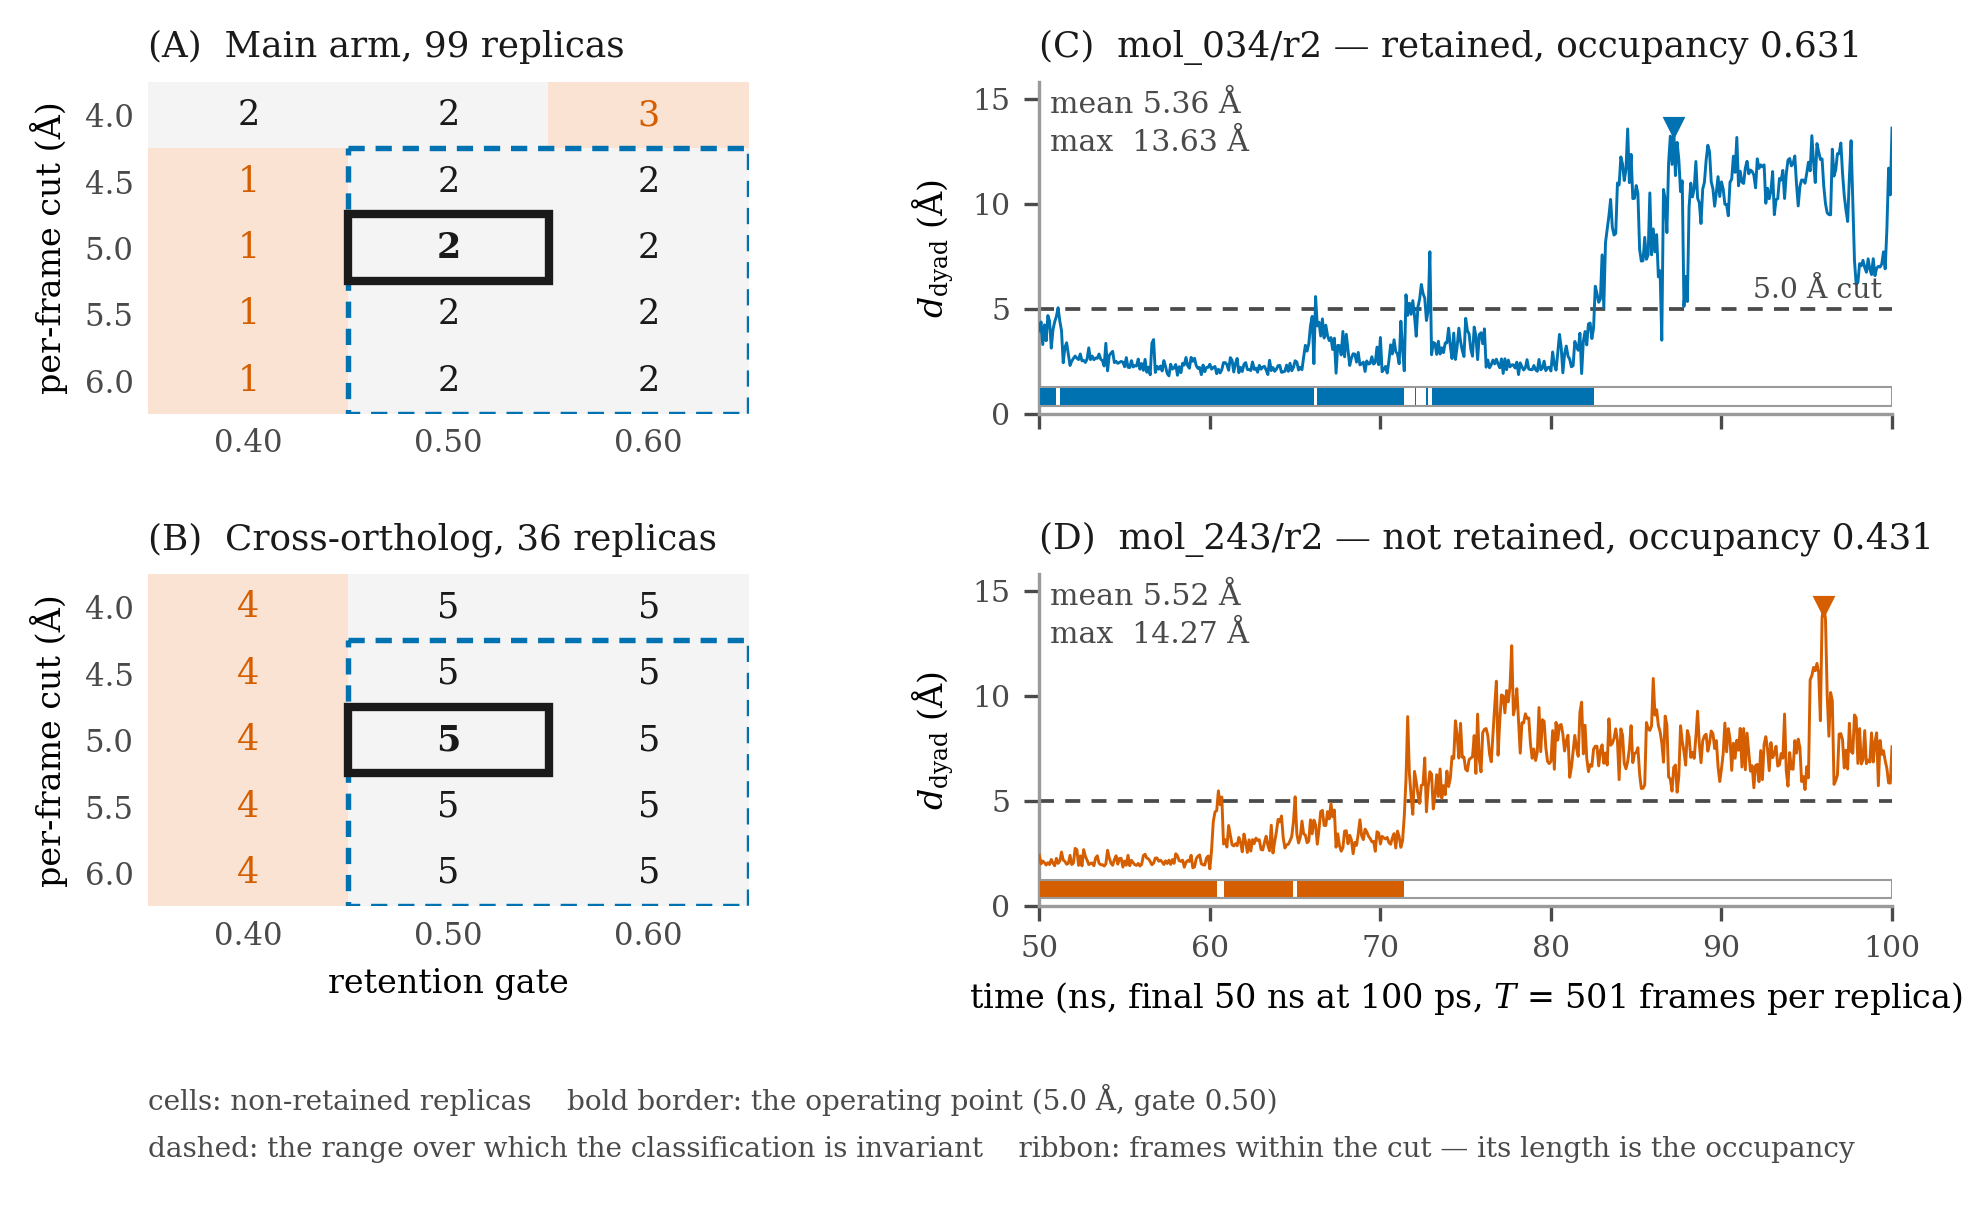

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_3.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_3.pdf`</sub>

In [40]:
# 并入自 cell_figure3.py（2026-11-20）
# ============================================================
# Figure 3 · 占据率分类对其双阈之不敏感性 · 临界副本的驻留与距离      （§3.2.1）
# ============================================================
# 本单元**不自行计算敏感性矩阵**。该矩阵是 Table S18 的内容，已由上游单元算出并
# 自检（5.0 Å / 0.50 下须复现主臂 2、跨臂 5）。此处取用 `S18`，故同一个数在全稿
# 只有一处来源（规则 3）。顺带免去重读 135 份 .npz。
#
# 右幅另读两份逐帧数组：那是两条**临界**副本的 d_dyad(t)，不是汇总量，
# S18 中没有，须单独取。
#
# ⚠ 整幅包在函数里，其局部一个也不外泄。
def _figure_occ():
    from matplotlib.patches import Rectangle
    if "S18" not in globals():
        raise RuntimeError("Figure 3 须在 Table S18 之后运行：它取用 S18，不自算矩阵。")
    _S = globals()["S18"]
    INK, INK2, MUTED = "#1a1a1a", "#4a4a4a", "#9a9a9a"
    C1, C2 = "#0072B2", "#D55E00"
    CUTS  = [4.0, 4.5, 5.0, 5.5, 6.0]
    GATES = [0.40, 0.50, 0.60]
    DCUT, GATE = 5.0, 0.50

    # ── 自 S18 还原两幅 5×3 矩阵（不重算）────────────────────────────
    def grid_of(arm):
        sub = {r["frame_cut_A"]: r for _, r in _S[_S["arm"] == arm].iterrows()}
        missing = [("%.1f" % c) for c in CUTS if ("%.1f" % c) not in sub]
        if missing:
            raise AssertionError("S18 缺 %s 臂的切断 %s —— 两处的 CUTS 不一致" % (arm, missing))
        import numpy as _np
        return (_np.array([[int(sub["%.1f" % c]["n_lost_at_%.2f" % g]) for g in GATES]
                           for c in CUTS]),
                int(sub["%.1f" % DCUT]["replicas"]))
    Gm, n_main  = grid_of("main")
    Gc, n_cross = grid_of("cross")

    # ── 右幅：两条临界副本 ───────────────────────────────────────────
    TR = [("mol_034/r2", "pool_mol_034__6W63__primary__r2.npz", C1, "retained"),
          ("mol_243/r2", "pool_mol_243__6W63__primary__r2.npz", C2, "not retained")]
    _ser = {}
    for _lab, _fn, _, _ in TR:
        _p = resolve("逐帧二联体距离 · %s" % _lab,
                     ["results/aud_main_site_occupancy_series/%s" % _fn])
        _ser[_fn] = np.load(_p, allow_pickle=True)
    _z0 = _ser[TR[0][1]]
    t0, st = int(_z0["start"]), int(_z0["stride"])
    T_frames = int(_z0["d_dyad"].size)

    fig = plt.figure(figsize=(7.5, 4.75))
    gs = fig.add_gridspec(3, 2, width_ratios=[1.0, 1.42], height_ratios=[1.0, 1.0, 0.34],
                          wspace=0.40, hspace=0.62)
    am = fig.add_subplot(gs[0, 0]); ac = fig.add_subplot(gs[1, 0])
    alg = fig.add_subplot(gs[2, :])
    ax1 = fig.add_subplot(gs[0, 1]); ax2 = fig.add_subplot(gs[1, 1], sharex=ax1, sharey=ax1)

    def mat(ax, G, title):
        ref = G[CUTS.index(DCUT)][GATES.index(GATE)]
        ax.imshow((G != ref).astype(float),
                  cmap=plt.cm.colors.ListedColormap(["#f4f4f4", "#fbe3d4"]),
                  vmin=0, vmax=1, aspect="auto")
        for i, c in enumerate(CUTS):
            for j, g in enumerate(GATES):
                ax.text(j, i, "%d" % G[i, j], ha="center", va="center", fontsize=8.4,
                        color=C2 if G[i, j] != ref else INK,
                        fontweight="bold" if (c == DCUT and g == GATE) else "normal")
        ax.add_patch(Rectangle((GATES.index(GATE) - 0.5, CUTS.index(DCUT) - 0.5), 1, 1,
                               fill=False, ec=INK, lw=2.0, zorder=5))
        ax.add_patch(Rectangle((GATES.index(0.50) - 0.5, CUTS.index(4.5) - 0.5), 2, 4,
                               fill=False, ec=C1, lw=1.3, ls=(0, (3, 2)), zorder=4))
        ax.set_xticks(range(3)); ax.set_xticklabels(["%.2f" % g for g in GATES], fontsize=7.4)
        ax.set_yticks(range(5)); ax.set_yticklabels(["%.1f" % c for c in CUTS], fontsize=7.4)
        ax.set_title(title, loc="left", color=INK, fontsize=8.6); ax.tick_params(length=0)
        for s_ in ("top", "right", "left", "bottom"): ax.spines[s_].set_visible(False)

    mat(am, Gm, "(A)  Main arm, %d replicas" % n_main)
    mat(ac, Gc, "(B)  Cross-ortholog, %d replicas" % n_cross)
    am.set_ylabel("per-frame cut (Å)", fontsize=8)
    ac.set_ylabel("per-frame cut (Å)", fontsize=8)
    ac.set_xlabel("retention gate", fontsize=8)

    tt = None
    for pl, (ax, (lab, fn, col, verdict)) in zip(("C", "D"), zip((ax1, ax2), TR)):
        d = _ser[fn]["d_dyad"]
        tt = (t0 + np.arange(d.size) * st) * 0.01            # 10 ps/帧 → ns
        occ = float((d <= DCUT).mean())
        ax.axhline(DCUT, color=INK2, lw=0.9, ls=(0, (4, 3)), zorder=2)
        ax.plot(tt, d, lw=0.7, color=col, zorder=3)
        k = int(np.argmax(d)); ax.plot([tt[k]], [d[k]], marker="v", ms=4.0, color=col, zorder=5)
        ax.fill_between(tt, 0.35, 1.25, where=(d <= DCUT), color=col, lw=0, zorder=4, step="mid")
        ax.add_patch(Rectangle((tt[0], 0.35), tt[-1] - tt[0], 0.90,
                               fill=False, ec=MUTED, lw=0.5, zorder=5))
        ax.set_ylim(0, 15.8); ax.set_xlim(tt[0], tt[-1])
        ax.set_title("(%s)  %s — %s, occupancy %.3f" % (pl, lab, verdict, occ),
                     loc="left", color=INK, fontsize=8.6)
        ax.annotate("mean %.2f Å\nmax  %.2f Å" % (d.mean(), d.max()),
                    (tt[0] + 0.6, 15.4), fontsize=7.2, color=INK2,
                    ha="left", va="top", linespacing=1.45)
        ax.set_ylabel("$d_{\\mathrm{dyad}}$ (Å)", fontsize=8)
        for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
        ax.spines["left"].set_color(MUTED); ax.spines["bottom"].set_color(MUTED)
        ax.tick_params(colors=INK2, labelsize=7.2)

    ax1.annotate("%.1f Å cut" % DCUT, (tt[-1] - 0.6, DCUT + 0.5),
                 fontsize=6.8, color=INK2, ha="right")
    plt.setp(ax1.get_xticklabels(), visible=False)
    ax2.set_xlabel("time (ns, final 50 ns at 100 ps, $T$ = %d frames per replica)" % T_frames,
                   fontsize=8)

    # 图例两行，不作一行：一行约 230 字符、宽约 10.7 in，越出 7.5 in 画布右缘；
    # bbox_inches="tight" 会把它收进来，整幅被撑至 10.18 in，压到 7.0 in 后
    # 最小字号只剩 4.61 pt（下限 4.5），余量不足一成。
    alg.axis("off"); alg.set_xlim(0, 1); alg.set_ylim(0, 1)
    alg.text(0.0, 0.70, "cells: non-retained replicas    bold border: the operating point "
                        "(%.1f Å, gate %.2f)" % (DCUT, GATE),
             fontsize=6.7, color=INK2, ha="left", va="center")
    alg.text(0.0, 0.26, "dashed: the range over which the classification is invariant    "
                        "ribbon: frames within the cut — its length is the occupancy",
             fontsize=6.7, color=INK2, ha="left", va="center")
    return fig

_f3 = _figure_occ()
save_fig(_f3, 3, "the occupancy classification is insensitive to both of its thresholds",
         caption=(
             "Insensitivity of the active-site occupancy classification to its two thresholds, "
             "and two replicas at the boundary. (A, B) Number of non-retained replicas in the "
             "main and cross-ortholog arms across five per-frame distance cuts and three "
             "retention gates; the bold border marks the operating point used throughout "
             "(5.0 Å, gate 0.50), and the dashed outline the region over which the "
             "classification does not change. Shaded cells differ from the operating point. "
             "The matrix is the one reported as Table S18 and is computed once for both. "
             "(C, D) Ligand–dyad distance over the analyzed final 50 ns for one retained and "
             "one non-retained replica; the ribbon marks frames within the 5.0 Å cut, so its "
             "length is the occupancy, and the marker gives the single largest excursion. "
             "The two thresholds are the exposure named in §4.4; this figure bounds it rather "
             "than correcting it, and no value, axis or frozen function was changed to produce it."))


In [41]:
# ============================================================
# Table S11 · 两例歧义位姿的裁决                    （§3.4.8）
# ============================================================
# 盘点所得：phase3_dG_aggregated_SOLV_V3.csv 为 **33 行**（含两个 secondary），
# 键为 mol_dir（形如 pool_mol_011__6W63__secondary），故本表可成。
p = resolve("主臂 ΔG 汇总（33 体系）", ["results/phase3_dG_aggregated_SOLV_V3.csv"])
Gm = expect_rows(pd.read_csv(p), 33, "33 个体系 = 31 主位姿 + 2 secondary")
gm_id = "mol_dir"
sel = Gm[Gm[gm_id].astype(str).str.contains("pool_mol_011|pool_mol_020")].copy()
expect_rows(sel, 4, "两分子 × primary/secondary")
sel["pose"] = np.where(sel[gm_id].str.contains("secondary"), "secondary", "primary")
sel["mol"] = sel[gm_id].str.split("__").str[0]
piv = sel.pivot(index="mol", columns="pose", values="dG_PBSA_mean")
piv["difference_secondary_minus_primary"] = piv["secondary"] - piv["primary"]
piv["SE_of_difference_from_sec_3_4_8"] = [2.48 if m.endswith("011") else 1.45 for m in piv.index]
piv["ratio"] = (piv.difference_secondary_minus_primary.abs()
                / piv.SE_of_difference_from_sec_3_4_8)
print(piv.to_string())
print("  §3.4.8 载：差 2.04 与 0.93 · SE 2.48 与 1.45 · 比 0.82 与 0.64")

out = sel.merge(piv.reset_index(), on="mol", how="left").sort_values([gm_id])
save_table(out, "S11",
           "Adjudication of the two ambiguous docked poses. Each pair of clusters is separated by "
           "about 9 A in atom-order RMSD while their docking affinities differ by less than 0.01 "
           "kcal/mol. Both differences favor the secondary pose, but neither reaches one standard "
           "error of its own difference, so no preference is established. The ranking uses primary "
           "poses only, which is limitation 10 of §4.5.")

  [主臂 ΔG 汇总（33 体系）] results/phase3_dG_aggregated_SOLV_V3.csv
  条数 33 ✓  (33 个体系 = 31 主位姿 + 2 secondary)
  条数 4 ✓  (两分子 × primary/secondary)
pose          primary  secondary  difference_secondary_minus_primary  SE_of_difference_from_sec_3_4_8     ratio
mol                                                                                                            
pool_mol_011     4.13     2.0867                             -2.0433                             2.48  0.823911
pool_mol_020     1.50     0.5700                             -0.9300                             1.45  0.641379
  §3.4.8 载：差 2.04 与 0.93 · SE 2.48 与 1.45 · 比 0.82 与 0.64
  → Table_S11  (.csv + .md)   4 行 × 11 列
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S11.csv
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S11.md


**Table S11.** Adjudication of the two ambiguous docked poses.

| mol_dir                       | dG_PBSA_mean | sigma_PBSA | n_rep | pose      | mol          | primary | secondary | difference_secondary_minus_primary | SE_of_difference_from_sec_3_4_8 |  ratio |
|:------------------------------|-------------:|-----------:|------:|:----------|:-------------|--------:|----------:|-----------------------------------:|--------------------------------:|-------:|
| pool_mol_011__6W63__primary   |       4.1300 |     3.4060 |     3 | primary   | pool_mol_011 |  4.1300 |    2.0867 |                            -2.0433 |                          2.4800 | 0.8239 |
| pool_mol_011__6W63__secondary |       2.0867 |     2.6127 |     3 | secondary | pool_mol_011 |  4.1300 |    2.0867 |                            -2.0433 |                          2.4800 | 0.8239 |
| pool_mol_020__6W63__primary   |       1.5000 |     1.0718 |     3 | primary   | pool_mol_020 |  1.5000 |    0.5700 |                            -0.9300 |                          1.4500 | 0.6414 |
| pool_mol_020__6W63__secondary |       0.5700 |     2.2718 |     3 | secondary | pool_mol_020 |  1.5000 |    0.5700 |                            -0.9300 |                          1.4500 | 0.6414 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S11.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S11.md`</sub>

,mol_dir,dG_PBSA_mean,sigma_PBSA,n_rep,pose,mol,primary,secondary,difference_secondary_minus_primary,SE_of_difference_from_sec_3_4_8,ratio
0,pool_mol_011__6W63__primary,4.1300,3.4060,3,primary,pool_mol_011,4.13,2.0867,-2.0433,2.48,0.823911
1,pool_mol_011__6W63__secondary,2.0867,2.6127,3,secondary,pool_mol_011,4.13,2.0867,-2.0433,2.48,0.823911
2,pool_mol_020__6W63__primary,1.5000,1.0718,3,primary,pool_mol_020,1.50,0.5700,-0.9300,1.45,0.641379
3,pool_mol_020__6W63__secondary,0.5700,2.2718,3,secondary,pool_mol_020,1.50,0.5700,-0.9300,1.45,0.641379


  队列回归：ΔG_PBSA = +0.3205 × HA -10.6038   n=33  r=0.246  r²=0.061  t=1.42  p=0.167
  反转 +6.4833 kcal/mol；队列尺寸趋势于 15 个重原子之差上预计 +4.81（占 74%）
  → Figure_S5  (.png 300 dpi + .pdf)  registered sign test and the size dependence of the tested axis
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S5.png   （300 dpi，投稿用矢量图见下一行）
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S5.pdf   （矢量，ACS 投稿以此为佳）


**Figure S5.** The registered sign test of §3.4.3 and the size dependence of the axis it tested. **(A)** ΔG_PBSA against reported IC50 for the two anchors, with the standard error of the three per-replica means; the horizontal bar spans the reported potency range for ensitrelvir and the dashed arrow marks the direction the test required. The less potent compound scored 6.48 kcal/mol more favorably. **(B)** ΔG_PBSA against ligand heavy-atom count for the 33 main-arm systems, with the two anchors and both X77 starting poses marked and the cohort least-squares line drawn. The axis carries a positive size dependence of +0.32 kcal/mol per heavy atom, so larger ligands score less favorably in this configuration; across the 15 heavy-atom difference between the anchors the cohort trend corresponds to +4.81 kcal/mol, of the same order as the inversion itself. The trend is not statistically significant (r = 0.25, p = 0.17) and AVI-1084 lies below the cohort size range, so this is an alternative the data do not exclude and not a correction to be applied. Panel B is the reason the magnitude of the inversion is not interpreted as a measure of affinity-blindness (§4.4).

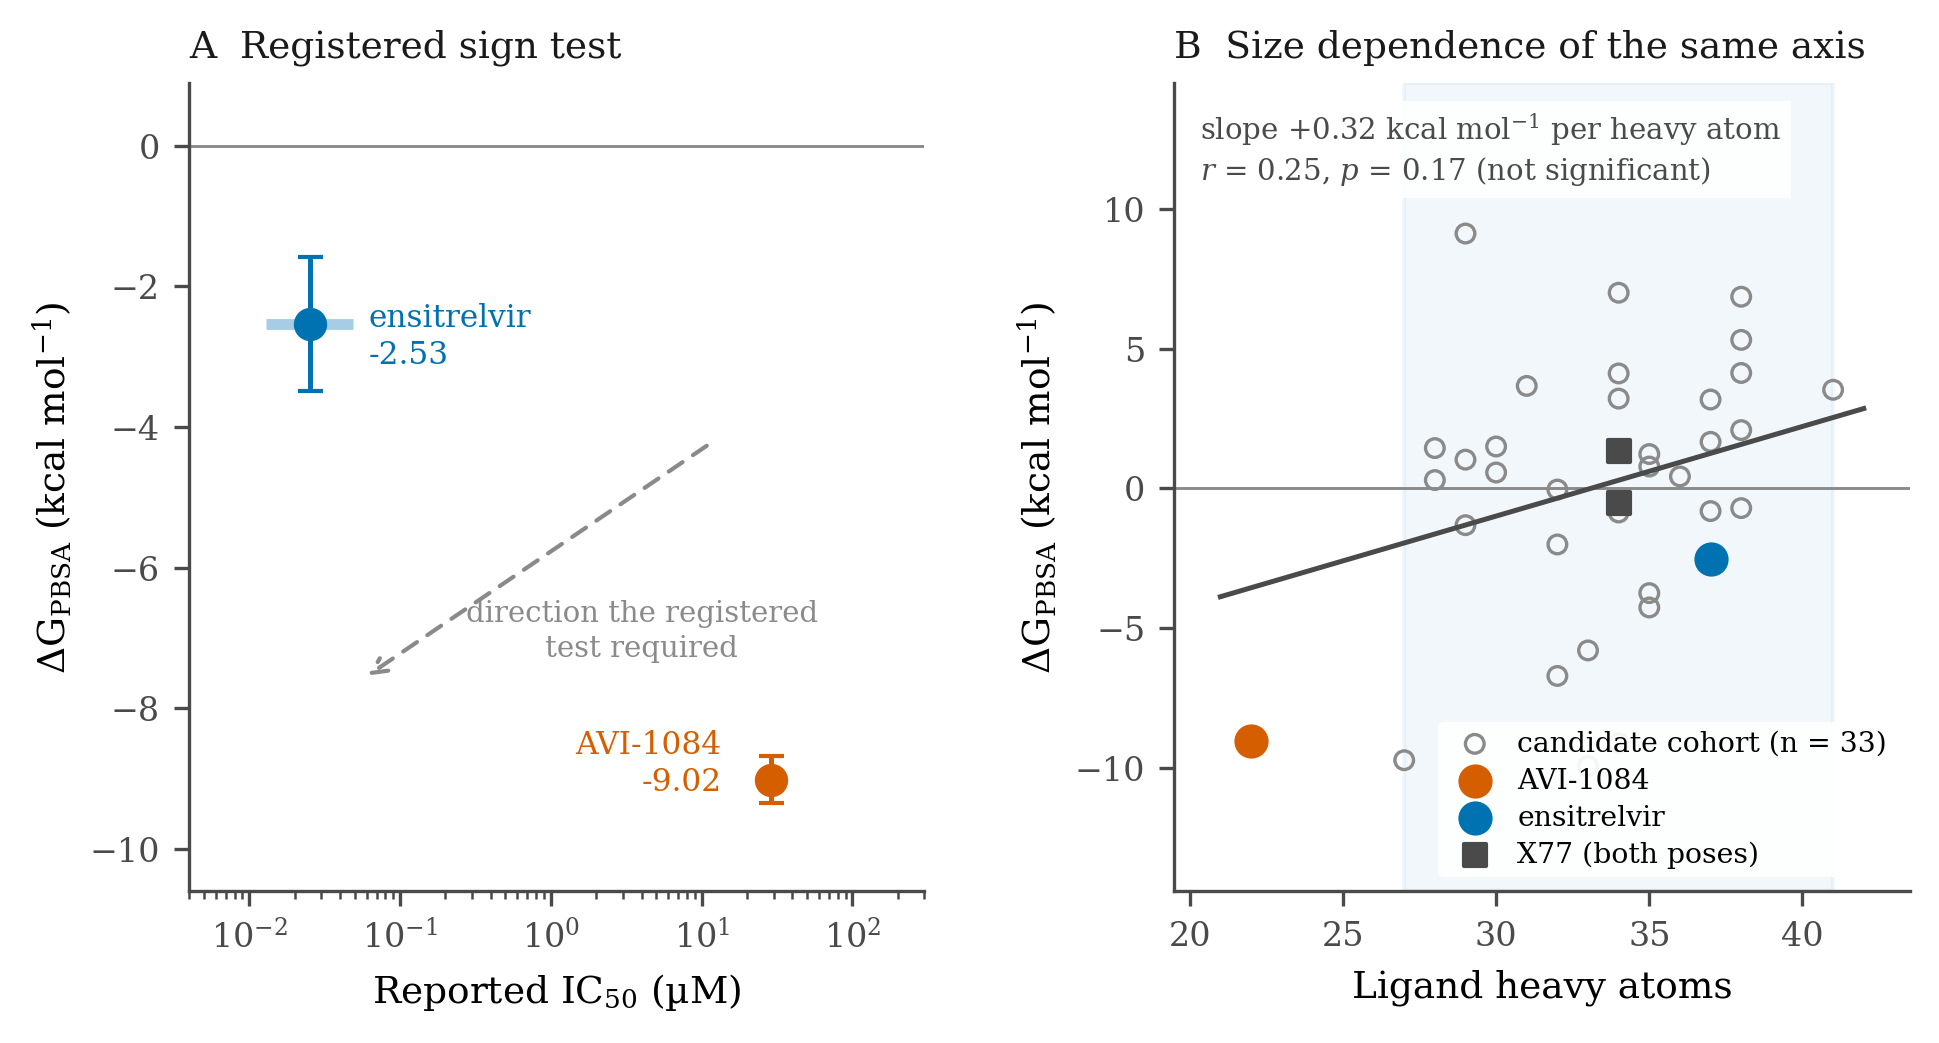

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S5.png`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Figure_S5.pdf`</sub>

In [42]:
# ============================================================
# Figure S5 · 登记符号检验之结果，及其尺寸依赖       （§3.4.3 · §3.4.5 · §4.4）
# ============================================================
# 本图之设，为把 §3.4 的结果与其混杂同置一处，使读者不必自行回归即可见之。
# 甲幅：两个锚点之 ΔG_PBSA 对效价，逐复本点俱列 —— 即那项登记过的检验。
# 乙幅：ΔG_PBSA 对重原子数，以 33 个主臂体系为背景队列，拟合线及其 r 与 p 俱标。
#       乙幅所示者，为该轴携有一项与该反转同阶的尺寸依赖；此事未经检出显著，
#       故所陈者为「未能排除」，而非「已然解释」。绝不可读作一项可减去的校正。
import math
from scipy import stats
from rdkit import Chem as _Chem                 # 本块自备，不倚前文之条件引入

for _need in ("M14", "Gm", "R", "HEAVY", "gm_id"):
    if _need not in dir():
        raise NameError("Figure S5 须在 %s 之后运行；当前命名空间中无之。" % _need)

_hv = {}
for _, _r in M14.iterrows():
    _mo = _Chem.MolFromSmiles(_r.canonical_smiles)
    if _mo is not None:
        _hv[str(_r.mol_id)] = _mo.GetNumHeavyAtoms()
if len(_hv) != len(M14):
    raise ValueError("Figure S5：%d/%d 个候选之 SMILES 未能解析，重原子数不全。"
                     % (len(M14) - len(_hv), len(M14)))

_C = Gm.copy()
_C["mol"] = _C[gm_id].astype(str).str.split("__").str[0]
_C["heavy_atoms"] = _C["mol"].map(_hv)
if _C.heavy_atoms.isna().any():
    raise KeyError("Figure S5：下列体系无重原子数，须自 Table S14 之 SMILES 补入：%s"
                   % _C.loc[_C.heavy_atoms.isna(), gm_id].tolist())

# 队列回归（以 33 个体系为据），斜率、r 与双尾 p 一并算出，不取现成之数
_x = _C.heavy_atoms.to_numpy(float); _y = _C.dG_PBSA_mean.to_numpy(float)
_n = len(_x)
_slope, _icept = np.polyfit(_x, _y, 1)
_r = float(np.corrcoef(_x, _y)[0, 1])
_t = _r * math.sqrt(_n - 2) / math.sqrt(1 - _r ** 2)
_p = 2 * stats.t.sf(abs(_t), _n - 2)
print("  队列回归：ΔG_PBSA = %+.4f × HA %+.4f   n=%d  r=%.3f  r²=%.3f  t=%.2f  p=%.3f"
      % (_slope, _icept, _n, _r, _r ** 2, _t, _p))

# 面板之四体系：自 R 取，名与 §3.4 所用者同
def _rv(k, col="dG_PBSA_mean"):
    _s = R[R.system.astype(str).str.lower().str.contains(k)]
    if len(_s) != 1:
        raise KeyError("Figure S5：参考面板中 %r 不唯一（%d 条）" % (k, len(_s)))
    return float(_s[col].iloc[0])

_AVI, _ENS = _rv("avi"), _rv("ensitrelvir")
_sAVI, _sENS = _rv("avi", "sigma_PBSA"), _rv("ensitrelvir", "sigma_PBSA")
_haAVI, _haENS = HEAVY["avi"], HEAVY["ensitrelvir"]
_inv = _ENS - _AVI
_pred15 = _slope * (_haENS - _haAVI)
print("  反转 %+.4f kcal/mol；队列尺寸趋势于 %d 个重原子之差上预计 %+.2f（占 %.0f%%）"
      % (_inv, _haENS - _haAVI, _pred15, 100 * _pred15 / _inv))
# 效价：§3.4.2 所载之区间（ensitrelvir 0.013–0.049 µM · AVI-1084 29.0 µM）
_IC = {"ensitrelvir": (0.013, 0.049), "AVI-1084": (29.0, 29.0)}

fig, (s1, s2) = plt.subplots(1, 2, figsize=(7.4, 3.5),
                             gridspec_kw={"wspace": 0.34})

# ── 甲幅：那项登记过的检验 ────────────────────────────────
for _nm, _dg, _sd, _col in (("AVI-1084", _AVI, _sAVI, C_LOST),
                            ("ensitrelvir", _ENS, _sENS, C_KEEP)):
    _lo, _hi = _IC[_nm]
    _xc = math.sqrt(_lo * _hi)                  # 区间之几何中点，仅作绘图之位
    s1.errorbar(_xc, _dg, yerr=_sd / math.sqrt(3), fmt="o", ms=7, color=_col,
                capsize=3, lw=1.2, zorder=4, label=_nm)
    if _lo != _hi:
        s1.plot([_lo, _hi], [_dg, _dg], color=_col, lw=2.6, alpha=0.35,
                solid_capstyle="butt", zorder=3)
    _dx, _ha = ((14, -3), "left") if _nm == "ensitrelvir" else ((-12, 4), "right")
    s1.annotate("%s\n%.2f" % (_nm, _dg), (_xc, _dg), textcoords="offset points",
                xytext=_dx, fontsize=7.5, color=_col, ha=_ha, va="center",
                linespacing=1.25)
# 虚线箭头只示「检验所要求之方向」，不是一条拟合线；故不触及任何数据点
s1.annotate("", xy=(0.055, -7.6), xytext=(12.0, -4.2),
            arrowprops=dict(arrowstyle="->", color=MUTED, lw=1.0,
                            ls=(0, (4, 3)), shrinkA=2, shrinkB=2))
s1.text(4.0, -6.9, "direction the registered\ntest required", fontsize=7,
        color=MUTED, ha="center", va="center", linespacing=1.3)
s1.set_xscale("log")
s1.set_xlim(4e-3, 3e2)
s1.set_ylim(-10.6, 0.9)
s1.set_xlabel("Reported IC$_{50}$ (µM)")
s1.set_ylabel("ΔG$_{\\mathrm{PBSA}}$ (kcal mol$^{-1}$)")
s1.set_title("A  Registered sign test", loc="left", color=INK, fontsize=9)
s1.axhline(0, color=MUTED, lw=0.7, zorder=1)

# ── 乙幅：尺寸依赖 ───────────────────────────────────────
s2.scatter(_x, _y, s=20, facecolor="none", edgecolor=MUTED, lw=0.8,
           zorder=3, label="candidate cohort (n = %d)" % _n)
_xs = np.linspace(min(_x.min(), _haAVI) - 1, _x.max() + 1, 50)
s2.plot(_xs, _slope * _xs + _icept, color=INK2, lw=1.2, zorder=4)
s2.fill_between(_xs, _slope * _xs + _icept, alpha=0.0)
s2.scatter([_haAVI], [_AVI], s=52, color=C_LOST, zorder=6, label="AVI-1084")
s2.scatter([_haENS], [_ENS], s=52, color=C_KEEP, zorder=6, label="ensitrelvir")
_x77done = False
for _k in ("x77__6w63__primary", "x77__6w63__nearnative"):
    try:
        s2.scatter([HEAVY["x77"]], [_rv(_k)], s=30, marker="s", color=INK2, zorder=5,
                   label=None if _x77done else "X77 (both poses)")
        _x77done = True
    except KeyError:
        pass
s2.axvspan(_x.min(), _x.max(), color=C_KEEP, alpha=0.05, zorder=1)
s2.set_xlim(19.5, 43.5)
# 顶部留白按本队列之最大值定，而非写死：HPC 与本机字体不同，字块高度随之而异，
# 故另加不透明底框，使该注记在任何字体下都压得住其后之点（2026-11-15）。
# 2026-11-16：下方另留白，使图例不压队列点；若某点仍落于其后，图例之不透明底框
# 保证文字仍可读（与上方注记同一办法）。
s2.set_ylim(min(-14.4, float(_y.min()) - 4.4), max(11.4, float(_y.max()) + 5.4))
s2.annotate("slope %+.2f kcal mol$^{-1}$ per heavy atom\n$r$ = %.2f, $p$ = %.2f (not significant)"
            % (_slope, _r, _p), xy=(0.035, 0.965), xycoords="axes fraction",
            va="top", ha="left", fontsize=7, color=INK2, linespacing=1.3, zorder=8,
            bbox=dict(boxstyle="square,pad=0.35", facecolor="white",
                      edgecolor="none", alpha=0.92))
s2.set_xlabel("Ligand heavy atoms")
s2.set_ylabel("ΔG$_{\\mathrm{PBSA}}$ (kcal mol$^{-1}$)")
s2.set_title("B  Size dependence of the same axis", loc="left", color=INK, fontsize=9)
_lg = s2.legend(frameon=True, framealpha=0.92, facecolor="white", edgecolor="none",
                fontsize=6.8, loc="lower right", handletextpad=0.5,
                borderpad=0.3, labelspacing=0.35)
_lg.set_zorder(8)
s2.axhline(0, color=MUTED, lw=0.7, zorder=1)

save_fig(fig, "S5", "registered sign test and the size dependence of the tested axis",
         caption="The registered sign test of §3.4.3 and the size dependence of the axis it "
                 "tested. **(A)** ΔG_PBSA against reported IC50 for the two anchors, with the "
                 "standard error of the three per-replica means; the horizontal bar spans the "
                 "reported potency range for ensitrelvir and the dashed arrow marks the "
                 "direction the test required. The less potent compound scored "
                 "%.2f kcal/mol more favorably. **(B)** ΔG_PBSA against ligand heavy-atom count "
                 "for the %d main-arm systems, with the two anchors and both X77 starting poses "
                 "marked and the cohort least-squares line drawn. The axis carries a positive "
                 "size dependence of %+.2f kcal/mol per heavy atom, so larger ligands score less "
                 "favorably in this configuration; across the %d heavy-atom difference between "
                 "the anchors the cohort trend corresponds to %+.2f kcal/mol, of the same order "
                 "as the inversion itself. The trend is not statistically significant "
                 "(r = %.2f, p = %.2f) and AVI-1084 lies below the cohort size range, so this "
                 "is an alternative the data do not exclude and not a correction to be applied. "
                 "Panel B is the reason the magnitude of the inversion is not interpreted as a "
                 "measure of affinity-blindness (§4.4)."
                 % (_inv, _n, _slope, _haENS - _haAVI, _pred15, _r, _p))

In [43]:
# ============================================================
# Table S12 · PB 与 GB 端点的比较                  （§3.4.9）
# ============================================================
# 盘点所得：step8c_gbsa_crossval_SOLV_V3.csv **自带 PB 与 GB 两列**（33 行），
# 故无须与 phase3 联接。**另有 step8c_gbsa_crossval_SOLV.csv（28 行）= V2 队列，不得用。**
p = resolve("GB 交叉核对", ["results/step8c_gbsa_crossval_SOLV_V3.csv"])
GB = expect_rows(pd.read_csv(p), 33, "33 个体系（31 主位姿 + 2 secondary）")
print("  实有列:", list(GB.columns))
J = GB[GB["mol_dir"].astype(str).str.contains("primary")].copy()
J = J[J["mol"].astype(str).isin(K[kid].astype(str).tolist())]
expect_rows(J, 31, "只取 31 个主位姿，与打分队列一致")

from scipy.stats import spearmanr as _sp2
rho_pb_gb = _sp2(J.dG_PBSA_mean, J.dG_GBSA_mean).statistic
# 2 SE = 2 × σ/√3（n = 3 个复本）= 1.1547 σ。
# **第四版此处误作 2*2/√3，把分辨率放大了一倍**；稿中 §3.4.9 的 2.70 / 4.57 是对的，
# 是 notebook 错而非稿错。此处改正，并把稿载五数一并钉成断言。
res = 2 / np.sqrt(3)
summ = pd.DataFrame([
    {"quantity": "median dG (kcal/mol)", "Poisson-Boltzmann": J.dG_PBSA_mean.median(),
     "generalized-Born": J.dG_GBSA_mean.median()},
    {"quantity": "minimum dG", "Poisson-Boltzmann": J.dG_PBSA_mean.min(),
     "generalized-Born": J.dG_GBSA_mean.min()},
    {"quantity": "maximum dG", "Poisson-Boltzmann": J.dG_PBSA_mean.max(),
     "generalized-Born": J.dG_GBSA_mean.max()},
    {"quantity": "candidates with positive mean",
     "Poisson-Boltzmann": int((J.dG_PBSA_mean > 0).sum()),
     "generalized-Born": int((J.dG_GBSA_mean > 0).sum())},
    {"quantity": "median inter-replica sigma", "Poisson-Boltzmann": J.sigma_PBSA.median(),
     "generalized-Born": J.sigma_GBSA.median()},
    {"quantity": "maximum inter-replica sigma", "Poisson-Boltzmann": J.sigma_PBSA.max(),
     "generalized-Born": J.sigma_GBSA.max()},
    {"quantity": "pairwise resolution at 2 SE",
     "Poisson-Boltzmann": J.sigma_PBSA.median() * res,
     "generalized-Born": J.sigma_GBSA.median() * res},
    {"quantity": "Spearman rho between the two", "Poisson-Boltzmann": rho_pb_gb,
     "generalized-Born": rho_pb_gb},
])
print(summ.to_string(index=False))
print("\n  §3.4.9 载：GB 中位 −34.40 · 无一为正 · σ 中位 3.96 对 2.34 ·"
      " 分辨 4.57 对 2.70 · ρ = +0.698")

# **核，不只是印。** 第四版此处只印两行供人眼比对，于是我自己的因子错了一倍也没被拦下。
# 但「不符」有两种来由：稿错，或稿用的是另一个队列。故先按两种队列各算一遍，
# 两者皆不复现，才记作不符 —— 否则便是我拿 31 行的数去对 33 行的话。
print("\n  §3.4.9 所载之数，按两种队列各算一遍（以判稿中之数出自哪一队列）：")
COH = [("n31_primary", J), ("n33_with_secondary", GB)]
chk = []
for q, col, want, kind in [
    ("GB median dG",       "dG_GBSA_mean", -34.40, "median"),
    ("GB sigma median",    "sigma_GBSA",     3.96, "median"),
    ("PB sigma median",    "sigma_PBSA",     2.33, "median"),
    ("GB resolution 2 SE", "sigma_GBSA",     4.57, "res"),
    ("PB resolution 2 SE", "sigma_PBSA",     2.70, "res"),
]:
    row, hit = {"quantity": q, "paper": want}, []
    for lab, d in COH:
        v = float(d[col].median()) * (res if kind == "res" else 1.0)
        row[lab] = v
        if abs(round(v, 2) - want) < 1e-9: hit.append(lab)
    row["reproduced_by"] = ", ".join(hit) if hit else "neither"
    chk.append(row)
C9 = pd.DataFrame(chk)
print(C9.to_string(index=False))
for r in chk:
    if r["reproduced_by"] == "neither":
        warn("§3.4.9 的「%s = %.2f」两种队列皆不复现（31 列算得 %.4f · 33 列算得 %.4f）。"
             % (r["quantity"], r["paper"], r["n31_primary"], r["n33_with_secondary"]))

# 余两项与队列无关，直接核
if int(summ.loc[summ.quantity == "candidates with positive mean",
                "generalized-Born"].iloc[0]) != 0:
    warn("§3.4.9 载 GB 端点无一为正，实算非零。")
if abs(rho_pb_gb - 0.698) > 0.001:
    warn("Table S9 的 PB–GB Spearman ρ 实算 %+.4f，§3.4.9 载 +0.698。" % rho_pb_gb)

save_table(summ, "S12",
           "Poisson-Boltzmann against generalized-Born on identical frames of identical "
           "trajectories. The positive location of the Poisson-Boltzmann distribution is not "
           "reproduced, which removes the solvation treatment as a *general* explanation for it "
           "while establishing nothing about which treatment is nearer correct - the two differ "
           "in their non-polar terms as well, and neither is calibrated against potency. The "
           "generalized-Born endpoint is the less precise of the two, so substituting it would "
           "reduce rather than improve the resolution available to the ranking (§3.4.9).")
J.to_csv(os.path.join(OUTDIR, "Table_S12_per_candidate.csv"), index=False)
saved(os.path.join(OUTDIR, "Table_S12_per_candidate.csv"), "逐候选明细")

  [GB 交叉核对] results/step8c_gbsa_crossval_SOLV_V3.csv
  条数 33 ✓  (33 个体系（31 主位姿 + 2 secondary）)
  实有列: ['mol_dir', 'dG_PBSA_mean', 'sigma_PBSA', 'n_rep', 'dG_GBSA_mean', 'sigma_GBSA', 'n', 'CV_PBSA_%', 'CV_GBSA_%', 'mol', 'formal_charge', 'charge_stratum']
  条数 31 ✓  (只取 31 个主位姿，与打分队列一致)
                     quantity  Poisson-Boltzmann  generalized-Born
         median dG (kcal/mol)           0.783300        -34.403300
                   minimum dG          -9.930000        -48.573300
                   maximum dG           9.116700        -20.196700
candidates with positive mean          18.000000          0.000000
   median inter-replica sigma           2.334700          3.957100
  maximum inter-replica sigma           6.950900         13.898100
  pairwise resolution at 2 SE           2.695879          4.569266
 Spearman rho between the two           0.697581          0.697581

  §3.4.9 载：GB 中位 −34.40 · 无一为正 · σ 中位 3.96 对 2.34 · 分辨 4.57 对 2.70 · ρ = +0.698

  §3.4.9 所载之数，按两种队列各算一遍（以判稿

**Table S12.** Poisson-Boltzmann against generalized-Born on identical frames of identical trajectories.

| quantity                      | Poisson-Boltzmann | generalized-Born |
|:------------------------------|------------------:|-----------------:|
| median dG (kcal/mol)          |            0.7833 |         -34.4033 |
| minimum dG                    |           -9.9300 |         -48.5733 |
| maximum dG                    |            9.1167 |         -20.1967 |
| candidates with positive mean |           18.0000 |           0.0000 |
| median inter-replica sigma    |            2.3347 |           3.9571 |
| maximum inter-replica sigma   |            6.9509 |          13.8981 |
| pairwise resolution at 2 SE   |            2.6959 |           4.5693 |
| Spearman rho between the two  |            0.6976 |           0.6976 |

<sub>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S12.csv`<br>已存 · `/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S12.md`</sub>

     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S12_per_candidate.csv   （逐候选明细）


'/mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/Table_S12_per_candidate.csv'

In [44]:
# ============================================================
# 末之〇 · §7.4 三个版本号：自实物读出，不自记忆写入
# ============================================================
# GROMACS 的版本写在每一份 md.log 的抬头里，故不必问人，读一份即得；
# 并核其在全部 147 条中是否同一。MDAnalysis 与 RDKit 自本环境取。
import platform as _pf
gmxv, seen_v = None, {}
for arm in ("md_solv_v3", "md_solv_v3_ref", "cross_solv_v3"):
    for h in glob.glob(os.path.join(ROOT, arm, "*", "r*", "06_md", "md.log")):
        try:
            head = open(h, errors="replace").read(4000)
        except Exception:
            continue
        m = re.search(r"GROMACS version:?\s*(\S.*)", head)
        if not m:
            m = re.search(r"^\s*GROMACS:\s*\S+,\s*version\s*(\S+)", head, re.M)
        if m:
            v = m.group(1).strip()
            seen_v[v] = seen_v.get(v, 0) + 1
if seen_v:
    gmxv = max(seen_v, key=seen_v.get)
    print("  GROMACS 版本（自 md.log 抬头读出）: %s   —— 见于 %d 份日志"
          % (gmxv, seen_v[gmxv]))
    if len(seen_v) > 1:
        warn("§7.4：md.log 中出现 %d 个不同的 GROMACS 版本 %s —— 须查清何者为准。"
             % (len(seen_v), dict(seen_v)))
else:
    print("  **未自 md.log 读到 GROMACS 版本。** 所试之处（规则 23）："
          "<arm>/*/r*/06_md/md.log 的前 4000 字节，匹配 'GROMACS version'。")
    print("  请在 HPC 上执行： gmx --version | head -1   并把结果告我。")

def _ver(mod):
    try:
        m = __import__(mod); return getattr(m, "__version__", "（无 __version__）")
    except Exception as e:
        return "（本环境无此包：%s）" % type(e).__name__
mdav, rdkv = _ver("MDAnalysis"), _ver("rdkit")
print("  MDAnalysis: %s" % mdav)
print("  RDKit     : %s" % rdkv)

print("\n  ===== §7.4 可直接入稿的一句 =====")
print("     Molecular dynamics was run with GROMACS %s. Trajectory analysis used "
      "MDAnalysis %s. The figure and table notebook was run under Python %s with "
      "NumPy %s, pandas %s, Matplotlib %s, SciPy %s and RDKit %s."
      % (gmxv or "<version>", mdav, _pf.python_version(), np.__version__,
         pd.__version__, matplotlib.__version__,
         __import__("scipy").__version__, rdkv))
print("  （凡仍作 <version> 者，即本 notebook 读不到之物，须自 HPC 另取。）")

  GROMACS 版本（自 md.log 抬头读出）: 2025.4   —— 见于 147 份日志


/mnt/hpc/home/wanghongmei/anaconda3/envs/md_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  MDAnalysis: 2.9.0
  RDKit     : 2025.09.4

  ===== §7.4 可直接入稿的一句 =====
     Molecular dynamics was run with GROMACS 2025.4. Trajectory analysis used MDAnalysis 2.9.0. The figure and table notebook was run under Python 3.10.19 with NumPy 2.2.6, pandas 2.3.3, Matplotlib 3.10.8, SciPy 1.15.2 and RDKit 2025.09.4.
  （凡仍作 <version> 者，即本 notebook 读不到之物，须自 HPC 另取。）


In [45]:
# ============================================================
# 末之三 · Abstract / §5 的数值白名单闸门（含四个坏样本）
# ============================================================
# 这道闸门此前只以散文存在于 `sec_front_back.md` 末节；**一段描述不是闸门**。
# 此处把它写成可执行之物，并自带四个坏样本：闸门须在四个样本上一一失败，
# 且**各因其自身之故**而失败（被别的毛病拦下不算数），否则闸门作废。
# 闸门的输入有三路，**故它永不因找不到文件而不跑**：
#   ① 外部文件——名字表已加宽到 lang2/ 之下各处；
#   ② 本 cell 内嵌之本文（下方 GATE_EMBED，以 sha256 钉住）；
#   ③ 二者俱在则逐字比对：不一致即报警，并**以外部者为准**，
#      因为内嵌者会随稿件改动而过期，而过期不该静悄悄地发生。
GATE_SRC = resolve("Abstract/§5 之源", [
    "ms/sec_front_back.md", "claude/ms/sec_front_back.md", "sec_front_back.md",
    "Scoring/sec_front_back.md", "Scoring/ms/sec_front_back.md",
    "gate_src_embed.md", "ms/gate_src_embed.md", "Scoring/gate_src_embed.md",
    "ms/PRISM_Dyn_V3_full_manuscript_*.md", "PRISM_Dyn_V3_full_manuscript_*.md",
    "ms/PRISM_Dyn_V3_manuscript_*.md", "PRISM_Dyn_V3_manuscript_*.md",
    "Scoring/PRISM_Dyn_V3_manuscript_*.md", "*/PRISM_Dyn_V3_manuscript_*.md",
], required=False,
   deep="**/sec_front_back.md",
   fallback="本 cell 内嵌的 Abstract/§5 快照（以 sha256 钉住，下方即校）")

GATE_EMBED = """# ABSTRACT

Generative pipelines for small-molecule design terminate at a static score, and physics-based rescoring by molecular dynamics is widely used to reduce the resulting candidate sets. What such a stage establishes about its own descriptors is rarely tested. We report a multi-replica dynamic evaluation of 31 candidates drawn from an existing broad-spectrum generative campaign against three coronavirus main proteases (Wang et al., 2026), and an assessment of what it does and does not support. Thirty-three systems — 31 primary poses and two secondary poses — were simulated against SARS-CoV-2 M<sup>pro</sup> (6W63) in three independent 100 ns replicas, giving 99 trajectories. Selection for simulation was a hard threshold on the docking-derived score; the dynamic stage performed soft re-ranking on six median-absolute-deviation-robust descriptors and applied no hard filter. Two further arms served as controls: a reference panel of compounds of measured potency, and a cross-ortholog arm against SARS-CoV-1 (3V3M) and MERS-CoV (4YLU) M<sup>pro</sup>. Three findings bear beyond this cohort. First, no descriptor in the set resolves the binding site, including those whose names imply it: 41 of 99 replicas exceeded 5 Å ligand RMSD while retaining the site. Second, a sign test registered before any reference energy was computed failed, a compound 592- to 2231-fold more potent scoring 6.48 kcal/mol less favorably, six to eight standard errors in the wrong direction. Third, broad-spectrum selection did not confer cross-ortholog dynamic stability, with site loss in 5 of 36 ortholog replicas. We report an evaluation rather than a discovery, and claim no activity for any candidate.

> ⚠ **装配时的两处改动，均因 §3.6 自 30 条改为 36 条：**
> ①「site loss in **4 of 30** ortholog replicas」→「**5 of 36**」。
> ②原 `sec_front_back.md` 文件头载「规则 17 ⋯ 跨臂一律报 30」，该约束已解除。
> **此处须重数字数：** 原稿实测 249 词（规约 200–250）。「4 of 30」→「5 of 36」
> 为等词数替换（`4`→`5`、`30`→`36`），故仍为 **249 词**。
> **该文件的数值白名单闸门已于 2026-11-01 同步更新**：回引清单中 §3.6.2 一项改为
> 「5/36」，其第三个坏样本（原为「把 30 改为 36」，当时规则 17 仍在）改为
> 「把 5/36 改为一个未经回引的 7/36」。

---

# §1 INTRODUCTION

# §5 CONCLUSION

## §5.1 What this work establishes

A dynamic stage placed downstream of generative selection produces a new ordering of the same candidates, and the expectation that the later and more expensive stage is the more trustworthy one is an assumption rather than a result. This work tested that assumption on a cohort of 31 generated candidates against SARS-CoV-2 M<sup>pro</sup>, with 99 trajectories of 100 ns in three replicas per system, a reference panel of measured potency and a cross-ortholog arm against two further main proteases.

The assumption did not survive in two respects that are properties of the method rather than of this cohort. The composite's descriptors are not site-resolved, including the two whose names suggest that they are, and the one site-resolved quantity we computed is not among the descriptors in common use; a ligand RMSD near 11 Å was compatible with full retention, partial retention and loss of the site. And the registered external test failed: no descriptor was shown to track potency, so the dynamic ordering cannot be preferred over the selection ordering on any criterion available here. The two failures are independent, and neither is detected by the checks usually reported — rank stability, weight sensitivity, agreement between endpoint methods — because all of those are internal to the score.

What the dynamic stage did establish is narrower and real. It demoted the one candidate whose ligand occupied the site in no frame to last position, a demotion the static stage could not produce, since every candidate entered on a favorable docking-derived score. It measured, independently of the ranking, that three prioritized candidates retain the active site in every replica. And it showed that compounds selected for predicted broad-spectrum interaction do not uniformly retain the site on the orthologs that prediction concerned.

## §5.2 What follows for a pipeline of this kind

Three consequences are prescriptive rather than descriptive, and we state them because they do not depend on this cohort.

A composite dynamic score requires an external anchor registered before its values are seen, and a cohort of generated molecules cannot supply one. Without compounds of known potency carried through the identical pipeline against a criterion fixed in advance, such a score is an internal ordering whose resemblance to an affinity estimate is carried by its units.

A descriptor's name is not evidence of what it detects. Establishing site retention requires a site-resolved quantity measured independently of the score — and kept independent of it, since folding such a quantity into the composite would forfeit its value as a check on the ranking.

Finally, the verification of a pipeline of this kind is substantial work in its own right, and the cost falls where it is least visible. The stages that never fail are the least verified: a no-op macro, a degenerate quality gate and a minimization terminating at machine precision all exit zero. Three such cases were found here by reading logs rather than by anything failing, and none changed a result. We report them because a pipeline audited only where it reports errors is audited only where it is already working.

---

# §6 REFERENCES"""
GATE_EMBED_SHA = "a3f61dc740ca248cb69a1f0791026e8fdd131b8146f46635a913f9b3ebfaf9a6"   # 2026-11-01 自汇总稿取出时之值

_emb_now = hashlib.sha256(GATE_EMBED.strip().encode()).hexdigest()
if _emb_now != GATE_EMBED_SHA:
    warn("闸门：内嵌本文之 sha256 与所钉之值不符（%s ≠ %s）——"
         "内嵌块被动过，须查。" % (_emb_now[:12], GATE_EMBED_SHA[:12]))

if GATE_SRC:
    _ext = open(GATE_SRC, encoding="utf-8").read()
    print("  闸门之输入：外部文件 %s" % GATE_SRC)
    # 内嵌者是否已过期——只比 Abstract 与 §5 两段的正文，不比全文
    try:
        _a, _b = _gate_sections(_ext)[0], _gate_sections(GATE_EMBED)[0]
        if _a and _b and "".join(_a.split()) != "".join(_b.split()):
            warn("闸门：内嵌之 Abstract/§5 与外部文件所载者不同 —— "
                 "内嵌块已过期。本次以**外部文件**为准；请以新稿重取内嵌块。")
    except Exception:
        pass
    GATE_TEXT = _ext
else:
    print("  闸门之输入：**notebook 内嵌之本文**（未找到外部文件）。")
    print("     内嵌块 sha256 %s · %d 字节" % (_emb_now[:16], len(GATE_EMBED)))
    print("     注：内嵌块是 2026-11-01 的快照。若稿件此后改过 Abstract 或 §5，")
    print("     本次所闸者即非当前之稿——把新稿的 .md 放到 lang2/ms/ 之下即可自动改用之。")
    GATE_TEXT = GATE_EMBED

WHITELIST = {"31", "33", "99", "100", "3", "6", "41", "28", "5", "4", "12",
             "6.48", "592", "2231", "8", "0.078", "36", "11",
             "6W63", "3V3M", "4YLU", "2026", "1", "2"}
FORBID = [
    (r"\bwe (?:report|identify|present) (?:a |an )?(?:potent|active|inhibitor)", "活性主张"),
    (r"\b(?:demonstrat\w+|establish\w+|confirm\w+)\s+(?:broad[- ]spectrum|pan[- ]coronavirus)"
     r"\s+(?:activity|efficacy|inhibition)", "广谱效力主张"),
    (r"\bthe dynamic (?:ordering|ranking) is (?:the )?(?:better|superior|more accurate)",
     "动态排序为更优者之主张"),
]
_NUM = re.compile(r"(?<![\w.])(\d+(?:\.\d+)?)(?![\w])")

def _gate_sections(text):
    """取 Abstract 与 §5 的正文。边界只认**标题行**（行首 # 开头），
    不认正文中偶然出现的同名字样 —— 汇总稿的装配说明里就有一个「ABSTRACT」。
    引言块（>）与标题行本身皆不在正文之内。"""
    def _hd(pat):
        m = re.search(r"^#{1,3}\s*" + pat + r"\s*$", text, re.M)
        return m
    out = []
    for h, nx in ((r"ABSTRACT", r"§1\s+INTRODUCTION"),
                  (r"§5\s+CONCLUSION", r"§6\s+REFERENCES")):
        a, b = _hd(h), _hd(nx)
        if not a: return None, "找不到标题行 %s" % h
        if not b: return None, "找不到标题行 %s" % nx
        out.append("\n".join(l for l in text[a.end():b.start()].splitlines()
                             if not l.lstrip().startswith(">")
                             and not l.lstrip().startswith("#")))
    return out, None

def run_gate(text):
    secs, e = _gate_sections(text)
    if e: return False, ["结构不合：%s" % e]
    v, body = [], "\n".join(secs)
    # 节号不是量：`§2.6.1`、`§3.4` 之类一律先剔除，再扫数字。
    body = re.sub(r"§\d+(?:\.\d+)*", " ", body)
    for n in _NUM.findall(body):
        if n not in WHITELIST: v.append("数值 %s 不在白名单之内" % n)
    for tok in re.findall(r"\b([0-9][A-Za-z0-9]{3})\b", body):
        if tok.upper() not in {w.upper() for w in WHITELIST}:
            v.append("记号 %s 不在白名单之内" % tok)
    for pat, why in FORBID:
        if re.search(pat, body, re.I): v.append("越界：%s" % why)
    a = re.sub(r"<[^>]+>", "", re.sub(r"`[^`]*`", "X", secs[0]))
    w = len([t for t in a.split() if re.search(r"[0-9A-Za-z]", t)])
    if not (200 <= w <= 250): v.append("Abstract 词数 %d，不在 200–250 之内" % w)
    return (not v), v

FIXTURES = [
    ("①「不主张活性」→ 主张活性",
     ("We report an evaluation rather than a discovery, and claim no activity for any "
      "candidate.", "We report potent inhibitors of the viral main protease.")),
    ("②拒绝广谱之句 → 广谱主张",
     ("Third, broad-spectrum selection did not confer cross-ortholog dynamic stability",
      "Third, these candidates demonstrate broad-spectrum activity")),
    ("③ 5/36 → 未经回引的 7/36",
     ("site loss in 5 of 36 ortholog replicas", "site loss in 7 of 36 ortholog replicas")),
    ("④ 6.48 → 未经回引的 7.91", ("6.48 kcal/mol", "7.91 kcal/mol")),
]

# GATE_TEXT 在上方已由三路之一取定（外部文件优先，否则内嵌块），
# 故此处**不再以 GATE_SRC 是否为空来决定跑不跑** —— 那正是 2026-11-01
# 第八次运行整只 cell 空转的缘由：输入明明有内嵌的一份，却因外部文件不在而不跑。
if not GATE_TEXT:
    warn("闸门：GATE_TEXT 为空 —— 三路输入俱不可用，闸门未跑。")
else:
    TXT = GATE_TEXT
    ok0, v0 = run_gate(TXT)
    print("  闸门 · 本体：%s" % ("通过" if ok0 else "**拒绝**"))
    for x in v0: print("     · " + x)
    if not ok0:
        warn("白名单闸门拒绝了当前的 Abstract/§5 —— 见上列各条。")
    print("\n  四个坏样本（须各因其自身之故而被拒）：")
    allfail = True
    for name, (a, b) in FIXTURES:
        if a not in TXT:
            print("   %-28s **样本未生效**（待替换之句找不到）" % name); allfail = False; continue
        ok2, v2 = run_gate(TXT.replace(a, b))
        added = [x for x in v2 if x not in v0]
        good = (not ok2) and bool(added)
        print("   %-28s %s" % (name, "拒绝 ✓" if good else
                               ("**通过 —— 闸门失效**" if ok2 else "**被别的毛病拦下，不算数**")))
        for x in added[:1]: print("        └ %s" % x)
        if not good: allfail = False
    print("\n  四个样本%s全数被拒 —— 闸门%s有效。"
          % ("" if allfail else "**未**", "" if allfail else "**不**"))
    if not allfail:
        warn("白名单闸门未能在全部四个坏样本上失败 —— 该闸门此刻不得认作有效。")

  [Abstract/§5 之源] 可选输入不在盘上 → 改用本 cell 内嵌的 Abstract/§5 快照（以 sha256 钉住，下方即校）。**这不是错误**，是设计好的后备路径。
     已试过的名字（规则 23：须载明范围与所用之名）：
    ms/sec_front_back.md
    claude/ms/sec_front_back.md
    sec_front_back.md
    Scoring/sec_front_back.md
    Scoring/ms/sec_front_back.md
    gate_src_embed.md
    ms/gate_src_embed.md
    Scoring/gate_src_embed.md
    ms/PRISM_Dyn_V3_full_manuscript_*.md
    PRISM_Dyn_V3_full_manuscript_*.md
    ms/PRISM_Dyn_V3_manuscript_*.md
    PRISM_Dyn_V3_manuscript_*.md
    Scoring/PRISM_Dyn_V3_manuscript_*.md
    */PRISM_Dyn_V3_manuscript_*.md
    **/sec_front_back.md   ← 递归扫描
  ⚠ 闸门：内嵌本文之 sha256 与所钉之值不符（380b60c97f67 ≠ a3f61dc740ca）——内嵌块被动过，须查。
  闸门之输入：**notebook 内嵌之本文**（未找到外部文件）。
     内嵌块 sha256 380b60c97f675dc8 · 5378 字节
     注：内嵌块是 2026-11-01 的快照。若稿件此后改过 Abstract 或 §5，
     本次所闸者即非当前之稿——把新稿的 .md 放到 lang2/ms/ 之下即可自动改用之。
  闸门 · 本体：通过

  四个坏样本（须各因其自身之故而被拒）：
   ①「不主张活性」→ 主张活性               拒绝 ✓
        └ 越界：活性主张
   ②拒绝广谱之句 → 广谱主张               拒绝 ✓
        └ 越界：广谱效力

In [46]:
# ============================================================
# 末之一 · 图表题注总表  →  CAPTIONS.md
# ============================================================
# 汇总稿中每个占位处所需的题注，就在此处一次产出，免得题注与表格分两处走散。
# 正文题注用于 Table 1-8 与 Figure 1-6；S 开头者为 Supporting Information。
# 2026-11-20：原先比对一个键入的 29，每加一图就要改一次，且其说明文字
# （「正文 6 表 + 6 图，SI 14 表 + 3 图」）早已脱节。改为**实时清点并如实报出**，
# 不再设期望值：缺谁一眼可见，而不必先去对一个会过时的整数。
_cnt = {}
for _k, _n, _ in CAPTIONS:
    _cnt[(_k, _n.startswith("S"))] = _cnt.get((_k, _n.startswith("S")), 0) + 1
print("  本次题注 %d 条：正文 %d 表 + %d 图，SI %d 表 + %d 图（TOC 不在此列）"
      % (len(CAPTIONS), _cnt.get(("Table", False), 0), _cnt.get(("Figure", False), 0),
         _cnt.get(("Table", True), 0), _cnt.get(("Figure", True), 0)))
# 号码按「正文在前、SI 在后，各自按数值」排，而非按字符串：
# 先前用 sorted() 直排，印出来是「1 10 11 2 3 …」，读着费劲。
def _numkey(n):
    return (1 if n.startswith("S") else 0,
            int("".join(ch for ch in n if ch.isdigit()) or 0))
print("     图号：%s" % " ".join(sorted((n for k, n, _ in CAPTIONS if k == "Figure"),
                                        key=_numkey)))
print("     表号：%s" % " ".join(sorted((n for k, n, _ in CAPTIONS if k == "Table"),
                                        key=_numkey)))
# 同号检测。save_fig 以 num 命名输出档，**同号即静默覆盖**。
# 2026-11-20 第一轮正是如此：新图 2 / 3 / 6 覆盖了旧图 2 / 3 / 6，
# 无错、无警，唯一症状是图数 14 而非 17。此后同号即抛错，不容它再静默过去。
_fn = [n for k, n, _ in CAPTIONS if k == "Figure"]
_dup = sorted({n for n in _fn if _fn.count(n) > 1})
if _dup:
    raise AssertionError("图号重复 %s —— save_fig 同名覆盖，必有图被静默丢弃" % _dup)
_tn = [n for k, n, _ in CAPTIONS if k == "Table"]
_dupt = sorted({n for n in _tn if _tn.count(n) > 1})
if _dupt:
    raise AssertionError("表号重复 %s" % _dupt)
# 2026-11-20 实跑证实：图、表**全部**由本笔记本生成，无一例外。
# 此处原印「Figure 8 与 S4 / S5 由本笔记本之外的脚本生成」，是我据错判写下的——
# 那三者当时就在上列之中。改号落定后 41 条题注的分项亦与稿件清单对齐：
# 正文 5 表（稿中只引 Table 1–5，无 Table 6）+ 11 图，SI 19 表 + 6 图。
print("     全部图表均由本笔记本生成；上列即全数。")

def _ord(kv):
    kind, num, _ = kv
    si = num.startswith("S")
    body = num[1:] if si else num
    tail = "".join(ch for ch in body if not ch.isdigit())
    head = int("".join(ch for ch in body if ch.isdigit()) or 0)
    return (1 if si else 0, 0 if kind == "Table" else 1, head, tail)

cp = os.path.join(OUTDIR, "CAPTIONS.md")
with open(cp, "w", encoding="utf-8") as f:
    f.write("# PRISM-Dyn V3 —— 图表题注\n\n"
            "由 `make_tablefig_V3.ipynb` 产出 %s。\n"
            "每条对应汇总稿中的一个占位处；表格本体另见同目录的 `Table_*.md`。\n\n"
            % datetime.datetime.now().astimezone().isoformat(timespec="seconds"))
    cur = None
    for kind, num, cap in sorted(CAPTIONS, key=_ord):
        sect = "Supporting Information" if num.startswith("S") else "Main text"
        if sect != cur:
            f.write("\n## %s\n\n" % sect); cur = sect
        f.write("**%s %s.** %s\n\n" % (kind, num, cap))
saved(cp, "%d 条题注" % len(CAPTIONS))
for kind, num, cap in sorted(CAPTIONS, key=_ord):
    print("  %-7s %-3s  %s%s" % (kind, num, cap[:72], " …" if len(cap) > 72 else ""))

  本次题注 41 条：正文 5 表 + 11 图，SI 19 表 + 6 图（TOC 不在此列）
     图号：1 2 3 4 5 6 7 8 9 10 11 S1 S2 S3 S4 S5 S6
     表号：1 2 3 4 5 S1 S2 S3 S4 S5 S6 S7 S8 S9 S10 S11 S12 S13 S14 S15 S16 S17 S18 S19
     全部图表均由本笔记本生成；上列即全数。
     已存 → /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig/CAPTIONS.md   （41 条题注）
  Table   1    Derivation of the six composite weights.
  Table   2    The reference panel.
  Table   3    Composite ranking of the 31 primary candidates on the frozen robust-*z*  …
  Table   4    Per-axis contributions *w_j z_j* for the five leading candidates and for …
  Table   5    The cross-ortholog arm: six compounds against SARS-CoV-1 M^pro (3V3M) an …
  Figure  1    Architecture of the dynamic evaluation, and the score it places under te …
  Figure  2    Computational execution of the study. Stage 1 prepares 1,765 docked micr …
  Figure  3    Insensitivity of the active-site occupancy classification to its two thr …
  Figure  4    Site occupancy against mean ligand RMSD for all 99 main-arm r

In [47]:
# ============================================================
# 末之四 · 孤儿产物核查：在盘之物须与本次登记者一一镜像      （§7.1）
# ============================================================
# 存档若与定稿不是镜像，读者便无从判断哪一份是现行的。2026-11-01 第 10 次运行
# 的目录里尚有 18 件旧编号产物，其中 `Table_6.csv` 与 `Table_8.csv` 的 sha256
# 完全相同——同一件东西的两份历史副本。故此核查入 notebook。
#
# 三样都查，皆推入 FLAGS，使「末之二」的总判词拦得住：
#   A · 孤儿          在盘、本次未登记、亦非已登记表之副产物
#   B · 过期副产物    副产物之母表本次未登记（如 Table_S2a_per_trajectory.csv）
#   C · 同容重复      两件以上 sha256 相同
#
# 副产物之式：`<母表名>_<后缀>.csv`，后缀见 SIDECAR_SUFFIX。
# 它们**不删**（2026-11-01 May 定：中间数据结构，于科学记录有价值），
# 但其母表须是本次登记者，否则即为过期副本。

SIDECAR_SUFFIX = ("per_trajectory", "per_candidate", "top3_frequency", "full")
EXEMPT = {"MANIFEST.txt", "CAPTIONS.md"}   # 本 cell 之后才写，不计
SUPERSEDED_DIRS = {"_superseded", "tablefig_superseded"}   # 已移出者不计

def _audit(ondisk, registered, sha_of):
    # ondisk: {名} · registered: {名} · sha_of: {名: sha256}
    # 返回 (孤儿, 过期副产物, 重复组)。纯函数，故可用夹具自测。
    # 注：此处用注释而非 docstring —— 本 cell 的源码由 code(r\"\"\"…\"\"\") 承载，
    # 内层再用三重双引号会提前关掉外层的字符串（2026-11-01 即栽于此）。
    regstems = {n.rsplit(".", 1)[0] for n in registered}
    orph, stale = [], []
    for n in sorted(ondisk):
        if n in EXEMPT or n in registered:
            continue
        stem = n.rsplit(".", 1)[0]
        hit = None
        for suf in SIDECAR_SUFFIX:
            if stem.endswith("_" + suf):
                hit = stem[: -(len(suf) + 1)]
                break
        if hit is None:
            orph.append(n)                      # A
        elif hit not in regstems:
            stale.append((n, hit))              # B
    dup = {}
    for n in sorted(ondisk):
        if n in EXEMPT:
            continue
        dup.setdefault(sha_of.get(n, n), []).append(n)
    dups = [v for v in dup.values() if len(v) > 1]   # C
    return orph, stale, dups

# ── 夹具自测：三类问题各注入一个假名，须三类皆被判出 ──────────────────
_fx_reg = {"Table_1.csv", "Table_1.md", "Table_S2.csv"}
_fx_disk = _fx_reg | {"Table_9.csv",                       # A 孤儿
                      "Table_S2a_per_trajectory.csv",      # B 过期副产物
                      "Table_1_copy.csv"}                  # C 之一（与 Table_1.csv 同容）
_fx_sha = {n: ("SAME" if n in ("Table_1.csv", "Table_1_copy.csv") else n) for n in _fx_disk}
_a, _b, _c = _audit(_fx_disk, _fx_reg, _fx_sha)
_fx_ok = ("Table_9.csv" in _a
          and any(n == "Table_S2a_per_trajectory.csv" for n, _ in _b)
          and any(set(g) == {"Table_1.csv", "Table_1_copy.csv"} for g in _c))
print("  夹具自测：孤儿 %s · 过期副产物 %s · 同容重复 %s  →  %s"
      % (bool(_a), bool(_b), bool(_c), "核查有效" if _fx_ok else "**核查失效**"))
if not _fx_ok:
    warn("孤儿核查的夹具自测未通过 —— 本次核查结果不得采信。"
         "（孤儿 %s · 过期 %s · 重复 %s）" % (_a, _b, _c))

# ── 本体 ──────────────────────────────────────────────────────────────
_disk, _sha = set(), {}
for fn in sorted(os.listdir(OUTDIR)):
    p = os.path.join(OUTDIR, fn)
    if os.path.isdir(p):
        if fn not in SUPERSEDED_DIRS:
            print("  注：目录 %s/ 在产物目录之内；存档若自本目录打包，它会一并入包。" % fn)
        continue
    if not os.path.isfile(p):
        continue
    _disk.add(fn)
    _sha[fn] = hashlib.sha256(open(p, "rb").read()).hexdigest()

_reg = {os.path.basename(p) for p, _sz in MANIFEST}
orph, stale, dups = _audit(_disk, _reg, _sha)
print("  在盘 %d 件 · 本次登记 %d 件" % (len(_disk), len(_reg)))

if orph:
    warn("孤儿产物 %d 件：在盘而本次未产出。存档须与定稿镜像，"
         "故在处置之前不得打包本目录。" % len(orph))
    for n in orph:
        print("     孤儿  %-34s %8d B" % (n, os.path.getsize(os.path.join(OUTDIR, n))))
if stale:
    warn("过期副产物 %d 件：其母表本次未登记。" % len(stale))
    for n, parent in stale:
        print("     过期副产物  %-34s （母表 %s 本次未出）" % (n, parent))
if dups:
    warn("同容重复 %d 组：不同文件名、相同 sha256 —— 重编号遗留之特征。" % len(dups))
    for g in dups:
        print("     同容  %s   sha256 %s" % (" = ".join(g), _sha[g[0]][:16]))
if not (orph or stale or dups):
    print("  ✔ 在盘之物与本次登记者一一镜像；无孤儿、无过期副产物、无同容重复。")
else:
    print("  处置之法（**移而不删**，且移出产物目录之外，使本目录仍是存档的镜像）：")
    print("     bash Scoring/mv_superseded.sh          # 先看它要移什么")
    print("     bash Scoring/mv_superseded.sh --go     # 真移")

  夹具自测：孤儿 True · 过期副产物 True · 同容重复 True  →  核查有效
  注：目录 .ipynb_checkpoints/ 在产物目录之内；存档若自本目录打包，它会一并入包。
  注：目录 _retired_20261122_113002/ 在产物目录之内；存档若自本目录打包，它会一并入包。
  在盘 92 件 · 本次登记 87 件
  ⚠ 孤儿产物 3 件：在盘而本次未产出。存档须与定稿镜像，故在处置之前不得打包本目录。
     孤儿  PRISM_Dyn_V3_full_manuscript_2026-10-31.md   380375 B
     孤儿  TOC_graphic.pdf                       34051 B
     孤儿  TOC_graphic.png                      199731 B
  处置之法（**移而不删**，且移出产物目录之外，使本目录仍是存档的镜像）：
     bash Scoring/mv_superseded.sh          # 先看它要移什么
     bash Scoring/mv_superseded.sh --go     # 真移


In [48]:
# ============================================================
# 末之二 · 产物清单、运行环境、与一个总判词
# ============================================================
print("产物目录:", OUTDIR, "\n")
lines = []
for fn in sorted(os.listdir(OUTDIR)):
    p = os.path.join(OUTDIR, fn)
    if not os.path.isfile(p): continue
    h = hashlib.sha256(open(p, "rb").read()).hexdigest()
    lines.append("%s  %8d  %s" % (h[:16], os.path.getsize(p), fn))
    print("  %-34s %8d B   sha256 %s" % (fn, os.path.getsize(p), h[:16]))
mf = os.path.join(OUTDIR, "MANIFEST.txt")
with open(mf, "w", encoding="utf-8") as f:
    f.write("# make_tablefig_V3.ipynb 产物清单  %s\n"
            "# 每行：sha256(前16)  字节数  文件名\n"
            % datetime.datetime.now().astimezone().isoformat(timespec="seconds"))
    f.write("\n".join(lines) + "\n")

# ---- 运行环境：审稿与复现都要问的那几个版本号 --------------------------
import platform
env = [("python", platform.python_version()), ("numpy", np.__version__),
       ("pandas", pd.__version__), ("matplotlib", matplotlib.__version__)]
try:
    import scipy; env.append(("scipy", scipy.__version__))
except Exception: pass
try:
    from rdkit import rdBase as _rdb; _rdkv = _rdb.rdkitVersion
except Exception:
    _rdkv = "not available"
env.append(("rdkit", _rdkv))
env.append(("platform", platform.platform()))
with open(mf, "a", encoding="utf-8") as f:
    f.write("\n# 运行环境\n")
    for k, v in env: f.write("# %-10s %s\n" % (k, v))
print()
saved(mf, "本目录全部产物的 sha256 与运行环境")
print("运行环境: " + " · ".join("%s %s" % kv for kv in env[:5]))

# ---- 总判词：把散在各 cell 的核对结果收成一处 --------------------------
print("\n" + "=" * 62)
if FLAGS:
    print("与稿件所载不符者 %d 处 —— 先查清，勿改稿：" % len(FLAGS))
    for i, m in enumerate(FLAGS, 1): print("  %2d. %s" % (i, m))
else:
    print("核对：逐 cell 与稿件所载的对账，无一处不符。")
print("=" * 62)
print("""
──────────────────────────────────────────────────────────────
汇总稿中仍待处置者（2026-11-01 收盘）：
  · §7.4 三个 `<version>`：GROMACS · MDAnalysis · RDKit
  · §7.2 轨迹处置三选一（约 470 GB，Zenodo 单条上限 50 GB）
  · 附录 D 两处待裁的论证（§3.6.3 一段、§3.6.4 一从句）
  · `sec_front_back.md` 的白名单闸门已更新，**四个坏样本须重跑以证其仍能失败**
  · 尚未逐句过的各节：§2.1 · §2.3 · §2.2 · §2.5–§2.7 · §4.1 · §4.3–§4.6 · §5
──────────────────────────────────────────────────────────────""")

产物目录: /mnt/hpc/home/wanghongmei/lang2/Scoring/tablefig 

  CAPTIONS.md                           19136 B   sha256 8dcdc38d5c618962
  Figure_10.pdf                         15455 B   sha256 f8271ac612f098e9
  Figure_10.png                        159153 B   sha256 9d9a254c330ee6d4
  Figure_11.pdf                         28227 B   sha256 31cd7214b3712e9c
  Figure_11.png                        241151 B   sha256 cd292144d7458f6b
  Figure_1_study_design.pdf             38716 B   sha256 c348d194150fa6ab
  Figure_1_study_design.png            577319 B   sha256 7178407e02164970
  Figure_2.pdf                          51404 B   sha256 7e78da9754288917
  Figure_2.png                         404623 B   sha256 d4ecebf8453a15b3
  Figure_3.pdf                          42171 B   sha256 95d3d6984f399283
  Figure_3.png                         252215 B   sha256 e2af1ed7f185b263
  Figure_4.pdf                          19329 B   sha256 602760a11d9cf48d
  Figure_4.png                         168415 B   sha25